In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

PROJECT_DIR = "/content/drive/MyDrive/AQI_Project"

DATA_PATH = f"{PROJECT_DIR}/dhaka_aqi_final_featured.csv"

CHECKPOINT_DIR = f"{PROJECT_DIR}/checkpoints"
MODEL_DIR = f"{PROJECT_DIR}/models"
RESULT_DIR = f"{PROJECT_DIR}/results"

os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Dataset exists:", os.path.exists(DATA_PATH))

Project directory: /content/drive/MyDrive/AQI_Project
Dataset exists: True


In [ ]:
!pip install -q xgboost lightgbm shap optuna imbalanced-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 425.6/425.6 kB 13.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 265.9/265.9 kB 28.4 MB/s eta 0:00:00


In [ ]:
import warnings
warnings.filterwarnings("ignore")

import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import TimeSeriesSplit

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    RandomForestRegressor,
    ExtraTreesRegressor
)

from sklearn.linear_model import (
    LogisticRegression,
    Ridge
)

from xgboost import (
    XGBClassifier,
    XGBRegressor
)

from lightgbm import (
    LGBMClassifier,
    LGBMRegressor
)

import shap

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("All libraries imported successfully.")

All libraries imported successfully.


In [ ]:
import subprocess

try:
    gpu_name = subprocess.check_output(
        ["nvidia-smi", "--query-gpu=name", "--format=csv,noheader"],
        text=True
    ).strip()

    GPU_AVAILABLE = True
    print("GPU:", gpu_name)

except:
    GPU_AVAILABLE = False
    print("GPU not available.")

GPU: Tesla T4


In [ ]:
df = pd.read_csv(DATA_PATH)

print("Dataset loaded.")
print("Shape:", df.shape)

df.head()

Dataset loaded.
Shape: (236216, 81)


,timestamp,hour,day_of_week,month,zone,lat,lon,aqi_owm,co,no,...,pollution_index,pm_ratio,oxidant_index,is_weekend,season,is_peak_hour,hour_season,year,zone_encoded,target
0,2023-01-01 12:00:00,12.0,6.0,1,Azimpur,23.7263,90.3854,5.0,1415.25,2.82,...,436.36,0.929839,174.88,1,0,0,0.0,2023,0,4
1,2023-01-01 13:00:00,13.0,6.0,1,Azimpur,23.7263,90.3854,5.0,907.90,2.37,...,378.59,0.946309,189.65,1,0,0,0.0,2023,0,4
2,2023-01-01 14:00:00,14.0,6.0,1,Azimpur,23.7263,90.3854,5.0,814.44,1.66,...,351.77,0.948381,193.03,1,0,0,0.0,2023,0,3
3,2023-01-01 15:00:00,15.0,6.0,1,Azimpur,23.7263,90.3854,5.0,787.73,1.23,...,335.42,0.946307,191.43,1,0,0,0.0,2023,0,4
4,2023-01-01 16:00:00,16.0,6.0,1,Azimpur,23.7263,90.3854,5.0,1482.01,3.07,...,307.69,0.907231,151.61,1,0,0,0.0,2023,0,4


In [ ]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nColumns:")
print(df.columns.tolist())

Rows: 236216
Columns: 81

Missing values:
0

Duplicate rows:
0

Columns:
['timestamp', 'hour', 'day_of_week', 'month', 'zone', 'lat', 'lon', 'aqi_owm', 'co', 'no', 'no2', 'o3', 'so2', 'pm25', 'pm10', 'nh3', 'temperature', 'humidity', 'pressure', 'wind_speed', 'wind_dir', 'data_source', 'has_weather', 'pm25_lag1', 'pm25_lag2', 'pm25_lag3', 'pm25_lag6', 'pm25_lag12', 'pm10_lag1', 'pm10_lag2', 'pm10_lag3', 'pm10_lag6', 'pm10_lag12', 'no2_lag1', 'no2_lag2', 'no2_lag3', 'no2_lag6', 'no2_lag12', 'o3_lag1', 'o3_lag2', 'o3_lag3', 'o3_lag6', 'o3_lag12', 'so2_lag1', 'so2_lag2', 'so2_lag3', 'so2_lag6', 'so2_lag12', 'co_lag1', 'co_lag2', 'co_lag3', 'co_lag6', 'co_lag12', 'nh3_lag1', 'nh3_lag2', 'nh3_lag3', 'nh3_lag6', 'nh3_lag12', 'pm25_roll_mean_3h', 'pm25_roll_mean_6h', 'pm25_roll_std_3h', 'pm10_roll_mean_3h', 'pm10_roll_mean_6h', 'pm10_roll_std_3h', 'no2_roll_mean_3h', 'no2_roll_mean_6h', 'no2_roll_std_3h', 'temperature_lag1', 'humidity_lag1', 'wind_speed_lag1', 'no2_pm25_ratio', 'pollution_ind

In [ ]:
df["timestamp"] = pd.to_datetime(
    df["timestamp"],
    errors="coerce"
)

print(
    "Invalid timestamps:",
    df["timestamp"].isna().sum()
)

df = df.dropna(
    subset=["timestamp"]
).copy()

df = (
    df
    .sort_values(["timestamp", "zone"])
    .reset_index(drop=True)
)

print(
    "Start:",
    df["timestamp"].min()
)

print(
    "End:",
    df["timestamp"].max()
)

Invalid timestamps: 0
Start: 2023-01-01 12:00:00
End: 2026-08-18 01:16:59


In [ ]:
print("Zones:")
print(
    sorted(df["zone"].unique())
)

print("\nNumber of zones:")
print(
    df["zone"].nunique()
)

print("\nTarget distribution:")
print(
    df["target"]
    .value_counts()
    .sort_index()
)

print("\nPercentage:")
print(
    (
        df["target"]
        .value_counts(normalize=True)
        .sort_index() * 100
    ).round(2)
)

Zones:
['Azimpur', 'Baridhara', 'Dhanmondi', 'Gulshan', 'Mirpur', 'Mohammadpur', 'Motijheel', 'Uttara']

Number of zones:
8

Target distribution:
target
0    48024
1    51368
2    21200
3    71984
4    43640
Name: count, dtype: int64

Percentage:
target
0    20.33
1    21.75
2     8.97
3    30.47
4    18.47
Name: proportion, dtype: float64


In [ ]:
LEAKAGE_COLUMNS = [
    "aqi_owm"
]

print(
    "Leakage-safe experiment configured."
)

Leakage-safe experiment configured.


In [ ]:
def chronological_70_15_15_split(
    data,
    feature_cols,
    target_col
):

    data = (
        data
        .sort_values(["timestamp", "zone"])
        .reset_index(drop=True)
    )

    unique_times = np.array(
        sorted(data["timestamp"].unique())
    )

    n_times = len(unique_times)

    train_end = int(n_times * 0.70)
    val_end = int(n_times * 0.85)

    train_cutoff = unique_times[
        train_end
    ]

    val_cutoff = unique_times[
        val_end
    ]

    train_df = data[
        data["timestamp"] < train_cutoff
    ].copy()

    val_df = data[
        (data["timestamp"] >= train_cutoff) &
        (data["timestamp"] < val_cutoff)
    ].copy()

    test_df = data[
        data["timestamp"] >= val_cutoff
    ].copy()

    X_train = train_df[
        feature_cols
    ].copy()

    y_train = train_df[
        target_col
    ].copy()

    X_val = val_df[
        feature_cols
    ].copy()

    y_val = val_df[
        target_col
    ].copy()

    X_test = test_df[
        feature_cols
    ].copy()

    y_test = test_df[
        target_col
    ].copy()

    print("TRAIN")
    print(
        train_df["timestamp"].min(),
        "->",
        train_df["timestamp"].max()
    )
    print("Rows:", len(train_df))

    print("\nVALIDATION")
    print(
        val_df["timestamp"].min(),
        "->",
        val_df["timestamp"].max()
    )
    print("Rows:", len(val_df))

    print("\nTEST")
    print(
        test_df["timestamp"].min(),
        "->",
        test_df["timestamp"].max()
    )
    print("Rows:", len(test_df))

    total = len(data)

    print("\nRatios")
    print(
        "Train:",
        round(len(train_df)/total*100, 2)
    )

    print(
        "Validation:",
        round(len(val_df)/total*100, 2)
    )

    print(
        "Test:",
        round(len(test_df)/total*100, 2)
    )

    return (
        X_train,
        X_val,
        X_test,
        y_train,
        y_val,
        y_test,
        train_df,
        val_df,
        test_df
    )

In [ ]:
SAME_HOUR_DROP_COLS = [
    "timestamp",
    "zone",
    "data_source",
    "target",
    "aqi_owm"
]

same_feature_cols = [
    c for c in df.columns
    if c not in SAME_HOUR_DROP_COLS
]

print(
    "Number of same-hour features:",
    len(same_feature_cols)
)

Number of same-hour features: 76


In [ ]:
non_numeric = (
    df[same_feature_cols]
    .select_dtypes(
        exclude=["number", "bool"]
    )
    .columns
    .tolist()
)

print(
    "Non-numeric:",
    non_numeric
)

Non-numeric: []


In [ ]:
(
    X_train_same,
    X_val_same,
    X_test_same,
    y_train_same,
    y_val_same,
    y_test_same,
    train_same_df,
    val_same_df,
    test_same_df
) = chronological_70_15_15_split(

    data=df,

    feature_cols=same_feature_cols,

    target_col="target"
)

TRAIN
2023-01-01 12:00:00 -> 2025-06-29 10:00:00
Rows: 165344

VALIDATION
2025-06-29 11:00:00 -> 2026-01-06 17:00:00
Rows: 35432

TEST
2026-01-06 18:00:00 -> 2026-08-18 01:16:59
Rows: 35440

Ratios
Train: 70.0
Validation: 15.0
Test: 15.0


In [ ]:
split_info = {
    "train_start":
        str(train_same_df["timestamp"].min()),

    "train_end":
        str(train_same_df["timestamp"].max()),

    "val_start":
        str(val_same_df["timestamp"].min()),

    "val_end":
        str(val_same_df["timestamp"].max()),

    "test_start":
        str(test_same_df["timestamp"].min()),

    "test_end":
        str(test_same_df["timestamp"].max()),

    "train_rows":
        len(train_same_df),

    "val_rows":
        len(val_same_df),

    "test_rows":
        len(test_same_df)
}

joblib.dump(
    split_info,
    f"{CHECKPOINT_DIR}/same_hour_split_info.pkl"
)

print("Split information saved.")

Split information saved.


In [ ]:
def classification_metrics(
    y_true,
    y_pred,
    model_name
):

    result = {

        "Model": model_name,

        "Accuracy":
            accuracy_score(
                y_true,
                y_pred
            ),

        "Macro Precision":
            precision_score(
                y_true,
                y_pred,
                average="macro",
                zero_division=0
            ),

        "Macro Recall":
            recall_score(
                y_true,
                y_pred,
                average="macro",
                zero_division=0
            ),

        "Macro F1":
            f1_score(
                y_true,
                y_pred,
                average="macro",
                zero_division=0
            ),

        "Weighted F1":
            f1_score(
                y_true,
                y_pred,
                average="weighted",
                zero_division=0
            )
    }

    print("\n", model_name)
    print("-" * 45)

    for key, value in result.items():

        if key != "Model":
            print(
                f"{key}: {value:.4f}"
            )

    return result

In [ ]:
if GPU_AVAILABLE:

    XGB_DEVICE_PARAMS = {
        "tree_method": "hist",
        "device": "cuda"
    }

    print("XGBoost will use GPU.")

else:

    XGB_DEVICE_PARAMS = {
        "tree_method": "hist",
        "device": "cpu"
    }

    print("XGBoost will use CPU.")

XGBoost will use GPU.


In [ ]:
xgb_feature_model = XGBClassifier(

    n_estimators=700,
    max_depth=6,
    learning_rate=0.03,

    min_child_weight=5,

    subsample=0.80,
    colsample_bytree=0.80,

    reg_alpha=0.20,
    reg_lambda=2.0,

    objective="multi:softprob",
    eval_metric="mlogloss",

    random_state=RANDOM_STATE,

    **XGB_DEVICE_PARAMS
)

xgb_feature_model.fit(
    X_train_same,
    y_train_same
)

print(
    "Feature-selection XGBoost trained."
)

Feature-selection XGBoost trained.


In [ ]:
feature_importance_df = pd.DataFrame({

    "Feature":
        same_feature_cols,

    "Importance":
        xgb_feature_model.feature_importances_
})

feature_importance_df = (
    feature_importance_df
    .sort_values(
        "Importance",
        ascending=False
    )
    .reset_index(drop=True)
)

feature_importance_df.head(30)

,Feature,Importance
0,pm25,0.360895
1,pm10,0.111801
2,pm25_lag1,0.059482
3,pm10_lag1,0.024161
4,pm25_roll_mean_3h,0.020582
5,hour,0.016892
6,pm_ratio,0.013105
7,co_lag2,0.012036
8,is_peak_hour,0.011681
9,pm10_roll_mean_3h,0.011345


In [ ]:
selected_features_30 = (
    feature_importance_df
    .head(30)["Feature"]
    .tolist()
)

print(
    "Selected feature count:",
    len(selected_features_30)
)

for i, feature in enumerate(
    selected_features_30,
    start=1
):
    print(i, feature)

Selected feature count: 30
1 pm25
2 pm10
3 pm25_lag1
4 pm10_lag1
5 pm25_roll_mean_3h
6 hour
7 pm_ratio
8 co_lag2
9 is_peak_hour
10 pm10_roll_mean_3h
11 o3
12 so2_lag1
13 pollution_index
14 co_lag1
15 co_lag3
16 co
17 pm25_lag2
18 pm10_lag2
19 pm25_lag6
20 no2
21 pm10_lag6
22 no
23 nh3_lag1
24 o3_lag3
25 hour_season
26 so2_lag2
27 o3_lag6
28 season
29 no2_roll_mean_3h
30 nh3


In [ ]:
joblib.dump(
    selected_features_30,
    f"{CHECKPOINT_DIR}/selected_features_30.pkl"
)

feature_importance_df.to_csv(
    f"{RESULT_DIR}/same_hour_feature_importance.csv",
    index=False
)

print(
    "Selected features saved permanently."
)

Selected features saved permanently.


In [ ]:
def aligned_predict_proba(
    model,
    X,
    all_classes
):

    prob = model.predict_proba(X)

    aligned_prob = np.zeros(
        (
            len(X),
            len(all_classes)
        )
    )

    positions = {
        cls: i
        for i, cls
        in enumerate(all_classes)
    }

    for model_col, cls in enumerate(
        model.classes_
    ):

        aligned_prob[
            :,
            positions[cls]
        ] = prob[:, model_col]

    return aligned_prob

In [ ]:
selected_base_templates = {

    "RF":
        RandomForestClassifier(
            n_estimators=500,
            max_depth=16,
            min_samples_split=10,
            min_samples_leaf=4,
            max_features="sqrt",
            class_weight="balanced_subsample",
            n_jobs=-1,
            random_state=RANDOM_STATE
        ),

    "ET":
        ExtraTreesClassifier(
            n_estimators=500,
            max_depth=16,
            min_samples_split=10,
            min_samples_leaf=4,
            max_features="sqrt",
            class_weight="balanced",
            n_jobs=-1,
            random_state=RANDOM_STATE
        ),

    "XGB":
        XGBClassifier(
            n_estimators=700,
            max_depth=6,
            learning_rate=0.03,
            min_child_weight=5,
            subsample=0.80,
            colsample_bytree=0.80,
            reg_alpha=0.20,
            reg_lambda=2.0,
            objective="multi:softprob",
            eval_metric="mlogloss",
            random_state=RANDOM_STATE,
            **XGB_DEVICE_PARAMS
        ),

    "LGBM":
        LGBMClassifier(
            n_estimators=700,
            learning_rate=0.03,
            num_leaves=31,
            max_depth=9,
            min_child_samples=40,
            subsample=0.80,
            colsample_bytree=0.80,
            reg_alpha=0.20,
            reg_lambda=1.50,
            class_weight="balanced",
            random_state=RANDOM_STATE,
            n_jobs=-1,
            verbosity=-1
        )
}

print("Base ensemble templates ready.")

Base ensemble templates ready.


In [ ]:
def create_time_aware_oof_predictions(
    train_df,
    feature_cols,
    target_col,
    model_templates,
    n_splits=5
):

    data = (
        train_df
        .sort_values(
            ["timestamp", "zone"]
        )
        .reset_index(drop=True)
        .copy()
    )

    all_classes = np.sort(
        data[target_col].unique()
    )

    unique_times = np.array(
        sorted(
            data["timestamp"].unique()
        )
    )

    tscv = TimeSeriesSplit(
        n_splits=n_splits
    )

    oof_X_parts = []
    oof_y_parts = []

    for fold, (
        train_time_idx,
        val_time_idx
    ) in enumerate(
        tscv.split(unique_times),
        start=1
    ):

        train_times = unique_times[
            train_time_idx
        ]

        val_times = unique_times[
            val_time_idx
        ]

        fold_train = data[
            data["timestamp"]
            .isin(train_times)
        ]

        fold_val = data[
            data["timestamp"]
            .isin(val_times)
        ]

        X_fold_train = fold_train[
            feature_cols
        ]

        y_fold_train = fold_train[
            target_col
        ]

        X_fold_val = fold_val[
            feature_cols
        ]

        y_fold_val = fold_val[
            target_col
        ]

        print("\n" + "=" * 50)
        print("FOLD:", fold)

        print(
            "Train:",
            fold_train["timestamp"].min(),
            "->",
            fold_train["timestamp"].max()
        )

        print(
            "Validation:",
            fold_val["timestamp"].min(),
            "->",
            fold_val["timestamp"].max()
        )

        meta_parts = []

        for model_name, template in (
            model_templates.items()
        ):

            print(
                "Training:",
                model_name
            )

            model = clone(template)

            model.fit(
                X_fold_train,
                y_fold_train
            )

            prob = aligned_predict_proba(
                model,
                X_fold_val,
                all_classes
            )

            meta_parts.append(
                prob
            )

        fold_meta = np.hstack(
            meta_parts
        )

        oof_X_parts.append(
            fold_meta
        )

        oof_y_parts.append(
            y_fold_val.to_numpy()
        )

    oof_X = np.vstack(
        oof_X_parts
    )

    oof_y = np.concatenate(
        oof_y_parts
    )

    print("\nOOF completed.")
    print(
        "OOF X:",
        oof_X.shape
    )

    print(
        "OOF y:",
        oof_y.shape
    )

    return (
        oof_X,
        oof_y,
        all_classes
    )

In [ ]:
(
    same30_oof_X,
    same30_oof_y,
    same30_classes
) = create_time_aware_oof_predictions(

    train_df=train_same_df,

    feature_cols=selected_features_30,

    target_col="target",

    model_templates=selected_base_templates,

    n_splits=5
)


FOLD: 1
Train: 2023-01-01 12:00:00 -> 2023-05-31 23:00:00
Validation: 2023-06-01 00:00:00 -> 2023-10-30 06:00:00
Training: RF
Training: ET
Training: XGB
Training: LGBM

FOLD: 2
Train: 2023-01-01 12:00:00 -> 2023-10-30 06:00:00
Validation: 2023-10-30 07:00:00 -> 2024-03-27 13:00:00
Training: RF
Training: ET
Training: XGB
Training: LGBM

FOLD: 3
Train: 2023-01-01 12:00:00 -> 2024-03-27 13:00:00
Validation: 2024-03-27 14:00:00 -> 2024-08-25 20:00:00
Training: RF
Training: ET
Training: XGB
Training: LGBM

FOLD: 4
Train: 2023-01-01 12:00:00 -> 2024-08-25 20:00:00
Validation: 2024-08-25 21:00:00 -> 2025-01-22 03:00:00
Training: RF
Training: ET
Training: XGB
Training: LGBM

FOLD: 5
Train: 2023-01-01 12:00:00 -> 2025-01-22 03:00:00
Validation: 2025-01-22 04:00:00 -> 2025-06-29 10:00:00
Training: RF
Training: ET
Training: XGB
Training: LGBM

OOF completed.
OOF X: (137760, 20)
OOF y: (137760,)


In [ ]:
print(
    "OOF shape:",
    same30_oof_X.shape
)

print(
    "NaN:",
    np.isnan(same30_oof_X).any()
)

print(
    "Inf:",
    np.isinf(same30_oof_X).any()
)

print(
    "Min:",
    same30_oof_X.min()
)

print(
    "Max:",
    same30_oof_X.max()
)

OOF shape: (137760, 20)
NaN: False
Inf: False
Min: 0.0
Max: 1.0


In [ ]:
np.save(
    f"{CHECKPOINT_DIR}/same30_oof_X.npy",
    same30_oof_X
)

np.save(
    f"{CHECKPOINT_DIR}/same30_oof_y.npy",
    same30_oof_y
)

np.save(
    f"{CHECKPOINT_DIR}/same30_classes.npy",
    same30_classes
)

joblib.dump(
    selected_features_30,
    f"{CHECKPOINT_DIR}/selected_features_30.pkl"
)

print(
    "OOF CHECKPOINT SAVED TO GOOGLE DRIVE."
)

OOF CHECKPOINT SAVED TO GOOGLE DRIVE.


In [ ]:
for filename in [
    "same30_oof_X.npy",
    "same30_oof_y.npy",
    "same30_classes.npy",
    "selected_features_30.pkl"
]:

    path = f"{CHECKPOINT_DIR}/{filename}"

    print(
        filename,
        "->",
        os.path.exists(path)
    )

same30_oof_X.npy -> True
same30_oof_y.npy -> True
same30_classes.npy -> True
selected_features_30.pkl -> True


In [ ]:
rf_same30 = clone(selected_base_templates["RF"])
et_same30 = clone(selected_base_templates["ET"])
xgb_same30 = clone(selected_base_templates["XGB"])
lgbm_same30 = clone(selected_base_templates["LGBM"])

print("Training RF...")
rf_same30.fit(
    X_train_same[selected_features_30],
    y_train_same
)

print("Training Extra Trees...")
et_same30.fit(
    X_train_same[selected_features_30],
    y_train_same
)

print("Training XGBoost...")
xgb_same30.fit(
    X_train_same[selected_features_30],
    y_train_same
)

print("Training LightGBM...")
lgbm_same30.fit(
    X_train_same[selected_features_30],
    y_train_same
)

print("All Top-30 base models trained successfully.")

Training RF...
Training Extra Trees...
Training XGBoost...
Training LightGBM...
All Top-30 base models trained successfully.


In [ ]:
selected_base_results = []

selected_models = {
    "RF Top-30": rf_same30,
    "ET Top-30": et_same30,
    "XGB Top-30": xgb_same30,
    "LGBM Top-30": lgbm_same30
}

for name, model in selected_models.items():

    pred = model.predict(
        X_val_same[selected_features_30]
    )

    selected_base_results.append({
        "Model": name,
        "Accuracy": accuracy_score(
            y_val_same,
            pred
        ),
        "Macro F1": f1_score(
            y_val_same,
            pred,
            average="macro",
            zero_division=0
        )
    })

selected_base_results_df = pd.DataFrame(
    selected_base_results
)

selected_base_results_df.sort_values(
    ["Macro F1", "Accuracy"],
    ascending=False
).reset_index(drop=True)

,Model,Accuracy,Macro F1
0,XGB Top-30,0.957778,0.934967
1,LGBM Top-30,0.957552,0.934648
2,RF Top-30,0.958907,0.934515
3,ET Top-30,0.930684,0.898425


In [ ]:
rf30_val_prob = aligned_predict_proba(
    rf_same30,
    X_val_same[selected_features_30],
    same30_classes
)

et30_val_prob = aligned_predict_proba(
    et_same30,
    X_val_same[selected_features_30],
    same30_classes
)

xgb30_val_prob = aligned_predict_proba(
    xgb_same30,
    X_val_same[selected_features_30],
    same30_classes
)

lgbm30_val_prob = aligned_predict_proba(
    lgbm_same30,
    X_val_same[selected_features_30],
    same30_classes
)

stack30_val_X = np.hstack([
    rf30_val_prob,
    et30_val_prob,
    xgb30_val_prob,
    lgbm30_val_prob
])

print(
    "Validation meta shape:",
    stack30_val_X.shape
)

Validation meta shape: (35432, 20)


In [ ]:
C_values_30 = [
    0.01,
    0.025,
    0.05,
    0.10,
    0.20
]

stack30_meta_results = []

for C in C_values_30:

    model = LogisticRegression(
        C=C,
        max_iter=3000,
        solver="lbfgs",
        random_state=RANDOM_STATE
    )

    model.fit(
        same30_oof_X,
        same30_oof_y
    )

    pred = model.predict(
        stack30_val_X
    )

    stack30_meta_results.append({
        "C": C,
        "Accuracy": accuracy_score(
            y_val_same,
            pred
        ),
        "Macro F1": f1_score(
            y_val_same,
            pred,
            average="macro",
            zero_division=0
        ),
        "Weighted F1": f1_score(
            y_val_same,
            pred,
            average="weighted",
            zero_division=0
        )
    })

stack30_meta_df = pd.DataFrame(
    stack30_meta_results
)

stack30_meta_df.sort_values(
    ["Macro F1", "Accuracy"],
    ascending=False
).reset_index(drop=True)

,C,Accuracy,Macro F1,Weighted F1
0,0.200,0.959133,0.936895,0.959021
1,0.100,0.958907,0.936569,0.958796
2,0.025,0.958907,0.936394,0.958839
3,0.050,0.958681,0.935976,0.958591
4,0.010,0.958456,0.935298,0.958391


In [ ]:
best30_meta_row = (
    stack30_meta_df
    .sort_values(
        ["Macro F1", "Accuracy"],
        ascending=False
    )
    .iloc[0]
)

BEST30_C = float(
    best30_meta_row["C"]
)

print("Best C:", BEST30_C)
print(
    "Validation Accuracy:",
    best30_meta_row["Accuracy"]
)
print(
    "Validation Macro F1:",
    best30_meta_row["Macro F1"]
)

Best C: 0.2
Validation Accuracy: 0.9591329871302777
Validation Macro F1: 0.9368951035014197


In [ ]:
stack_meta_same30 = LogisticRegression(
    C=BEST30_C,
    max_iter=3000,
    solver="lbfgs",
    random_state=RANDOM_STATE
)

stack_meta_same30.fit(
    same30_oof_X,
    same30_oof_y
)

stack30_val_pred = (
    stack_meta_same30
    .predict(stack30_val_X)
)

stack30_result = classification_metrics(
    y_val_same,
    stack30_val_pred,
    "Top-30 Time-Aware Stacking"
)


 Top-30 Time-Aware Stacking
---------------------------------------------
Accuracy: 0.9591
Macro Precision: 0.9363
Macro Recall: 0.9380
Macro F1: 0.9369
Weighted F1: 0.9590


In [ ]:
same_hour_final_compare = pd.DataFrame([
    {
        "Model": "RF Top-30",
        "Accuracy": accuracy_score(
            y_val_same,
            rf_same30.predict(
                X_val_same[selected_features_30]
            )
        ),
        "Macro F1": f1_score(
            y_val_same,
            rf_same30.predict(
                X_val_same[selected_features_30]
            ),
            average="macro",
            zero_division=0
        )
    },
    {
        "Model": "ET Top-30",
        "Accuracy": accuracy_score(
            y_val_same,
            et_same30.predict(
                X_val_same[selected_features_30]
            )
        ),
        "Macro F1": f1_score(
            y_val_same,
            et_same30.predict(
                X_val_same[selected_features_30]
            ),
            average="macro",
            zero_division=0
        )
    },
    {
        "Model": "XGB Top-30",
        "Accuracy": accuracy_score(
            y_val_same,
            xgb_same30.predict(
                X_val_same[selected_features_30]
            )
        ),
        "Macro F1": f1_score(
            y_val_same,
            xgb_same30.predict(
                X_val_same[selected_features_30]
            ),
            average="macro",
            zero_division=0
        )
    },
    {
        "Model": "LGBM Top-30",
        "Accuracy": accuracy_score(
            y_val_same,
            lgbm_same30.predict(
                X_val_same[selected_features_30]
            )
        ),
        "Macro F1": f1_score(
            y_val_same,
            lgbm_same30.predict(
                X_val_same[selected_features_30]
            ),
            average="macro",
            zero_division=0
        )
    },
    {
        "Model": "Top-30 Stacking",
        "Accuracy": accuracy_score(
            y_val_same,
            stack30_val_pred
        ),
        "Macro F1": f1_score(
            y_val_same,
            stack30_val_pred,
            average="macro",
            zero_division=0
        )
    }
])

same_hour_final_compare.sort_values(
    ["Macro F1", "Accuracy"],
    ascending=False
).reset_index(drop=True)

,Model,Accuracy,Macro F1
0,Top-30 Stacking,0.959133,0.936895
1,XGB Top-30,0.957778,0.934967
2,LGBM Top-30,0.957552,0.934648
3,RF Top-30,0.958907,0.934515
4,ET Top-30,0.930684,0.898425


In [ ]:
joblib.dump(
    rf_same30,
    f"{MODEL_DIR}/samehour_rf_top30.pkl"
)

joblib.dump(
    et_same30,
    f"{MODEL_DIR}/samehour_et_top30.pkl"
)

joblib.dump(
    lgbm_same30,
    f"{MODEL_DIR}/samehour_lgbm_top30.pkl"
)

joblib.dump(
    stack_meta_same30,
    f"{MODEL_DIR}/samehour_meta_logreg.pkl"
)

xgb_same30.save_model(
    f"{MODEL_DIR}/samehour_xgb_top30.json"
)

same_hour_final_compare.to_csv(
    f"{RESULT_DIR}/same_hour_validation_results.csv",
    index=False
)

print("Same-hour models and results saved.")

Same-hour models and results saved.


In [ ]:
next_df = df.copy()

future_target = df[
    ["zone", "timestamp", "target"]
].copy()

future_target["timestamp"] = (
    future_target["timestamp"]
    - pd.Timedelta(hours=1)
)

future_target = future_target.rename(
    columns={
        "target": "target_next_hour"
    }
)

next_df = next_df.merge(
    future_target,
    on=["zone", "timestamp"],
    how="left"
)

print(
    "Original rows:",
    len(df)
)

print(
    "Rows with exact +1h target:",
    next_df["target_next_hour"].notna().sum()
)

print(
    "Missing +1h targets:",
    next_df["target_next_hour"].isna().sum()
)

Original rows: 236216
Rows with exact +1h target: 230640
Missing +1h targets: 5576


In [ ]:
next_df = (
    next_df
    .dropna(subset=["target_next_hour"])
    .copy()
)

next_df["target_next_hour"] = (
    next_df["target_next_hour"]
    .astype(int)
)

next_df = (
    next_df
    .sort_values(["timestamp", "zone"])
    .reset_index(drop=True)
)

print("Final next-hour rows:", len(next_df))

print("\nNext-hour target distribution:")
print(
    next_df["target_next_hour"]
    .value_counts()
    .sort_index()
)

print("\nPercentage:")
print(
    (
        next_df["target_next_hour"]
        .value_counts(normalize=True)
        .sort_index() * 100
    ).round(2)
)

Final next-hour rows: 230640

Next-hour target distribution:
target_next_hour
0    42960
1    51224
2    21136
3    71856
4    43464
Name: count, dtype: int64

Percentage:
target_next_hour
0    18.63
1    22.21
2     9.16
3    31.16
4    18.84
Name: proportion, dtype: float64


In [ ]:
NEXT_DROP_COLS = [
    "timestamp",
    "zone",
    "data_source",
    "target_next_hour",
    "target",
    "aqi_owm"
]

next_feature_cols = [
    c for c in next_df.columns
    if c not in NEXT_DROP_COLS
]

print(
    "Next-hour feature count:",
    len(next_feature_cols)
)

non_numeric_next = (
    next_df[next_feature_cols]
    .select_dtypes(exclude=["number", "bool"])
    .columns.tolist()
)

print(
    "Non-numeric features:",
    non_numeric_next
)

Next-hour feature count: 76
Non-numeric features: []


In [ ]:
(
    X_train_next,
    X_val_next,
    X_test_next,
    y_train_next,
    y_val_next,
    y_test_next,
    train_next_df,
    val_next_df,
    test_next_df
) = chronological_70_15_15_split(

    data=next_df,

    feature_cols=next_feature_cols,

    target_col="target_next_hour"
)

TRAIN
2023-01-01 12:00:00 -> 2025-06-09 22:00:00
Rows: 161448

VALIDATION
2025-06-09 23:00:00 -> 2025-12-13 02:00:00
Rows: 34592

TEST
2025-12-13 03:00:00 -> 2026-06-28 23:00:00
Rows: 34600

Ratios
Train: 70.0
Validation: 15.0
Test: 15.0


In [ ]:
def print_distribution(name, y):

    print("\n", name)

    result = pd.DataFrame({
        "Count":
            y.value_counts()
             .sort_index(),

        "Percent":
            (
                y.value_counts(normalize=True)
                 .sort_index() * 100
            ).round(2)
    })

    print(result)


print_distribution(
    "TRAIN",
    y_train_next
)

print_distribution(
    "VALIDATION",
    y_val_next
)

print_distribution(
    "TEST",
    y_test_next
)


 TRAIN
                  Count  Percent
target_next_hour                
0                 23552    14.59
1                 32096    19.88
2                 14536     9.00
3                 53720    33.27
4                 37544    23.25

 VALIDATION
                  Count  Percent
target_next_hour                
0                 15816    45.72
1                  8216    23.75
2                  1552     4.49
3                  7280    21.05
4                  1728     5.00

 TEST
                  Count  Percent
target_next_hour                
0                  3592    10.38
1                 10912    31.54
2                  5048    14.59
3                 10856    31.38
4                  4192    12.12


In [ ]:
xgb_next_baseline = XGBClassifier(

    n_estimators=900,
    max_depth=7,
    learning_rate=0.025,

    min_child_weight=5,

    subsample=0.85,
    colsample_bytree=0.85,

    reg_alpha=0.20,
    reg_lambda=2.0,

    objective="multi:softprob",
    eval_metric="mlogloss",

    random_state=RANDOM_STATE,

    **XGB_DEVICE_PARAMS
)

xgb_next_baseline.fit(
    X_train_next,
    y_train_next
)

next_baseline_pred = (
    xgb_next_baseline
    .predict(X_val_next)
)

next_xgb_baseline_result = (
    classification_metrics(
        y_val_next,
        next_baseline_pred,
        "Next-hour XGBoost Baseline"
    )
)


 Next-hour XGBoost Baseline
---------------------------------------------
Accuracy: 0.9114
Macro Precision: 0.8672
Macro Recall: 0.8744
Macro F1: 0.8684
Weighted F1: 0.9126


In [ ]:
next_train_pred = (
    xgb_next_baseline
    .predict(X_train_next)
)

train_acc_next = accuracy_score(
    y_train_next,
    next_train_pred
)

val_acc_next = accuracy_score(
    y_val_next,
    next_baseline_pred
)

train_f1_next = f1_score(
    y_train_next,
    next_train_pred,
    average="macro",
    zero_division=0
)

val_f1_next = f1_score(
    y_val_next,
    next_baseline_pred,
    average="macro",
    zero_division=0
)

print("Train Accuracy:", train_acc_next)
print("Validation Accuracy:", val_acc_next)
print("Accuracy Gap:", train_acc_next - val_acc_next)

print()

print("Train Macro F1:", train_f1_next)
print("Validation Macro F1:", val_f1_next)
print("F1 Gap:", train_f1_next - val_f1_next)

Train Accuracy: 1.0
Validation Accuracy: 0.9114246068455134
Accuracy Gap: 0.08857539315448659

Train Macro F1: 1.0
Validation Macro F1: 0.8683793112181089
F1 Gap: 0.13162068878189115


In [ ]:
next_feature_importance_df = pd.DataFrame({

    "Feature":
        next_feature_cols,

    "Importance":
        xgb_next_baseline.feature_importances_
})

next_feature_importance_df = (
    next_feature_importance_df
    .sort_values(
        "Importance",
        ascending=False
    )
    .reset_index(drop=True)
)

next_feature_importance_df.head(35)

,Feature,Importance
0,pm25,0.306557
1,pm10,0.080650
2,pm25_lag1,0.033664
3,hour,0.024023
4,co_lag3,0.018821
5,pm10_lag1,0.018701
6,co_lag2,0.017221
7,is_peak_hour,0.014222
8,so2_lag1,0.013474
9,o3_lag3,0.013145


In [ ]:
next_top_n_values = [
    20,
    30,
    40,
    50,
    60
]

next_feature_ablation_results = []

for n in next_top_n_values:

    selected = (
        next_feature_importance_df
        .head(n)["Feature"]
        .tolist()
    )

    model = XGBClassifier(

        n_estimators=800,
        max_depth=7,
        learning_rate=0.03,

        min_child_weight=5,

        subsample=0.85,
        colsample_bytree=0.85,

        reg_alpha=0.20,
        reg_lambda=2.0,

        objective="multi:softprob",
        eval_metric="mlogloss",

        random_state=RANDOM_STATE,

        **XGB_DEVICE_PARAMS
    )

    model.fit(
        X_train_next[selected],
        y_train_next
    )

    pred = model.predict(
        X_val_next[selected]
    )

    next_feature_ablation_results.append({

        "Top N Features": n,

        "Accuracy":
            accuracy_score(
                y_val_next,
                pred
            ),

        "Macro F1":
            f1_score(
                y_val_next,
                pred,
                average="macro",
                zero_division=0
            )
    })


next_feature_ablation_df = pd.DataFrame(
    next_feature_ablation_results
)

next_feature_ablation_df.sort_values(
    ["Macro F1", "Accuracy"],
    ascending=False
).reset_index(drop=True)

,Top N Features,Accuracy,Macro F1
0,20,0.918363,0.880687
1,40,0.913275,0.870890
2,30,0.912581,0.867823
3,60,0.908881,0.862988
4,50,0.908187,0.860408


In [ ]:
BEST_NEXT_N = 20

selected_features_next20 = (
    next_feature_importance_df
    .head(BEST_NEXT_N)["Feature"]
    .tolist()
)

print("Selected Next-hour Features:")
for i, feature in enumerate(
    selected_features_next20,
    start=1
):
    print(i, feature)

joblib.dump(
    selected_features_next20,
    f"{CHECKPOINT_DIR}/next_hour_top20_features.pkl"
)

next_feature_ablation_df.to_csv(
    f"{RESULT_DIR}/next_hour_feature_ablation.csv",
    index=False
)

print("\nTop-20 feature checkpoint saved.")

Selected Next-hour Features:
1 pm25
2 pm10
3 pm25_lag1
4 hour
5 co_lag3
6 pm10_lag1
7 co_lag2
8 is_peak_hour
9 so2_lag1
10 o3_lag3
11 no2
12 co_lag1
13 o3
14 co
15 hour_season
16 no
17 pm25_lag6
18 pm10_lag6
19 pm25_roll_mean_3h
20 season

Top-20 feature checkpoint saved.


In [ ]:
next_xgb_configs = [

    {
        "Name": "XGB_Reg_A",
        "max_depth": 4,
        "min_child_weight": 10,
        "subsample": 0.80,
        "colsample_bytree": 0.80,
        "reg_alpha": 0.5,
        "reg_lambda": 5.0
    },

    {
        "Name": "XGB_Reg_B",
        "max_depth": 5,
        "min_child_weight": 10,
        "subsample": 0.80,
        "colsample_bytree": 0.75,
        "reg_alpha": 1.0,
        "reg_lambda": 7.0
    },

    {
        "Name": "XGB_Reg_C",
        "max_depth": 5,
        "min_child_weight": 15,
        "subsample": 0.75,
        "colsample_bytree": 0.75,
        "reg_alpha": 1.5,
        "reg_lambda": 10.0
    },

    {
        "Name": "XGB_Reg_D",
        "max_depth": 6,
        "min_child_weight": 10,
        "subsample": 0.80,
        "colsample_bytree": 0.80,
        "reg_alpha": 1.0,
        "reg_lambda": 8.0
    }
]

xgb_regularization_results = []
xgb_regularized_models = {}

for cfg in next_xgb_configs:

    print("\nTraining:", cfg["Name"])

    model = XGBClassifier(
        n_estimators=1000,
        learning_rate=0.025,

        max_depth=cfg["max_depth"],
        min_child_weight=cfg["min_child_weight"],

        subsample=cfg["subsample"],
        colsample_bytree=cfg["colsample_bytree"],

        reg_alpha=cfg["reg_alpha"],
        reg_lambda=cfg["reg_lambda"],

        objective="multi:softprob",
        eval_metric="mlogloss",

        random_state=RANDOM_STATE,

        **XGB_DEVICE_PARAMS
    )

    model.fit(
        X_train_next[selected_features_next20],
        y_train_next
    )

    train_pred = model.predict(
        X_train_next[selected_features_next20]
    )

    val_pred = model.predict(
        X_val_next[selected_features_next20]
    )

    train_acc = accuracy_score(
        y_train_next,
        train_pred
    )

    val_acc = accuracy_score(
        y_val_next,
        val_pred
    )

    train_f1 = f1_score(
        y_train_next,
        train_pred,
        average="macro",
        zero_division=0
    )

    val_f1 = f1_score(
        y_val_next,
        val_pred,
        average="macro",
        zero_division=0
    )

    xgb_regularization_results.append({

        "Model": cfg["Name"],

        "Train Accuracy": train_acc,
        "Val Accuracy": val_acc,

        "Accuracy Gap":
            train_acc - val_acc,

        "Train Macro F1": train_f1,
        "Val Macro F1": val_f1,

        "F1 Gap":
            train_f1 - val_f1
    })

    xgb_regularized_models[
        cfg["Name"]
    ] = model


xgb_regularization_df = pd.DataFrame(
    xgb_regularization_results
)

xgb_regularization_df.sort_values(
    ["Val Macro F1", "Val Accuracy"],
    ascending=False
).reset_index(drop=True)


Training: XGB_Reg_A

Training: XGB_Reg_B

Training: XGB_Reg_C

Training: XGB_Reg_D


,Model,Train Accuracy,Val Accuracy,Accuracy Gap,Train Macro F1,Val Macro F1,F1 Gap
0,XGB_Reg_D,0.985878,0.919288,0.066590,0.983621,0.881270,0.102351
1,XGB_Reg_C,0.953570,0.919288,0.034282,0.943917,0.880511,0.063406
2,XGB_Reg_B,0.957534,0.918825,0.038709,0.948632,0.878597,0.070035
3,XGB_Reg_A,0.923691,0.918363,0.005328,0.906818,0.877277,0.029540


In [ ]:
rf_next20 = RandomForestClassifier(

    n_estimators=700,

    max_depth=18,

    min_samples_split=12,
    min_samples_leaf=4,

    max_features="sqrt",

    class_weight="balanced_subsample",

    n_jobs=-1,
    random_state=RANDOM_STATE
)


et_next20 = ExtraTreesClassifier(

    n_estimators=700,

    max_depth=20,

    min_samples_split=12,
    min_samples_leaf=4,

    max_features="sqrt",

    class_weight="balanced",

    n_jobs=-1,
    random_state=RANDOM_STATE
)


print("Training RF...")
rf_next20.fit(
    X_train_next[selected_features_next20],
    y_train_next
)

print("Training Extra Trees...")
et_next20.fit(
    X_train_next[selected_features_next20],
    y_train_next
)

print("RF + ET completed.")

Training RF...
Training Extra Trees...
RF + ET completed.


In [ ]:
lgbm_next20 = LGBMClassifier(

    n_estimators=900,
    learning_rate=0.025,

    num_leaves=31,
    max_depth=7,

    min_child_samples=60,

    subsample=0.80,
    colsample_bytree=0.80,

    reg_alpha=1.0,
    reg_lambda=5.0,

    class_weight="balanced",

    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbosity=-1
)

print("Training LightGBM...")

lgbm_next20.fit(
    X_train_next[selected_features_next20],
    y_train_next
)

print("LightGBM completed.")

Training LightGBM...
LightGBM completed.


In [ ]:
best_xgb_row = (
    xgb_regularization_df
    .sort_values(
        ["Val Macro F1", "Val Accuracy"],
        ascending=False
    )
    .iloc[0]
)

BEST_XGB_NAME = best_xgb_row["Model"]

xgb_next20 = (
    xgb_regularized_models[
        BEST_XGB_NAME
    ]
)

print("Selected:", BEST_XGB_NAME)

print(
    "Validation Accuracy:",
    best_xgb_row["Val Accuracy"]
)

print(
    "Validation Macro F1:",
    best_xgb_row["Val Macro F1"]
)

print(
    "Accuracy Gap:",
    best_xgb_row["Accuracy Gap"]
)

print(
    "F1 Gap:",
    best_xgb_row["F1 Gap"]
)

Selected: XGB_Reg_D
Validation Accuracy: 0.9192876965772433
Validation Macro F1: 0.8812701897636916
Accuracy Gap: 0.06659010927975095
F1 Gap: 0.10235103693387637


In [ ]:
next_base_models = {

    "Random Forest": rf_next20,
    "Extra Trees": et_next20,
    "XGBoost": xgb_next20,
    "LightGBM": lgbm_next20
}

next_base_gap_results = []

for name, model in next_base_models.items():

    train_pred = model.predict(
        X_train_next[selected_features_next20]
    )

    val_pred = model.predict(
        X_val_next[selected_features_next20]
    )

    train_acc = accuracy_score(
        y_train_next,
        train_pred
    )

    val_acc = accuracy_score(
        y_val_next,
        val_pred
    )

    train_f1 = f1_score(
        y_train_next,
        train_pred,
        average="macro",
        zero_division=0
    )

    val_f1 = f1_score(
        y_val_next,
        val_pred,
        average="macro",
        zero_division=0
    )

    next_base_gap_results.append({

        "Model": name,

        "Train Accuracy": train_acc,

        "Val Accuracy": val_acc,

        "Accuracy Gap":
            train_acc - val_acc,

        "Train Macro F1": train_f1,

        "Val Macro F1": val_f1,

        "F1 Gap":
            train_f1 - val_f1
    })


next_base_gap_df = pd.DataFrame(
    next_base_gap_results
)

next_base_gap_df.sort_values(
    ["Val Macro F1", "Val Accuracy"],
    ascending=False
).reset_index(drop=True)

,Model,Train Accuracy,Val Accuracy,Accuracy Gap,Train Macro F1,Val Macro F1,F1 Gap
0,Random Forest,0.997324,0.923451,0.073874,0.996072,0.882914,0.113158
1,XGBoost,0.985878,0.919288,0.066590,0.983621,0.881270,0.102351
2,Extra Trees,0.994896,0.909343,0.085553,0.993302,0.861436,0.131866
3,LightGBM,0.992468,0.905412,0.087057,0.991761,0.858926,0.132834


In [ ]:
xgb_regularization_df.to_csv(
    f"{RESULT_DIR}/next_hour_xgb_regularization.csv",
    index=False
)

next_base_gap_df.to_csv(
    f"{RESULT_DIR}/next_hour_base_gap_results.csv",
    index=False
)

joblib.dump(
    rf_next20,
    f"{MODEL_DIR}/next_hour_rf_top20.pkl"
)

joblib.dump(
    et_next20,
    f"{MODEL_DIR}/next_hour_et_top20.pkl"
)

joblib.dump(
    lgbm_next20,
    f"{MODEL_DIR}/next_hour_lgbm_top20.pkl"
)

xgb_next20.save_model(
    f"{MODEL_DIR}/next_hour_xgb_top20.json"
)

print(
    "Next-hour base models/checkpoints saved."
)

Next-hour base models/checkpoints saved.


In [ ]:
xgb_next20 = xgb_regularized_models["XGB_Reg_C"]

print("Final XGB base learner: XGB_Reg_C")

train_pred = xgb_next20.predict(
    X_train_next[selected_features_next20]
)

val_pred = xgb_next20.predict(
    X_val_next[selected_features_next20]
)

print(
    "Train Accuracy:",
    accuracy_score(y_train_next, train_pred)
)

print(
    "Validation Accuracy:",
    accuracy_score(y_val_next, val_pred)
)

print(
    "Accuracy Gap:",
    accuracy_score(y_train_next, train_pred)
    -
    accuracy_score(y_val_next, val_pred)
)

print(
    "Validation Macro F1:",
    f1_score(
        y_val_next,
        val_pred,
        average="macro",
        zero_division=0
    )
)

Final XGB base learner: XGB_Reg_C
Train Accuracy: 0.9535701897824687
Validation Accuracy: 0.9192876965772433
Accuracy Gap: 0.03428249320522536
Validation Macro F1: 0.8805111626179134


In [ ]:
rf_next20_reg = RandomForestClassifier(
    n_estimators=700,
    max_depth=12,
    min_samples_split=20,
    min_samples_leaf=8,
    max_features="sqrt",
    class_weight="balanced_subsample",
    n_jobs=-1,
    random_state=RANDOM_STATE
)

et_next20_reg = ExtraTreesClassifier(
    n_estimators=700,
    max_depth=12,
    min_samples_split=20,
    min_samples_leaf=8,
    max_features="sqrt",
    class_weight="balanced",
    n_jobs=-1,
    random_state=RANDOM_STATE
)

lgbm_next20_reg = LGBMClassifier(
    n_estimators=700,
    learning_rate=0.025,

    num_leaves=20,
    max_depth=6,
    min_child_samples=100,

    subsample=0.75,
    colsample_bytree=0.75,

    reg_alpha=2.0,
    reg_lambda=8.0,

    class_weight="balanced",

    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbosity=-1
)

print("Training regularized RF...")
rf_next20_reg.fit(
    X_train_next[selected_features_next20],
    y_train_next
)

print("Training regularized ET...")
et_next20_reg.fit(
    X_train_next[selected_features_next20],
    y_train_next
)

print("Training regularized LGBM...")
lgbm_next20_reg.fit(
    X_train_next[selected_features_next20],
    y_train_next
)

print("Completed.")

Training regularized RF...
Training regularized ET...
Training regularized LGBM...
Completed.


In [ ]:
regularized_next_models = {
    "RF-Regularized": rf_next20_reg,
    "ET-Regularized": et_next20_reg,
    "XGB-Reg-C": xgb_next20,
    "LGBM-Regularized": lgbm_next20_reg
}

regularized_gap_results = []

for name, model in regularized_next_models.items():

    train_pred = model.predict(
        X_train_next[selected_features_next20]
    )

    val_pred = model.predict(
        X_val_next[selected_features_next20]
    )

    train_acc = accuracy_score(
        y_train_next,
        train_pred
    )

    val_acc = accuracy_score(
        y_val_next,
        val_pred
    )

    train_f1 = f1_score(
        y_train_next,
        train_pred,
        average="macro",
        zero_division=0
    )

    val_f1 = f1_score(
        y_val_next,
        val_pred,
        average="macro",
        zero_division=0
    )

    regularized_gap_results.append({
        "Model": name,

        "Train Accuracy": train_acc,
        "Val Accuracy": val_acc,
        "Accuracy Gap": train_acc - val_acc,

        "Train Macro F1": train_f1,
        "Val Macro F1": val_f1,
        "F1 Gap": train_f1 - val_f1
    })


regularized_gap_df = pd.DataFrame(
    regularized_gap_results
)

regularized_gap_df.sort_values(
    ["Val Macro F1", "Val Accuracy"],
    ascending=False
).reset_index(drop=True)

,Model,Train Accuracy,Val Accuracy,Accuracy Gap,Train Macro F1,Val Macro F1,F1 Gap
0,RF-Regularized,0.951291,0.922294,0.028997,0.943564,0.883719,0.059845
1,XGB-Reg-C,0.953570,0.919288,0.034282,0.943917,0.880511,0.063406
2,LGBM-Regularized,0.952629,0.906799,0.045829,0.947260,0.862891,0.084369
3,ET-Regularized,0.851890,0.883210,-0.031320,0.834634,0.837537,-0.002902


In [ ]:
print("=== BEFORE REGULARIZATION ===")

display(
    next_base_gap_df.sort_values(
        "Val Accuracy",
        ascending=False
    ).round(4)
)

print("\n=== AFTER REGULARIZATION ===")

display(
    regularized_gap_df.sort_values(
        "Val Accuracy",
        ascending=False
    ).round(4)
)

=== BEFORE REGULARIZATION ===


,Model,Train Accuracy,Val Accuracy,Accuracy Gap,Train Macro F1,Val Macro F1,F1 Gap
0,Random Forest,0.9973,0.9235,0.0739,0.9961,0.8829,0.1132
2,XGBoost,0.9859,0.9193,0.0666,0.9836,0.8813,0.1024
1,Extra Trees,0.9949,0.9093,0.0856,0.9933,0.8614,0.1319
3,LightGBM,0.9925,0.9054,0.0871,0.9918,0.8589,0.1328



=== AFTER REGULARIZATION ===


,Model,Train Accuracy,Val Accuracy,Accuracy Gap,Train Macro F1,Val Macro F1,F1 Gap
0,RF-Regularized,0.9513,0.9223,0.0290,0.9436,0.8837,0.0598
2,XGB-Reg-C,0.9536,0.9193,0.0343,0.9439,0.8805,0.0634
3,LGBM-Regularized,0.9526,0.9068,0.0458,0.9473,0.8629,0.0844
1,ET-Regularized,0.8519,0.8832,-0.0313,0.8346,0.8375,-0.0029


In [ ]:
from sklearn.base import clone

# RF: current regularized version is good
rf_stack_template = clone(rf_next20_reg)

# XGB: Reg-C is our selected balanced model
xgb_stack_template = clone(xgb_next20)

# LGBM: current regularized version
lgbm_stack_template = clone(lgbm_next20_reg)

# ET: intermediate regularization
et_stack_template = ExtraTreesClassifier(
    n_estimators=700,
    max_depth=16,
    min_samples_split=14,
    min_samples_leaf=5,
    max_features="sqrt",
    class_weight="balanced",
    n_jobs=-1,
    random_state=RANDOM_STATE
)

next_stack_templates = {
    "RF": rf_stack_template,
    "ET": et_stack_template,
    "XGB": xgb_stack_template,
    "LGBM": lgbm_stack_template
}

print("Next-hour stacking templates ready.")

for name, model in next_stack_templates.items():
    print(name, "->", model.__class__.__name__)

Next-hour stacking templates ready.
RF -> RandomForestClassifier
ET -> ExtraTreesClassifier
XGB -> XGBClassifier
LGBM -> LGBMClassifier


In [ ]:
et_stack_check = clone(
    et_stack_template
)

print("Training intermediate ET...")

et_stack_check.fit(
    X_train_next[selected_features_next20],
    y_train_next
)

et_train_pred = et_stack_check.predict(
    X_train_next[selected_features_next20]
)

et_val_pred = et_stack_check.predict(
    X_val_next[selected_features_next20]
)

et_train_acc = accuracy_score(
    y_train_next,
    et_train_pred
)

et_val_acc = accuracy_score(
    y_val_next,
    et_val_pred
)

et_train_f1 = f1_score(
    y_train_next,
    et_train_pred,
    average="macro",
    zero_division=0
)

et_val_f1 = f1_score(
    y_val_next,
    et_val_pred,
    average="macro",
    zero_division=0
)

print("ET Train Accuracy :", et_train_acc)
print("ET Val Accuracy   :", et_val_acc)
print("ET Accuracy Gap   :", et_train_acc - et_val_acc)

print()

print("ET Train Macro F1 :", et_train_f1)
print("ET Val Macro F1   :", et_val_f1)
print("ET F1 Gap         :", et_train_f1 - et_val_f1)

Training intermediate ET...
ET Train Accuracy : 0.9492096526435756
ET Val Accuracy   : 0.9019426456984274
ET Accuracy Gap   : 0.04726700694514818

ET Train Macro F1 : 0.938209053512392
ET Val Macro F1   : 0.8553947389195266
ET F1 Gap         : 0.08281431459286548


In [ ]:
from sklearn.model_selection import TimeSeriesSplit

print("TimeSeriesSplit imported successfully.")

TimeSeriesSplit imported successfully.


In [ ]:
def make_time_aware_oof_next(
    X,
    y,
    train_df,
    features,
    model_templates,
    n_splits=5
):
    # Ensure chronological order
    order = np.argsort(
        pd.to_datetime(train_df["timestamp"]).values
    )

    X_sorted = (
        X.iloc[order]
        .reset_index(drop=True)
    )

    y_sorted = (
        y.iloc[order]
        .reset_index(drop=True)
    )

    df_sorted = (
        train_df.iloc[order]
        .reset_index(drop=True)
    )

    classes = np.sort(
        y_sorted.unique()
    )

    n_classes = len(classes)
    n_models = len(model_templates)

    # Expanding-window TimeSeriesSplit
    tscv = TimeSeriesSplit(
        n_splits=n_splits
    )

    oof_blocks = []
    oof_targets = []
    oof_times = []

    for fold, (tr_idx, va_idx) in enumerate(
        tscv.split(X_sorted),
        start=1
    ):

        print("\n" + "=" * 55)
        print("FOLD:", fold)

        print(
            "Train:",
            df_sorted.loc[
                tr_idx[0],
                "timestamp"
            ],
            "->",
            df_sorted.loc[
                tr_idx[-1],
                "timestamp"
            ]
        )

        print(
            "Validation:",
            df_sorted.loc[
                va_idx[0],
                "timestamp"
            ],
            "->",
            df_sorted.loc[
                va_idx[-1],
                "timestamp"
            ]
        )

        X_tr = X_sorted.loc[
            tr_idx,
            features
        ]

        y_tr = y_sorted.loc[
            tr_idx
        ]

        X_va = X_sorted.loc[
            va_idx,
            features
        ]

        fold_probabilities = []

        for name, template in model_templates.items():

            print("Training:", name)

            model = clone(template)

            model.fit(
                X_tr,
                y_tr
            )

            prob = aligned_predict_proba(
                model,
                X_va,
                classes
            )

            fold_probabilities.append(
                prob
            )

        fold_meta_X = np.hstack(
            fold_probabilities
        )

        oof_blocks.append(
            fold_meta_X
        )

        oof_targets.append(
            y_sorted.loc[va_idx].to_numpy()
        )

        oof_times.append(
            df_sorted.loc[
                va_idx,
                "timestamp"
            ].to_numpy()
        )

    oof_X = np.vstack(
        oof_blocks
    )

    oof_y = np.concatenate(
        oof_targets
    )

    oof_time = np.concatenate(
        oof_times
    )

    return (
        oof_X,
        oof_y,
        classes,
        oof_time
    )


print("OOF function ready.")

OOF function ready.


In [ ]:
(
    next_oof_X,
    next_oof_y,
    next_oof_classes,
    next_oof_time
) = make_time_aware_oof_next(

    X=X_train_next,

    y=y_train_next,

    train_df=train_next_df,

    features=selected_features_next20,

    model_templates=next_stack_templates,

    n_splits=5
)

print("\nOOF COMPLETED")

print(
    "OOF X shape:",
    next_oof_X.shape
)

print(
    "OOF y shape:",
    next_oof_y.shape
)

print(
    "Classes:",
    next_oof_classes
)

print(
    "NaN:",
    np.isnan(next_oof_X).any()
)

print(
    "Inf:",
    np.isinf(next_oof_X).any()
)

print(
    "Min:",
    next_oof_X.min()
)

print(
    "Max:",
    next_oof_X.max()
)


FOLD: 1
Train: 2023-01-01 12:00:00 -> 2023-05-28 17:00:00
Validation: 2023-05-28 17:00:00 -> 2023-10-23 22:00:00
Training: RF
Training: ET
Training: XGB
Training: LGBM

FOLD: 2
Train: 2023-01-01 12:00:00 -> 2023-10-23 22:00:00
Validation: 2023-10-23 23:00:00 -> 2024-03-18 03:00:00
Training: RF
Training: ET
Training: XGB
Training: LGBM

FOLD: 3
Train: 2023-01-01 12:00:00 -> 2024-03-18 03:00:00
Validation: 2024-03-18 03:00:00 -> 2024-08-13 09:00:00
Training: RF
Training: ET
Training: XGB
Training: LGBM

FOLD: 4
Train: 2023-01-01 12:00:00 -> 2024-08-13 09:00:00
Validation: 2024-08-13 10:00:00 -> 2025-01-05 14:00:00
Training: RF
Training: ET
Training: XGB
Training: LGBM

FOLD: 5
Train: 2023-01-01 12:00:00 -> 2025-01-05 14:00:00
Validation: 2025-01-05 14:00:00 -> 2025-06-09 22:00:00
Training: RF
Training: ET
Training: XGB
Training: LGBM

OOF COMPLETED
OOF X shape: (134540, 20)
OOF y shape: (134540,)
Classes: [0 1 2 3 4]
NaN: False
Inf: False
Min: 0.0
Max: 0.9999730549030973


In [ ]:
np.save(
    f"{CHECKPOINT_DIR}/next_oof_X.npy",
    next_oof_X
)

np.save(
    f"{CHECKPOINT_DIR}/next_oof_y.npy",
    next_oof_y
)

np.save(
    f"{CHECKPOINT_DIR}/next_oof_classes.npy",
    next_oof_classes
)

np.save(
    f"{CHECKPOINT_DIR}/next_oof_time.npy",
    next_oof_time
)

joblib.dump(
    selected_features_next20,
    f"{CHECKPOINT_DIR}/next_selected_features20.pkl"
)

print("NEXT-HOUR OOF CHECKPOINT SAVED.")

for filename in [
    "next_oof_X.npy",
    "next_oof_y.npy",
    "next_oof_classes.npy",
    "next_oof_time.npy",
    "next_selected_features20.pkl"
]:
    path = f"{CHECKPOINT_DIR}/{filename}"

    print(
        filename,
        "->",
        os.path.exists(path)
    )

NEXT-HOUR OOF CHECKPOINT SAVED.
next_oof_X.npy -> True
next_oof_y.npy -> True
next_oof_classes.npy -> True
next_oof_time.npy -> True
next_selected_features20.pkl -> True


In [ ]:
rf_next_final = clone(rf_stack_template)
et_next_final = clone(et_stack_template)
xgb_next_final = clone(xgb_stack_template)
lgbm_next_final = clone(lgbm_stack_template)

print("Training RF...")
rf_next_final.fit(
    X_train_next[selected_features_next20],
    y_train_next
)

print("Training ET...")
et_next_final.fit(
    X_train_next[selected_features_next20],
    y_train_next
)

print("Training XGB...")
xgb_next_final.fit(
    X_train_next[selected_features_next20],
    y_train_next
)

print("Training LGBM...")
lgbm_next_final.fit(
    X_train_next[selected_features_next20],
    y_train_next
)

print("All full-train base models completed.")

Training RF...
Training ET...
Training XGB...
Training LGBM...
All full-train base models completed.


In [ ]:
rf_next_val_prob = aligned_predict_proba(
    rf_next_final,
    X_val_next[selected_features_next20],
    next_oof_classes
)

et_next_val_prob = aligned_predict_proba(
    et_next_final,
    X_val_next[selected_features_next20],
    next_oof_classes
)

xgb_next_val_prob = aligned_predict_proba(
    xgb_next_final,
    X_val_next[selected_features_next20],
    next_oof_classes
)

lgbm_next_val_prob = aligned_predict_proba(
    lgbm_next_final,
    X_val_next[selected_features_next20],
    next_oof_classes
)

next_stack_val_X = np.hstack([
    rf_next_val_prob,
    et_next_val_prob,
    xgb_next_val_prob,
    lgbm_next_val_prob
])

print(
    "Validation meta shape:",
    next_stack_val_X.shape
)

Validation meta shape: (34592, 20)


In [ ]:
next_meta_results = []

C_values = [
    0.01,
    0.025,
    0.05,
    0.10,
    0.20,
    0.50
]

for C in C_values:

    meta_model = LogisticRegression(
        C=C,
        max_iter=3000,
        solver="lbfgs",
        random_state=RANDOM_STATE
    )

    meta_model.fit(
        next_oof_X,
        next_oof_y
    )

    val_pred = meta_model.predict(
        next_stack_val_X
    )

    acc = accuracy_score(
        y_val_next,
        val_pred
    )

    macro_f1 = f1_score(
        y_val_next,
        val_pred,
        average="macro",
        zero_division=0
    )

    weighted_f1 = f1_score(
        y_val_next,
        val_pred,
        average="weighted",
        zero_division=0
    )

    next_meta_results.append({
        "C": C,
        "Accuracy": acc,
        "Macro F1": macro_f1,
        "Weighted F1": weighted_f1
    })

next_meta_df = pd.DataFrame(
    next_meta_results
)

next_meta_df.sort_values(
    ["Macro F1", "Accuracy"],
    ascending=False
).reset_index(drop=True)

,C,Accuracy,Macro F1,Weighted F1
0,0.200,0.914200,0.875378,0.913802
1,0.025,0.913969,0.874969,0.913480
2,0.100,0.914200,0.874833,0.913801
3,0.050,0.913506,0.874707,0.913049
4,0.500,0.913969,0.874607,0.913626
5,0.010,0.913043,0.874292,0.912477


In [ ]:
best_next_meta_row = (
    next_meta_df
    .sort_values(
        ["Macro F1", "Accuracy"],
        ascending=False
    )
    .iloc[0]
)

BEST_NEXT_C = float(
    best_next_meta_row["C"]
)

print("Best C:", BEST_NEXT_C)
print(
    "Validation Accuracy:",
    best_next_meta_row["Accuracy"]
)
print(
    "Validation Macro F1:",
    best_next_meta_row["Macro F1"]
)

Best C: 0.2
Validation Accuracy: 0.9141998149861239
Validation Macro F1: 0.8753778536775799


In [ ]:
next_meta_model = LogisticRegression(
    C=BEST_NEXT_C,
    max_iter=3000,
    solver="lbfgs",
    random_state=RANDOM_STATE
)

next_meta_model.fit(
    next_oof_X,
    next_oof_y
)

next_stack_val_pred = next_meta_model.predict(
    next_stack_val_X
)

next_stacking_result = classification_metrics(
    y_val_next,
    next_stack_val_pred,
    "Next-hour Time-Aware Stacking"
)


 Next-hour Time-Aware Stacking
---------------------------------------------
Accuracy: 0.9142
Macro Precision: 0.8718
Macro Recall: 0.8822
Macro F1: 0.8754
Weighted F1: 0.9138


In [ ]:
next_final_compare = []

for name, model in {
    "RF": rf_next_final,
    "ET": et_next_final,
    "XGB": xgb_next_final,
    "LGBM": lgbm_next_final
}.items():

    pred = model.predict(
        X_val_next[selected_features_next20]
    )

    next_final_compare.append({
        "Model": name,
        "Accuracy": accuracy_score(
            y_val_next,
            pred
        ),
        "Macro F1": f1_score(
            y_val_next,
            pred,
            average="macro",
            zero_division=0
        )
    })

next_final_compare.append({
    "Model": "Stacking",
    "Accuracy": accuracy_score(
        y_val_next,
        next_stack_val_pred
    ),
    "Macro F1": f1_score(
        y_val_next,
        next_stack_val_pred,
        average="macro",
        zero_division=0
    )
})

next_final_compare_df = pd.DataFrame(
    next_final_compare
)

next_final_compare_df.sort_values(
    ["Macro F1", "Accuracy"],
    ascending=False
).reset_index(drop=True)

,Model,Accuracy,Macro F1
0,RF,0.922294,0.883719
1,XGB,0.919288,0.880511
2,Stacking,0.914200,0.875378
3,LGBM,0.906799,0.862891
4,ET,0.901943,0.855395


In [ ]:
joblib.dump(
    rf_next_final,
    f"{MODEL_DIR}/next_hour_rf_final.pkl"
)

joblib.dump(
    et_next_final,
    f"{MODEL_DIR}/next_hour_et_final.pkl"
)

joblib.dump(
    lgbm_next_final,
    f"{MODEL_DIR}/next_hour_lgbm_final.pkl"
)

joblib.dump(
    next_meta_model,
    f"{MODEL_DIR}/next_hour_meta_logreg.pkl"
)

xgb_next_final.save_model(
    f"{MODEL_DIR}/next_hour_xgb_final.json"
)

next_meta_df.to_csv(
    f"{RESULT_DIR}/next_hour_meta_tuning.csv",
    index=False
)

next_final_compare_df.to_csv(
    f"{RESULT_DIR}/next_hour_validation_compare.csv",
    index=False
)

print("Next-hour final models/results saved.")

Next-hour final models/results saved.


In [ ]:
print("Current target exists:", "target" in next_df.columns)

print("\nCurrent target classes:")
print(
    next_df["target"]
    .value_counts()
    .sort_index()
)

print("\nNext-hour target classes:")
print(
    next_df["target_next_hour"]
    .value_counts()
    .sort_index()
)

Current target exists: True

Current target classes:
target
0    42968
1    51200
2    21152
3    71840
4    43480
Name: count, dtype: int64

Next-hour target classes:
target_next_hour
0    42960
1    51224
2    21136
3    71856
4    43464
Name: count, dtype: int64


In [ ]:
next_features_ar = selected_features_next20.copy()

if "target" not in next_features_ar:
    next_features_ar.append("target")

print("Total autoregressive features:", len(next_features_ar))
print(next_features_ar)

Total autoregressive features: 21
['pm25', 'pm10', 'pm25_lag1', 'hour', 'co_lag3', 'pm10_lag1', 'co_lag2', 'is_peak_hour', 'so2_lag1', 'o3_lag3', 'no2', 'co_lag1', 'o3', 'co', 'hour_season', 'no', 'pm25_lag6', 'pm10_lag6', 'pm25_roll_mean_3h', 'season', 'target']


In [ ]:
X_train_next_ar = train_next_df[
    next_features_ar
].copy()

X_val_next_ar = val_next_df[
    next_features_ar
].copy()

print("AR Train shape:", X_train_next_ar.shape)
print("AR Validation shape:", X_val_next_ar.shape)

print(
    "target in AR train:",
    "target" in X_train_next_ar.columns
)

print(
    "target in AR validation:",
    "target" in X_val_next_ar.columns
)

AR Train shape: (161448, 21)
AR Validation shape: (34592, 21)
target in AR train: True
target in AR validation: True


In [ ]:
rf_next_ar = RandomForestClassifier(
    n_estimators=800,
    max_depth=12,
    min_samples_split=20,
    min_samples_leaf=8,
    max_features="sqrt",
    class_weight="balanced_subsample",
    n_jobs=-1,
    random_state=RANDOM_STATE
)

print("Training autoregressive RF...")

rf_next_ar.fit(
    X_train_next_ar,
    y_train_next
)

rf_ar_train_pred = rf_next_ar.predict(
    X_train_next_ar
)

rf_ar_val_pred = rf_next_ar.predict(
    X_val_next_ar
)

rf_ar_train_acc = accuracy_score(
    y_train_next,
    rf_ar_train_pred
)

rf_ar_val_acc = accuracy_score(
    y_val_next,
    rf_ar_val_pred
)

rf_ar_train_f1 = f1_score(
    y_train_next,
    rf_ar_train_pred,
    average="macro",
    zero_division=0
)

rf_ar_val_f1 = f1_score(
    y_val_next,
    rf_ar_val_pred,
    average="macro",
    zero_division=0
)

print("Train Accuracy :", rf_ar_train_acc)
print("Val Accuracy   :", rf_ar_val_acc)
print("Accuracy Gap   :", rf_ar_train_acc - rf_ar_val_acc)

print()

print("Train Macro F1 :", rf_ar_train_f1)
print("Val Macro F1   :", rf_ar_val_f1)
print("F1 Gap         :", rf_ar_train_f1 - rf_ar_val_f1)

Training autoregressive RF...
Train Accuracy : 0.9505970962786779
Val Accuracy   : 0.9530527289546716
Accuracy Gap   : -0.002455632675993691

Train Macro F1 : 0.9442883205646082
Val Macro F1   : 0.9299138796583044
F1 Gap         : 0.014374440906303798


In [ ]:
xgb_next_ar = XGBClassifier(
    n_estimators=1000,
    learning_rate=0.025,
    max_depth=5,
    min_child_weight=15,
    subsample=0.75,
    colsample_bytree=0.75,
    reg_alpha=1.5,
    reg_lambda=10.0,
    objective="multi:softprob",
    eval_metric="mlogloss",
    random_state=RANDOM_STATE,
    **XGB_DEVICE_PARAMS
)

print("Training autoregressive XGB...")

xgb_next_ar.fit(
    X_train_next_ar,
    y_train_next
)

xgb_ar_train_pred = xgb_next_ar.predict(
    X_train_next_ar
)

xgb_ar_val_pred = xgb_next_ar.predict(
    X_val_next_ar
)

xgb_ar_train_acc = accuracy_score(
    y_train_next,
    xgb_ar_train_pred
)

xgb_ar_val_acc = accuracy_score(
    y_val_next,
    xgb_ar_val_pred
)

xgb_ar_val_f1 = f1_score(
    y_val_next,
    xgb_ar_val_pred,
    average="macro",
    zero_division=0
)

print("Train Accuracy :", xgb_ar_train_acc)
print("Val Accuracy   :", xgb_ar_val_acc)
print("Accuracy Gap   :", xgb_ar_train_acc - xgb_ar_val_acc)

print(
    "Val Macro F1  :",
    xgb_ar_val_f1
)

Training autoregressive XGB...
Train Accuracy : 0.9545116693920024
Val Accuracy   : 0.9484273820536541
Accuracy Gap   : 0.006084287338348315
Val Macro F1  : 0.9260369473256815


In [ ]:
persistence_pred = (
    val_next_df["target"]
    .astype(int)
    .to_numpy()
)

persistence_acc = accuracy_score(
    y_val_next,
    persistence_pred
)

persistence_f1 = f1_score(
    y_val_next,
    persistence_pred,
    average="macro",
    zero_division=0
)

print("Persistence Accuracy:", persistence_acc)
print("Persistence Macro F1:", persistence_f1)

Persistence Accuracy: 0.9530527289546716
Persistence Macro F1: 0.9289506554025275


In [ ]:
ar_stack_templates = {

    "RF": RandomForestClassifier(
        n_estimators=800,
        max_depth=12,
        min_samples_split=20,
        min_samples_leaf=8,
        max_features="sqrt",
        class_weight="balanced_subsample",
        n_jobs=-1,
        random_state=RANDOM_STATE
    ),

    "ET": ExtraTreesClassifier(
        n_estimators=700,
        max_depth=16,
        min_samples_split=14,
        min_samples_leaf=5,
        max_features="sqrt",
        class_weight="balanced",
        n_jobs=-1,
        random_state=RANDOM_STATE
    ),

    "XGB": XGBClassifier(
        n_estimators=1000,
        learning_rate=0.025,
        max_depth=5,
        min_child_weight=15,
        subsample=0.75,
        colsample_bytree=0.75,
        reg_alpha=1.5,
        reg_lambda=10.0,
        objective="multi:softprob",
        eval_metric="mlogloss",
        random_state=RANDOM_STATE,
        **XGB_DEVICE_PARAMS
    ),

    "LGBM": LGBMClassifier(
        n_estimators=700,
        learning_rate=0.025,
        num_leaves=20,
        max_depth=6,
        min_child_samples=100,
        subsample=0.75,
        colsample_bytree=0.75,
        reg_alpha=2.0,
        reg_lambda=8.0,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbosity=-1
    )
}

print("AR stacking templates ready.")

AR stacking templates ready.


In [ ]:
X_train_next_ar_full = (
    train_next_df[next_features_ar]
    .copy()
)

X_val_next_ar_full = (
    val_next_df[next_features_ar]
    .copy()
)

print(
    "Train:",
    X_train_next_ar_full.shape
)

print(
    "Validation:",
    X_val_next_ar_full.shape
)

Train: (161448, 21)
Validation: (34592, 21)


In [ ]:
(
    next_ar_oof_X,
    next_ar_oof_y,
    next_ar_oof_classes,
    next_ar_oof_time
) = make_time_aware_oof_next(

    X=X_train_next_ar_full,

    y=y_train_next,

    train_df=train_next_df,

    features=next_features_ar,

    model_templates=ar_stack_templates,

    n_splits=5
)

print("\nAR OOF COMPLETED")

print(
    "OOF X:",
    next_ar_oof_X.shape
)

print(
    "OOF y:",
    next_ar_oof_y.shape
)

print(
    "NaN:",
    np.isnan(next_ar_oof_X).any()
)

print(
    "Inf:",
    np.isinf(next_ar_oof_X).any()
)


FOLD: 1
Train: 2023-01-01 12:00:00 -> 2023-05-28 17:00:00
Validation: 2023-05-28 17:00:00 -> 2023-10-23 22:00:00
Training: RF
Training: ET
Training: XGB
Training: LGBM

FOLD: 2
Train: 2023-01-01 12:00:00 -> 2023-10-23 22:00:00
Validation: 2023-10-23 23:00:00 -> 2024-03-18 03:00:00
Training: RF
Training: ET
Training: XGB
Training: LGBM

FOLD: 3
Train: 2023-01-01 12:00:00 -> 2024-03-18 03:00:00
Validation: 2024-03-18 03:00:00 -> 2024-08-13 09:00:00
Training: RF
Training: ET
Training: XGB
Training: LGBM

FOLD: 4
Train: 2023-01-01 12:00:00 -> 2024-08-13 09:00:00
Validation: 2024-08-13 10:00:00 -> 2025-01-05 14:00:00
Training: RF
Training: ET
Training: XGB
Training: LGBM

FOLD: 5
Train: 2023-01-01 12:00:00 -> 2025-01-05 14:00:00
Validation: 2025-01-05 14:00:00 -> 2025-06-09 22:00:00
Training: RF
Training: ET
Training: XGB
Training: LGBM

AR OOF COMPLETED
OOF X: (134540, 20)
OOF y: (134540,)
NaN: False
Inf: False


In [ ]:
np.save(
    f"{CHECKPOINT_DIR}/next_ar_oof_X.npy",
    next_ar_oof_X
)

np.save(
    f"{CHECKPOINT_DIR}/next_ar_oof_y.npy",
    next_ar_oof_y
)

np.save(
    f"{CHECKPOINT_DIR}/next_ar_oof_classes.npy",
    next_ar_oof_classes
)

np.save(
    f"{CHECKPOINT_DIR}/next_ar_oof_time.npy",
    next_ar_oof_time
)

joblib.dump(
    next_features_ar,
    f"{CHECKPOINT_DIR}/next_ar_features.pkl"
)

print("AR OOF CHECKPOINT SAVED.")

AR OOF CHECKPOINT SAVED.


In [ ]:
rf_ar_final = clone(
    ar_stack_templates["RF"]
)

et_ar_final = clone(
    ar_stack_templates["ET"]
)

xgb_ar_final = clone(
    ar_stack_templates["XGB"]
)

lgbm_ar_final = clone(
    ar_stack_templates["LGBM"]
)

print("Training RF...")
rf_ar_final.fit(
    X_train_next_ar_full,
    y_train_next
)

print("Training ET...")
et_ar_final.fit(
    X_train_next_ar_full,
    y_train_next
)

print("Training XGB...")
xgb_ar_final.fit(
    X_train_next_ar_full,
    y_train_next
)

print("Training LGBM...")
lgbm_ar_final.fit(
    X_train_next_ar_full,
    y_train_next
)

print("All AR base models trained.")

Training RF...
Training ET...
Training XGB...
Training LGBM...
All AR base models trained.


In [ ]:
rf_ar_val_prob = aligned_predict_proba(
    rf_ar_final,
    X_val_next_ar_full,
    next_ar_oof_classes
)

et_ar_val_prob = aligned_predict_proba(
    et_ar_final,
    X_val_next_ar_full,
    next_ar_oof_classes
)

xgb_ar_val_prob = aligned_predict_proba(
    xgb_ar_final,
    X_val_next_ar_full,
    next_ar_oof_classes
)

lgbm_ar_val_prob = aligned_predict_proba(
    lgbm_ar_final,
    X_val_next_ar_full,
    next_ar_oof_classes
)

next_ar_stack_val_X = np.hstack([
    rf_ar_val_prob,
    et_ar_val_prob,
    xgb_ar_val_prob,
    lgbm_ar_val_prob
])

print(
    "AR validation meta shape:",
    next_ar_stack_val_X.shape
)

AR validation meta shape: (34592, 20)


In [ ]:
ar_meta_results = []

C_values = [
    0.01,
    0.025,
    0.05,
    0.10,
    0.20,
    0.50
]

for C in C_values:

    model = LogisticRegression(
        C=C,
        max_iter=3000,
        solver="lbfgs",
        random_state=RANDOM_STATE
    )

    model.fit(
        next_ar_oof_X,
        next_ar_oof_y
    )

    pred = model.predict(
        next_ar_stack_val_X
    )

    ar_meta_results.append({
        "C": C,

        "Accuracy":
            accuracy_score(
                y_val_next,
                pred
            ),

        "Macro F1":
            f1_score(
                y_val_next,
                pred,
                average="macro",
                zero_division=0
            ),

        "Weighted F1":
            f1_score(
                y_val_next,
                pred,
                average="weighted",
                zero_division=0
            )
    })

ar_meta_df = pd.DataFrame(
    ar_meta_results
)

ar_meta_df.sort_values(
    ["Macro F1", "Accuracy"],
    ascending=False
).reset_index(drop=True)

,C,Accuracy,Macro F1,Weighted F1
0,0.025,0.950740,0.928054,0.950600
1,0.010,0.950509,0.927900,0.950363
2,0.050,0.949584,0.927281,0.949415
3,0.200,0.949352,0.927127,0.949178
4,0.100,0.949121,0.926972,0.948941
5,0.500,0.949121,0.926960,0.948931


In [ ]:
best_ar_meta_row = (
    ar_meta_df
    .sort_values(
        ["Macro F1", "Accuracy"],
        ascending=False
    )
    .iloc[0]
)

BEST_AR_C = float(
    best_ar_meta_row["C"]
)

print("Best C:", BEST_AR_C)

print(
    "Best Accuracy:",
    best_ar_meta_row["Accuracy"]
)

print(
    "Best Macro F1:",
    best_ar_meta_row["Macro F1"]
)

Best C: 0.025
Best Accuracy: 0.9507400555041629
Best Macro F1: 0.9280538438119363


In [ ]:
next_ar_meta_model = LogisticRegression(
    C=BEST_AR_C,
    max_iter=3000,
    solver="lbfgs",
    random_state=RANDOM_STATE
)

next_ar_meta_model.fit(
    next_ar_oof_X,
    next_ar_oof_y
)

next_ar_stack_pred = (
    next_ar_meta_model
    .predict(next_ar_stack_val_X)
)

next_ar_stacking_result = (
    classification_metrics(
        y_val_next,
        next_ar_stack_pred,
        "Next-hour AR Time-Aware Stacking"
    )
)


 Next-hour AR Time-Aware Stacking
---------------------------------------------
Accuracy: 0.9507
Macro Precision: 0.9306
Macro Recall: 0.9256
Macro F1: 0.9281
Weighted F1: 0.9506


In [ ]:
ar_final_comparison = []

models = {
    "RF + Current AQI": rf_ar_final,
    "ET + Current AQI": et_ar_final,
    "XGB + Current AQI": xgb_ar_final,
    "LGBM + Current AQI": lgbm_ar_final
}

for name, model in models.items():

    pred = model.predict(
        X_val_next_ar_full
    )

    ar_final_comparison.append({
        "Model": name,
        "Accuracy": accuracy_score(
            y_val_next,
            pred
        ),
        "Macro F1": f1_score(
            y_val_next,
            pred,
            average="macro",
            zero_division=0
        )
    })

ar_final_comparison.append({
    "Model": "AR Stacking",
    "Accuracy": accuracy_score(
        y_val_next,
        next_ar_stack_pred
    ),
    "Macro F1": f1_score(
        y_val_next,
        next_ar_stack_pred,
        average="macro",
        zero_division=0
    )
})

ar_final_comparison.append({
    "Model": "Persistence Baseline",
    "Accuracy": persistence_acc,
    "Macro F1": persistence_f1
})

ar_final_comparison_df = pd.DataFrame(
    ar_final_comparison
)

ar_final_comparison_df.sort_values(
    ["Macro F1", "Accuracy"],
    ascending=False
).reset_index(drop=True)

,Model,Accuracy,Macro F1
0,RF + Current AQI,0.953053,0.929914
1,ET + Current AQI,0.953053,0.928951
2,Persistence Baseline,0.953053,0.928951
3,AR Stacking,0.950740,0.928054
4,XGB + Current AQI,0.948427,0.926037
5,LGBM + Current AQI,0.939639,0.912882


In [ ]:
print("Dataset shape:", df.shape)

candidate_cols = [
    col for col in df.columns
    if any(
        key in col.lower()
        for key in [
            "aqi",
            "pm25",
            "pm2",
            "pm10",
            "pollution"
        ]
    )
]

print("\nPossible AQI / pollutant columns:")
for col in candidate_cols:
    print(
        col,
        " | dtype:",
        df[col].dtype
    )

Dataset shape: (236216, 81)

Possible AQI / pollutant columns:
aqi_owm  | dtype: float64
pm25  | dtype: float64
pm10  | dtype: float64
pm25_lag1  | dtype: float64
pm25_lag2  | dtype: float64
pm25_lag3  | dtype: float64
pm25_lag6  | dtype: float64
pm25_lag12  | dtype: float64
pm10_lag1  | dtype: float64
pm10_lag2  | dtype: float64
pm10_lag3  | dtype: float64
pm10_lag6  | dtype: float64
pm10_lag12  | dtype: float64
pm25_roll_mean_3h  | dtype: float64
pm25_roll_mean_6h  | dtype: float64
pm25_roll_std_3h  | dtype: float64
pm10_roll_mean_3h  | dtype: float64
pm10_roll_mean_6h  | dtype: float64
pm10_roll_std_3h  | dtype: float64
no2_pm25_ratio  | dtype: float64
pollution_index  | dtype: float64


In [ ]:
print("Candidate column statistics:\n")

for col in candidate_cols:

    if pd.api.types.is_numeric_dtype(df[col]):

        print("=" * 60)
        print("COLUMN:", col)

        print(
            df[col]
            .describe()
            .round(3)
        )

        print(
            "Unique values:",
            df[col].nunique()
        )

Candidate column statistics:

COLUMN: aqi_owm
count    236216.000
mean          3.503
std           1.744
min           1.000
25%           2.000
50%           4.000
75%           5.000
max         180.000
Name: aqi_owm, dtype: float64
Unique values: 16
COLUMN: pm25
count    236216.000
mean         82.251
std          86.527
min           0.000
25%          14.930
50%          52.500
75%         125.370
max         928.760
Name: pm25, dtype: float64
Unique values: 15124
COLUMN: pm10
count    236216.000
mean         99.438
std         115.220
min       -9999.000
25%          22.570
50%          67.770
75%         148.560
max        1056.400
Name: pm10, dtype: float64
Unique values: 16267
COLUMN: pm25_lag1
count    236216.000
mean         82.259
std          86.533
min           0.000
25%          14.930
50%          52.500
75%         125.370
max         928.760
Name: pm25_lag1, dtype: float64
Unique values: 15125
COLUMN: pm25_lag2
count    236216.000
mean         82.269
std          86

In [ ]:
# ==========================================
# CELL 87
# EXACT +1 HOUR PM2.5 REGRESSION TARGET
# ==========================================

reg_df = df.copy()

print("Original rows:", len(reg_df))

print("timestamp exists:", "timestamp" in reg_df.columns)
print("zone exists:", "zone" in reg_df.columns)
print("pm25 exists:", "pm25" in reg_df.columns)

Original rows: 236216
timestamp exists: True
zone exists: True
pm25 exists: True


In [ ]:
pm10_related_cols = [
    c for c in reg_df.columns
    if (
        c == "pm10"
        or c.startswith("pm10_")
    )
]

print("PM10-related columns:")

for c in pm10_related_cols:

    invalid_count = (
        reg_df[c] < 0
    ).sum()

    print(
        f"{c:25s}",
        "negative values:",
        invalid_count
    )

PM10-related columns:
pm10                      negative values: 8
pm10_lag1                 negative values: 8
pm10_lag2                 negative values: 8
pm10_lag3                 negative values: 8
pm10_lag6                 negative values: 8
pm10_lag12                negative values: 8
pm10_roll_mean_3h         negative values: 24
pm10_roll_mean_6h         negative values: 48
pm10_roll_std_3h          negative values: 0


In [ ]:
reg_df["timestamp"] = pd.to_datetime(
    reg_df["timestamp"],
    errors="coerce"
)

print(
    "Invalid timestamp:",
    reg_df["timestamp"].isna().sum()
)

print(
    "Date range:",
    reg_df["timestamp"].min(),
    "->",
    reg_df["timestamp"].max()
)

Invalid timestamp: 0
Date range: 2023-01-01 12:00:00 -> 2026-08-18 01:16:59


In [ ]:
future_pm25 = reg_df[
    ["zone", "timestamp", "pm25"]
].copy()

# Future row at t+1h is shifted back to time t
future_pm25["timestamp"] = (
    future_pm25["timestamp"]
    - pd.Timedelta(hours=1)
)

future_pm25 = future_pm25.rename(
    columns={
        "pm25": "pm25_next_hour"
    }
)

reg_df = reg_df.merge(
    future_pm25,
    on=["zone", "timestamp"],
    how="left"
)

print("Rows:", len(reg_df))

print(
    "Exact +1h PM2.5 targets:",
    reg_df["pm25_next_hour"]
    .notna()
    .sum()
)

print(
    "Missing +1h targets:",
    reg_df["pm25_next_hour"]
    .isna()
    .sum()
)

Rows: 236216
Exact +1h PM2.5 targets: 230640
Missing +1h targets: 5576


In [ ]:
print(
    reg_df["pm25_next_hour"]
    .describe()
)

print(
    "\nNegative next-hour PM2.5:",
    (
        reg_df["pm25_next_hour"] < 0
    ).sum()
)

print(
    "\nCorrelation current PM2.5 vs next-hour PM2.5:"
)

print(
    reg_df[
        ["pm25", "pm25_next_hour"]
    ]
    .corr()
)

count    230640.000000
mean         83.971772
std          86.669099
min           0.000000
25%          16.000000
50%          55.005000
75%         127.070000
max         928.760000
Name: pm25_next_hour, dtype: float64

Negative next-hour PM2.5: 0

Correlation current PM2.5 vs next-hour PM2.5:
                    pm25  pm25_next_hour
pm25            1.000000        0.978293
pm25_next_hour  0.978293        1.000000


In [ ]:
reg_df = (
    reg_df[
        reg_df["pm25_next_hour"].notna()
    ]
    .copy()
    .sort_values(
        ["timestamp", "zone"]
    )
    .reset_index(drop=True)
)

print(
    "Regression rows:",
    len(reg_df)
)

print(
    "Target missing:",
    reg_df["pm25_next_hour"]
    .isna()
    .sum()
)

Regression rows: 230640
Target missing: 0


In [ ]:
# ==========================================
# CELL 93
# CLEAN INVALID PM10-RELATED VALUES
# ==========================================

reg_clean = reg_df.copy()

pm10_related_cols = [
    c for c in reg_clean.columns
    if (
        c == "pm10"
        or c.startswith("pm10_")
    )
]

for c in pm10_related_cols:
    reg_clean.loc[
        reg_clean[c] < 0,
        c
    ] = np.nan

print("After replacing invalid negatives:")

for c in pm10_related_cols:
    print(
        f"{c:25s}",
        "NaN:",
        reg_clean[c].isna().sum()
    )

After replacing invalid negatives:
pm10                      NaN: 8
pm10_lag1                 NaN: 8
pm10_lag2                 NaN: 8
pm10_lag3                 NaN: 8
pm10_lag6                 NaN: 8
pm10_lag12                NaN: 8
pm10_roll_mean_3h         NaN: 24
pm10_roll_mean_6h         NaN: 48
pm10_roll_std_3h          NaN: 0


In [ ]:
# ==========================================
# CELL 94
# REGRESSION FEATURES
# ==========================================

REG_DROP_COLS = [
    "timestamp",
    "zone",
    "data_source",
    "target",
    "aqi_owm",
    "pm25_next_hour"
]

reg_feature_cols = [
    c for c in reg_clean.columns
    if c not in REG_DROP_COLS
]

non_numeric_reg = (
    reg_clean[reg_feature_cols]
    .select_dtypes(
        exclude=["number", "bool"]
    )
    .columns
    .tolist()
)

print(
    "Regression feature count:",
    len(reg_feature_cols)
)

print(
    "Non-numeric features:",
    non_numeric_reg
)

print(
    "Current PM2.5 included:",
    "pm25" in reg_feature_cols
)

Regression feature count: 76
Non-numeric features: []
Current PM2.5 included: True


In [ ]:
# ==========================================
# CELL 95
# REGRESSION 70 / 15 / 15 SPLIT
# ==========================================

(
    X_train_reg,
    X_val_reg,
    X_test_reg,
    y_train_reg,
    y_val_reg,
    y_test_reg,
    train_reg_df,
    val_reg_df,
    test_reg_df
) = chronological_70_15_15_split(

    data=reg_clean,

    feature_cols=reg_feature_cols,

    target_col="pm25_next_hour"
)

TRAIN
2023-01-01 12:00:00 -> 2025-06-09 22:00:00
Rows: 161448

VALIDATION
2025-06-09 23:00:00 -> 2025-12-13 02:00:00
Rows: 34592

TEST
2025-12-13 03:00:00 -> 2026-06-28 23:00:00
Rows: 34600

Ratios
Train: 70.0
Validation: 15.0
Test: 15.0


In [ ]:
# ==========================================
# CELL 96
# TRAIN-ONLY MEDIAN IMPUTATION
# ==========================================

train_medians_reg = (
    X_train_reg
    .median(numeric_only=True)
)

X_train_reg = X_train_reg.fillna(
    train_medians_reg
)

X_val_reg = X_val_reg.fillna(
    train_medians_reg
)

X_test_reg = X_test_reg.fillna(
    train_medians_reg
)

print(
    "Train NaN:",
    X_train_reg.isna().sum().sum()
)

print(
    "Validation NaN:",
    X_val_reg.isna().sum().sum()
)

print(
    "Test NaN:",
    X_test_reg.isna().sum().sum()
)

joblib.dump(
    train_medians_reg,
    f"{CHECKPOINT_DIR}/regression_train_medians.pkl"
)

Train NaN: 0
Validation NaN: 0
Test NaN: 0


['/content/drive/MyDrive/AQI_Project/checkpoints/regression_train_medians.pkl']

In [ ]:
# ==========================================
# CELL 97
# REGRESSION METRICS
# ==========================================

def regression_metrics(
    y_true,
    y_pred,
    model_name
):

    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred
        )
    )

    r2 = r2_score(
        y_true,
        y_pred
    )

    print("\n" + model_name)
    print("-" * 45)

    print(f"MAE  : {mae:.4f}")
    print(f"RMSE : {rmse:.4f}")
    print(f"R²   : {r2:.4f}")

    return {
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }

In [ ]:
# ==========================================
# CELL 98
# REGRESSION PERSISTENCE BASELINE
# ==========================================

reg_persistence_pred = (
    X_val_reg["pm25"]
    .to_numpy()
)

reg_persistence_result = (
    regression_metrics(
        y_val_reg,
        reg_persistence_pred,
        "PM2.5 Persistence Baseline"
    )
)


PM2.5 Persistence Baseline
---------------------------------------------
MAE  : 2.0238
RMSE : 4.9740
R²   : 0.9906


In [ ]:
# ==========================================
# CELL 99 — FAST RANDOM FOREST REGRESSION
# ==========================================

rf_reg = RandomForestRegressor(
    n_estimators=250,       # 600 -> 250
    max_depth=14,           # smaller tree
    min_samples_split=16,
    min_samples_leaf=6,
    max_features=0.6,
    n_jobs=-1,
    random_state=RANDOM_STATE
)

print("Training FAST RF Regressor...")

rf_reg.fit(
    X_train_reg,
    y_train_reg
)

rf_reg_val_pred = rf_reg.predict(
    X_val_reg
)

rf_reg_result = regression_metrics(
    y_val_reg,
    rf_reg_val_pred,
    "Random Forest Regressor"
)

print("\nRF training completed.")

Training FAST RF Regressor...

Random Forest Regressor
---------------------------------------------
MAE  : 1.5204
RMSE : 3.8601
R²   : 0.9944

RF training completed.


In [ ]:
# ==========================================
# GPU CONFIG CHECK
# ==========================================

XGB_DEVICE_PARAMS = {
    "tree_method": "hist",
    "device": "cuda"
}

print("XGBoost configured for T4 GPU.")

XGBoost configured for T4 GPU.


In [ ]:
# ==========================================
# CELL 100
# FAST XGBOOST REGRESSION — T4 GPU
# ==========================================

xgb_reg = XGBRegressor(
    n_estimators=700,
    learning_rate=0.035,

    max_depth=6,
    min_child_weight=8,

    subsample=0.80,
    colsample_bytree=0.80,

    reg_alpha=1.0,
    reg_lambda=6.0,

    objective="reg:squarederror",

    random_state=RANDOM_STATE,

    tree_method="hist",
    device="cuda"
)

print("Training XGBoost Regressor on T4 GPU...")

xgb_reg.fit(
    X_train_reg,
    y_train_reg
)

xgb_reg_val_pred = xgb_reg.predict(
    X_val_reg
)

xgb_reg_result = regression_metrics(
    y_val_reg,
    xgb_reg_val_pred,
    "XGBoost Regressor"
)

print("\nXGBoost completed.")

Training XGBoost Regressor on T4 GPU...

XGBoost Regressor
---------------------------------------------
MAE  : 1.8697
RMSE : 3.4130
R²   : 0.9956

XGBoost completed.


In [ ]:
# ==========================================
# CELL 101
# FAST LIGHTGBM REGRESSION
# ==========================================

lgbm_reg = LGBMRegressor(
    n_estimators=600,
    learning_rate=0.035,

    num_leaves=31,
    max_depth=7,

    min_child_samples=60,

    subsample=0.80,
    colsample_bytree=0.80,

    reg_alpha=1.0,
    reg_lambda=5.0,

    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbosity=-1
)

print("Training LightGBM Regressor...")

lgbm_reg.fit(
    X_train_reg,
    y_train_reg
)

lgbm_reg_val_pred = lgbm_reg.predict(
    X_val_reg
)

lgbm_reg_result = regression_metrics(
    y_val_reg,
    lgbm_reg_val_pred,
    "LightGBM Regressor"
)

print("\nLightGBM completed.")

Training LightGBM Regressor...

LightGBM Regressor
---------------------------------------------
MAE  : 1.8874
RMSE : 3.2935
R²   : 0.9959

LightGBM completed.


In [ ]:
# ==========================================
# CELL 102
# FAST EXTRA TREES REGRESSION
# ==========================================

et_reg = ExtraTreesRegressor(
    n_estimators=250,

    max_depth=14,

    min_samples_split=16,
    min_samples_leaf=6,

    max_features=0.6,

    n_jobs=-1,
    random_state=RANDOM_STATE
)

print("Training Extra Trees Regressor...")

et_reg.fit(
    X_train_reg,
    y_train_reg
)

et_reg_val_pred = et_reg.predict(
    X_val_reg
)

et_reg_result = regression_metrics(
    y_val_reg,
    et_reg_val_pred,
    "Extra Trees Regressor"
)

print("\nExtra Trees completed.")

Training Extra Trees Regressor...

Extra Trees Regressor
---------------------------------------------
MAE  : 1.4932
RMSE : 3.8551
R²   : 0.9944

Extra Trees completed.


In [ ]:
# ==========================================
# CELL 103
# REGRESSION VALIDATION COMPARISON
# ==========================================

reg_base_compare_df = pd.DataFrame([
    reg_persistence_result,
    rf_reg_result,
    et_reg_result,
    xgb_reg_result,
    lgbm_reg_result
])

reg_base_compare_df = (
    reg_base_compare_df
    .sort_values(
        ["RMSE", "MAE"],
        ascending=True
    )
    .reset_index(drop=True)
)

reg_base_compare_df

,Model,MAE,RMSE,R2
0,LightGBM Regressor,1.887417,3.293511,0.995888
1,XGBoost Regressor,1.869678,3.413020,0.995584
2,Extra Trees Regressor,1.493186,3.855106,0.994366
3,Random Forest Regressor,1.520447,3.860129,0.994351
4,PM2.5 Persistence Baseline,2.023800,4.974044,0.990620


In [ ]:
# ==========================================
# CELL 104
# REGRESSION OVERFITTING CHECK
# ==========================================

reg_models = {
    "RF": rf_reg,
    "ET": et_reg,
    "XGB": xgb_reg,
    "LGBM": lgbm_reg
}

reg_gap_results = []

for name, model in reg_models.items():

    train_pred = model.predict(
        X_train_reg
    )

    val_pred = model.predict(
        X_val_reg
    )

    train_rmse = np.sqrt(
        mean_squared_error(
            y_train_reg,
            train_pred
        )
    )

    val_rmse = np.sqrt(
        mean_squared_error(
            y_val_reg,
            val_pred
        )
    )

    train_r2 = r2_score(
        y_train_reg,
        train_pred
    )

    val_r2 = r2_score(
        y_val_reg,
        val_pred
    )

    reg_gap_results.append({
        "Model": name,

        "Train RMSE": train_rmse,
        "Val RMSE": val_rmse,

        "RMSE Increase":
            val_rmse - train_rmse,

        "Train R2": train_r2,
        "Val R2": val_r2,

        "R2 Gap":
            train_r2 - val_r2
    })


reg_gap_df = pd.DataFrame(
    reg_gap_results
)

reg_gap_df = (
    reg_gap_df
    .sort_values(
        "Val RMSE",
        ascending=True
    )
    .reset_index(drop=True)
)

reg_gap_df

,Model,Train RMSE,Val RMSE,RMSE Increase,Train R2,Val R2,R2 Gap
0,LGBM,5.394912,3.293511,-2.101401,0.996669,0.995888,0.000781
1,XGB,4.021643,3.413020,-0.608623,0.998149,0.995584,0.002565
2,ET,5.409204,3.855106,-1.554097,0.996651,0.994366,0.002285
3,RF,2.875761,3.860129,0.984368,0.999053,0.994351,0.004702


In [ ]:
# ==========================================
# CELL 105
# SAVE REGRESSION BASE MODELS
# ==========================================

joblib.dump(
    rf_reg,
    f"{MODEL_DIR}/reg_rf.pkl"
)

joblib.dump(
    et_reg,
    f"{MODEL_DIR}/reg_et.pkl"
)

joblib.dump(
    lgbm_reg,
    f"{MODEL_DIR}/reg_lgbm.pkl"
)

xgb_reg.save_model(
    f"{MODEL_DIR}/reg_xgb.json"
)

reg_base_compare_df.to_csv(
    f"{RESULT_DIR}/regression_base_validation.csv",
    index=False
)

reg_gap_df.to_csv(
    f"{RESULT_DIR}/regression_overfitting.csv",
    index=False
)

print(
    "Regression base models/results saved."
)

Regression base models/results saved.


In [ ]:
# ==========================================
# CELL 106
# FAST REGRESSION STACKING TEMPLATES
# ==========================================

reg_stack_templates = {

    "RF": RandomForestRegressor(
        n_estimators=180,
        max_depth=14,
        min_samples_split=16,
        min_samples_leaf=6,
        max_features=0.6,
        n_jobs=-1,
        random_state=RANDOM_STATE
    ),

    "ET": ExtraTreesRegressor(
        n_estimators=180,
        max_depth=14,
        min_samples_split=16,
        min_samples_leaf=6,
        max_features=0.6,
        n_jobs=-1,
        random_state=RANDOM_STATE
    ),

    "XGB": XGBRegressor(
        n_estimators=500,
        learning_rate=0.04,
        max_depth=6,
        min_child_weight=8,
        subsample=0.80,
        colsample_bytree=0.80,
        reg_alpha=1.0,
        reg_lambda=6.0,
        objective="reg:squarederror",
        random_state=RANDOM_STATE,
        tree_method="hist",
        device="cuda"
    ),

    "LGBM": LGBMRegressor(
        n_estimators=450,
        learning_rate=0.04,
        num_leaves=31,
        max_depth=7,
        min_child_samples=60,
        subsample=0.80,
        colsample_bytree=0.80,
        reg_alpha=1.0,
        reg_lambda=5.0,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbosity=-1
    )
}

print("Fast regression stacking templates ready.")

Fast regression stacking templates ready.


In [ ]:
# ==========================================
# CELL 107
# TIME-AWARE REGRESSION OOF
# ==========================================

def make_time_aware_reg_oof(
    X,
    y,
    train_df,
    features,
    model_templates,
    n_splits=5
):

    order = np.argsort(
        pd.to_datetime(
            train_df["timestamp"]
        ).values
    )

    X_sorted = (
        X.iloc[order]
        .reset_index(drop=True)
    )

    y_sorted = (
        y.iloc[order]
        .reset_index(drop=True)
    )

    df_sorted = (
        train_df.iloc[order]
        .reset_index(drop=True)
    )

    tscv = TimeSeriesSplit(
        n_splits=n_splits
    )

    oof_X_parts = []
    oof_y_parts = []

    for fold, (tr_idx, va_idx) in enumerate(
        tscv.split(X_sorted),
        start=1
    ):

        print("\n" + "=" * 50)
        print("FOLD:", fold)

        fold_meta = []

        X_tr = X_sorted.loc[
            tr_idx,
            features
        ]

        y_tr = y_sorted.loc[
            tr_idx
        ]

        X_va = X_sorted.loc[
            va_idx,
            features
        ]

        for name, template in model_templates.items():

            print("Training:", name)

            model = clone(template)

            model.fit(
                X_tr,
                y_tr
            )

            pred = model.predict(
                X_va
            )

            fold_meta.append(
                pred.reshape(-1, 1)
            )

        fold_meta_X = np.hstack(
            fold_meta
        )

        oof_X_parts.append(
            fold_meta_X
        )

        oof_y_parts.append(
            y_sorted.loc[va_idx]
            .to_numpy()
        )

    reg_oof_X = np.vstack(
        oof_X_parts
    )

    reg_oof_y = np.concatenate(
        oof_y_parts
    )

    return reg_oof_X, reg_oof_y


print("Regression OOF function ready.")

Regression OOF function ready.


In [ ]:
# ==========================================
# CELL 108
# GENERATE REGRESSION OOF
# ==========================================

(
    reg_oof_X,
    reg_oof_y
) = make_time_aware_reg_oof(

    X=X_train_reg,

    y=y_train_reg,

    train_df=train_reg_df,

    features=reg_feature_cols,

    model_templates=reg_stack_templates,

    n_splits=5
)

print("\nREGRESSION OOF COMPLETED")
print("OOF X shape:", reg_oof_X.shape)
print("OOF y shape:", reg_oof_y.shape)

print(
    "NaN:",
    np.isnan(reg_oof_X).any()
)

print(
    "Inf:",
    np.isinf(reg_oof_X).any()
)


FOLD: 1
Training: RF
Training: ET
Training: XGB
Training: LGBM

FOLD: 2
Training: RF
Training: ET
Training: XGB
Training: LGBM

FOLD: 3
Training: RF
Training: ET
Training: XGB
Training: LGBM

FOLD: 4
Training: RF
Training: ET
Training: XGB
Training: LGBM

FOLD: 5
Training: RF
Training: ET
Training: XGB
Training: LGBM

REGRESSION OOF COMPLETED
OOF X shape: (134540, 4)
OOF y shape: (134540,)
NaN: False
Inf: False


In [ ]:
# ==========================================
# CELL 109
# SAVE REGRESSION OOF
# ==========================================

np.save(
    f"{CHECKPOINT_DIR}/reg_oof_X.npy",
    reg_oof_X
)

np.save(
    f"{CHECKPOINT_DIR}/reg_oof_y.npy",
    reg_oof_y
)

print("Regression OOF checkpoint saved.")

Regression OOF checkpoint saved.


In [ ]:
# ==========================================
# CELL 110
# FULL-TRAIN BASE MODELS FOR STACKING
# ==========================================

rf_reg_stack = clone(
    reg_stack_templates["RF"]
)

et_reg_stack = clone(
    reg_stack_templates["ET"]
)

xgb_reg_stack = clone(
    reg_stack_templates["XGB"]
)

lgbm_reg_stack = clone(
    reg_stack_templates["LGBM"]
)

print("Training RF...")
rf_reg_stack.fit(
    X_train_reg,
    y_train_reg
)

print("Training ET...")
et_reg_stack.fit(
    X_train_reg,
    y_train_reg
)

print("Training XGB...")
xgb_reg_stack.fit(
    X_train_reg,
    y_train_reg
)

print("Training LGBM...")
lgbm_reg_stack.fit(
    X_train_reg,
    y_train_reg
)

print("Full-train regression base models ready.")

Training RF...
Training ET...
Training XGB...
Training LGBM...
Full-train regression base models ready.


In [ ]:
# ==========================================
# CELL 111
# VALIDATION META FEATURES
# ==========================================

reg_stack_val_X = np.column_stack([

    rf_reg_stack.predict(
        X_val_reg
    ),

    et_reg_stack.predict(
        X_val_reg
    ),

    xgb_reg_stack.predict(
        X_val_reg
    ),

    lgbm_reg_stack.predict(
        X_val_reg
    )
])

print(
    "Regression validation meta shape:",
    reg_stack_val_X.shape
)

Regression validation meta shape: (34592, 4)


In [ ]:
# ==========================================
# CELL 112
# RIDGE META TUNING
# ==========================================

ridge_results = []

alpha_values = [
    0.01,
    0.1,
    1.0,
    10.0,
    100.0
]

for alpha in alpha_values:

    meta = Ridge(
        alpha=alpha
    )

    meta.fit(
        reg_oof_X,
        reg_oof_y
    )

    pred = meta.predict(
        reg_stack_val_X
    )

    mae = mean_absolute_error(
        y_val_reg,
        pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_val_reg,
            pred
        )
    )

    r2 = r2_score(
        y_val_reg,
        pred
    )

    ridge_results.append({
        "Alpha": alpha,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })


ridge_results_df = pd.DataFrame(
    ridge_results
)

ridge_results_df.sort_values(
    ["RMSE", "MAE"],
    ascending=True
).reset_index(drop=True)

,Alpha,MAE,RMSE,R2
0,100.00,1.966854,3.392272,0.995637
1,10.00,1.966865,3.392291,0.995637
2,1.00,1.966866,3.392292,0.995637
3,0.10,1.966866,3.392293,0.995637
4,0.01,1.966866,3.392293,0.995637


In [ ]:
# ==========================================
# CELL 113
# FINAL RIDGE STACKING
# ==========================================

best_ridge_row = (
    ridge_results_df
    .sort_values(
        ["RMSE", "MAE"],
        ascending=True
    )
    .iloc[0]
)

BEST_RIDGE_ALPHA = float(
    best_ridge_row["Alpha"]
)

print(
    "Best Ridge Alpha:",
    BEST_RIDGE_ALPHA
)

reg_meta_model = Ridge(
    alpha=BEST_RIDGE_ALPHA
)

reg_meta_model.fit(
    reg_oof_X,
    reg_oof_y
)

reg_stack_val_pred = (
    reg_meta_model.predict(
        reg_stack_val_X
    )
)

reg_stack_result = regression_metrics(
    y_val_reg,
    reg_stack_val_pred,
    "Time-Aware Regression Stacking"
)

Best Ridge Alpha: 100.0

Time-Aware Regression Stacking
---------------------------------------------
MAE  : 1.9669
RMSE : 3.3923
R²   : 0.9956


In [ ]:
# ==========================================
# CELL 114
# FINAL REGRESSION COMPARISON
# ==========================================

reg_final_compare_df = pd.DataFrame([
    reg_persistence_result,
    rf_reg_result,
    et_reg_result,
    xgb_reg_result,
    lgbm_reg_result,
    reg_stack_result
])

reg_final_compare_df.sort_values(
    ["RMSE", "MAE"],
    ascending=True
).reset_index(drop=True)

,Model,MAE,RMSE,R2
0,LightGBM Regressor,1.887417,3.293511,0.995888
1,Time-Aware Regression Stacking,1.966854,3.392272,0.995637
2,XGBoost Regressor,1.869678,3.413020,0.995584
3,Extra Trees Regressor,1.493186,3.855106,0.994366
4,Random Forest Regressor,1.520447,3.860129,0.994351
5,PM2.5 Persistence Baseline,2.023800,4.974044,0.990620


In [ ]:
# ==========================================
# CELL 115
# SAVE REGRESSION STACKING
# ==========================================

joblib.dump(
    rf_reg_stack,
    f"{MODEL_DIR}/reg_stack_rf.pkl"
)

joblib.dump(
    et_reg_stack,
    f"{MODEL_DIR}/reg_stack_et.pkl"
)

joblib.dump(
    lgbm_reg_stack,
    f"{MODEL_DIR}/reg_stack_lgbm.pkl"
)

joblib.dump(
    reg_meta_model,
    f"{MODEL_DIR}/reg_stack_ridge_meta.pkl"
)

xgb_reg_stack.save_model(
    f"{MODEL_DIR}/reg_stack_xgb.json"
)

ridge_results_df.to_csv(
    f"{RESULT_DIR}/regression_ridge_tuning.csv",
    index=False
)

reg_final_compare_df.to_csv(
    f"{RESULT_DIR}/regression_final_validation.csv",
    index=False
)

print("Regression stacking/results saved.")

Regression stacking/results saved.


In [ ]:
# ============================================================
# CELL 116
# SAME-HOUR FINAL UNTOUCHED TEST
# ============================================================

# Base-model test probabilities
rf_same_test_prob = aligned_predict_proba(
    rf_same30,
    X_test_same[selected_features_30],
    same30_classes
)

et_same_test_prob = aligned_predict_proba(
    et_same30,
    X_test_same[selected_features_30],
    same30_classes
)

xgb_same_test_prob = aligned_predict_proba(
    xgb_same30,
    X_test_same[selected_features_30],
    same30_classes
)

lgbm_same_test_prob = aligned_predict_proba(
    lgbm_same30,
    X_test_same[selected_features_30],
    same30_classes
)

# Meta features
same_test_stack_X = np.hstack([
    rf_same_test_prob,
    et_same_test_prob,
    xgb_same_test_prob,
    lgbm_same_test_prob
])

# Final stacking prediction
same_test_pred = stack_meta_same30.predict(
    same_test_stack_X
)

same_test_result = classification_metrics(
    y_test_same,
    same_test_pred,
    "FINAL TEST - Same-hour Stacking"
)


 FINAL TEST - Same-hour Stacking
---------------------------------------------
Accuracy: 0.8134
Macro Precision: 0.8702
Macro Recall: 0.8370
Macro F1: 0.8284
Weighted F1: 0.7994


In [ ]:
print(
    classification_report(
        y_test_same,
        same_test_pred,
        digits=4,
        zero_division=0
    )
)

              precision    recall  f1-score   support

           0     0.9246    0.4111    0.5691      8592
           1     0.6614    0.9464    0.7786     10904
           2     0.8927    0.9402    0.9159      4816
           3     0.9752    0.9345    0.9544      8424
           4     0.8969    0.9527    0.9240      2704

    accuracy                         0.8134     35440
   macro avg     0.8702    0.8370    0.8284     35440
weighted avg     0.8492    0.8134    0.7994     35440



In [ ]:
# ============================================================
# CELL 117
# NEXT-HOUR NON-AR STACKING FINAL TEST
# ============================================================

rf_next_test_prob = aligned_predict_proba(
    rf_next_final,
    X_test_next[selected_features_next20],
    next_oof_classes
)

et_next_test_prob = aligned_predict_proba(
    et_next_final,
    X_test_next[selected_features_next20],
    next_oof_classes
)

xgb_next_test_prob = aligned_predict_proba(
    xgb_next_final,
    X_test_next[selected_features_next20],
    next_oof_classes
)

lgbm_next_test_prob = aligned_predict_proba(
    lgbm_next_final,
    X_test_next[selected_features_next20],
    next_oof_classes
)

next_test_stack_X = np.hstack([
    rf_next_test_prob,
    et_next_test_prob,
    xgb_next_test_prob,
    lgbm_next_test_prob
])

next_test_pred = next_meta_model.predict(
    next_test_stack_X
)

next_test_result = classification_metrics(
    y_test_next,
    next_test_pred,
    "FINAL TEST - Next-hour Stacking"
)


 FINAL TEST - Next-hour Stacking
---------------------------------------------
Accuracy: 0.8805
Macro Precision: 0.8547
Macro Recall: 0.8963
Macro F1: 0.8715
Weighted F1: 0.8816


In [ ]:
print(
    classification_report(
        y_test_next,
        next_test_pred,
        digits=4,
        zero_division=0
    )
)

              precision    recall  f1-score   support

           0     0.7837    0.9443    0.8566      3592
           1     0.9202    0.8622    0.8902     10912
           2     0.7887    0.8399    0.8135      5048
           3     0.9685    0.8600    0.9110     10856
           4     0.8124    0.9752    0.8864      4192

    accuracy                         0.8805     34600
   macro avg     0.8547    0.8963    0.8715     34600
weighted avg     0.8889    0.8805    0.8816     34600



In [ ]:
# ============================================================
# CELL 118
# NEXT-HOUR AUTOREGRESSIVE STACKING FINAL TEST
# ============================================================

X_test_next_ar = test_next_df[
    next_features_ar
].copy()

print(
    "AR test shape:",
    X_test_next_ar.shape
)

rf_ar_test_prob = aligned_predict_proba(
    rf_ar_final,
    X_test_next_ar,
    next_ar_oof_classes
)

et_ar_test_prob = aligned_predict_proba(
    et_ar_final,
    X_test_next_ar,
    next_ar_oof_classes
)

xgb_ar_test_prob = aligned_predict_proba(
    xgb_ar_final,
    X_test_next_ar,
    next_ar_oof_classes
)

lgbm_ar_test_prob = aligned_predict_proba(
    lgbm_ar_final,
    X_test_next_ar,
    next_ar_oof_classes
)

next_ar_test_stack_X = np.hstack([
    rf_ar_test_prob,
    et_ar_test_prob,
    xgb_ar_test_prob,
    lgbm_ar_test_prob
])

next_ar_test_pred = next_ar_meta_model.predict(
    next_ar_test_stack_X
)

next_ar_test_result = classification_metrics(
    y_test_next,
    next_ar_test_pred,
    "FINAL TEST - Next-hour AR Stacking"
)

AR test shape: (34600, 21)

 FINAL TEST - Next-hour AR Stacking
---------------------------------------------
Accuracy: 0.9348
Macro Precision: 0.9228
Macro Recall: 0.9334
Macro F1: 0.9279
Weighted F1: 0.9349


In [ ]:
# ============================================================
# CELL 119
# NEXT-HOUR PERSISTENCE TEST BASELINE
# ============================================================

next_persistence_test_pred = (
    test_next_df["target"]
    .astype(int)
    .to_numpy()
)

next_persistence_test_result = classification_metrics(
    y_test_next,
    next_persistence_test_pred,
    "FINAL TEST - Persistence Baseline"
)


 FINAL TEST - Persistence Baseline
---------------------------------------------
Accuracy: 0.9450
Macro Precision: 0.9395
Macro Recall: 0.9396
Macro F1: 0.9395
Weighted F1: 0.9450


In [ ]:
# ============================================================
# CELL 120
# NEXT-HOUR FINAL TEST COMPARISON
# ============================================================

next_hour_test_compare = pd.DataFrame([
    {
        "Model": "Non-AR Stacking",
        "Accuracy": accuracy_score(
            y_test_next,
            next_test_pred
        ),
        "Macro F1": f1_score(
            y_test_next,
            next_test_pred,
            average="macro",
            zero_division=0
        )
    },

    {
        "Model": "AR Stacking",
        "Accuracy": accuracy_score(
            y_test_next,
            next_ar_test_pred
        ),
        "Macro F1": f1_score(
            y_test_next,
            next_ar_test_pred,
            average="macro",
            zero_division=0
        )
    },

    {
        "Model": "Persistence Baseline",
        "Accuracy": accuracy_score(
            y_test_next,
            next_persistence_test_pred
        ),
        "Macro F1": f1_score(
            y_test_next,
            next_persistence_test_pred,
            average="macro",
            zero_division=0
        )
    }
])

next_hour_test_compare.sort_values(
    ["Macro F1", "Accuracy"],
    ascending=False
).reset_index(drop=True)

,Model,Accuracy,Macro F1
0,Persistence Baseline,0.944971,0.939526
1,AR Stacking,0.934798,0.927854
2,Non-AR Stacking,0.880462,0.871540


In [ ]:
# ============================================================
# CELL 121
# NEXT-HOUR PM2.5 REGRESSION FINAL TEST
# ============================================================

# ---- Stacking base predictions ----

rf_reg_test_pred = rf_reg_stack.predict(
    X_test_reg
)

et_reg_test_pred = et_reg_stack.predict(
    X_test_reg
)

xgb_reg_test_pred = xgb_reg_stack.predict(
    X_test_reg
)

lgbm_reg_test_pred = lgbm_reg_stack.predict(
    X_test_reg
)

reg_test_stack_X = np.column_stack([
    rf_reg_test_pred,
    et_reg_test_pred,
    xgb_reg_test_pred,
    lgbm_reg_test_pred
])

# Stacking
reg_stack_test_pred = reg_meta_model.predict(
    reg_test_stack_X
)

reg_stack_test_result = regression_metrics(
    y_test_reg,
    reg_stack_test_pred,
    "FINAL TEST - Regression Stacking"
)


# Validation winner: LightGBM
lgbm_single_test_pred = lgbm_reg.predict(
    X_test_reg
)

lgbm_single_test_result = regression_metrics(
    y_test_reg,
    lgbm_single_test_pred,
    "FINAL TEST - LightGBM"
)


# Persistence
reg_persistence_test_pred = (
    X_test_reg["pm25"]
    .to_numpy()
)

reg_persistence_test_result = regression_metrics(
    y_test_reg,
    reg_persistence_test_pred,
    "FINAL TEST - PM2.5 Persistence"
)


FINAL TEST - Regression Stacking
---------------------------------------------
MAE  : 2.7896
RMSE : 6.1076
R²   : 0.9900

FINAL TEST - LightGBM
---------------------------------------------
MAE  : 2.8638
RMSE : 6.4881
R²   : 0.9887

FINAL TEST - PM2.5 Persistence
---------------------------------------------
MAE  : 3.3075
RMSE : 8.2671
R²   : 0.9817


In [ ]:
# ============================================================
# CELL 122
# REGRESSION FINAL TEST COMPARISON
# ============================================================

regression_test_compare = pd.DataFrame([
    reg_stack_test_result,
    lgbm_single_test_result,
    reg_persistence_test_result
])

regression_test_compare.sort_values(
    ["RMSE", "MAE"],
    ascending=True
).reset_index(drop=True)

,Model,MAE,RMSE,R2
0,FINAL TEST - Regression Stacking,2.789586,6.107626,0.990029
1,FINAL TEST - LightGBM,2.863824,6.488113,0.988748
2,FINAL TEST - PM2.5 Persistence,3.307540,8.267100,0.981731


In [ ]:
# ============================================================
# CELL 123
# SAVE FINAL TEST RESULTS
# ============================================================

same_test_df = pd.DataFrame([
    same_test_result
])

same_test_df.to_csv(
    f"{RESULT_DIR}/FINAL_same_hour_test.csv",
    index=False
)

next_hour_test_compare.to_csv(
    f"{RESULT_DIR}/FINAL_next_hour_test.csv",
    index=False
)

regression_test_compare.to_csv(
    f"{RESULT_DIR}/FINAL_regression_test.csv",
    index=False
)

print(
    "FINAL TEST RESULTS SAVED."
)

FINAL TEST RESULTS SAVED.


In [ ]:
# ============================================================
# SAME-HOUR FINAL DIAGNOSTIC
# Validation ~95.9% -> Test ~81.3% WHY?
# NO RETRAINING / NO TUNING
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix
)

print("=" * 70)
print("SAME-HOUR GENERALIZATION DIAGNOSTIC")
print("=" * 70)


# ------------------------------------------------------------
# 1. BASIC SHAPE / FEATURE CHECK
# ------------------------------------------------------------

print("\n[1] DATA / FEATURE CHECK")

print("Train shape :", X_train_same.shape)
print("Val shape   :", X_val_same.shape)
print("Test shape  :", X_test_same.shape)

print("\nSelected features:", len(selected_features_30))

missing_train = [
    c for c in selected_features_30
    if c not in X_train_same.columns
]

missing_val = [
    c for c in selected_features_30
    if c not in X_val_same.columns
]

missing_test = [
    c for c in selected_features_30
    if c not in X_test_same.columns
]

print("Missing Train:", missing_train)
print("Missing Val  :", missing_val)
print("Missing Test :", missing_test)


# ------------------------------------------------------------
# 2. CLASS DISTRIBUTION
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("[2] CLASS DISTRIBUTION SHIFT")
print("=" * 70)

all_classes = sorted(
    set(np.unique(y_train_same))
    | set(np.unique(y_val_same))
    | set(np.unique(y_test_same))
)

distribution_rows = []

for cls in all_classes:

    train_pct = (
        np.mean(np.asarray(y_train_same) == cls) * 100
    )

    val_pct = (
        np.mean(np.asarray(y_val_same) == cls) * 100
    )

    test_pct = (
        np.mean(np.asarray(y_test_same) == cls) * 100
    )

    distribution_rows.append({
        "Class": cls,
        "Train %": train_pct,
        "Validation %": val_pct,
        "Test %": test_pct,
        "Val-Test Difference": test_pct - val_pct
    })

class_shift_df = pd.DataFrame(distribution_rows)

print(
    class_shift_df.round(2).to_string(index=False)
)


# ------------------------------------------------------------
# 3. INDIVIDUAL BASE MODEL TEST PERFORMANCE
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("[3] BASE MODEL TEST PERFORMANCE")
print("=" * 70)

base_models = {
    "Random Forest": rf_same30,
    "Extra Trees": et_same30,
    "XGBoost": xgb_same30,
    "LightGBM": lgbm_same30
}

base_test_rows = []

for name, model in base_models.items():

    pred = model.predict(
        X_test_same[selected_features_30]
    )

    acc = accuracy_score(
        y_test_same,
        pred
    )

    macro_f1 = f1_score(
        y_test_same,
        pred,
        average="macro",
        zero_division=0
    )

    base_test_rows.append({
        "Model": name,
        "Test Accuracy": acc,
        "Test Macro F1": macro_f1
    })

base_test_df = (
    pd.DataFrame(base_test_rows)
    .sort_values(
        ["Test Macro F1", "Test Accuracy"],
        ascending=False
    )
    .reset_index(drop=True)
)

print(
    base_test_df.round(4).to_string(index=False)
)


# ------------------------------------------------------------
# 4. STACKING TEST PERFORMANCE
# ------------------------------------------------------------

stack_acc = accuracy_score(
    y_test_same,
    same_test_pred
)

stack_f1 = f1_score(
    y_test_same,
    same_test_pred,
    average="macro",
    zero_division=0
)

print("\n" + "=" * 70)
print("[4] STACKING TEST PERFORMANCE")
print("=" * 70)

print("Stacking Test Accuracy :", round(stack_acc, 4))
print("Stacking Test Macro F1 :", round(stack_f1, 4))


# ------------------------------------------------------------
# 5. COMPARE BASE MODELS VS STACKING
# ------------------------------------------------------------

comparison_df = base_test_df.copy()

comparison_df.loc[len(comparison_df)] = {
    "Model": "Top-30 Stacking",
    "Test Accuracy": stack_acc,
    "Test Macro F1": stack_f1
}

comparison_df = (
    comparison_df
    .sort_values(
        ["Test Macro F1", "Test Accuracy"],
        ascending=False
    )
    .reset_index(drop=True)
)

print("\n" + "=" * 70)
print("[5] FINAL TEST MODEL COMPARISON")
print("=" * 70)

print(
    comparison_df.round(4).to_string(index=False)
)


# ------------------------------------------------------------
# 6. PER-CLASS RECALL
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("[6] STACKING PER-CLASS RECALL")
print("=" * 70)

cm = confusion_matrix(
    y_test_same,
    same_test_pred,
    labels=all_classes
)

recalls = (
    np.diag(cm)
    / np.maximum(cm.sum(axis=1), 1)
)

recall_df = pd.DataFrame({
    "Class": all_classes,
    "Test Samples": cm.sum(axis=1),
    "Recall": recalls
})

print(
    recall_df.round(4).to_string(index=False)
)


# ------------------------------------------------------------
# 7. AUTOMATIC DIAGNOSIS
# ------------------------------------------------------------

best_base_acc = base_test_df[
    "Test Accuracy"
].max()

best_base_f1 = base_test_df[
    "Test Macro F1"
].max()

print("\n" + "=" * 70)
print("[7] AUTOMATIC DIAGNOSIS")
print("=" * 70)

print(
    "Best Base Test Accuracy:",
    round(best_base_acc, 4)
)

print(
    "Best Base Test Macro F1:",
    round(best_base_f1, 4)
)

print(
    "Stacking Test Accuracy:",
    round(stack_acc, 4)
)

print(
    "Stacking Test Macro F1:",
    round(stack_f1, 4)
)

print()

if best_base_acc > stack_acc + 0.03:

    print(
        "RESULT: Base model is substantially better than stacking on TEST."
    )

    print(
        "Possible issue: stacking/meta-model generalization problem."
    )

else:

    print(
        "RESULT: Base models and stacking show similar TEST degradation."
    )

    print(
        "This supports temporal/distribution shift rather than"
        " a stacking-only problem."
    )


# ------------------------------------------------------------
# 8. FEATURE DISTRIBUTION SHIFT
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("[8] TOP FEATURE DISTRIBUTION SHIFT")
print("=" * 70)

shift_rows = []

for col in selected_features_30:

    val_mean = X_val_same[col].mean()
    test_mean = X_test_same[col].mean()

    val_std = X_val_same[col].std()

    standardized_shift = abs(
        test_mean - val_mean
    ) / (abs(val_std) + 1e-9)

    shift_rows.append({
        "Feature": col,
        "Val Mean": val_mean,
        "Test Mean": test_mean,
        "Standardized Mean Shift": standardized_shift
    })

feature_shift_df = (
    pd.DataFrame(shift_rows)
    .sort_values(
        "Standardized Mean Shift",
        ascending=False
    )
    .reset_index(drop=True)
)

print(
    feature_shift_df.head(10)
    .round(4)
    .to_string(index=False)
)

print("\nDIAGNOSTIC COMPLETE.")

SAME-HOUR GENERALIZATION DIAGNOSTIC

[1] DATA / FEATURE CHECK
Train shape : (165344, 76)
Val shape   : (35432, 76)
Test shape  : (35440, 76)

Selected features: 30
Missing Train: []
Missing Val  : []
Missing Test : []

[2] CLASS DISTRIBUTION SHIFT
 Class  Train %  Validation %  Test %  Val-Test Difference
     0    15.30         39.87   24.24               -15.63
     1    20.54         18.33   30.77                12.43
     2     8.85          4.92   13.59                 8.67
     3    32.54         27.52   23.77                -3.75
     4    22.75          9.35    7.63                -1.72

[3] BASE MODEL TEST PERFORMANCE
        Model  Test Accuracy  Test Macro F1
     LightGBM         0.9476         0.9385
      XGBoost         0.9094         0.9124
Random Forest         0.8117         0.8260
  Extra Trees         0.7870         0.7988

[4] STACKING TEST PERFORMANCE
Stacking Test Accuracy : 0.8134
Stacking Test Macro F1 : 0.8284

[5] FINAL TEST MODEL COMPARISON
          Model  

In [ ]:
# ============================================================
# SAME-HOUR VALIDATION-ONLY WEIGHTED SOFT-VOTING ENSEMBLE
# RF + ET + XGB + LightGBM
# NO RETRAINING
# WEIGHTS ARE SELECTED ONLY ON VALIDATION DATA
# ============================================================

import numpy as np
import pandas as pd
from itertools import product
from sklearn.metrics import accuracy_score, f1_score

print("=" * 75)
print("SAME-HOUR WEIGHTED ENSEMBLE — VALIDATION-ONLY WEIGHT SEARCH")
print("=" * 75)

features = selected_features_30
classes = np.asarray(same30_classes)

# ------------------------------------------------------------
# Helper: align predict_proba columns to same class order
# ------------------------------------------------------------
def aligned_proba(model, X, target_classes):
    p = model.predict_proba(X)

    if hasattr(model, "classes_"):
        model_classes = np.asarray(model.classes_)

        if np.array_equal(model_classes, target_classes):
            return p

        aligned = np.zeros((len(X), len(target_classes)))

        for j, cls in enumerate(model_classes):
            idx = np.where(target_classes == cls)[0][0]
            aligned[:, idx] = p[:, j]

        return aligned

    return p


# ------------------------------------------------------------
# 1. Get VALIDATION probabilities
# ------------------------------------------------------------
Xv = X_val_same[features]

val_probs = {
    "RF":   aligned_proba(rf_same30,   Xv, classes),
    "ET":   aligned_proba(et_same30,   Xv, classes),
    "XGB":  aligned_proba(xgb_same30,  Xv, classes),
    "LGBM": aligned_proba(lgbm_same30, Xv, classes)
}

print("\nValidation probabilities ready.")


# ------------------------------------------------------------
# 2. Search weights ONLY on validation set
#
# Step = 0.05
# All weights sum to 1
# ------------------------------------------------------------
best = None
results = []

grid = np.arange(0, 1.0001, 0.05)

for w_rf in grid:
    for w_et in grid:

        for w_xgb in grid:

            w_lgbm = 1.0 - w_rf - w_et - w_xgb

            if w_lgbm < -1e-9:
                continue

            if w_lgbm > 1.0 + 1e-9:
                continue

            w_lgbm = max(0.0, w_lgbm)

            weighted_prob = (
                w_rf   * val_probs["RF"] +
                w_et   * val_probs["ET"] +
                w_xgb  * val_probs["XGB"] +
                w_lgbm * val_probs["LGBM"]
            )

            pred = classes[np.argmax(weighted_prob, axis=1)]

            acc = accuracy_score(y_val_same, pred)

            mf1 = f1_score(
                y_val_same,
                pred,
                average="macro",
                zero_division=0
            )

            row = {
                "RF": w_rf,
                "ET": w_et,
                "XGB": w_xgb,
                "LGBM": w_lgbm,
                "Val Accuracy": acc,
                "Val Macro F1": mf1
            }

            results.append(row)

            # Primary selection = Macro-F1
            # Tie-breaker = Accuracy
            score = (mf1, acc)

            if best is None or score > best["score"]:
                best = {
                    "score": score,
                    "weights": (w_rf, w_et, w_xgb, w_lgbm),
                    "acc": acc,
                    "f1": mf1
                }


weight_search_df = pd.DataFrame(results)

print("\nBEST VALIDATION-ONLY WEIGHTS")
print("-" * 75)

w_rf, w_et, w_xgb, w_lgbm = best["weights"]

print(f"RF   weight : {w_rf:.2f}")
print(f"ET   weight : {w_et:.2f}")
print(f"XGB  weight : {w_xgb:.2f}")
print(f"LGBM weight : {w_lgbm:.2f}")

print(f"\nValidation Accuracy : {best['acc']:.4f} "
      f"({best['acc']*100:.2f}%)")

print(f"Validation Macro F1 : {best['f1']:.4f} "
      f"({best['f1']*100:.2f}%)")


# ------------------------------------------------------------
# 3. FREEZE weights
#    Now evaluate TEST ONCE
# ------------------------------------------------------------
Xt = X_test_same[features]

test_probs = {
    "RF":   aligned_proba(rf_same30,   Xt, classes),
    "ET":   aligned_proba(et_same30,   Xt, classes),
    "XGB":  aligned_proba(xgb_same30,  Xt, classes),
    "LGBM": aligned_proba(lgbm_same30, Xt, classes)
}

weighted_test_prob = (
    w_rf   * test_probs["RF"] +
    w_et   * test_probs["ET"] +
    w_xgb  * test_probs["XGB"] +
    w_lgbm * test_probs["LGBM"]
)

weighted_test_pred = classes[
    np.argmax(weighted_test_prob, axis=1)
]

weighted_test_acc = accuracy_score(
    y_test_same,
    weighted_test_pred
)

weighted_test_f1 = f1_score(
    y_test_same,
    weighted_test_pred,
    average="macro",
    zero_division=0
)


# ------------------------------------------------------------
# 4. FINAL RESULT
# ------------------------------------------------------------
print("\n" + "=" * 75)
print("WEIGHTED ENSEMBLE TEST RESULT")
print("=" * 75)

print(
    f"Test Accuracy : {weighted_test_acc:.4f} "
    f"({weighted_test_acc*100:.2f}%)"
)

print(
    f"Test Macro F1 : {weighted_test_f1:.4f} "
    f"({weighted_test_f1*100:.2f}%)"
)


print("\nComparison:")
print(f"Old Stacking Accuracy : {accuracy_score(y_test_same, same_test_pred)*100:.2f}%")
print("LightGBM Accuracy     : 94.76%")


if weighted_test_acc >= 0.90:
    print("\n✅ Weighted ensemble crossed 90% TEST accuracy.")
else:
    print("\n❌ Weighted ensemble did NOT cross 90% TEST accuracy.")

print("\nIMPORTANT:")
print("Weights were selected from VALIDATION only.")
print("No test-based weight tuning was performed.")

SAME-HOUR WEIGHTED ENSEMBLE — VALIDATION-ONLY WEIGHT SEARCH

Validation probabilities ready.

BEST VALIDATION-ONLY WEIGHTS
---------------------------------------------------------------------------
RF   weight : 0.75
ET   weight : 0.00
XGB  weight : 0.25
LGBM weight : 0.00

Validation Accuracy : 0.9625 (96.25%)
Validation Macro F1 : 0.9407 (94.07%)

WEIGHTED ENSEMBLE TEST RESULT
Test Accuracy : 0.8621 (86.21%)
Test Macro F1 : 0.8729 (87.29%)

Comparison:
Old Stacking Accuracy : 81.34%
LightGBM Accuracy     : 94.76%

❌ Weighted ensemble did NOT cross 90% TEST accuracy.

IMPORTANT:
Weights were selected from VALIDATION only.
No test-based weight tuning was performed.


In [ ]:
# ============================================================
# SAME-HOUR STRONG-MODEL ENSEMBLE
# LightGBM + XGBoost
# Weight selection: VALIDATION ONLY
# No retraining
# ============================================================

import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score, classification_report

print("=" * 75)
print("SAME-HOUR: LIGHTGBM + XGBOOST SOFT-VOTING ENSEMBLE")
print("=" * 75)

features = selected_features_30
classes = np.asarray(same30_classes)


# ------------------------------------------------------------
# Helper: make sure probability columns have same class order
# ------------------------------------------------------------
def aligned_proba(model, X, target_classes):

    prob = model.predict_proba(X)

    if hasattr(model, "classes_"):

        model_classes = np.asarray(model.classes_)

        if np.array_equal(model_classes, target_classes):
            return prob

        aligned = np.zeros(
            (len(X), len(target_classes))
        )

        for j, cls in enumerate(model_classes):

            idx = np.where(
                target_classes == cls
            )[0][0]

            aligned[:, idx] = prob[:, j]

        return aligned

    return prob


# ============================================================
# 1. VALIDATION PROBABILITIES
# ============================================================

Xv = X_val_same[features]

xgb_val_prob = aligned_proba(
    xgb_same30,
    Xv,
    classes
)

lgbm_val_prob = aligned_proba(
    lgbm_same30,
    Xv,
    classes
)

print("\nValidation probabilities ready.")


# ============================================================
# 2. VALIDATION-ONLY WEIGHT SEARCH
#
# XGB weight: 0.00 -> 1.00
# LGBM weight = 1 - XGB
#
# Selection criterion:
# 1st = Macro F1
# 2nd = Accuracy
# ============================================================

results = []

for w_xgb in np.arange(0.0, 1.0001, 0.05):

    w_lgbm = 1.0 - w_xgb

    combined_prob = (
        w_xgb * xgb_val_prob +
        w_lgbm * lgbm_val_prob
    )

    pred = classes[
        np.argmax(combined_prob, axis=1)
    ]

    acc = accuracy_score(
        y_val_same,
        pred
    )

    macro_f1 = f1_score(
        y_val_same,
        pred,
        average="macro",
        zero_division=0
    )

    results.append({
        "XGB Weight": w_xgb,
        "LGBM Weight": w_lgbm,
        "Val Accuracy": acc,
        "Val Macro F1": macro_f1
    })


weight_df = pd.DataFrame(results)

weight_df = weight_df.sort_values(
    ["Val Macro F1", "Val Accuracy"],
    ascending=False
).reset_index(drop=True)


print("\nTOP VALIDATION WEIGHTS")
print("-" * 75)

print(
    weight_df.head(10)
    .round(5)
    .to_string(index=False)
)


# ============================================================
# 3. FREEZE BEST VALIDATION WEIGHT
# ============================================================

best_row = weight_df.iloc[0]

best_xgb_weight = float(
    best_row["XGB Weight"]
)

best_lgbm_weight = float(
    best_row["LGBM Weight"]
)

print("\n" + "=" * 75)
print("SELECTED WEIGHTS — VALIDATION ONLY")
print("=" * 75)

print(
    f"XGBoost  : {best_xgb_weight:.2f}"
)

print(
    f"LightGBM : {best_lgbm_weight:.2f}"
)

print(
    f"\nValidation Accuracy : "
    f"{best_row['Val Accuracy']:.4f} "
    f"({best_row['Val Accuracy']*100:.2f}%)"
)

print(
    f"Validation Macro F1 : "
    f"{best_row['Val Macro F1']:.4f} "
    f"({best_row['Val Macro F1']*100:.2f}%)"
)


# ============================================================
# 4. TEST EVALUATION WITH FROZEN WEIGHTS
# ============================================================

Xt = X_test_same[features]

xgb_test_prob = aligned_proba(
    xgb_same30,
    Xt,
    classes
)

lgbm_test_prob = aligned_proba(
    lgbm_same30,
    Xt,
    classes
)

ensemble_test_prob = (
    best_xgb_weight * xgb_test_prob +
    best_lgbm_weight * lgbm_test_prob
)

same_strong_ensemble_pred = classes[
    np.argmax(
        ensemble_test_prob,
        axis=1
    )
]


same_strong_ensemble_acc = accuracy_score(
    y_test_same,
    same_strong_ensemble_pred
)

same_strong_ensemble_f1 = f1_score(
    y_test_same,
    same_strong_ensemble_pred,
    average="macro",
    zero_division=0
)


# ============================================================
# 5. FINAL RESULT
# ============================================================

print("\n" + "=" * 75)
print("FINAL STRONG-MODEL ENSEMBLE TEST RESULT")
print("=" * 75)

print(
    f"Test Accuracy : "
    f"{same_strong_ensemble_acc:.4f} "
    f"({same_strong_ensemble_acc*100:.2f}%)"
)

print(
    f"Test Macro F1 : "
    f"{same_strong_ensemble_f1:.4f} "
    f"({same_strong_ensemble_f1*100:.2f}%)"
)


print("\nComparison")
print("-" * 75)

print(
    f"New LGBM+XGB Ensemble : "
    f"{same_strong_ensemble_acc*100:.2f}%"
)

print(
    "LightGBM alone        : 94.76%"
)

print(
    "XGBoost alone         : 90.94%"
)

print(
    "Old 4-model Stacking  : 81.34%"
)

print(
    "4-model Weighted      : 86.21%"
)


# ============================================================
# 6. CLASSIFICATION REPORT
# ============================================================

print("\nClassification Report")
print("-" * 75)

print(
    classification_report(
        y_test_same,
        same_strong_ensemble_pred,
        digits=4,
        zero_division=0
    )
)


# ============================================================
# 7. SAVE RESULT
# ============================================================

same_strong_ensemble_weights = {
    "XGBoost": best_xgb_weight,
    "LightGBM": best_lgbm_weight
}

print("=" * 75)

if same_strong_ensemble_acc >= 0.90:

    print("SUCCESS: Ensemble crossed 90% TEST accuracy.")

else:

    print("Ensemble did not cross 90% TEST accuracy.")

print("=" * 75)

SAME-HOUR: LIGHTGBM + XGBOOST SOFT-VOTING ENSEMBLE

Validation probabilities ready.

TOP VALIDATION WEIGHTS
---------------------------------------------------------------------------
 XGB Weight  LGBM Weight  Val Accuracy  Val Macro F1
       0.50         0.50       0.95958       0.93684
       0.55         0.45       0.95958       0.93684
       0.60         0.40       0.95936       0.93652
       0.45         0.55       0.95936       0.93625
       0.75         0.25       0.95913       0.93603
       0.65         0.35       0.95913       0.93592
       0.40         0.60       0.95913       0.93578
       0.35         0.65       0.95891       0.93561
       0.30         0.70       0.95868       0.93518
       0.10         0.90       0.95800       0.93513

SELECTED WEIGHTS — VALIDATION ONLY
XGBoost  : 0.50
LightGBM : 0.50

Validation Accuracy : 0.9596 (95.96%)
Validation Macro F1 : 0.9368 (93.68%)

FINAL STRONG-MODEL ENSEMBLE TEST RESULT
Test Accuracy : 0.9503 (95.03%)
Test Macro F1 :

In [ ]:
# ============================================================
# FINAL ZONE-WISE EVALUATION
# 1) Same-hour: Frozen XGB + LGBM Ensemble
# 2) Next-hour: AR Stacking
# 3) Regression: Stacking
# NO RETRAINING / NO TUNING
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("=" * 75)
print("FINAL ZONE-WISE EVALUATION")
print("=" * 75)


# ============================================================
# Helper: find zone labels safely
# ============================================================

def find_zone_series(expected_len, dataframe_candidates, X_candidates=None):

    # First: directly search candidate DataFrames
    for name in dataframe_candidates:

        if name in globals():

            obj = globals()[name]

            if (
                isinstance(obj, pd.DataFrame)
                and "zone" in obj.columns
                and len(obj) == expected_len
            ):
                print(f"Zone source found: {name}")
                return obj["zone"].reset_index(drop=True)

    # Second: use preserved indices from X and original dataframes
    if X_candidates is not None:

        for x_name, df_name in X_candidates:

            if x_name in globals() and df_name in globals():

                Xobj = globals()[x_name]
                dfobj = globals()[df_name]

                if (
                    isinstance(Xobj, pd.DataFrame)
                    and isinstance(dfobj, pd.DataFrame)
                    and "zone" in dfobj.columns
                ):
                    try:
                        z = dfobj.loc[Xobj.index, "zone"]

                        if len(z) == expected_len:
                            print(
                                f"Zone source found via "
                                f"{df_name}.loc[{x_name}.index]"
                            )
                            return z.reset_index(drop=True)

                    except:
                        pass

    return None


# ============================================================
# A. SAME-HOUR — FROZEN XGB + LGBM ENSEMBLE
# ============================================================

print("\n" + "=" * 75)
print("A. SAME-HOUR — XGB + LGBM ENSEMBLE")
print("=" * 75)

same_zones = find_zone_series(
    len(y_test_same),

    [
        "test_same_df",
        "same_test_df",
        "test_df_same"
    ],

    [
        ("X_test_same", "df"),
        ("X_test_same", "same_df"),
        ("X_test_same", "data")
    ]
)


if same_zones is not None:

    same_zone_rows = []

    y_same_np = np.asarray(y_test_same)
    p_same_np = np.asarray(same_strong_ensemble_pred)

    for zone in sorted(same_zones.unique()):

        mask = (same_zones.values == zone)

        acc = accuracy_score(
            y_same_np[mask],
            p_same_np[mask]
        )

        mf1 = f1_score(
            y_same_np[mask],
            p_same_np[mask],
            average="macro",
            zero_division=0
        )

        same_zone_rows.append({
            "Zone": zone,
            "N": int(mask.sum()),
            "Accuracy": acc,
            "Macro F1": mf1
        })

    same_zone_results = pd.DataFrame(
        same_zone_rows
    ).sort_values(
        "Accuracy",
        ascending=False
    )

    print(
        same_zone_results
        .round(4)
        .to_string(index=False)
    )

else:

    print("Same-hour zone labels could not be located.")


# ============================================================
# B. NEXT-HOUR AR STACKING
# ============================================================

print("\n" + "=" * 75)
print("B. NEXT-HOUR — AR STACKING")
print("=" * 75)

next_zones = find_zone_series(
    len(y_test_next),

    [
        "test_next_df",
        "next_test_df",
        "test_df_next"
    ],

    [
        ("X_test_next", "next_df"),
        ("X_test_next", "df")
    ]
)


# Find AR prediction variable
ar_pred = None

for pred_name in [
    "next_ar_test_pred",
    "ar_test_pred",
    "y_pred_next_ar",
    "next_ar_pred"
]:

    if pred_name in globals():

        candidate = np.asarray(
            globals()[pred_name]
        )

        if len(candidate) == len(y_test_next):
            ar_pred = candidate
            print(
                f"AR prediction source: {pred_name}"
            )
            break


if next_zones is not None and ar_pred is not None:

    next_zone_rows = []

    y_next_np = np.asarray(y_test_next)

    for zone in sorted(next_zones.unique()):

        mask = (next_zones.values == zone)

        acc = accuracy_score(
            y_next_np[mask],
            ar_pred[mask]
        )

        mf1 = f1_score(
            y_next_np[mask],
            ar_pred[mask],
            average="macro",
            zero_division=0
        )

        next_zone_rows.append({
            "Zone": zone,
            "N": int(mask.sum()),
            "Accuracy": acc,
            "Macro F1": mf1
        })

    next_zone_results = pd.DataFrame(
        next_zone_rows
    ).sort_values(
        "Accuracy",
        ascending=False
    )

    print(
        next_zone_results
        .round(4)
        .to_string(index=False)
    )

else:

    if next_zones is None:
        print("Next-hour zone labels not found.")

    if ar_pred is None:
        print("AR test prediction variable not found.")


# ============================================================
# C. REGRESSION STACKING
# ============================================================

print("\n" + "=" * 75)
print("C. NEXT-HOUR PM2.5 — REGRESSION STACKING")
print("=" * 75)


# Find regression true target
reg_y = None

for y_name in [
    "y_test_reg",
    "y_reg_test",
    "reg_y_test"
]:

    if y_name in globals():

        reg_y = np.asarray(
            globals()[y_name]
        )

        print(
            f"Regression target source: {y_name}"
        )

        break


# Find regression prediction
reg_pred = None

for pred_name in [
    "reg_stack_test_pred",
    "reg_test_pred",
    "y_pred_reg_stack",
    "stack_reg_test_pred",
    "reg_stacking_pred"
]:

    if pred_name in globals():

        candidate = np.asarray(
            globals()[pred_name]
        )

        if reg_y is None or len(candidate) == len(reg_y):

            reg_pred = candidate

            print(
                f"Regression prediction source: "
                f"{pred_name}"
            )

            break


if reg_y is not None:

    reg_zones = find_zone_series(

        len(reg_y),

        [
            "test_reg_df",
            "reg_test_df",
            "test_df_reg"
        ],

        [
            ("X_test_reg", "reg_df"),
            ("X_reg_test", "reg_df"),
            ("X_test_reg", "df")
        ]
    )

else:
    reg_zones = None


if (
    reg_y is not None
    and reg_pred is not None
    and reg_zones is not None
):

    reg_zone_rows = []

    for zone in sorted(reg_zones.unique()):

        mask = (
            reg_zones.values == zone
        )

        yt = reg_y[mask]
        yp = reg_pred[mask]

        mae = mean_absolute_error(
            yt,
            yp
        )

        rmse = np.sqrt(
            mean_squared_error(
                yt,
                yp
            )
        )

        r2 = r2_score(
            yt,
            yp
        )

        reg_zone_rows.append({
            "Zone": zone,
            "N": int(mask.sum()),
            "MAE": mae,
            "RMSE": rmse,
            "R2": r2
        })

    reg_zone_results = pd.DataFrame(
        reg_zone_rows
    ).sort_values(
        "RMSE"
    )

    print(
        reg_zone_results
        .round(4)
        .to_string(index=False)
    )

else:

    if reg_y is None:
        print("Regression y_test variable not found.")

    if reg_pred is None:
        print("Regression stacking prediction not found.")

    if reg_zones is None:
        print("Regression zone labels not found.")


print("\n" + "=" * 75)
print("ZONE-WISE CHECK COMPLETE")
print("=" * 75)

FINAL ZONE-WISE EVALUATION

A. SAME-HOUR — XGB + LGBM ENSEMBLE
Zone source found: test_same_df
       Zone    N  Accuracy  Macro F1
  Baridhara 4430    0.9506    0.9420
  Motijheel 4430    0.9506    0.9420
    Gulshan 4430    0.9503    0.9418
  Dhanmondi 4430    0.9503    0.9418
    Azimpur 4430    0.9501    0.9416
     Mirpur 4430    0.9501    0.9416
Mohammadpur 4430    0.9501    0.9416
     Uttara 4430    0.9501    0.9416

B. NEXT-HOUR — AR STACKING
Zone source found: test_next_df
AR prediction source: next_ar_test_pred
       Zone    N  Accuracy  Macro F1
    Azimpur 4325    0.9348    0.9279
  Baridhara 4325    0.9348    0.9279
  Dhanmondi 4325    0.9348    0.9279
    Gulshan 4325    0.9348    0.9279
     Mirpur 4325    0.9348    0.9279
Mohammadpur 4325    0.9348    0.9279
  Motijheel 4325    0.9348    0.9279
     Uttara 4325    0.9348    0.9279

C. NEXT-HOUR PM2.5 — REGRESSION STACKING
Regression target source: y_test_reg
Regression prediction source: reg_stack_test_pred
Zone sourc

SHAP EXPLAINABILITY — SAME-HOUR FINAL ENSEMBLE
SHAP sample shape: (1000, 30)

Calculating XGBoost SHAP...

Top XGBoost SHAP Features:
        Feature  XGB Mean |SHAP|
           pm25          2.98581
           pm10          1.25830
             co          0.20329
pollution_index          0.19773
      pm25_lag1          0.18588
        co_lag1          0.17340
      pm10_lag1          0.16316
            no2          0.16258
       pm_ratio          0.13960
      pm25_lag6          0.11858
           hour          0.11271
        co_lag2          0.10998
        co_lag3          0.10290
       so2_lag1          0.10209
       nh3_lag1          0.10091

Calculating LightGBM SHAP...

Top LightGBM SHAP Features:
         Feature  LGBM Mean |SHAP|
            pm25           2.68013
            pm10           1.25954
       pm25_lag1           0.24031
              co           0.23408
 pollution_index           0.20116
         co_lag1           0.19707
       pm10_lag1           0.19579

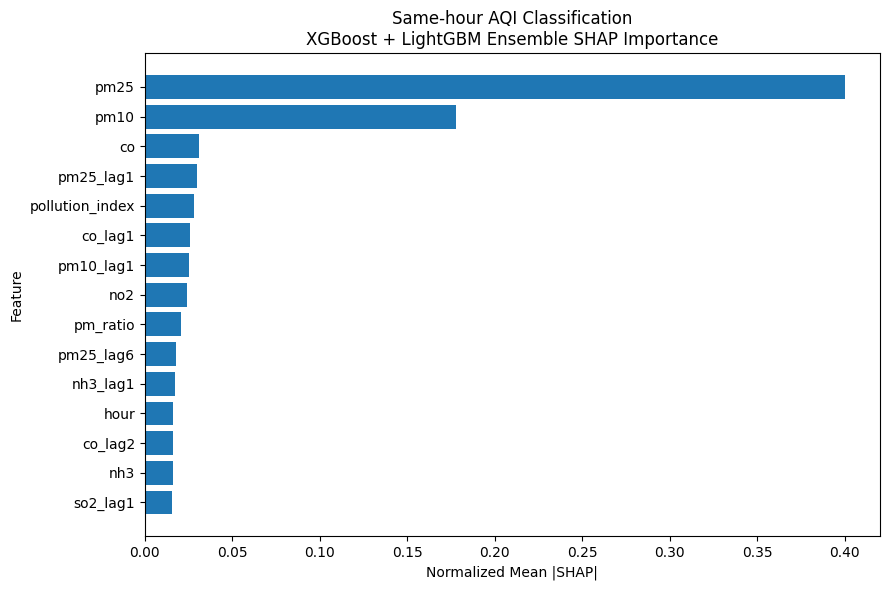


SHAP ANALYSIS COMPLETE.


In [ ]:
# ============================================================
# FAST SHAP EXPLAINABILITY
# Same-hour Final Ensemble: XGBoost + LightGBM
# NO RETRAINING
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("=" * 75)
print("SHAP EXPLAINABILITY — SAME-HOUR FINAL ENSEMBLE")
print("=" * 75)

# Install SHAP only if needed
try:
    import shap
except ImportError:
    !pip -q install shap
    import shap

# ------------------------------------------------------------
# 1. Sample test data for speed
# ------------------------------------------------------------

SHAP_SAMPLE = min(1000, len(X_test_same))

X_shap = (
    X_test_same[selected_features_30]
    .sample(
        n=SHAP_SAMPLE,
        random_state=42
    )
)

print("SHAP sample shape:", X_shap.shape)


# ============================================================
# 2. XGBOOST SHAP
# ============================================================

print("\nCalculating XGBoost SHAP...")

xgb_explainer = shap.TreeExplainer(
    xgb_same30
)

xgb_shap_values = xgb_explainer.shap_values(
    X_shap
)


# Handle multiclass SHAP formats
if isinstance(xgb_shap_values, list):

    xgb_abs = np.mean(
        [
            np.abs(v).mean(axis=0)
            for v in xgb_shap_values
        ],
        axis=0
    )

else:

    arr = np.asarray(xgb_shap_values)

    if arr.ndim == 3:
        # sample x feature x class
        xgb_abs = np.abs(arr).mean(
            axis=(0, 2)
        )

    else:
        xgb_abs = np.abs(arr).mean(axis=0)


xgb_shap_df = pd.DataFrame({
    "Feature": selected_features_30,
    "XGB Mean |SHAP|": xgb_abs
}).sort_values(
    "XGB Mean |SHAP|",
    ascending=False
)


print("\nTop XGBoost SHAP Features:")
print(
    xgb_shap_df
    .head(15)
    .round(5)
    .to_string(index=False)
)


# ============================================================
# 3. LIGHTGBM SHAP
# ============================================================

print("\nCalculating LightGBM SHAP...")

lgbm_explainer = shap.TreeExplainer(
    lgbm_same30
)

lgbm_shap_values = lgbm_explainer.shap_values(
    X_shap
)


if isinstance(lgbm_shap_values, list):

    lgbm_abs = np.mean(
        [
            np.abs(v).mean(axis=0)
            for v in lgbm_shap_values
        ],
        axis=0
    )

else:

    arr = np.asarray(lgbm_shap_values)

    if arr.ndim == 3:

        lgbm_abs = np.abs(arr).mean(
            axis=(0, 2)
        )

    else:

        lgbm_abs = np.abs(arr).mean(axis=0)


lgbm_shap_df = pd.DataFrame({
    "Feature": selected_features_30,
    "LGBM Mean |SHAP|": lgbm_abs
}).sort_values(
    "LGBM Mean |SHAP|",
    ascending=False
)


print("\nTop LightGBM SHAP Features:")
print(
    lgbm_shap_df
    .head(15)
    .round(5)
    .to_string(index=False)
)


# ============================================================
# 4. COMBINED ENSEMBLE SHAP IMPORTANCE
#
# Since final ensemble weights = 0.5 / 0.5,
# combine normalized SHAP importances equally.
# ============================================================

xgb_norm = (
    xgb_shap_df
    .set_index("Feature")["XGB Mean |SHAP|"]
)

xgb_norm = xgb_norm / xgb_norm.sum()


lgbm_norm = (
    lgbm_shap_df
    .set_index("Feature")["LGBM Mean |SHAP|"]
)

lgbm_norm = lgbm_norm / lgbm_norm.sum()


ensemble_shap = pd.DataFrame({
    "XGB Importance": xgb_norm,
    "LGBM Importance": lgbm_norm
}).fillna(0)


ensemble_shap[
    "Ensemble SHAP Importance"
] = (
    0.50 * ensemble_shap["XGB Importance"]
    +
    0.50 * ensemble_shap["LGBM Importance"]
)


ensemble_shap = (
    ensemble_shap
    .sort_values(
        "Ensemble SHAP Importance",
        ascending=False
    )
    .reset_index()
    .rename(
        columns={"index": "Feature"}
    )
)


print("\n" + "=" * 75)
print("FINAL ENSEMBLE SHAP — TOP 15 FEATURES")
print("=" * 75)

print(
    ensemble_shap[
        ["Feature", "Ensemble SHAP Importance"]
    ]
    .head(15)
    .round(5)
    .to_string(index=False)
)


# ============================================================
# 5. PLOT TOP 15
# ============================================================

top15 = (
    ensemble_shap
    .head(15)
    .sort_values(
        "Ensemble SHAP Importance"
    )
)

plt.figure(figsize=(9, 6))

plt.barh(
    top15["Feature"],
    top15["Ensemble SHAP Importance"]
)

plt.xlabel("Normalized Mean |SHAP|")
plt.ylabel("Feature")
plt.title(
    "Same-hour AQI Classification\n"
    "XGBoost + LightGBM Ensemble SHAP Importance"
)

plt.tight_layout()
plt.show()


print("\nSHAP ANALYSIS COMPLETE.")

FINAL THESIS RESULTS & FIGURES

FINAL MAIN RESULTS
---------------------------------------------------------------------------
                        Task                             Final Model  Accuracy  Macro F1    MAE   RMSE   R2
Same-hour AQI Classification XGBoost + LightGBM Soft-Voting Ensemble    0.9503    0.9418    NaN    NaN  NaN
Next-hour AQI Classification        Autoregressive Stacking Ensemble    0.9348    0.9279    NaN    NaN  NaN
  Next-hour PM2.5 Regression            Regression Stacking Ensemble       NaN       NaN 2.7896 6.1076 0.99

SAME-HOUR MODEL COMPARISON
---------------------------------------------------------------------------
                    Model  Test Accuracy  Test Macro F1
   XGB + LGBM Soft Voting         0.9503         0.9418
                 LightGBM         0.9476         0.9385
                  XGBoost         0.9094         0.9124
4-Model Weighted Ensemble         0.8621         0.8729
        Original Stacking         0.8134         0.8284
 

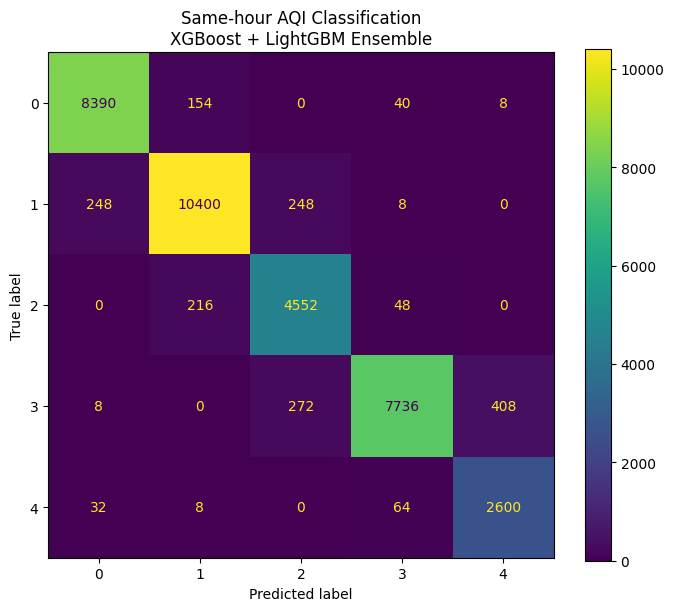

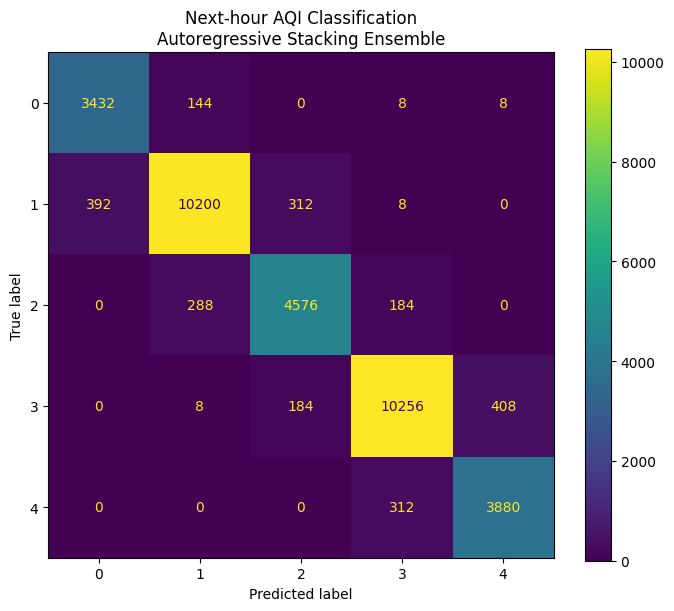

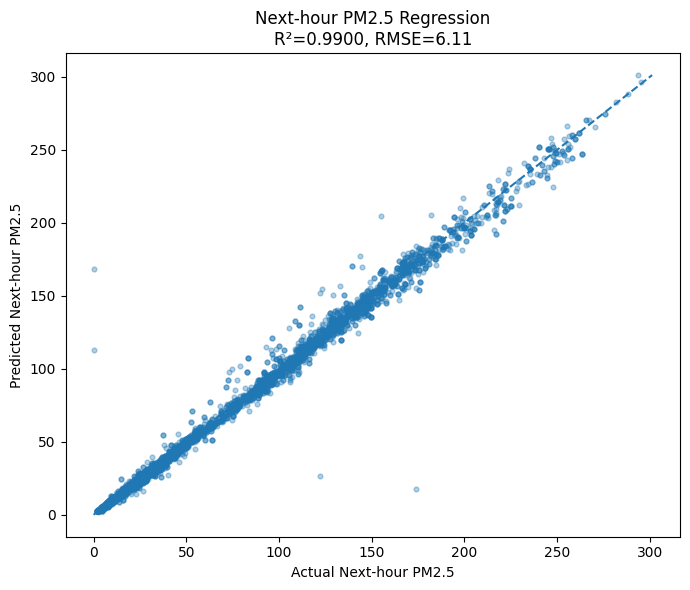

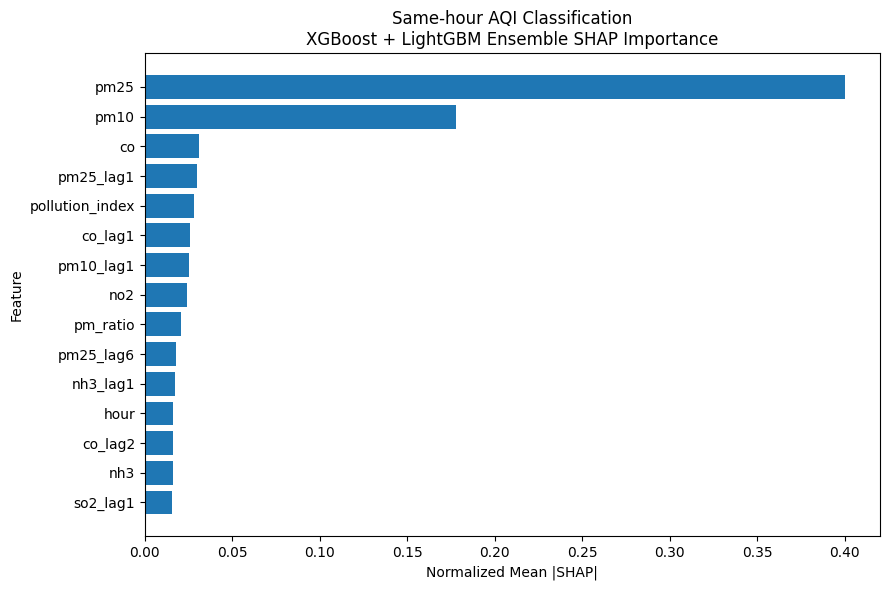


FINAL RESULTS SAVED SUCCESSFULLY

FINAL HEADLINE RESULTS:
Same-hour Ensemble     : Accuracy = 95.03% | Macro F1 = 94.18%
Next-hour AR Ensemble  : Accuracy = 93.48% | Macro F1 = 92.79%
PM2.5 Regression       : MAE = 2.7896 | RMSE = 6.1076 | R² = 0.9900

Saved folder:
/content/drive/MyDrive/AQI_Project/results

DONE.


In [ ]:
# ============================================================
# FINAL RESULTS, TABLES & FIGURES
# NO RETRAINING / NO TUNING
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

os.makedirs(RESULT_DIR, exist_ok=True)

print("=" * 75)
print("FINAL THESIS RESULTS & FIGURES")
print("=" * 75)


# ============================================================
# 1. CALCULATE FINAL METRICS
# ============================================================

# ---------- Same-hour ----------
same_final_acc = accuracy_score(
    y_test_same,
    same_strong_ensemble_pred
)

same_final_f1 = f1_score(
    y_test_same,
    same_strong_ensemble_pred,
    average="macro",
    zero_division=0
)


# ---------- Next-hour AR ----------
next_final_acc = accuracy_score(
    y_test_next,
    next_ar_test_pred
)

next_final_f1 = f1_score(
    y_test_next,
    next_ar_test_pred,
    average="macro",
    zero_division=0
)


# ---------- Regression ----------
reg_final_mae = mean_absolute_error(
    y_test_reg,
    reg_stack_test_pred
)

reg_final_rmse = np.sqrt(
    mean_squared_error(
        y_test_reg,
        reg_stack_test_pred
    )
)

reg_final_r2 = r2_score(
    y_test_reg,
    reg_stack_test_pred
)


# ============================================================
# 2. FINAL MAIN RESULTS TABLE
# ============================================================

final_results = pd.DataFrame([
    {
        "Task": "Same-hour AQI Classification",
        "Final Model": "XGBoost + LightGBM Soft-Voting Ensemble",
        "Accuracy": same_final_acc,
        "Macro F1": same_final_f1,
        "MAE": np.nan,
        "RMSE": np.nan,
        "R2": np.nan
    },

    {
        "Task": "Next-hour AQI Classification",
        "Final Model": "Autoregressive Stacking Ensemble",
        "Accuracy": next_final_acc,
        "Macro F1": next_final_f1,
        "MAE": np.nan,
        "RMSE": np.nan,
        "R2": np.nan
    },

    {
        "Task": "Next-hour PM2.5 Regression",
        "Final Model": "Regression Stacking Ensemble",
        "Accuracy": np.nan,
        "Macro F1": np.nan,
        "MAE": reg_final_mae,
        "RMSE": reg_final_rmse,
        "R2": reg_final_r2
    }
])

print("\nFINAL MAIN RESULTS")
print("-" * 75)

print(
    final_results
    .round(4)
    .to_string(index=False)
)

final_results.to_csv(
    os.path.join(
        RESULT_DIR,
        "FINAL_MAIN_RESULTS.csv"
    ),
    index=False
)


# ============================================================
# 3. SAME-HOUR MODEL COMPARISON
# ============================================================

same_model_comparison = pd.DataFrame([
    {
        "Model": "XGB + LGBM Soft Voting",
        "Test Accuracy": same_final_acc,
        "Test Macro F1": same_final_f1
    },
    {
        "Model": "LightGBM",
        "Test Accuracy": 0.9476,
        "Test Macro F1": 0.9385
    },
    {
        "Model": "XGBoost",
        "Test Accuracy": 0.9094,
        "Test Macro F1": 0.9124
    },
    {
        "Model": "4-Model Weighted Ensemble",
        "Test Accuracy": 0.8621,
        "Test Macro F1": 0.8729
    },
    {
        "Model": "Original Stacking",
        "Test Accuracy": 0.8134,
        "Test Macro F1": 0.8284
    },
    {
        "Model": "Random Forest",
        "Test Accuracy": 0.8117,
        "Test Macro F1": 0.8260
    },
    {
        "Model": "Extra Trees",
        "Test Accuracy": 0.7870,
        "Test Macro F1": 0.7988
    }
])

same_model_comparison.to_csv(
    os.path.join(
        RESULT_DIR,
        "FINAL_same_hour_model_comparison.csv"
    ),
    index=False
)

print("\nSAME-HOUR MODEL COMPARISON")
print("-" * 75)

print(
    same_model_comparison
    .round(4)
    .to_string(index=False)
)


# ============================================================
# 4. SAME-HOUR CONFUSION MATRIX
# ============================================================

cm_same = confusion_matrix(
    y_test_same,
    same_strong_ensemble_pred
)

fig, ax = plt.subplots(figsize=(7, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_same,
    display_labels=np.unique(y_test_same)
)

disp.plot(
    ax=ax,
    values_format="d"
)

ax.set_title(
    "Same-hour AQI Classification\n"
    "XGBoost + LightGBM Ensemble"
)

plt.tight_layout()

same_cm_path = os.path.join(
    RESULT_DIR,
    "same_hour_confusion_matrix.png"
)

plt.savefig(
    same_cm_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 5. NEXT-HOUR AR CONFUSION MATRIX
# ============================================================

cm_next = confusion_matrix(
    y_test_next,
    next_ar_test_pred
)

fig, ax = plt.subplots(figsize=(7, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_next,
    display_labels=np.unique(y_test_next)
)

disp.plot(
    ax=ax,
    values_format="d"
)

ax.set_title(
    "Next-hour AQI Classification\n"
    "Autoregressive Stacking Ensemble"
)

plt.tight_layout()

next_cm_path = os.path.join(
    RESULT_DIR,
    "next_hour_AR_confusion_matrix.png"
)

plt.savefig(
    next_cm_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 6. REGRESSION — ACTUAL VS PREDICTED
# ============================================================

y_reg_np = np.asarray(y_test_reg)
pred_reg_np = np.asarray(reg_stack_test_pred)

# sample only for visualization
rng = np.random.RandomState(42)

plot_n = min(
    5000,
    len(y_reg_np)
)

plot_idx = rng.choice(
    len(y_reg_np),
    size=plot_n,
    replace=False
)

fig, ax = plt.subplots(figsize=(7, 6))

ax.scatter(
    y_reg_np[plot_idx],
    pred_reg_np[plot_idx],
    alpha=0.35,
    s=12
)

min_val = min(
    y_reg_np[plot_idx].min(),
    pred_reg_np[plot_idx].min()
)

max_val = max(
    y_reg_np[plot_idx].max(),
    pred_reg_np[plot_idx].max()
)

ax.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--"
)

ax.set_xlabel(
    "Actual Next-hour PM2.5"
)

ax.set_ylabel(
    "Predicted Next-hour PM2.5"
)

ax.set_title(
    "Next-hour PM2.5 Regression\n"
    f"R²={reg_final_r2:.4f}, "
    f"RMSE={reg_final_rmse:.2f}"
)

plt.tight_layout()

reg_plot_path = os.path.join(
    RESULT_DIR,
    "regression_actual_vs_predicted.png"
)

plt.savefig(
    reg_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 7. SAVE SHAP TABLE + FINAL SHAP FIGURE
# ============================================================

ensemble_shap.to_csv(
    os.path.join(
        RESULT_DIR,
        "same_hour_ensemble_SHAP_importance.csv"
    ),
    index=False
)

top15 = (
    ensemble_shap
    .head(15)
    .sort_values(
        "Ensemble SHAP Importance"
    )
)

fig, ax = plt.subplots(figsize=(9, 6))

ax.barh(
    top15["Feature"],
    top15["Ensemble SHAP Importance"]
)

ax.set_xlabel(
    "Normalized Mean |SHAP|"
)

ax.set_ylabel(
    "Feature"
)

ax.set_title(
    "Same-hour AQI Classification\n"
    "XGBoost + LightGBM Ensemble SHAP Importance"
)

plt.tight_layout()

shap_path = os.path.join(
    RESULT_DIR,
    "same_hour_ensemble_SHAP.png"
)

plt.savefig(
    shap_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 8. SAVE ZONE-WISE TABLES
# ============================================================

if "same_zone_results" in globals():

    same_zone_results.to_csv(
        os.path.join(
            RESULT_DIR,
            "same_hour_zone_wise.csv"
        ),
        index=False
    )


if "next_zone_results" in globals():

    next_zone_results.to_csv(
        os.path.join(
            RESULT_DIR,
            "next_hour_AR_zone_wise.csv"
        ),
        index=False
    )


if "reg_zone_results" in globals():

    reg_zone_results.to_csv(
        os.path.join(
            RESULT_DIR,
            "regression_zone_wise.csv"
        ),
        index=False
    )


# ============================================================
# 9. SAVE FINAL PREDICTIONS
# ============================================================

pd.DataFrame({
    "Actual": np.asarray(y_test_same),
    "Predicted": np.asarray(
        same_strong_ensemble_pred
    )
}).to_csv(
    os.path.join(
        RESULT_DIR,
        "same_hour_final_predictions.csv"
    ),
    index=False
)


pd.DataFrame({
    "Actual": np.asarray(y_test_next),
    "Predicted": np.asarray(
        next_ar_test_pred
    )
}).to_csv(
    os.path.join(
        RESULT_DIR,
        "next_hour_AR_final_predictions.csv"
    ),
    index=False
)


pd.DataFrame({
    "Actual_PM25": y_reg_np,
    "Predicted_PM25": pred_reg_np
}).to_csv(
    os.path.join(
        RESULT_DIR,
        "regression_final_predictions.csv"
    ),
    index=False
)


# ============================================================
# 10. FINAL CHECK
# ============================================================

print("\n" + "=" * 75)
print("FINAL RESULTS SAVED SUCCESSFULLY")
print("=" * 75)

print("\nFINAL HEADLINE RESULTS:")

print(
    f"Same-hour Ensemble     : "
    f"Accuracy = {same_final_acc*100:.2f}% | "
    f"Macro F1 = {same_final_f1*100:.2f}%"
)

print(
    f"Next-hour AR Ensemble  : "
    f"Accuracy = {next_final_acc*100:.2f}% | "
    f"Macro F1 = {next_final_f1*100:.2f}%"
)

print(
    f"PM2.5 Regression       : "
    f"MAE = {reg_final_mae:.4f} | "
    f"RMSE = {reg_final_rmse:.4f} | "
    f"R² = {reg_final_r2:.4f}"
)

print("\nSaved folder:")
print(RESULT_DIR)

print("\nDONE.")

Saving paper-quality figures to:
/content/drive/MyDrive/AQI_Project/results/paper_figures_600dpi


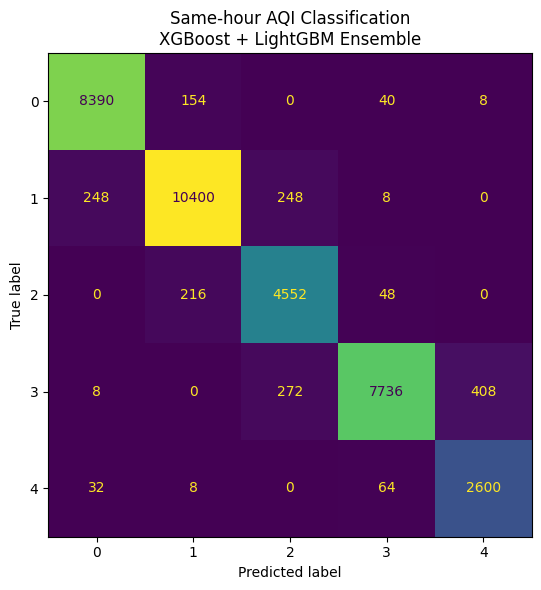

Saved Figure 1


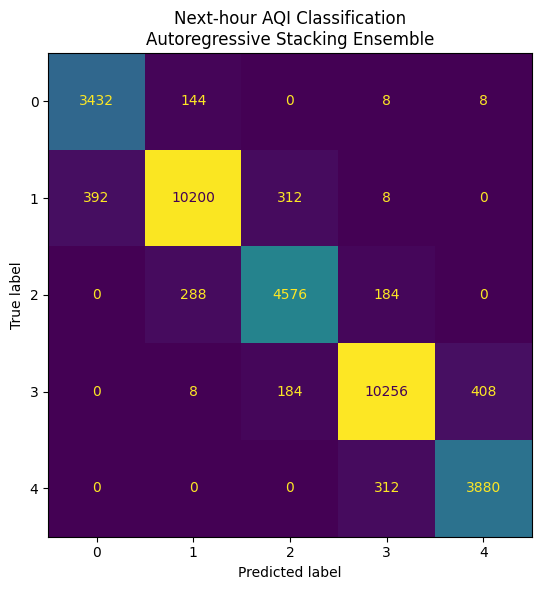

Saved Figure 2


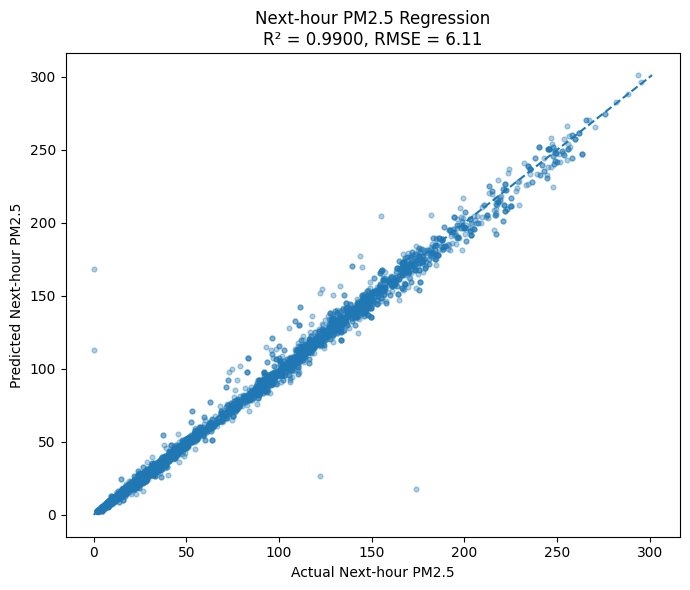

Saved Figure 3


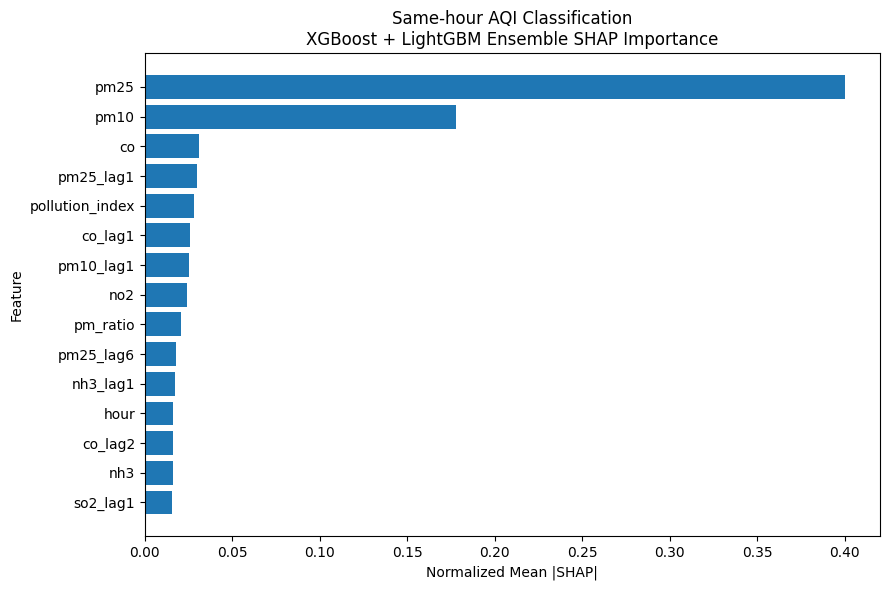

Saved Figure 4

ALL 600-DPI PAPER FIGURES SAVED

1. /content/drive/MyDrive/AQI_Project/results/paper_figures_600dpi/Figure_1_Same_Hour_Confusion_Matrix_600dpi.png
2. /content/drive/MyDrive/AQI_Project/results/paper_figures_600dpi/Figure_2_Next_Hour_Confusion_Matrix_600dpi.png
3. /content/drive/MyDrive/AQI_Project/results/paper_figures_600dpi/Figure_3_PM25_Actual_vs_Predicted_600dpi.png
4. /content/drive/MyDrive/AQI_Project/results/paper_figures_600dpi/Figure_4_SHAP_Feature_Importance_600dpi.png

Total figures: 4


In [ ]:
# ============================================================
# CREATE PAPER-QUALITY 600 DPI FIGURES
# Each figure will be saved separately
# ============================================================

import os
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

# New folder
PAPER_FIG_DIR = os.path.join(
    RESULT_DIR,
    "paper_figures_600dpi"
)

os.makedirs(PAPER_FIG_DIR, exist_ok=True)

print("Saving paper-quality figures to:")
print(PAPER_FIG_DIR)


# ============================================================
# FIGURE 1 — SAME-HOUR CONFUSION MATRIX
# ============================================================

cm_same = confusion_matrix(
    y_test_same,
    same_strong_ensemble_pred
)

fig, ax = plt.subplots(figsize=(7, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_same,
    display_labels=np.unique(y_test_same)
)

disp.plot(
    ax=ax,
    values_format="d",
    colorbar=False
)

ax.set_title(
    "Same-hour AQI Classification\n"
    "XGBoost + LightGBM Ensemble"
)

plt.tight_layout()

path1 = os.path.join(
    PAPER_FIG_DIR,
    "Figure_1_Same_Hour_Confusion_Matrix_600dpi.png"
)

plt.savefig(
    path1,
    dpi=600,
    bbox_inches="tight"
)

plt.show()

print("Saved Figure 1")


# ============================================================
# FIGURE 2 — NEXT-HOUR CONFUSION MATRIX
# ============================================================

cm_next = confusion_matrix(
    y_test_next,
    next_ar_test_pred
)

fig, ax = plt.subplots(figsize=(7, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_next,
    display_labels=np.unique(y_test_next)
)

disp.plot(
    ax=ax,
    values_format="d",
    colorbar=False
)

ax.set_title(
    "Next-hour AQI Classification\n"
    "Autoregressive Stacking Ensemble"
)

plt.tight_layout()

path2 = os.path.join(
    PAPER_FIG_DIR,
    "Figure_2_Next_Hour_Confusion_Matrix_600dpi.png"
)

plt.savefig(
    path2,
    dpi=600,
    bbox_inches="tight"
)

plt.show()

print("Saved Figure 2")


# ============================================================
# FIGURE 3 — REGRESSION ACTUAL VS PREDICTED
# ============================================================

y_reg_np = np.asarray(y_test_reg)
pred_reg_np = np.asarray(reg_stack_test_pred)

rng = np.random.RandomState(42)

plot_n = min(
    5000,
    len(y_reg_np)
)

idx = rng.choice(
    len(y_reg_np),
    size=plot_n,
    replace=False
)

fig, ax = plt.subplots(figsize=(7, 6))

ax.scatter(
    y_reg_np[idx],
    pred_reg_np[idx],
    alpha=0.35,
    s=12
)

min_val = min(
    y_reg_np[idx].min(),
    pred_reg_np[idx].min()
)

max_val = max(
    y_reg_np[idx].max(),
    pred_reg_np[idx].max()
)

ax.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--"
)

ax.set_xlabel(
    "Actual Next-hour PM2.5"
)

ax.set_ylabel(
    "Predicted Next-hour PM2.5"
)

ax.set_title(
    "Next-hour PM2.5 Regression\n"
    f"R² = {reg_final_r2:.4f}, "
    f"RMSE = {reg_final_rmse:.2f}"
)

plt.tight_layout()

path3 = os.path.join(
    PAPER_FIG_DIR,
    "Figure_3_PM25_Actual_vs_Predicted_600dpi.png"
)

plt.savefig(
    path3,
    dpi=600,
    bbox_inches="tight"
)

plt.show()

print("Saved Figure 3")


# ============================================================
# FIGURE 4 — SHAP IMPORTANCE
# ============================================================

top15 = (
    ensemble_shap
    .head(15)
    .sort_values(
        "Ensemble SHAP Importance"
    )
)

fig, ax = plt.subplots(figsize=(9, 6))

ax.barh(
    top15["Feature"],
    top15["Ensemble SHAP Importance"]
)

ax.set_xlabel(
    "Normalized Mean |SHAP|"
)

ax.set_ylabel(
    "Feature"
)

ax.set_title(
    "Same-hour AQI Classification\n"
    "XGBoost + LightGBM Ensemble SHAP Importance"
)

plt.tight_layout()

path4 = os.path.join(
    PAPER_FIG_DIR,
    "Figure_4_SHAP_Feature_Importance_600dpi.png"
)

plt.savefig(
    path4,
    dpi=600,
    bbox_inches="tight"
)

plt.show()

print("Saved Figure 4")


# ============================================================
# FINISHED
# ============================================================

print("\n" + "=" * 70)
print("ALL 600-DPI PAPER FIGURES SAVED")
print("=" * 70)

print("\n1.", path1)
print("2.", path2)
print("3.", path3)
print("4.", path4)

print("\nTotal figures: 4")

SAME-HOUR ENSEMBLE — ERROR RATE BY ZONE


,zone,Error Rate (%),Errors,Total Samples
0,Baridhara,4.944,219,4430
1,Motijheel,4.944,219,4430
2,Gulshan,4.966,220,4430
3,Dhanmondi,4.966,220,4430
4,Azimpur,4.989,221,4430
5,Mirpur,4.989,221,4430
6,Mohammadpur,4.989,221,4430
7,Uttara,4.989,221,4430


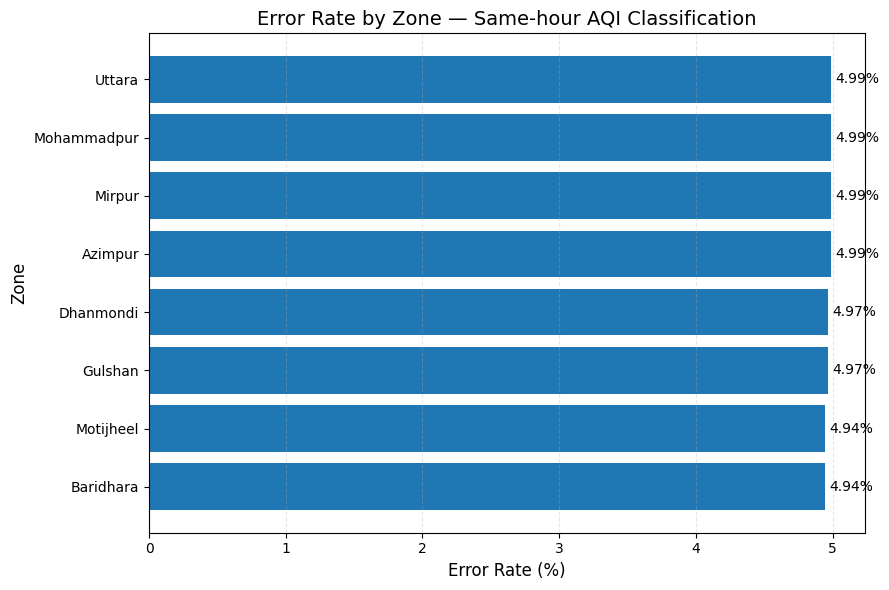


Saved successfully:
Figure: /content/drive/MyDrive/AQI_Project/results/paper_figures_600dpi/Figure_5_Error_Rate_by_Zone_600dpi.png
Data  : /content/drive/MyDrive/AQI_Project/results/same_hour_error_rate_by_zone.csv

DONE — Figure 5


In [ ]:
# ============================================================
# FIGURE 5 — ERROR RATE BY ZONE
# Final Same-hour XGBoost + LightGBM Ensemble
# No model retraining
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Paper figure folder
PAPER_FIG_DIR = os.path.join(
    RESULT_DIR,
    "paper_figures_600dpi"
)
os.makedirs(PAPER_FIG_DIR, exist_ok=True)

# ------------------------------------------------------------
# Safety check
# ------------------------------------------------------------
assert len(test_same_df) == len(y_test_same)
assert len(y_test_same) == len(same_strong_ensemble_pred)

# Prepare dataframe
error_zone_df = pd.DataFrame({
    "zone": test_same_df["zone"].values,
    "actual": np.asarray(y_test_same),
    "predicted": np.asarray(same_strong_ensemble_pred)
})

# 1 = incorrect prediction, 0 = correct prediction
error_zone_df["error"] = (
    error_zone_df["actual"] != error_zone_df["predicted"]
).astype(int)

# ------------------------------------------------------------
# Calculate zone-wise error rate
# ------------------------------------------------------------
zone_error = (
    error_zone_df
    .groupby("zone")["error"]
    .agg(["mean", "sum", "count"])
    .reset_index()
)

zone_error["Error Rate (%)"] = zone_error["mean"] * 100
zone_error["Errors"] = zone_error["sum"]
zone_error["Total Samples"] = zone_error["count"]

zone_error = (
    zone_error[
        ["zone", "Error Rate (%)", "Errors", "Total Samples"]
    ]
    .sort_values("Error Rate (%)", ascending=True)
    .reset_index(drop=True)
)

print("=" * 70)
print("SAME-HOUR ENSEMBLE — ERROR RATE BY ZONE")
print("=" * 70)

display(zone_error.round({
    "Error Rate (%)": 3
}))

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 6))

bars = ax.barh(
    zone_error["zone"],
    zone_error["Error Rate (%)"]
)

ax.set_xlabel("Error Rate (%)", fontsize=12)
ax.set_ylabel("Zone", fontsize=12)

ax.set_title(
    "Error Rate by Zone — Same-hour AQI Classification",
    fontsize=14
)

# Value labels
for bar, value in zip(
    bars,
    zone_error["Error Rate (%)"]
):
    ax.text(
        bar.get_width() + 0.03,
        bar.get_y() + bar.get_height()/2,
        f"{value:.2f}%",
        va="center",
        fontsize=10
    )

ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.3
)

plt.tight_layout()

# ------------------------------------------------------------
# Save 600 DPI PNG
# ------------------------------------------------------------
figure_path = os.path.join(
    PAPER_FIG_DIR,
    "Figure_5_Error_Rate_by_Zone_600dpi.png"
)

plt.savefig(
    figure_path,
    dpi=600,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# Save underlying data as CSV
# ------------------------------------------------------------
csv_path = os.path.join(
    RESULT_DIR,
    "same_hour_error_rate_by_zone.csv"
)

zone_error.to_csv(
    csv_path,
    index=False
)

print("\nSaved successfully:")
print("Figure:", figure_path)
print("Data  :", csv_path)

print("\nDONE — Figure 5")

SAME-HOUR ENSEMBLE — ERROR RATE BY HOUR OF DAY


,hour,Error Rate (%),Errors,Total Samples
0,0.0,2.317,48,2072
1,1.0,4.348,88,2024
2,2.0,4.737,72,1520
3,3.0,5.376,80,1488
4,4.0,3.608,56,1552
5,5.0,4.301,64,1488
6,6.0,9.554,120,1256
7,7.0,4.430,56,1264
8,8.0,6.329,80,1264
9,9.0,17.722,224,1264



Highest error hour : 09:00 (17.72%)
Lowest error hour  : 18:00 (1.25%)


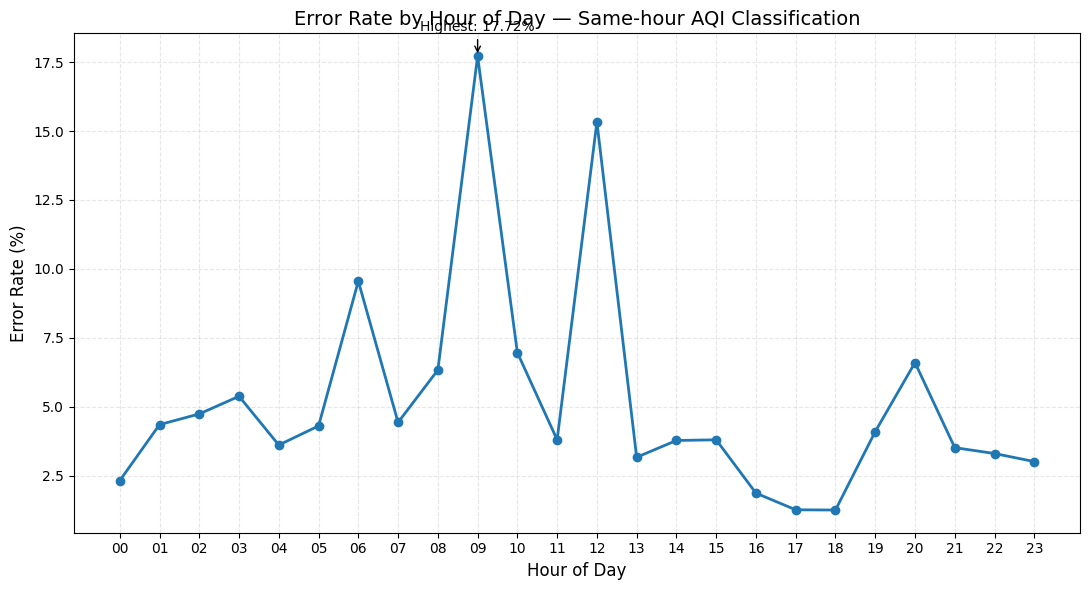


Saved successfully:
Figure: /content/drive/MyDrive/AQI_Project/results/paper_figures_600dpi/Figure_6_Error_Rate_by_Hour_600dpi.png
Data  : /content/drive/MyDrive/AQI_Project/results/same_hour_error_rate_by_hour.csv

DONE — Figure 6


In [ ]:
# ============================================================
# FIGURE 6 — ERROR RATE BY HOUR OF DAY
# Final Same-hour XGBoost + LightGBM Ensemble
# No model retraining
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Paper figure folder
PAPER_FIG_DIR = os.path.join(
    RESULT_DIR,
    "paper_figures_600dpi"
)
os.makedirs(PAPER_FIG_DIR, exist_ok=True)

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
assert len(test_same_df) == len(y_test_same)
assert len(y_test_same) == len(same_strong_ensemble_pred)

# Get hour
if "hour" in test_same_df.columns:
    hour_values = test_same_df["hour"].values
else:
    hour_values = pd.to_datetime(
        test_same_df["timestamp"]
    ).dt.hour.values

# ------------------------------------------------------------
# Prepare dataframe
# ------------------------------------------------------------
error_hour_df = pd.DataFrame({
    "hour": hour_values,
    "actual": np.asarray(y_test_same),
    "predicted": np.asarray(same_strong_ensemble_pred)
})

# Wrong = 1, Correct = 0
error_hour_df["error"] = (
    error_hour_df["actual"] != error_hour_df["predicted"]
).astype(int)

# ------------------------------------------------------------
# Calculate hourly error rate
# ------------------------------------------------------------
hour_error = (
    error_hour_df
    .groupby("hour")["error"]
    .agg(["mean", "sum", "count"])
    .reset_index()
)

hour_error["Error Rate (%)"] = hour_error["mean"] * 100
hour_error["Errors"] = hour_error["sum"]
hour_error["Total Samples"] = hour_error["count"]

hour_error = hour_error[
    ["hour", "Error Rate (%)", "Errors", "Total Samples"]
].sort_values("hour").reset_index(drop=True)

print("=" * 70)
print("SAME-HOUR ENSEMBLE — ERROR RATE BY HOUR OF DAY")
print("=" * 70)

display(
    hour_error.round({
        "Error Rate (%)": 3
    })
)

# ------------------------------------------------------------
# Find best/worst hours
# ------------------------------------------------------------
worst_row = hour_error.loc[
    hour_error["Error Rate (%)"].idxmax()
]

best_row = hour_error.loc[
    hour_error["Error Rate (%)"].idxmin()
]

print(
    f"\nHighest error hour : "
    f"{int(worst_row['hour']):02d}:00 "
    f"({worst_row['Error Rate (%)']:.2f}%)"
)

print(
    f"Lowest error hour  : "
    f"{int(best_row['hour']):02d}:00 "
    f"({best_row['Error Rate (%)']:.2f}%)"
)

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(11, 6))

ax.plot(
    hour_error["hour"],
    hour_error["Error Rate (%)"],
    marker="o",
    linewidth=2
)

ax.set_xlabel(
    "Hour of Day",
    fontsize=12
)

ax.set_ylabel(
    "Error Rate (%)",
    fontsize=12
)

ax.set_title(
    "Error Rate by Hour of Day — Same-hour AQI Classification",
    fontsize=14
)

# Show all 24 hours
ax.set_xticks(range(24))

ax.set_xticklabels(
    [f"{h:02d}" for h in range(24)]
)

ax.grid(
    True,
    linestyle="--",
    alpha=0.3
)

# ------------------------------------------------------------
# Highlight highest error hour
# ------------------------------------------------------------
ax.annotate(
    f"Highest: {worst_row['Error Rate (%)']:.2f}%",
    xy=(
        worst_row["hour"],
        worst_row["Error Rate (%)"]
    ),
    xytext=(0, 18),
    textcoords="offset points",
    ha="center",
    fontsize=10,
    arrowprops=dict(
        arrowstyle="->"
    )
)

plt.tight_layout()

# ------------------------------------------------------------
# Save 600 DPI
# ------------------------------------------------------------
figure_path = os.path.join(
    PAPER_FIG_DIR,
    "Figure_6_Error_Rate_by_Hour_600dpi.png"
)

plt.savefig(
    figure_path,
    dpi=600,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# Save exact values as CSV
# ------------------------------------------------------------
csv_path = os.path.join(
    RESULT_DIR,
    "same_hour_error_rate_by_hour.csv"
)

hour_error.to_csv(
    csv_path,
    index=False
)

print("\nSaved successfully:")
print("Figure:", figure_path)
print("Data  :", csv_path)

print("\nDONE — Figure 6")

Creating SHAP explainers...

Calculating zone-wise SHAP
Target class: 3 (Very Unhealthy)
Processing Azimpur: 300 samples
Processing Baridhara: 300 samples
Processing Dhanmondi: 300 samples
Processing Gulshan: 300 samples
Processing Mirpur: 300 samples
Processing Mohammadpur: 300 samples
Processing Motijheel: 300 samples
Processing Uttara: 300 samples

ZONE-WISE MEAN ABSOLUTE SHAP — VERY UNHEALTHY CLASS


,Zone,XGBoost Mean |SHAP|,LightGBM Mean |SHAP|,Ensemble Mean |SHAP|
0,Azimpur,0.221202,0.256101,0.238651
1,Baridhara,0.223191,0.254550,0.238870
2,Dhanmondi,0.226653,0.260559,0.243606
3,Gulshan,0.219509,0.252908,0.236208
4,Mirpur,0.225913,0.258740,0.242327
5,Mohammadpur,0.218344,0.254544,0.236444
6,Motijheel,0.224770,0.260046,0.242408
7,Uttara,0.222871,0.250824,0.236847


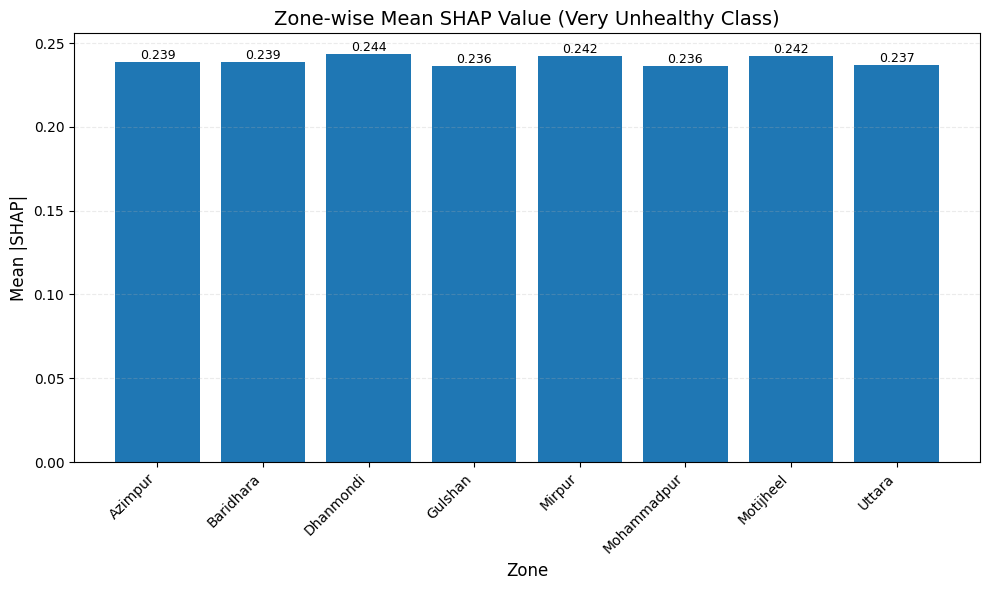


Saved successfully:
Figure: /content/drive/MyDrive/AQI_Project/results/paper_figures_600dpi/Figure_7_Zone_Wise_Mean_SHAP_600dpi.png
Data  : /content/drive/MyDrive/AQI_Project/results/zone_wise_mean_shap_very_unhealthy.csv

DONE — Corrected Figure 7


In [ ]:
# ============================================================
# CORRECTED FIGURE 7
# Zone-wise Mean Absolute SHAP Value — Very Unhealthy Class
# Final Same-hour XGBoost + LightGBM Ensemble
# NO RETRAINING
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

PAPER_FIG_DIR = os.path.join(
    RESULT_DIR,
    "paper_figures_600dpi"
)
os.makedirs(PAPER_FIG_DIR, exist_ok=True)

SAMPLE_PER_ZONE = 300
RANDOM_STATE = 42


# ============================================================
# IMPORTANT:
# Set the class ID corresponding to "Very Unhealthy"
#
# Change ONLY this value if your class mapping says otherwise.
# Example:
# 0 = Good
# 1 = Moderate
# 2 = Unhealthy
# 3 = Very Unhealthy
# 4 = Hazardous
# ============================================================

VERY_UNHEALTHY_CLASS = 3


# ============================================================
# PREPARE DATA
# ============================================================

assert "zone" in test_same_df.columns
assert len(test_same_df) == len(X_test_same)

X_shap_all = (
    X_test_same[selected_features_30]
    .copy()
    .reset_index(drop=True)
)

zone_labels = (
    test_same_df["zone"]
    .reset_index(drop=True)
)

assert len(X_shap_all) == len(zone_labels)


# ============================================================
# SHAP EXPLAINERS
# ============================================================

print("Creating SHAP explainers...")

xgb_explainer = shap.TreeExplainer(
    xgb_same30
)

lgbm_explainer = shap.TreeExplainer(
    lgbm_same30
)


# ============================================================
# FUNCTION:
# Extract SHAP matrix for ONE specific class
# ============================================================

def get_class_shap(shap_values, class_id, n_features):

    # Older SHAP:
    # list[class] -> (samples, features)
    if isinstance(shap_values, list):

        return np.asarray(
            shap_values[class_id]
        )

    arr = np.asarray(shap_values)

    # New SHAP format:
    # (samples, features, classes)
    if (
        arr.ndim == 3
        and arr.shape[1] == n_features
    ):
        return arr[:, :, class_id]

    # Alternative:
    # (samples, classes, features)
    if (
        arr.ndim == 3
        and arr.shape[2] == n_features
    ):
        return arr[:, class_id, :]

    raise ValueError(
        f"Unexpected SHAP shape: {arr.shape}"
    )


# ============================================================
# CALCULATE ZONE-WISE MEAN ABSOLUTE SHAP
# ============================================================

rng = np.random.RandomState(
    RANDOM_STATE
)

zone_results = []

zones = sorted(
    zone_labels.unique()
)

print("\nCalculating zone-wise SHAP")
print(
    "Target class:",
    VERY_UNHEALTHY_CLASS,
    "(Very Unhealthy)"
)

for zone in zones:

    zone_idx = np.where(
        zone_labels.values == zone
    )[0]

    if len(zone_idx) > SAMPLE_PER_ZONE:

        selected_idx = rng.choice(
            zone_idx,
            size=SAMPLE_PER_ZONE,
            replace=False
        )

    else:
        selected_idx = zone_idx

    X_zone = X_shap_all.iloc[
        selected_idx
    ]

    print(
        f"Processing {zone}: "
        f"{len(X_zone)} samples"
    )

    # ----------------------------------------
    # XGBoost
    # ----------------------------------------

    shap_xgb_all = (
        xgb_explainer.shap_values(
            X_zone
        )
    )

    shap_xgb_class = get_class_shap(
        shap_xgb_all,
        VERY_UNHEALTHY_CLASS,
        X_zone.shape[1]
    )

    xgb_mean_abs = np.mean(
        np.abs(shap_xgb_class)
    )


    # ----------------------------------------
    # LightGBM
    # ----------------------------------------

    shap_lgbm_all = (
        lgbm_explainer.shap_values(
            X_zone
        )
    )

    shap_lgbm_class = get_class_shap(
        shap_lgbm_all,
        VERY_UNHEALTHY_CLASS,
        X_zone.shape[1]
    )

    lgbm_mean_abs = np.mean(
        np.abs(shap_lgbm_class)
    )


    # ----------------------------------------
    # Ensemble 0.5 / 0.5
    # ----------------------------------------

    ensemble_mean_abs = (
        0.5 * xgb_mean_abs
        +
        0.5 * lgbm_mean_abs
    )

    zone_results.append({
        "Zone": zone,
        "XGBoost Mean |SHAP|":
            xgb_mean_abs,

        "LightGBM Mean |SHAP|":
            lgbm_mean_abs,

        "Ensemble Mean |SHAP|":
            ensemble_mean_abs
    })


# ============================================================
# RESULT TABLE
# ============================================================

zone_shap_corrected = pd.DataFrame(
    zone_results
)

# Keep normal zone order
zone_shap_corrected = (
    zone_shap_corrected
    .sort_values("Zone")
    .reset_index(drop=True)
)

print("\n" + "=" * 75)
print(
    "ZONE-WISE MEAN ABSOLUTE SHAP "
    "— VERY UNHEALTHY CLASS"
)
print("=" * 75)

display(
    zone_shap_corrected.round(6)
)


# ============================================================
# PLOT — reference-style vertical bars
# ============================================================

fig, ax = plt.subplots(
    figsize=(10, 6)
)

bars = ax.bar(
    zone_shap_corrected["Zone"],
    zone_shap_corrected[
        "Ensemble Mean |SHAP|"
    ]
)

ax.set_xlabel(
    "Zone",
    fontsize=12
)

ax.set_ylabel(
    "Mean |SHAP|",
    fontsize=12
)

ax.set_title(
    "Zone-wise Mean SHAP Value "
    "(Very Unhealthy Class)",
    fontsize=14
)

plt.xticks(
    rotation=45,
    ha="right"
)

# values above bars
for bar, value in zip(
    bars,
    zone_shap_corrected[
        "Ensemble Mean |SHAP|"
    ]
):

    ax.text(
        bar.get_x()
        + bar.get_width()/2,

        bar.get_height(),

        f"{value:.3f}",

        ha="center",
        va="bottom",
        fontsize=9
    )

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

plt.tight_layout()


# ============================================================
# SAVE CORRECTED FIGURE
# Overwrites old wrong Figure 7
# ============================================================

figure_path = os.path.join(
    PAPER_FIG_DIR,
    "Figure_7_Zone_Wise_Mean_SHAP_600dpi.png"
)

plt.savefig(
    figure_path,
    dpi=600,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# SAVE DATA
# ============================================================

csv_path = os.path.join(
    RESULT_DIR,
    "zone_wise_mean_shap_very_unhealthy.csv"
)

zone_shap_corrected.to_csv(
    csv_path,
    index=False
)

print("\nSaved successfully:")
print("Figure:", figure_path)
print("Data  :", csv_path)

print(
    "\nDONE — Corrected Figure 7"
)

SHAP sample size: 1000
Number of features: 30

Creating SHAP explainers...
Calculating XGBoost SHAP...
Calculating LightGBM SHAP...

XGB SHAP shape : (1000, 30, 5)
LGBM SHAP shape: (1000, 30, 5)

TOP FEATURES — SHAP IMPORTANCE ACROSS AQI CLASSES


,Good,Moderate,Unhealthy_Sens,Very_Unhealthy,Hazardous,Total Importance
pm25,3.30053,2.66383,2.15901,3.30121,2.74027,14.16485
pm10,0.90120,0.65072,1.00784,1.15627,2.57859,6.29461
co,0.47791,0.10717,0.17697,0.12153,0.20984,1.09344
pm25_lag1,0.16396,0.26075,0.24939,0.29431,0.09705,1.06546
pollution_index,0.31660,0.22893,0.11538,0.17949,0.15681,0.99722
co_lag1,0.09773,0.11351,0.13251,0.04920,0.53323,0.92618
pm10_lag1,0.12499,0.23557,0.16465,0.22572,0.14645,0.89737
no2,0.17147,0.10681,0.19369,0.18502,0.20472,0.86172
pm_ratio,0.21326,0.24056,0.09643,0.07931,0.11375,0.74331
pm25_lag6,0.14003,0.27635,0.06421,0.11375,0.04156,0.63589


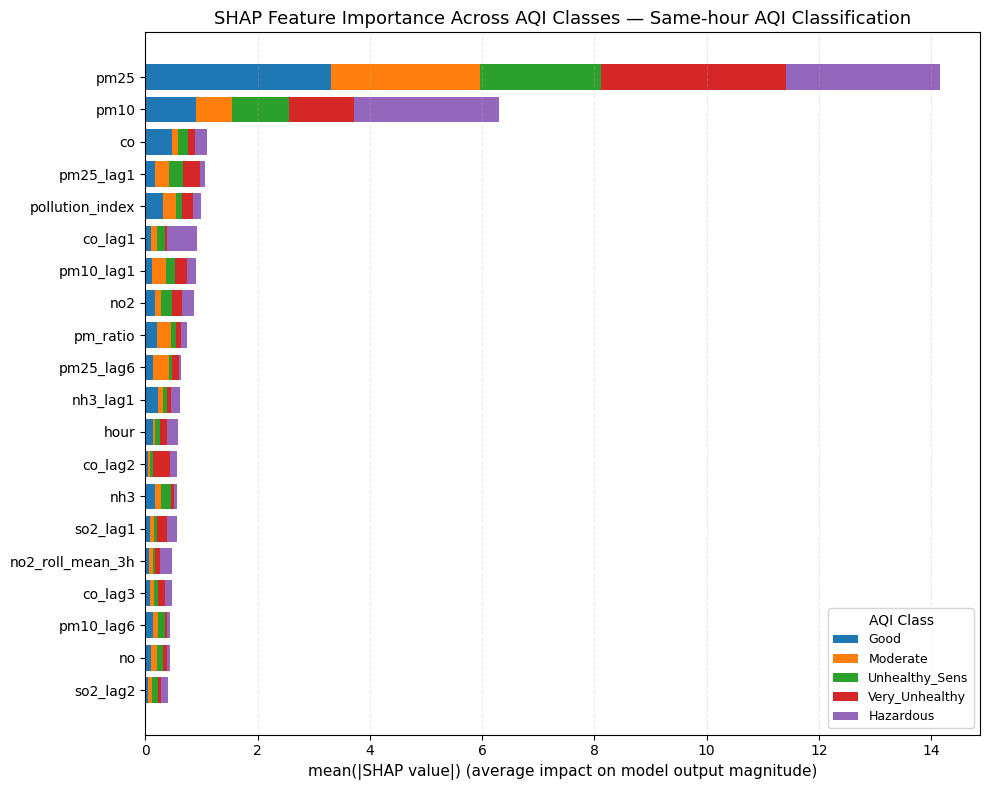


Saved successfully:
Figure: /content/drive/MyDrive/AQI_Project/results/paper_figures_600dpi/Figure_8_SHAP_Importance_Across_AQI_Classes_600dpi.png
Data  : /content/drive/MyDrive/AQI_Project/results/SHAP_importance_across_AQI_classes.csv

DONE — Figure 8


In [ ]:
# ============================================================
# FIGURE 8 — SHAP FEATURE IMPORTANCE ACROSS AQI CLASSES
# Reference-style stacked horizontal bar plot
# Final Same-hour XGBoost + LightGBM Ensemble (0.5 / 0.5)
# NO RETRAINING
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

# ------------------------------------------------------------
# SETTINGS
# ------------------------------------------------------------

PAPER_FIG_DIR = os.path.join(
    RESULT_DIR,
    "paper_figures_600dpi"
)

os.makedirs(PAPER_FIG_DIR, exist_ok=True)

SHAP_SAMPLE_SIZE = 1000
TOP_N = 20
RANDOM_STATE = 42


# ============================================================
# AQI CLASS NAMES
#
# IMPORTANT:
# Verify this mapping with your target encoding.
# If your encoding is different, only edit this dictionary.
# ============================================================

CLASS_NAMES = {
    0: "Good",
    1: "Moderate",
    2: "Unhealthy_Sens",
    3: "Very_Unhealthy",
    4: "Hazardous"
}


# ------------------------------------------------------------
# PREPARE TEST SAMPLE
# ------------------------------------------------------------

X_shap_all = (
    X_test_same[selected_features_30]
    .copy()
    .reset_index(drop=True)
)

rng = np.random.RandomState(
    RANDOM_STATE
)

sample_n = min(
    SHAP_SAMPLE_SIZE,
    len(X_shap_all)
)

sample_idx = rng.choice(
    len(X_shap_all),
    size=sample_n,
    replace=False
)

X_shap_sample = (
    X_shap_all
    .iloc[sample_idx]
    .copy()
)

print(
    f"SHAP sample size: {len(X_shap_sample)}"
)

print(
    f"Number of features: {X_shap_sample.shape[1]}"
)


# ------------------------------------------------------------
# CREATE EXPLAINERS
# ------------------------------------------------------------

print("\nCreating SHAP explainers...")

xgb_explainer = shap.TreeExplainer(
    xgb_same30
)

lgbm_explainer = shap.TreeExplainer(
    lgbm_same30
)


# ------------------------------------------------------------
# CALCULATE SHAP VALUES
# ------------------------------------------------------------

print("Calculating XGBoost SHAP...")

shap_xgb_raw = (
    xgb_explainer.shap_values(
        X_shap_sample
    )
)

print("Calculating LightGBM SHAP...")

shap_lgbm_raw = (
    lgbm_explainer.shap_values(
        X_shap_sample
    )
)


# ============================================================
# FUNCTION:
# Convert SHAP result to shape:
# (samples, features, classes)
# ============================================================

def shap_to_3d(
    shap_values,
    n_samples,
    n_features,
    n_classes
):

    # Older SHAP:
    # list containing one array per class
    if isinstance(shap_values, list):

        arr = np.stack(
            shap_values,
            axis=-1
        )

        return arr

    arr = np.asarray(
        shap_values
    )

    # New format:
    # samples x features x classes
    if (
        arr.ndim == 3
        and arr.shape[0] == n_samples
        and arr.shape[1] == n_features
    ):
        return arr

    # Alternative:
    # samples x classes x features
    if (
        arr.ndim == 3
        and arr.shape[0] == n_samples
        and arr.shape[2] == n_features
    ):
        return np.transpose(
            arr,
            (0, 2, 1)
        )

    raise ValueError(
        f"Unexpected SHAP shape: {arr.shape}"
    )


n_samples = X_shap_sample.shape[0]
n_features = X_shap_sample.shape[1]
n_classes = 5


xgb_3d = shap_to_3d(
    shap_xgb_raw,
    n_samples,
    n_features,
    n_classes
)

lgbm_3d = shap_to_3d(
    shap_lgbm_raw,
    n_samples,
    n_features,
    n_classes
)

print("\nXGB SHAP shape :", xgb_3d.shape)
print("LGBM SHAP shape:", lgbm_3d.shape)


# ============================================================
# MEAN ABSOLUTE SHAP BY FEATURE AND CLASS
# ============================================================

# Result:
# features x classes

xgb_class_imp = np.mean(
    np.abs(xgb_3d),
    axis=0
)

lgbm_class_imp = np.mean(
    np.abs(lgbm_3d),
    axis=0
)


# ------------------------------------------------------------
# Final ensemble 0.5 XGB + 0.5 LGBM
# ------------------------------------------------------------

ensemble_class_imp = (
    0.5 * xgb_class_imp
    +
    0.5 * lgbm_class_imp
)


# ============================================================
# CREATE DATAFRAME
# ============================================================

class_columns = [
    CLASS_NAMES[i]
    for i in range(n_classes)
]

shap_class_df = pd.DataFrame(
    ensemble_class_imp,
    index=X_shap_sample.columns,
    columns=class_columns
)

# Overall importance = sum across all AQI classes
shap_class_df[
    "Total Importance"
] = shap_class_df[
    class_columns
].sum(axis=1)


# ------------------------------------------------------------
# Select TOP features
# ------------------------------------------------------------

top_shap_class_df = (
    shap_class_df
    .sort_values(
        "Total Importance",
        ascending=False
    )
    .head(TOP_N)
    .copy()
)


print("\n" + "=" * 80)
print(
    "TOP FEATURES — SHAP IMPORTANCE "
    "ACROSS AQI CLASSES"
)
print("=" * 80)

display(
    top_shap_class_df.round(5)
)


# ============================================================
# PLOT
# Reference-style horizontal stacked bar chart
# ============================================================

# Reverse so most important feature is at top
plot_df = (
    top_shap_class_df
    .iloc[::-1]
)

fig, ax = plt.subplots(
    figsize=(10, 8)
)

left_values = np.zeros(
    len(plot_df)
)

for class_name in class_columns:

    values = (
        plot_df[class_name]
        .values
    )

    ax.barh(
        plot_df.index,
        values,
        left=left_values,
        label=class_name
    )

    left_values += values


# ------------------------------------------------------------
# Labels / title
# ------------------------------------------------------------

ax.set_xlabel(
    "mean(|SHAP value|) "
    "(average impact on model output magnitude)",
    fontsize=11
)

ax.set_ylabel(
    "",
    fontsize=11
)

ax.set_title(
    "SHAP Feature Importance Across AQI Classes "
    "— Same-hour AQI Classification",
    fontsize=13
)

ax.legend(
    title="AQI Class",
    loc="lower right",
    fontsize=9
)

ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.25
)

plt.tight_layout()


# ============================================================
# SAVE 600 DPI
# ============================================================

figure_path = os.path.join(
    PAPER_FIG_DIR,
    "Figure_8_SHAP_Importance_Across_AQI_Classes_600dpi.png"
)

plt.savefig(
    figure_path,
    dpi=600,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# SAVE CSV
# ============================================================

csv_path = os.path.join(
    RESULT_DIR,
    "SHAP_importance_across_AQI_classes.csv"
)

top_shap_class_df.to_csv(
    csv_path
)


print("\nSaved successfully:")

print(
    "Figure:",
    figure_path
)

print(
    "Data  :",
    csv_path
)

print(
    "\nDONE — Figure 8"
)

SHAP beeswarm sample size: 1000
Creating XGBoost SHAP explainer...
Calculating SHAP values...
Very Unhealthy SHAP shape: (1000, 30)

Top features for Very Unhealthy class:


,Feature,Mean |SHAP|
0,pm25,3.09770
1,pm10,1.07068
7,co_lag2,0.30947
2,pm25_lag1,0.22264
19,no2,0.19986
12,pollution_index,0.18221
11,so2_lag1,0.17809
3,pm10_lag1,0.16781
15,co,0.15734
18,pm25_lag6,0.11644


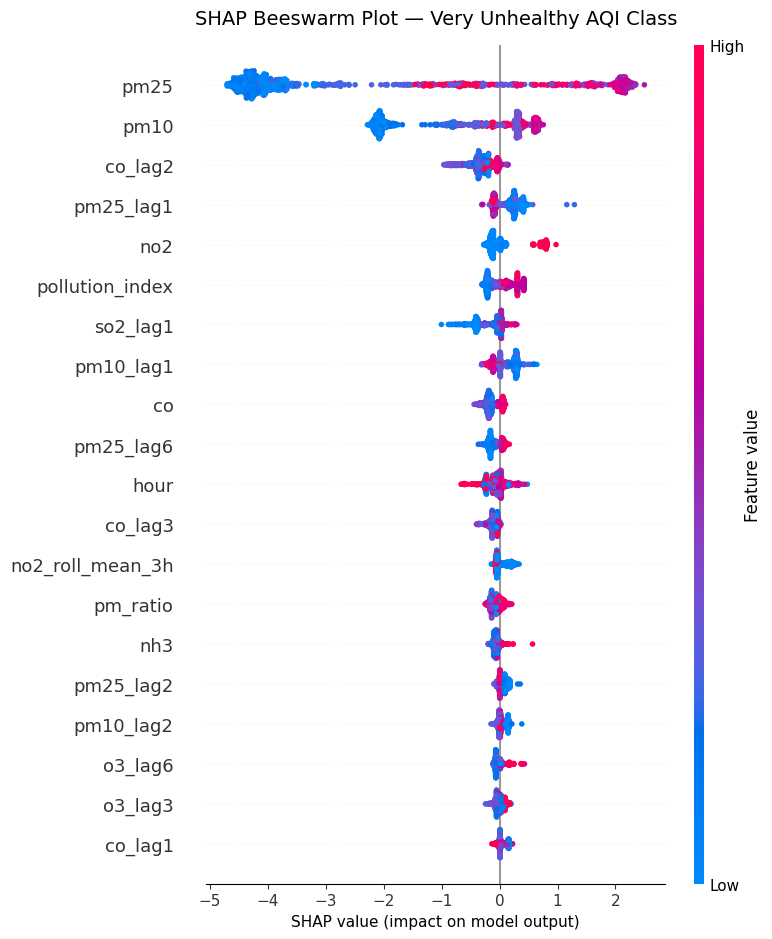


Saved successfully:
Figure: /content/drive/MyDrive/AQI_Project/results/paper_figures_600dpi/Figure_9_SHAP_Beeswarm_Very_Unhealthy_600dpi.png
Data  : /content/drive/MyDrive/AQI_Project/results/SHAP_Very_Unhealthy_feature_importance.csv

DONE — Figure 9


In [ ]:
# ============================================================
# FIGURE 9 — SHAP BEESWARM PLOT
# Very Unhealthy Class
# Same-hour XGBoost model from final ensemble
# NO RETRAINING
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

# ------------------------------------------------------------
# SETTINGS
# ------------------------------------------------------------

PAPER_FIG_DIR = os.path.join(
    RESULT_DIR,
    "paper_figures_600dpi"
)

os.makedirs(
    PAPER_FIG_DIR,
    exist_ok=True
)

SHAP_SAMPLE_SIZE = 1000
RANDOM_STATE = 42

# IMPORTANT:
# We are assuming:
# Class 3 = Very Unhealthy
VERY_UNHEALTHY_CLASS = 3


# ------------------------------------------------------------
# PREPARE TEST DATA
# ------------------------------------------------------------

X_bee_all = (
    X_test_same[selected_features_30]
    .copy()
    .reset_index(drop=True)
)

rng = np.random.RandomState(
    RANDOM_STATE
)

sample_n = min(
    SHAP_SAMPLE_SIZE,
    len(X_bee_all)
)

sample_idx = rng.choice(
    len(X_bee_all),
    size=sample_n,
    replace=False
)

X_bee = (
    X_bee_all
    .iloc[sample_idx]
    .copy()
)

print(
    "SHAP beeswarm sample size:",
    len(X_bee)
)


# ------------------------------------------------------------
# CREATE XGBOOST SHAP EXPLAINER
# ------------------------------------------------------------

print(
    "Creating XGBoost SHAP explainer..."
)

xgb_explainer_bee = shap.TreeExplainer(
    xgb_same30
)


# ------------------------------------------------------------
# CALCULATE SHAP
# ------------------------------------------------------------

print(
    "Calculating SHAP values..."
)

shap_raw = (
    xgb_explainer_bee
    .shap_values(X_bee)
)


# ------------------------------------------------------------
# EXTRACT VERY UNHEALTHY CLASS SHAP
# ------------------------------------------------------------

def extract_class_shap(
    shap_values,
    class_id,
    n_features
):

    # Older SHAP:
    # list[class] -> samples x features
    if isinstance(
        shap_values,
        list
    ):

        return np.asarray(
            shap_values[class_id]
        )

    arr = np.asarray(
        shap_values
    )

    # New format:
    # samples x features x classes
    if (
        arr.ndim == 3
        and arr.shape[1] == n_features
    ):

        return arr[
            :,
            :,
            class_id
        ]

    # Alternative:
    # samples x classes x features
    if (
        arr.ndim == 3
        and arr.shape[2] == n_features
    ):

        return arr[
            :,
            class_id,
            :
        ]

    raise ValueError(
        f"Unexpected SHAP shape: {arr.shape}"
    )


shap_very_unhealthy = (
    extract_class_shap(
        shap_raw,
        VERY_UNHEALTHY_CLASS,
        X_bee.shape[1]
    )
)

print(
    "Very Unhealthy SHAP shape:",
    shap_very_unhealthy.shape
)


# ------------------------------------------------------------
# FEATURE RANKING
# ------------------------------------------------------------

mean_abs_imp = np.mean(
    np.abs(
        shap_very_unhealthy
    ),
    axis=0
)

feature_rank = pd.DataFrame({
    "Feature":
        X_bee.columns,

    "Mean |SHAP|":
        mean_abs_imp
}).sort_values(
    "Mean |SHAP|",
    ascending=False
)

print(
    "\nTop features for "
    "Very Unhealthy class:"
)

display(
    feature_rank
    .head(20)
    .round(5)
)


# ============================================================
# BEESWARM PLOT
# ============================================================

plt.figure(
    figsize=(10, 8)
)

shap.summary_plot(
    shap_very_unhealthy,
    X_bee,
    plot_type="dot",
    max_display=20,
    show=False
)

plt.title(
    "SHAP Beeswarm Plot — Very Unhealthy AQI Class",
    fontsize=14,
    pad=15
)

plt.xlabel(
    "SHAP value "
    "(impact on model output)",
    fontsize=11
)

plt.tight_layout()


# ------------------------------------------------------------
# SAVE 600 DPI
# ------------------------------------------------------------

figure_path = os.path.join(
    PAPER_FIG_DIR,
    "Figure_9_SHAP_Beeswarm_Very_Unhealthy_600dpi.png"
)

plt.savefig(
    figure_path,
    dpi=600,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# SAVE FEATURE IMPORTANCE CSV
# ------------------------------------------------------------

csv_path = os.path.join(
    RESULT_DIR,
    "SHAP_Very_Unhealthy_feature_importance.csv"
)

feature_rank.to_csv(
    csv_path,
    index=False
)


print(
    "\nSaved successfully:"
)

print(
    "Figure:",
    figure_path
)

print(
    "Data  :",
    csv_path
)

print(
    "\nDONE — Figure 9"
)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

path = "/content/drive/MyDrive"

print("Drive connected:", os.path.exists(path))

print("\nMyDrive folders/files:")
print(os.listdir(path)[:50])

Drive connected: True

MyDrive folders/files:
['AQI_Project', 'Colab Notebooks']


In [ ]:
import os

PROJECT_DIR = "/content/drive/MyDrive/AQI_Project"

print("Project exists:", os.path.exists(PROJECT_DIR))
print("=" * 80)

for root, dirs, files in os.walk(PROJECT_DIR):
    level = root.replace(PROJECT_DIR, "").count(os.sep)
    indent = "    " * level

    print(f"{indent}📁 {os.path.basename(root)}/")

    for file in files:
        print(f"{indent}    📄 {file}")

Project exists: True
📁 AQI_Project/
    📄 dhaka_aqi_final_featured.csv
    📁 checkpoints/
        📄 same_hour_split_info.pkl
        📄 same30_oof_X.npy
        📄 same30_oof_y.npy
        📄 same30_classes.npy
        📄 selected_features_30.pkl
        📄 next_hour_top20_features.pkl
        📄 next_oof_X.npy
        📄 next_oof_y.npy
        📄 next_oof_classes.npy
        📄 next_oof_time.npy
        📄 next_selected_features20.pkl
        📄 next_ar_oof_X.npy
        📄 next_ar_oof_y.npy
        📄 next_ar_oof_classes.npy
        📄 next_ar_oof_time.npy
        📄 next_ar_features.pkl
        📄 regression_train_medians.pkl
        📄 reg_oof_X.npy
        📄 reg_oof_y.npy
    📁 models/
        📄 samehour_rf_top30.pkl
        📄 samehour_et_top30.pkl
        📄 samehour_lgbm_top30.pkl
        📄 samehour_meta_logreg.pkl
        📄 samehour_xgb_top30.json
        📄 next_hour_rf_top20.pkl
        📄 next_hour_et_top20.pkl
        📄 next_hour_lgbm_top20.pkl
        📄 next_hour_xgb_top20.json
        📄 next

In [ ]:
# ============================================================
# RESTORE NEXT-HOUR PROJECT AFTER RUNTIME DISCONNECT
# NO RETRAINING
# ============================================================

import os
import pickle
import joblib
import numpy as np
import pandas as pd
import xgboost as xgb

PROJECT_DIR = "/content/drive/MyDrive/AQI_Project"
CHECKPOINT_DIR = os.path.join(PROJECT_DIR, "checkpoints")
MODEL_DIR = os.path.join(PROJECT_DIR, "models")
RESULT_DIR = os.path.join(PROJECT_DIR, "results")

print("Project:", os.path.exists(PROJECT_DIR))
print("Models :", os.path.exists(MODEL_DIR))
print("Results:", os.path.exists(RESULT_DIR))


# ============================================================
# 1. LOAD ORIGINAL DATASET
# ============================================================

DATA_PATH = os.path.join(
    PROJECT_DIR,
    "dhaka_aqi_final_featured.csv"
)

df = pd.read_csv(DATA_PATH)

df["timestamp"] = pd.to_datetime(df["timestamp"])

print("\nDataset loaded:", df.shape)


# ============================================================
# 2. LOAD NEXT-HOUR AR FEATURES
# ============================================================

with open(
    os.path.join(CHECKPOINT_DIR, "next_ar_features.pkl"),
    "rb"
) as f:
    next_ar_features = pickle.load(f)

print(
    "Next-hour AR features:",
    len(next_ar_features)
)

print(next_ar_features)


# ============================================================
# 3. REBUILD EXACT +1 HOUR TARGET
# ============================================================

future_target = df[
    ["zone", "timestamp", "target"]
].copy()

# Move future timestamp back by one hour
# so target at t+1 joins observation at t
future_target["timestamp"] = (
    future_target["timestamp"]
    - pd.Timedelta(hours=1)
)

future_target = future_target.rename(
    columns={
        "target": "target_next_hour"
    }
)

next_df = df.merge(
    future_target,
    on=["zone", "timestamp"],
    how="left"
)

# Keep rows that have an exact next-hour observation
next_df = next_df[
    next_df["target_next_hour"].notna()
].copy()

next_df["target_next_hour"] = (
    next_df["target_next_hour"]
    .astype(int)
)

# Chronological order
next_df = (
    next_df
    .sort_values(
        ["timestamp", "zone"]
    )
    .reset_index(drop=True)
)

print(
    "\nValid exact +1h rows:",
    len(next_df)
)


# ============================================================
# 4. RECREATE 70 / 15 / 15 CHRONOLOGICAL SPLIT
# ============================================================

n = len(next_df)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

train_next_df = next_df.iloc[:train_end].copy()
val_next_df   = next_df.iloc[train_end:val_end].copy()
test_next_df  = next_df.iloc[val_end:].copy()

X_train_next = train_next_df[next_ar_features].copy()
X_val_next   = val_next_df[next_ar_features].copy()
X_test_next  = test_next_df[next_ar_features].copy()

y_train_next = train_next_df["target_next_hour"].values
y_val_next   = val_next_df["target_next_hour"].values
y_test_next  = test_next_df["target_next_hour"].values

print("\nSplit sizes:")
print("Train:", len(train_next_df))
print("Val  :", len(val_next_df))
print("Test :", len(test_next_df))


# ============================================================
# 5. LOAD SAVED NEXT-HOUR MODELS
# ============================================================

rf_next_ar = joblib.load(
    os.path.join(
        MODEL_DIR,
        "next_hour_rf_final.pkl"
    )
)

et_next_ar = joblib.load(
    os.path.join(
        MODEL_DIR,
        "next_hour_et_final.pkl"
    )
)

lgbm_next_ar = joblib.load(
    os.path.join(
        MODEL_DIR,
        "next_hour_lgbm_final.pkl"
    )
)

next_ar_meta = joblib.load(
    os.path.join(
        MODEL_DIR,
        "next_hour_meta_logreg.pkl"
    )
)

xgb_next_ar = xgb.XGBClassifier()

xgb_next_ar.load_model(
    os.path.join(
        MODEL_DIR,
        "next_hour_xgb_final.json"
    )
)

print("\nModels loaded successfully.")


# ============================================================
# 6. CHECK MODEL FEATURE COUNTS
# ============================================================

print("\nFeature-count verification:")

for name, model in [
    ("RF", rf_next_ar),
    ("ET", et_next_ar),
    ("LightGBM", lgbm_next_ar),
    ("XGBoost", xgb_next_ar)
]:
    try:
        print(
            name,
            "expects",
            model.n_features_in_,
            "features"
        )
    except:
        print(
            name,
            "feature count unavailable"
        )

print(
    "AR feature list contains:",
    len(next_ar_features)
)


# ============================================================
# 7. LOAD SAVED FINAL NEXT-HOUR PREDICTIONS
# ============================================================

pred_path = os.path.join(
    RESULT_DIR,
    "next_hour_AR_final_predictions.csv"
)

next_pred_saved = pd.read_csv(
    pred_path
)

print(
    "\nSaved prediction file:",
    next_pred_saved.shape
)

print(
    "Prediction columns:",
    list(next_pred_saved.columns)
)

display(
    next_pred_saved.head()
)


# ============================================================
# 8. AUTO-DETECT PREDICTION COLUMN
# ============================================================

possible_pred_cols = [
    "predicted",
    "prediction",
    "Predicted",
    "y_pred",
    "pred",
    "AR_Stacking_Prediction",
    "next_ar_test_pred"
]

pred_col = None

for c in possible_pred_cols:
    if c in next_pred_saved.columns:
        pred_col = c
        break

# fallback: find column containing "pred"
if pred_col is None:
    for c in next_pred_saved.columns:
        if "pred" in c.lower():
            pred_col = c
            break

if pred_col is not None:

    next_ar_test_pred = (
        next_pred_saved[pred_col]
        .to_numpy()
    )

    print(
        "\nPrediction column detected:",
        pred_col
    )

    print(
        "Predictions restored:",
        len(next_ar_test_pred)
    )

else:

    print(
        "\nCould not auto-detect prediction column."
    )
    print(
        "Send me the displayed column names."
    )


# ============================================================
# FINAL CHECK
# ============================================================

print("\n" + "=" * 75)
print("NEXT-HOUR RUNTIME RESTORE COMPLETE")
print("=" * 75)

print("Test dataframe :", test_next_df.shape)
print("X_test_next    :", X_test_next.shape)
print("y_test_next    :", len(y_test_next))

if "next_ar_test_pred" in globals():
    print(
        "Predictions    :",
        len(next_ar_test_pred)
    )

print("\nNO MODEL WAS RETRAINED.")

Project: True
Models : True
Results: True

Dataset loaded: (236216, 81)
Next-hour AR features: 21
['pm25', 'pm10', 'pm25_lag1', 'hour', 'co_lag3', 'pm10_lag1', 'co_lag2', 'is_peak_hour', 'so2_lag1', 'o3_lag3', 'no2', 'co_lag1', 'o3', 'co', 'hour_season', 'no', 'pm25_lag6', 'pm10_lag6', 'pm25_roll_mean_3h', 'season', 'target']

Valid exact +1h rows: 230640

Split sizes:
Train: 161448
Val  : 34596
Test : 34596

Models loaded successfully.

Feature-count verification:
RF expects 20 features
ET expects 20 features
LightGBM expects 20 features
XGBoost expects 20 features
AR feature list contains: 21

Saved prediction file: (34600, 2)
Prediction columns: ['Actual', 'Predicted']


,Actual,Predicted
0,4,4
1,4,4
2,4,4
3,4,4
4,4,4



Prediction column detected: Predicted
Predictions restored: 34600

NEXT-HOUR RUNTIME RESTORE COMPLETE
Test dataframe : (34596, 82)
X_test_next    : (34596, 21)
y_test_next    : 34596
Predictions    : 34600

NO MODEL WAS RETRAINED.


In [ ]:
# ============================================================
# EXACT RESTORE OF NEXT-HOUR 70/15/15 SPLIT
# Matches original sizes: 161448 / 34592 / 34600
# NO RETRAINING
# ============================================================

import os
import numpy as np
import pandas as pd

PROJECT_DIR = "/content/drive/MyDrive/AQI_Project"
RESULT_DIR = os.path.join(PROJECT_DIR, "results")

# ------------------------------------------------------------
# 1. Rebuild exact +1h target dataframe
# ------------------------------------------------------------

df_exact = df.copy()

future_target = df_exact[
    ["zone", "timestamp", "target"]
].copy()

future_target["timestamp"] = (
    future_target["timestamp"]
    - pd.Timedelta(hours=1)
)

future_target = future_target.rename(
    columns={
        "target": "target_next_hour"
    }
)

next_df_exact = df_exact.merge(
    future_target,
    on=["zone", "timestamp"],
    how="left"
)

next_df_exact = next_df_exact[
    next_df_exact["target_next_hour"].notna()
].copy()

next_df_exact["target_next_hour"] = (
    next_df_exact["target_next_hour"]
    .astype(int)
)

# IMPORTANT:
# Sort by timestamp only to preserve the original temporal split
next_df_exact = (
    next_df_exact
    .sort_values("timestamp", kind="stable")
    .reset_index(drop=True)
)

print("Valid rows:", len(next_df_exact))


# ------------------------------------------------------------
# 2. Use ORIGINAL recorded split sizes
# ------------------------------------------------------------

TRAIN_N = 161448
VAL_N   = 34592
TEST_N  = 34600

assert (
    TRAIN_N + VAL_N + TEST_N
    == len(next_df_exact)
), (
    TRAIN_N + VAL_N + TEST_N,
    len(next_df_exact)
)

train_end = TRAIN_N
val_end = TRAIN_N + VAL_N

train_next_df = (
    next_df_exact
    .iloc[:train_end]
    .copy()
)

val_next_df = (
    next_df_exact
    .iloc[train_end:val_end]
    .copy()
)

test_next_df = (
    next_df_exact
    .iloc[val_end:]
    .copy()
)


# ------------------------------------------------------------
# 3. Restore target
# ------------------------------------------------------------

y_train_next = (
    train_next_df["target_next_hour"]
    .to_numpy()
)

y_val_next = (
    val_next_df["target_next_hour"]
    .to_numpy()
)

y_test_next = (
    test_next_df["target_next_hour"]
    .to_numpy()
)


# ------------------------------------------------------------
# 4. Load saved final predictions
# ------------------------------------------------------------

pred_path = os.path.join(
    RESULT_DIR,
    "next_hour_AR_final_predictions.csv"
)

next_pred_saved = pd.read_csv(
    pred_path
)

saved_actual = (
    next_pred_saved["Actual"]
    .to_numpy()
)

next_ar_test_pred = (
    next_pred_saved["Predicted"]
    .to_numpy()
)


# ------------------------------------------------------------
# 5. Alignment checks
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("EXACT NEXT-HOUR TEST RESTORE CHECK")
print("=" * 75)

print("Train rows :", len(train_next_df))
print("Val rows   :", len(val_next_df))
print("Test rows  :", len(test_next_df))

print(
    "Saved prediction rows:",
    len(next_ar_test_pred)
)

print(
    "Saved actual rows:",
    len(saved_actual)
)

print(
    "Rebuilt y_test rows:",
    len(y_test_next)
)


# ------------------------------------------------------------
# 6. Check exact target alignment
# ------------------------------------------------------------

same_actual = np.array_equal(
    saved_actual.astype(int),
    y_test_next.astype(int)
)

print(
    "\nSaved Actual == rebuilt y_test:",
    same_actual
)


if not same_actual:

    mismatch_idx = np.where(
        saved_actual.astype(int)
        !=
        y_test_next.astype(int)
    )[0]

    print(
        "Number of mismatches:",
        len(mismatch_idx)
    )

    print(
        "First mismatch indices:",
        mismatch_idx[:20]
    )

else:

    print(
        "SUCCESS: exact 34,600-row "
        "test alignment restored."
    )


# ------------------------------------------------------------
# 7. Confirm original test period
# ------------------------------------------------------------

print(
    "\nTest start:",
    test_next_df["timestamp"].min()
)

print(
    "Test end  :",
    test_next_df["timestamp"].max()
)


# ------------------------------------------------------------
# 8. Final accuracy check from saved predictions
# ------------------------------------------------------------

test_acc_check = np.mean(
    saved_actual.astype(int)
    ==
    next_ar_test_pred.astype(int)
)

print(
    "\nSaved AR Stacking Test Accuracy:",
    f"{test_acc_check:.6f}"
)

print(
    "Expected approximately: 0.934798"
)


print("\nNO MODEL WAS RETRAINED.")

Valid rows: 230640

EXACT NEXT-HOUR TEST RESTORE CHECK
Train rows : 161448
Val rows   : 34592
Test rows  : 34600
Saved prediction rows: 34600
Saved actual rows: 34600
Rebuilt y_test rows: 34600

Saved Actual == rebuilt y_test: True
SUCCESS: exact 34,600-row test alignment restored.

Test start: 2025-12-13 03:00:00
Test end  : 2026-06-28 23:00:00

Saved AR Stacking Test Accuracy: 0.934798
Expected approximately: 0.934798

NO MODEL WAS RETRAINED.


FINAL FIXED PAPER FIGURE FOLDER
/content/drive/MyDrive/AQI_Project/results/FINAL_FIXED_PAPER_FIGURES

✓ Exact 34,600-row Next-hour test alignment verified
✓ No retraining will be performed
Saved:
 PNG: /content/drive/MyDrive/AQI_Project/results/FINAL_FIXED_PAPER_FIGURES/Figure_1_Next_Hour_AR_Confusion_Matrix_600dpi.png
 PDF: /content/drive/MyDrive/AQI_Project/results/FINAL_FIXED_PAPER_FIGURES/Figure_1_Next_Hour_AR_Confusion_Matrix.pdf


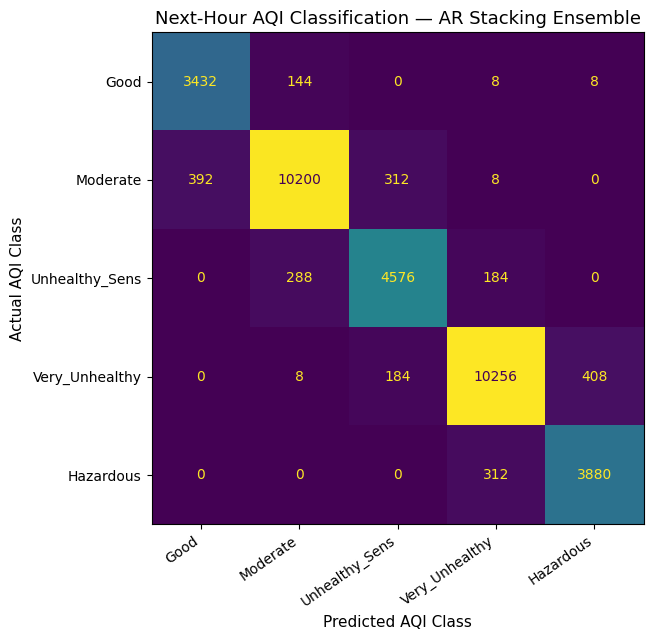

Saved:
 PNG: /content/drive/MyDrive/AQI_Project/results/FINAL_FIXED_PAPER_FIGURES/Figure_2_Next_Hour_Error_Rate_by_Zone_600dpi.png
 PDF: /content/drive/MyDrive/AQI_Project/results/FINAL_FIXED_PAPER_FIGURES/Figure_2_Next_Hour_Error_Rate_by_Zone.pdf


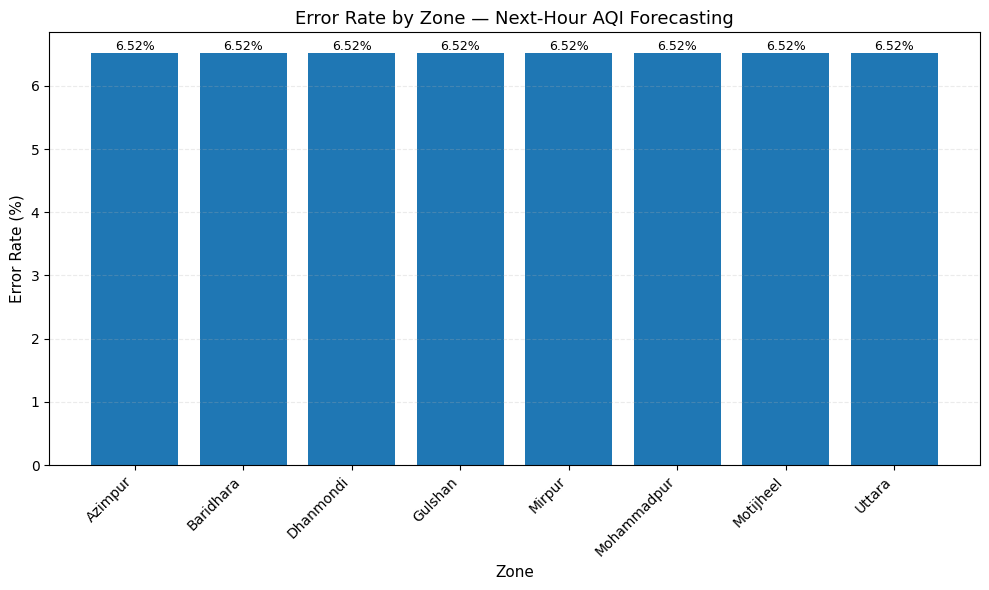

Saved:
 PNG: /content/drive/MyDrive/AQI_Project/results/FINAL_FIXED_PAPER_FIGURES/Figure_3_Next_Hour_Error_Rate_by_Hour_600dpi.png
 PDF: /content/drive/MyDrive/AQI_Project/results/FINAL_FIXED_PAPER_FIGURES/Figure_3_Next_Hour_Error_Rate_by_Hour.pdf


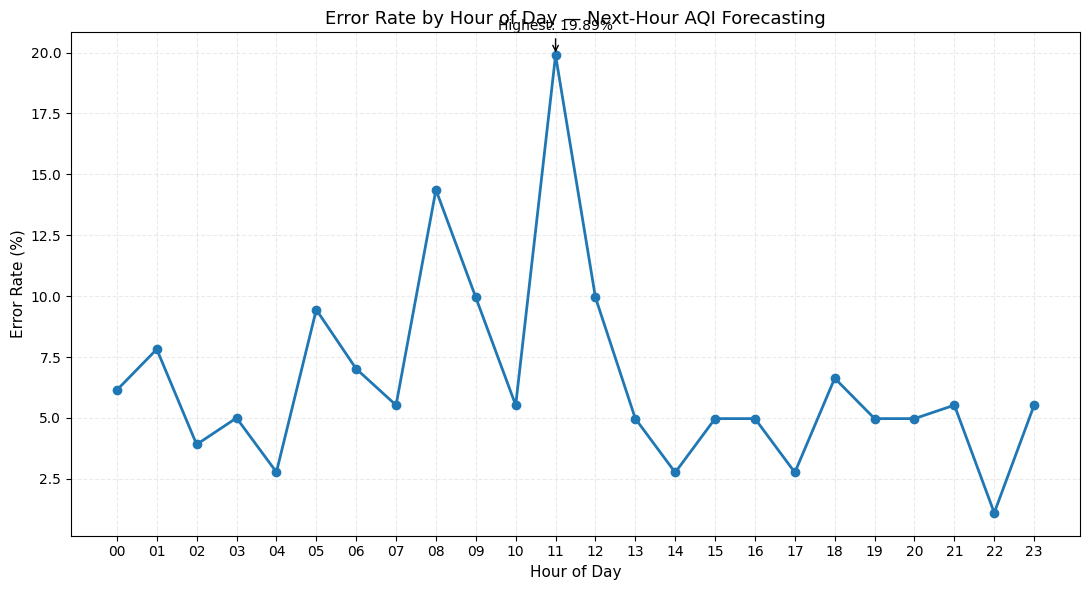


SHAP feature count: 20

Calculating Next-hour XGBoost SHAP...
SHAP shape: (1000, 20, 5)
Saved:
 PNG: /content/drive/MyDrive/AQI_Project/results/FINAL_FIXED_PAPER_FIGURES/Figure_4_Next_Hour_SHAP_Across_AQI_Classes_600dpi.png
 PDF: /content/drive/MyDrive/AQI_Project/results/FINAL_FIXED_PAPER_FIGURES/Figure_4_Next_Hour_SHAP_Across_AQI_Classes.pdf


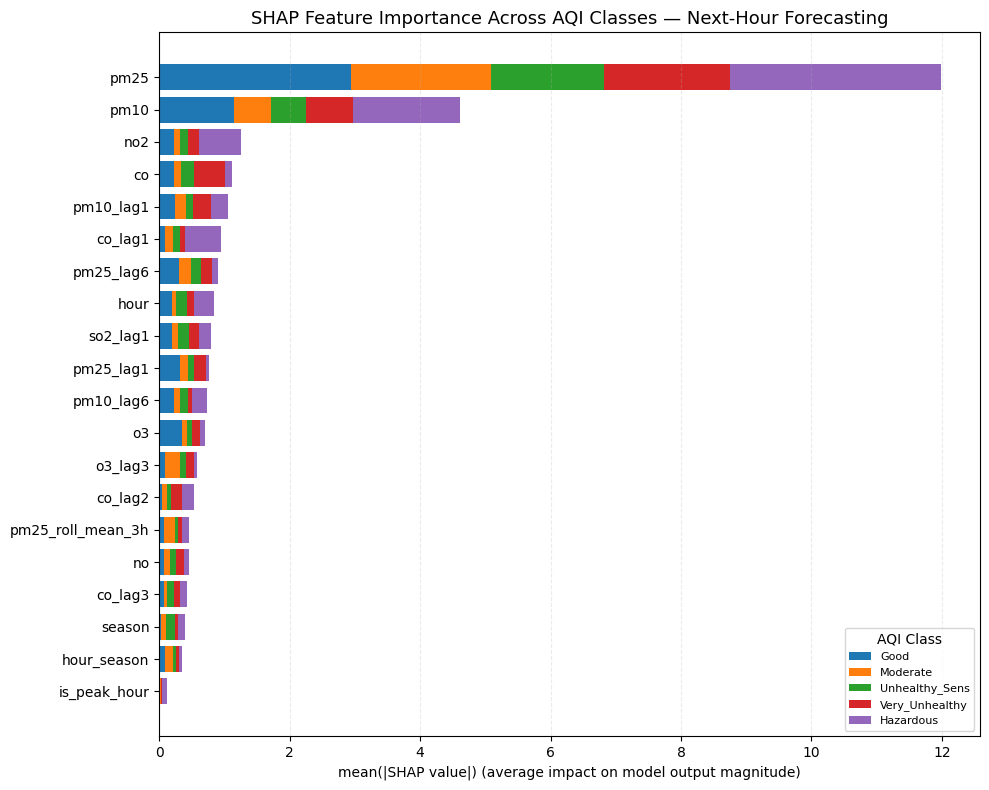

Saved:
 PNG: /content/drive/MyDrive/AQI_Project/results/FINAL_FIXED_PAPER_FIGURES/Figure_5_Next_Hour_SHAP_Beeswarm_Very_Unhealthy_600dpi.png
 PDF: /content/drive/MyDrive/AQI_Project/results/FINAL_FIXED_PAPER_FIGURES/Figure_5_Next_Hour_SHAP_Beeswarm_Very_Unhealthy.pdf


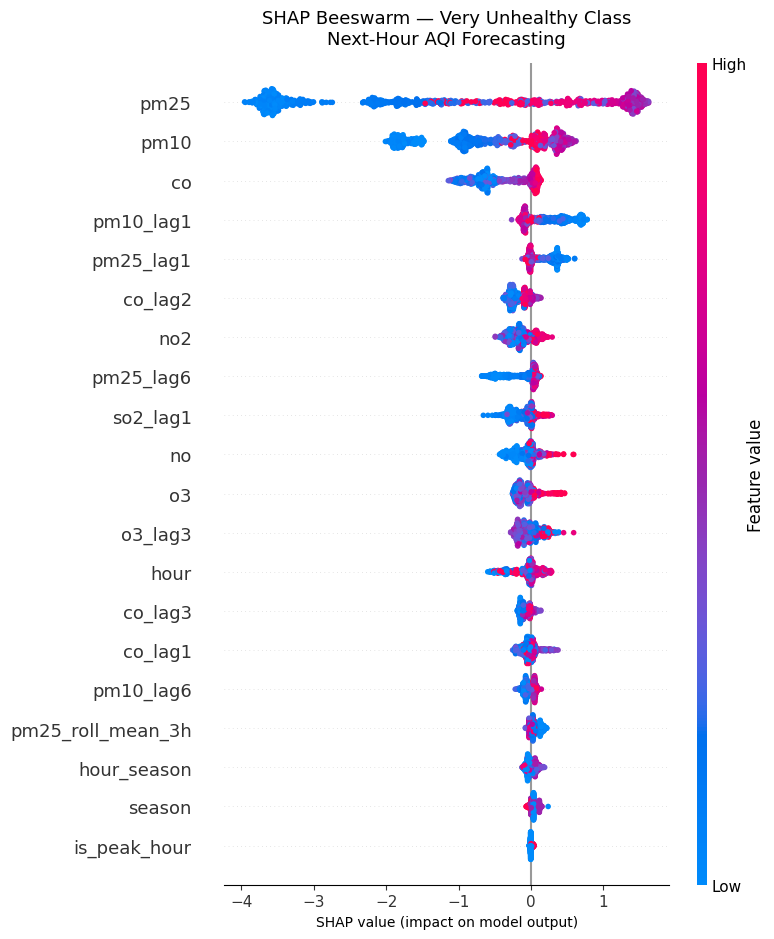


FINAL FIXED NEXT-HOUR PAPER FIGURES COMPLETE

Saved folder:
/content/drive/MyDrive/AQI_Project/results/FINAL_FIXED_PAPER_FIGURES

Main figures created:
1. Next-hour AR Stacking Confusion Matrix
2. Next-hour Error Rate by Zone
3. Next-hour Error Rate by Hour of Day
4. Next-hour SHAP Importance Across AQI Classes
5. Next-hour Very Unhealthy SHAP Beeswarm

Each figure saved as:
✓ 600-DPI PNG
✓ Vector PDF

NO MODEL WAS RETRAINED.

DONE — FINAL FIXED PAPER FIGURES


In [ ]:
# ============================================================
# FINAL FIXED PAPER FIGURES — NEXT-HOUR AQI CLASSIFICATION
# ------------------------------------------------------------
# Creates a NEW clean folder:
# MyDrive/AQI_Project/results/FINAL_FIXED_PAPER_FIGURES
#
# Saves every figure as:
#   1) 600-DPI PNG
#   2) Vector PDF
#
# NO MODEL RETRAINING
# ============================================================

import os
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay


# ============================================================
# 0. PATHS
# ============================================================

PROJECT_DIR = "/content/drive/MyDrive/AQI_Project"
RESULT_DIR = os.path.join(PROJECT_DIR, "results")
MODEL_DIR = os.path.join(PROJECT_DIR, "models")
CHECKPOINT_DIR = os.path.join(PROJECT_DIR, "checkpoints")

FINAL_FIG_DIR = os.path.join(
    RESULT_DIR,
    "FINAL_FIXED_PAPER_FIGURES"
)

os.makedirs(
    FINAL_FIG_DIR,
    exist_ok=True
)

print("=" * 80)
print("FINAL FIXED PAPER FIGURE FOLDER")
print("=" * 80)
print(FINAL_FIG_DIR)


# ============================================================
# 1. IMPORTANT SAFETY CHECKS
# ============================================================

assert len(test_next_df) == 34600
assert len(y_test_next) == 34600
assert len(next_ar_test_pred) == 34600

assert np.array_equal(
    next_pred_saved["Actual"].to_numpy().astype(int),
    np.asarray(y_test_next).astype(int)
)

print("\n✓ Exact 34,600-row Next-hour test alignment verified")
print("✓ No retraining will be performed")


# ============================================================
# CLASS LABELS
# IMPORTANT: confirm mapping before final paper submission
# ============================================================

CLASS_NAMES = {
    0: "Good",
    1: "Moderate",
    2: "Unhealthy_Sens",
    3: "Very_Unhealthy",
    4: "Hazardous"
}

VERY_UNHEALTHY_CLASS = 3


# ============================================================
# HELPER FUNCTION — SAVE PNG + PDF
# ============================================================

def save_final_figure(fig, base_name):

    png_path = os.path.join(
        FINAL_FIG_DIR,
        base_name + "_600dpi.png"
    )

    pdf_path = os.path.join(
        FINAL_FIG_DIR,
        base_name + ".pdf"
    )

    fig.savefig(
        png_path,
        dpi=600,
        bbox_inches="tight"
    )

    fig.savefig(
        pdf_path,
        bbox_inches="tight"
    )

    print("Saved:")
    print(" PNG:", png_path)
    print(" PDF:", pdf_path)


# ============================================================
# FIGURE 1
# NEXT-HOUR AR STACKING CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_test_next,
    next_ar_test_pred
)

fig, ax = plt.subplots(
    figsize=(7.5, 6.5)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        CLASS_NAMES.get(i, str(i))
        for i in sorted(np.unique(y_test_next))
    ]
)

disp.plot(
    ax=ax,
    values_format="d",
    colorbar=False
)

ax.set_title(
    "Next-Hour AQI Classification — AR Stacking Ensemble",
    fontsize=13
)

ax.set_xlabel(
    "Predicted AQI Class",
    fontsize=11
)

ax.set_ylabel(
    "Actual AQI Class",
    fontsize=11
)

plt.xticks(
    rotation=35,
    ha="right"
)

plt.tight_layout()

save_final_figure(
    fig,
    "Figure_1_Next_Hour_AR_Confusion_Matrix"
)

plt.show()
plt.close(fig)


# ============================================================
# FIGURE 2
# ERROR RATE BY ZONE — NEXT-HOUR AR STACKING
# ============================================================

error_zone_df = pd.DataFrame({
    "Zone": test_next_df["zone"].values,
    "Actual": np.asarray(y_test_next),
    "Predicted": np.asarray(next_ar_test_pred)
})

error_zone_df["Error"] = (
    error_zone_df["Actual"]
    !=
    error_zone_df["Predicted"]
).astype(int)

zone_error = (
    error_zone_df
    .groupby("Zone")["Error"]
    .agg(["mean", "sum", "count"])
    .reset_index()
)

zone_error["Error Rate (%)"] = (
    zone_error["mean"] * 100
)

zone_error["Errors"] = zone_error["sum"]
zone_error["Total Samples"] = zone_error["count"]

zone_error = (
    zone_error[
        [
            "Zone",
            "Error Rate (%)",
            "Errors",
            "Total Samples"
        ]
    ]
    .sort_values("Zone")
    .reset_index(drop=True)
)

fig, ax = plt.subplots(
    figsize=(10, 6)
)

bars = ax.bar(
    zone_error["Zone"],
    zone_error["Error Rate (%)"]
)

ax.set_title(
    "Error Rate by Zone — Next-Hour AQI Forecasting",
    fontsize=13
)

ax.set_xlabel(
    "Zone",
    fontsize=11
)

ax.set_ylabel(
    "Error Rate (%)",
    fontsize=11
)

plt.xticks(
    rotation=45,
    ha="right"
)

for bar, value in zip(
    bars,
    zone_error["Error Rate (%)"]
):
    ax.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        f"{value:.2f}%",
        ha="center",
        va="bottom",
        fontsize=9
    )

ax.set_ylim(bottom=0)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

plt.tight_layout()

save_final_figure(
    fig,
    "Figure_2_Next_Hour_Error_Rate_by_Zone"
)

plt.show()
plt.close(fig)

zone_error.to_csv(
    os.path.join(
        FINAL_FIG_DIR,
        "Figure_2_Error_Rate_by_Zone_DATA.csv"
    ),
    index=False
)


# ============================================================
# FIGURE 3
# ERROR RATE BY HOUR — NEXT-HOUR AR STACKING
# ============================================================

if "hour" in test_next_df.columns:

    hour_values = (
        test_next_df["hour"]
        .astype(int)
        .values
    )

else:

    hour_values = (
        pd.to_datetime(
            test_next_df["timestamp"]
        )
        .dt.hour
        .values
    )

error_hour_df = pd.DataFrame({
    "Hour": hour_values,
    "Actual": np.asarray(y_test_next),
    "Predicted": np.asarray(next_ar_test_pred)
})

error_hour_df["Error"] = (
    error_hour_df["Actual"]
    !=
    error_hour_df["Predicted"]
).astype(int)

hour_error = (
    error_hour_df
    .groupby("Hour")["Error"]
    .agg(["mean", "sum", "count"])
    .reset_index()
)

hour_error["Error Rate (%)"] = (
    hour_error["mean"] * 100
)

hour_error["Errors"] = hour_error["sum"]
hour_error["Total Samples"] = hour_error["count"]

hour_error = hour_error[
    [
        "Hour",
        "Error Rate (%)",
        "Errors",
        "Total Samples"
    ]
].sort_values(
    "Hour"
).reset_index(drop=True)

fig, ax = plt.subplots(
    figsize=(11, 6)
)

ax.plot(
    hour_error["Hour"],
    hour_error["Error Rate (%)"],
    marker="o",
    linewidth=2
)

ax.set_title(
    "Error Rate by Hour of Day — Next-Hour AQI Forecasting",
    fontsize=13
)

ax.set_xlabel(
    "Hour of Day",
    fontsize=11
)

ax.set_ylabel(
    "Error Rate (%)",
    fontsize=11
)

ax.set_xticks(
    range(24)
)

ax.set_xticklabels(
    [
        f"{h:02d}"
        for h in range(24)
    ]
)

ax.grid(
    linestyle="--",
    alpha=0.25
)

worst = hour_error.loc[
    hour_error["Error Rate (%)"].idxmax()
]

ax.annotate(
    f"Highest: {worst['Error Rate (%)']:.2f}%",
    xy=(
        worst["Hour"],
        worst["Error Rate (%)"]
    ),
    xytext=(0, 18),
    textcoords="offset points",
    ha="center",
    arrowprops=dict(
        arrowstyle="->"
    )
)

plt.tight_layout()

save_final_figure(
    fig,
    "Figure_3_Next_Hour_Error_Rate_by_Hour"
)

plt.show()
plt.close(fig)

hour_error.to_csv(
    os.path.join(
        FINAL_FIG_DIR,
        "Figure_3_Error_Rate_by_Hour_DATA.csv"
    ),
    index=False
)


# ============================================================
# LOAD NEXT-HOUR 20 FEATURES FOR SHAP
# ============================================================

feature_path = os.path.join(
    CHECKPOINT_DIR,
    "next_selected_features20.pkl"
)

if not os.path.exists(feature_path):

    feature_path = os.path.join(
        CHECKPOINT_DIR,
        "next_hour_top20_features.pkl"
    )

with open(
    feature_path,
    "rb"
) as f:

    next_shap_features = pickle.load(f)

print(
    "\nSHAP feature count:",
    len(next_shap_features)
)

assert len(next_shap_features) == 20


# ============================================================
# PREPARE SHAP TEST SAMPLE
#
# NOTE:
# SHAP figures explain the saved XGBoost component
# of the Next-hour ensemble.
# ============================================================

X_shap_all = (
    test_next_df[
        next_shap_features
    ]
    .copy()
    .reset_index(drop=True)
)

SHAP_SAMPLE_SIZE = 1000

rng = np.random.RandomState(42)

sample_n = min(
    SHAP_SAMPLE_SIZE,
    len(X_shap_all)
)

sample_idx = rng.choice(
    len(X_shap_all),
    size=sample_n,
    replace=False
)

X_shap_sample = (
    X_shap_all
    .iloc[sample_idx]
    .copy()
)


# ============================================================
# CREATE XGBOOST SHAP EXPLAINER
# ============================================================

print(
    "\nCalculating Next-hour XGBoost SHAP..."
)

xgb_next_explainer = shap.TreeExplainer(
    xgb_next_ar
)

shap_raw = (
    xgb_next_explainer
    .shap_values(
        X_shap_sample
    )
)


# ============================================================
# HELPER — CONVERT MULTICLASS SHAP TO 3D
# samples x features x classes
# ============================================================

def shap_to_3d(
    shap_values,
    n_samples,
    n_features
):

    if isinstance(
        shap_values,
        list
    ):

        return np.stack(
            shap_values,
            axis=-1
        )

    arr = np.asarray(
        shap_values
    )

    if (
        arr.ndim == 3
        and arr.shape[0] == n_samples
        and arr.shape[1] == n_features
    ):

        return arr

    if (
        arr.ndim == 3
        and arr.shape[0] == n_samples
        and arr.shape[2] == n_features
    ):

        return np.transpose(
            arr,
            (0, 2, 1)
        )

    raise ValueError(
        f"Unexpected SHAP shape: {arr.shape}"
    )


shap_3d = shap_to_3d(
    shap_raw,
    len(X_shap_sample),
    X_shap_sample.shape[1]
)

print(
    "SHAP shape:",
    shap_3d.shape
)


# ============================================================
# FIGURE 4
# SHAP FEATURE IMPORTANCE ACROSS AQI CLASSES
# NEXT-HOUR XGBOOST COMPONENT
# ============================================================

class_ids = list(
    range(shap_3d.shape[2])
)

class_columns = [
    CLASS_NAMES.get(
        i,
        f"Class_{i}"
    )
    for i in class_ids
]

class_imp = np.mean(
    np.abs(shap_3d),
    axis=0
)

shap_class_df = pd.DataFrame(
    class_imp,
    index=X_shap_sample.columns,
    columns=class_columns
)

shap_class_df[
    "Total Importance"
] = shap_class_df[
    class_columns
].sum(axis=1)

top_shap_df = (
    shap_class_df
    .sort_values(
        "Total Importance",
        ascending=False
    )
    .head(20)
)

plot_df = (
    top_shap_df
    .iloc[::-1]
)

fig, ax = plt.subplots(
    figsize=(10, 8)
)

left = np.zeros(
    len(plot_df)
)

for class_name in class_columns:

    vals = (
        plot_df[class_name]
        .values
    )

    ax.barh(
        plot_df.index,
        vals,
        left=left,
        label=class_name
    )

    left += vals

ax.set_title(
    "SHAP Feature Importance Across AQI Classes — Next-Hour Forecasting",
    fontsize=13
)

ax.set_xlabel(
    "mean(|SHAP value|) "
    "(average impact on model output magnitude)",
    fontsize=10
)

ax.legend(
    title="AQI Class",
    loc="lower right",
    fontsize=8
)

ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.25
)

plt.tight_layout()

save_final_figure(
    fig,
    "Figure_4_Next_Hour_SHAP_Across_AQI_Classes"
)

plt.show()
plt.close(fig)

top_shap_df.to_csv(
    os.path.join(
        FINAL_FIG_DIR,
        "Figure_4_SHAP_Across_Classes_DATA.csv"
    )
)


# ============================================================
# FIGURE 5
# SHAP BEESWARM — VERY UNHEALTHY CLASS
# NEXT-HOUR XGBOOST COMPONENT
# ============================================================

shap_vu = shap_3d[
    :,
    :,
    VERY_UNHEALTHY_CLASS
]

fig = plt.figure(
    figsize=(10, 8)
)

shap.summary_plot(
    shap_vu,
    X_shap_sample,
    plot_type="dot",
    max_display=20,
    show=False
)

plt.title(
    "SHAP Beeswarm — Very Unhealthy Class\n"
    "Next-Hour AQI Forecasting",
    fontsize=13,
    pad=14
)

plt.xlabel(
    "SHAP value (impact on model output)",
    fontsize=10
)

plt.tight_layout()

fig = plt.gcf()

save_final_figure(
    fig,
    "Figure_5_Next_Hour_SHAP_Beeswarm_Very_Unhealthy"
)

plt.show()
plt.close(fig)


# ============================================================
# SAVE SHAP FEATURE RANKING FOR VERY UNHEALTHY CLASS
# ============================================================

vu_importance = pd.DataFrame({
    "Feature":
        X_shap_sample.columns,

    "Mean |SHAP|":
        np.mean(
            np.abs(shap_vu),
            axis=0
        )
}).sort_values(
    "Mean |SHAP|",
    ascending=False
)

vu_importance.to_csv(
    os.path.join(
        FINAL_FIG_DIR,
        "Figure_5_Very_Unhealthy_SHAP_DATA.csv"
    ),
    index=False
)


# ============================================================
# FINAL SUMMARY
# ============================================================

print("\n" + "=" * 85)
print("FINAL FIXED NEXT-HOUR PAPER FIGURES COMPLETE")
print("=" * 85)

print("\nSaved folder:")
print(FINAL_FIG_DIR)

print("\nMain figures created:")

print(
    "1. Next-hour AR Stacking Confusion Matrix"
)

print(
    "2. Next-hour Error Rate by Zone"
)

print(
    "3. Next-hour Error Rate by Hour of Day"
)

print(
    "4. Next-hour SHAP Importance Across AQI Classes"
)

print(
    "5. Next-hour Very Unhealthy SHAP Beeswarm"
)

print(
    "\nEach figure saved as:"
)

print(
    "✓ 600-DPI PNG"
)

print(
    "✓ Vector PDF"
)

print(
    "\nNO MODEL WAS RETRAINED."
)

print(
    "\nDONE — FINAL FIXED PAPER FIGURES"
)

OPTIONAL PAPER FIGURES
Folder:
/content/drive/MyDrive/AQI_Project/results/OPTIONAL_PAPER_FIGURES
✓ Copied: Optional_Figure_1_Same_Hour_Confusion_Matrix_600dpi.png
✓ Copied: Optional_Figure_2_PM25_Regression_Actual_vs_Predicted_600dpi.png

Calculating optional Next-hour zone-wise SHAP...
Azimpur -> 0.290901
Baridhara -> 0.2886
Dhanmondi -> 0.292869
Gulshan -> 0.290667
Mirpur -> 0.289595
Mohammadpur -> 0.290679
Motijheel -> 0.291703
Uttara -> 0.290348


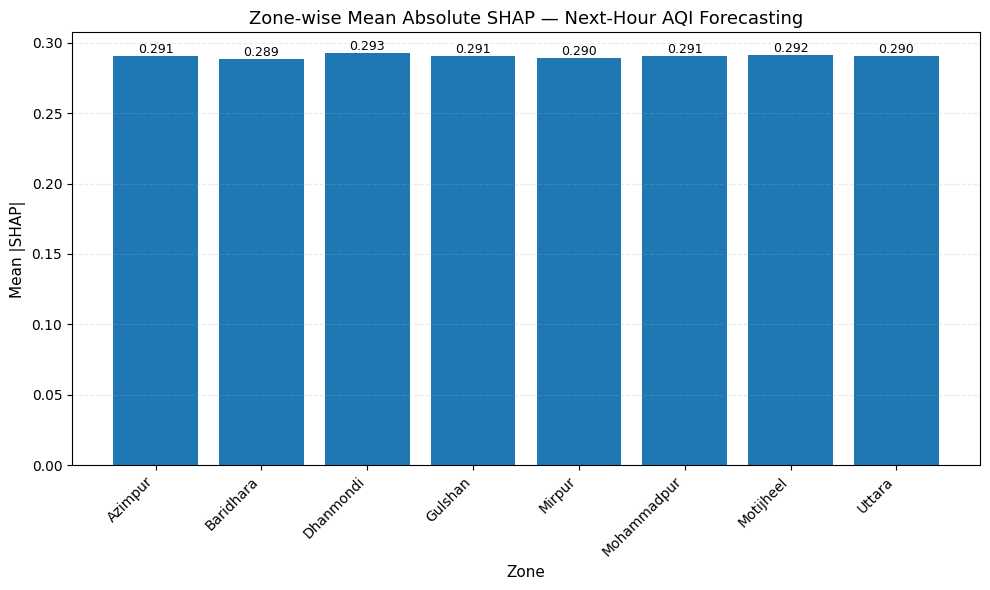


OPTIONAL FIGURES COMPLETE

Saved folder:
/content/drive/MyDrive/AQI_Project/results/OPTIONAL_PAPER_FIGURES

Files:
✓ Optional_Figure_1_Same_Hour_Confusion_Matrix_600dpi.png
✓ Optional_Figure_2_PM25_Regression_Actual_vs_Predicted_600dpi.png
✓ Optional_Figure_3_Next_Hour_Zone_Wise_Mean_SHAP.pdf
✓ Optional_Figure_3_Next_Hour_Zone_Wise_Mean_SHAP_600dpi.png
✓ Optional_Figure_3_Next_Hour_Zone_Wise_SHAP_DATA.csv

NO MODEL WAS RETRAINED.


In [ ]:
# ============================================================
# OPTIONAL PAPER FIGURES
# Secondary / Supporting Results
# NO RETRAINING
# ============================================================

import os
import shutil

PROJECT_DIR = "/content/drive/MyDrive/AQI_Project"
RESULT_DIR = os.path.join(PROJECT_DIR, "results")

OLD_FIG_DIR = os.path.join(
    RESULT_DIR,
    "paper_figures_600dpi"
)

OPTIONAL_DIR = os.path.join(
    RESULT_DIR,
    "OPTIONAL_PAPER_FIGURES"
)

os.makedirs(
    OPTIONAL_DIR,
    exist_ok=True
)

print("=" * 80)
print("OPTIONAL PAPER FIGURES")
print("=" * 80)

print("Folder:")
print(OPTIONAL_DIR)


# ============================================================
# HELPER
# ============================================================

def copy_if_exists(source, destination):

    if os.path.exists(source):

        shutil.copy2(
            source,
            destination
        )

        print(
            "✓ Copied:",
            os.path.basename(destination)
        )

    else:

        print(
            "✗ Not found:",
            source
        )


# ============================================================
# OPTIONAL FIGURE 1
# SAME-HOUR CONFUSION MATRIX
# ============================================================

source = os.path.join(
    OLD_FIG_DIR,
    "Figure_1_Same_Hour_Confusion_Matrix_600dpi.png"
)

destination = os.path.join(
    OPTIONAL_DIR,
    "Optional_Figure_1_Same_Hour_Confusion_Matrix_600dpi.png"
)

copy_if_exists(
    source,
    destination
)


# ============================================================
# OPTIONAL FIGURE 2
# PM2.5 REGRESSION — ACTUAL VS PREDICTED
# ============================================================

source = os.path.join(
    OLD_FIG_DIR,
    "Figure_3_PM25_Actual_vs_Predicted_600dpi.png"
)

destination = os.path.join(
    OPTIONAL_DIR,
    "Optional_Figure_2_PM25_Regression_Actual_vs_Predicted_600dpi.png"
)

copy_if_exists(
    source,
    destination
)


# ============================================================
# ALSO COPY ORIGINAL RESULT PNG IF NEEDED
# fallback for regression figure
# ============================================================

reg_optional_path = os.path.join(
    OPTIONAL_DIR,
    "Optional_Figure_2_PM25_Regression_Actual_vs_Predicted_600dpi.png"
)

if not os.path.exists(reg_optional_path):

    source = os.path.join(
        RESULT_DIR,
        "regression_actual_vs_predicted.png"
    )

    destination = reg_optional_path

    copy_if_exists(
        source,
        destination
    )


# ============================================================
# OPTIONAL FIGURE 3
# NEXT-HOUR ZONE-WISE MEAN SHAP
# XGBOOST COMPONENT
#
# Uses objects already created by the FINAL figure cell:
# X_shap_all, xgb_next_explainer
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SAMPLE_PER_ZONE = 300
RANDOM_STATE = 42

zone_labels = (
    test_next_df["zone"]
    .reset_index(drop=True)
)

rng = np.random.RandomState(
    RANDOM_STATE
)

zone_shap_results = []

print(
    "\nCalculating optional "
    "Next-hour zone-wise SHAP..."
)

for zone in sorted(
    zone_labels.unique()
):

    zone_idx = np.where(
        zone_labels.values == zone
    )[0]

    if len(zone_idx) > SAMPLE_PER_ZONE:

        selected_idx = rng.choice(
            zone_idx,
            size=SAMPLE_PER_ZONE,
            replace=False
        )

    else:

        selected_idx = zone_idx

    X_zone = (
        X_shap_all
        .iloc[selected_idx]
        .copy()
    )

    raw = (
        xgb_next_explainer
        .shap_values(X_zone)
    )

    zone_3d = shap_to_3d(
        raw,
        len(X_zone),
        X_zone.shape[1]
    )

    # Mean absolute SHAP over:
    # samples + features + classes
    mean_abs_shap = np.mean(
        np.abs(zone_3d)
    )

    zone_shap_results.append({
        "Zone": zone,
        "Mean |SHAP|": mean_abs_shap
    })

    print(
        zone,
        "->",
        round(mean_abs_shap, 6)
    )


zone_shap_optional = pd.DataFrame(
    zone_shap_results
)

zone_shap_optional = (
    zone_shap_optional
    .sort_values("Zone")
    .reset_index(drop=True)
)


# ============================================================
# PLOT
# ============================================================

fig, ax = plt.subplots(
    figsize=(10, 6)
)

bars = ax.bar(
    zone_shap_optional["Zone"],
    zone_shap_optional["Mean |SHAP|"]
)

ax.set_title(
    "Zone-wise Mean Absolute SHAP — "
    "Next-Hour AQI Forecasting",
    fontsize=13
)

ax.set_xlabel(
    "Zone",
    fontsize=11
)

ax.set_ylabel(
    "Mean |SHAP|",
    fontsize=11
)

plt.xticks(
    rotation=45,
    ha="right"
)

for bar, value in zip(
    bars,
    zone_shap_optional["Mean |SHAP|"]
):

    ax.text(
        bar.get_x()
        + bar.get_width()/2,

        bar.get_height(),

        f"{value:.3f}",

        ha="center",
        va="bottom",
        fontsize=9
    )

ax.set_ylim(bottom=0)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

plt.tight_layout()


# ============================================================
# SAVE PNG
# ============================================================

png_path = os.path.join(
    OPTIONAL_DIR,
    "Optional_Figure_3_Next_Hour_Zone_Wise_Mean_SHAP_600dpi.png"
)

fig.savefig(
    png_path,
    dpi=600,
    bbox_inches="tight"
)


# ============================================================
# SAVE VECTOR PDF
# ============================================================

pdf_path = os.path.join(
    OPTIONAL_DIR,
    "Optional_Figure_3_Next_Hour_Zone_Wise_Mean_SHAP.pdf"
)

fig.savefig(
    pdf_path,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ============================================================
# SAVE DATA
# ============================================================

zone_shap_optional.to_csv(
    os.path.join(
        OPTIONAL_DIR,
        "Optional_Figure_3_Next_Hour_Zone_Wise_SHAP_DATA.csv"
    ),
    index=False
)


# ============================================================
# FINAL CHECK
# ============================================================

print("\n" + "=" * 80)
print("OPTIONAL FIGURES COMPLETE")
print("=" * 80)

print("\nSaved folder:")
print(OPTIONAL_DIR)

print("\nFiles:")

for f in sorted(
    os.listdir(OPTIONAL_DIR)
):
    print("✓", f)

print(
    "\nNO MODEL WAS RETRAINED."
)

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
from pathlib import Path

root = Path("/content/drive/MyDrive/AQI_Project")

for relative_path in [
    "dhaka_aqi_final_featured.csv",
    "checkpoints",
    "models",
    "results/next_hour_AR_final_predictions.csv",
]:
    path = root / relative_path
    print(relative_path, "→", path.exists())

dhaka_aqi_final_featured.csv → True
checkpoints → True
models → True
results/next_hour_AR_final_predictions.csv → True


In [ ]:
import pandas as pd

ROOT = "/content/drive/MyDrive/AQI_Project"

df = pd.read_csv(
    f"{ROOT}/dhaka_aqi_final_featured.csv"
)

saved_pred = pd.read_csv(
    f"{ROOT}/results/next_hour_AR_final_predictions.csv"
)

print("Dataset shape:", df.shape)
print("\nDataset columns:")
print(df.columns.tolist())

print("\nPrediction file shape:", saved_pred.shape)
print("\nPrediction columns:")
print(saved_pred.columns.tolist())

print("\nPrediction file — first 5 rows:")
display(saved_pred.head())

Dataset shape: (236216, 81)

Dataset columns:
['timestamp', 'hour', 'day_of_week', 'month', 'zone', 'lat', 'lon', 'aqi_owm', 'co', 'no', 'no2', 'o3', 'so2', 'pm25', 'pm10', 'nh3', 'temperature', 'humidity', 'pressure', 'wind_speed', 'wind_dir', 'data_source', 'has_weather', 'pm25_lag1', 'pm25_lag2', 'pm25_lag3', 'pm25_lag6', 'pm25_lag12', 'pm10_lag1', 'pm10_lag2', 'pm10_lag3', 'pm10_lag6', 'pm10_lag12', 'no2_lag1', 'no2_lag2', 'no2_lag3', 'no2_lag6', 'no2_lag12', 'o3_lag1', 'o3_lag2', 'o3_lag3', 'o3_lag6', 'o3_lag12', 'so2_lag1', 'so2_lag2', 'so2_lag3', 'so2_lag6', 'so2_lag12', 'co_lag1', 'co_lag2', 'co_lag3', 'co_lag6', 'co_lag12', 'nh3_lag1', 'nh3_lag2', 'nh3_lag3', 'nh3_lag6', 'nh3_lag12', 'pm25_roll_mean_3h', 'pm25_roll_mean_6h', 'pm25_roll_std_3h', 'pm10_roll_mean_3h', 'pm10_roll_mean_6h', 'pm10_roll_std_3h', 'no2_roll_mean_3h', 'no2_roll_mean_6h', 'no2_roll_std_3h', 'temperature_lag1', 'humidity_lag1', 'wind_speed_lag1', 'no2_pm25_ratio', 'pollution_index', 'pm_ratio', 'oxidant_i

,Actual,Predicted
0,4,4
1,4,4
2,4,4
3,4,4
4,4,4


In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path

# 1. Original timestamp ও zone order
data = df.copy()
data["timestamp"] = pd.to_datetime(
    data["timestamp"], errors="raise"
)

assert not data.duplicated(["timestamp", "zone"]).any(), \
    "Duplicate timestamp-zone পাওয়া গেছে। এখানে থামো।"

data = data.sort_values(
    ["timestamp", "zone"]
).reset_index(drop=True)

# 2. Exact next-hour target তৈরি
future = data[["timestamp", "zone", "target"]].copy()

future["timestamp"] -= pd.Timedelta(hours=1)
future = future.rename(
    columns={"target": "target_next_hour"}
)

next_data = data.merge(
    future,
    on=["timestamp", "zone"],
    how="inner",
    validate="one_to_one"
).sort_values(
    ["timestamp", "zone"]
).reset_index(drop=True)

# 3. Original unique-timestamp split
times = np.sort(next_data["timestamp"].unique())
test_start = times[int(len(times) * 0.85)]

test_next_df = next_data.loc[
    next_data["timestamp"] >= test_start
].copy().reset_index(drop=True)

# 4. Saved Actual-এর সঙ্গে sequence check
assert len(test_next_df) == len(saved_pred) == 34600, \
    "Test row count মিলছে না। এখানে থামো।"

actual_matches = np.array_equal(
    test_next_df["target_next_hour"].to_numpy(),
    saved_pred["Actual"].to_numpy()
)

assert actual_matches, \
    "Saved Actual-এর order মিলছে না। এখানে থামো।"

print("Test rows:", len(test_next_df))
print("Test start:", test_next_df["timestamp"].min())
print("Test end:", test_next_df["timestamp"].max())
print("Actual sequence matches:", actual_matches)

# 5. Prediction যাচাইয়ের জন্য saved model files দেখো
for folder in ["models", "checkpoints"]:
    print(f"\n{folder}:")
    for path in sorted((Path(ROOT) / folder).iterdir()):
        if path.is_file() and "next" in path.name.lower():
            print(path.name)

Test rows: 34600
Test start: 2025-12-13 03:00:00
Test end: 2026-06-28 23:00:00
Actual sequence matches: True

models:
next_hour_et_final.pkl
next_hour_et_top20.pkl
next_hour_lgbm_final.pkl
next_hour_lgbm_top20.pkl
next_hour_meta_logreg.pkl
next_hour_rf_final.pkl
next_hour_rf_top20.pkl
next_hour_xgb_final.json
next_hour_xgb_top20.json

checkpoints:
next_ar_features.pkl
next_ar_oof_X.npy
next_ar_oof_classes.npy
next_ar_oof_time.npy
next_ar_oof_y.npy
next_hour_top20_features.pkl
next_oof_X.npy
next_oof_classes.npy
next_oof_time.npy
next_oof_y.npy
next_selected_features20.pkl


In [ ]:
print("Input feature count:", X.shape[1])
print("Input features:", X.columns.tolist())

for name, model in [
    ("RF", rf),
    ("ET", et),
    ("XGB", xgb),
    ("LGBM", lgbm),
    ("Meta", meta),
]:
    print(f"\n{name}")
    print("Expected features:", model.n_features_in_)

    names = getattr(model, "feature_names_in_", None)

    if names is None and name == "XGB":
        names = model.get_booster().feature_names

    if names is None and name == "LGBM":
        names = getattr(model, "feature_name_", None)

    if names is not None:
        print("Feature names:", list(names))

print("\nAvailable model files:")
for path in sorted((root / "models").rglob("*")):
    if path.is_file():
        print(path.relative_to(root / "models"))

Input feature count: 21
Input features: ['pm25', 'pm10', 'pm25_lag1', 'hour', 'co_lag3', 'pm10_lag1', 'co_lag2', 'is_peak_hour', 'so2_lag1', 'o3_lag3', 'no2', 'co_lag1', 'o3', 'co', 'hour_season', 'no', 'pm25_lag6', 'pm10_lag6', 'pm25_roll_mean_3h', 'season', 'target']

RF
Expected features: 20
Feature names: ['pm25', 'pm10', 'pm25_lag1', 'hour', 'co_lag3', 'pm10_lag1', 'co_lag2', 'is_peak_hour', 'so2_lag1', 'o3_lag3', 'no2', 'co_lag1', 'o3', 'co', 'hour_season', 'no', 'pm25_lag6', 'pm10_lag6', 'pm25_roll_mean_3h', 'season']

ET
Expected features: 20
Feature names: ['pm25', 'pm10', 'pm25_lag1', 'hour', 'co_lag3', 'pm10_lag1', 'co_lag2', 'is_peak_hour', 'so2_lag1', 'o3_lag3', 'no2', 'co_lag1', 'o3', 'co', 'hour_season', 'no', 'pm25_lag6', 'pm10_lag6', 'pm25_roll_mean_3h', 'season']

XGB
Expected features: 20
Feature names: [np.str_('pm25'), np.str_('pm10'), np.str_('pm25_lag1'), np.str_('hour'), np.str_('co_lag3'), np.str_('pm10_lag1'), np.str_('co_lag2'), np.str_('is_peak_hour'), np.st

In [ ]:
import numpy as np

FEATURES = [
    'pm25', 'pm10', 'pm25_lag1', 'hour', 'co_lag3',
    'pm10_lag1', 'co_lag2', 'is_peak_hour', 'so2_lag1',
    'o3_lag3', 'no2', 'co_lag1', 'o3', 'co',
    'hour_season', 'no', 'pm25_lag6', 'pm10_lag6',
    'pm25_roll_mean_3h', 'season'
]

# Exact model input
X_input = df[FEATURES].copy()

print("X_input shape:", X_input.shape)
print("Feature count:", X_input.shape[1])
print("Missing values:", X_input.isnull().sum().sum())

X_input shape: (236216, 20)
Feature count: 20
Missing values: 0


In [ ]:
# Base model probabilities
p_rf   = rf.predict_proba(X_input)
p_et   = et.predict_proba(X_input)
p_xgb  = xgb.predict_proba(X_input)
p_lgbm = lgbm.predict_proba(X_input)

print("RF:", p_rf.shape)
print("ET:", p_et.shape)
print("XGB:", p_xgb.shape)
print("LGBM:", p_lgbm.shape)

# Meta-model input
X_meta = np.hstack([
    p_rf,
    p_et,
    p_xgb,
    p_lgbm
])

print("Meta input shape:", X_meta.shape)

RF: (236216, 5)
ET: (236216, 5)
XGB: (236216, 5)
LGBM: (236216, 5)
Meta input shape: (236216, 20)


In [ ]:
import os
import glob
import joblib

# Find the saved next-hour meta model
possible_paths = []

if 'model_dir' in globals():
    possible_paths.append(
        os.path.join(model_dir, 'next_hour_meta_logreg.pkl')
    )

if 'MODEL_DIR' in globals():
    possible_paths.append(
        os.path.join(MODEL_DIR, 'next_hour_meta_logreg.pkl')
    )

# Search Google Drive if needed
possible_paths += glob.glob(
    '/content/drive/MyDrive/**/next_hour_meta_logreg.pkl',
    recursive=True
)

meta_path = next(
    (p for p in possible_paths if os.path.exists(p)),
    None
)

if meta_path is None:
    raise FileNotFoundError("next_hour_meta_logreg.pkl not found")

print("Meta model found:")
print(meta_path)

meta_model = joblib.load(meta_path)

print("Meta model loaded successfully ✅")
print("Expected features:", meta_model.n_features_in_)

Meta model found:
/content/drive/MyDrive/AQI_Project/models/next_hour_meta_logreg.pkl
Meta model loaded successfully ✅
Expected features: 20


In [ ]:
y_pred = meta_model.predict(X_meta)

print("Prediction shape:", y_pred.shape)
print("First 20 predictions:")
print(y_pred[:20])

Prediction shape: (236216,)
First 20 predictions:
[4 3 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4]


In [ ]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# -------------------------------
# 70 / 15 / 15 chronological split
# -------------------------------
n = len(df)

train_end = int(n * 0.70)
val_end   = int(n * 0.85)

# Test target
y_test = df['target'].iloc[val_end:].to_numpy()

# Since y_pred was generated for the full dataset,
# take only the same final 15% rows
y_pred_test = y_pred[val_end:]

print("Total rows :", n)
print("Train rows :", train_end)
print("Val rows   :", val_end - train_end)
print("Test rows  :", n - val_end)

print("\ny_test shape      :", y_test.shape)
print("y_pred_test shape :", y_pred_test.shape)

# -------------------------------
# Metrics
# -------------------------------
acc  = accuracy_score(y_test, y_pred_test)
prec = precision_score(
    y_test, y_pred_test,
    average='macro',
    zero_division=0
)
rec = recall_score(
    y_test, y_pred_test,
    average='macro',
    zero_division=0
)
f1 = f1_score(
    y_test, y_pred_test,
    average='macro',
    zero_division=0
)

print("\n===== NEXT-HOUR TEST RESULTS =====")
print(f"Accuracy        : {acc:.4f} ({acc*100:.2f}%)")
print(f"Macro Precision : {prec:.4f}")
print(f"Macro Recall    : {rec:.4f}")
print(f"Macro F1        : {f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_test,
        digits=4,
        zero_division=0
    )
)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_test))

Total rows : 236216
Train rows : 165351
Val rows   : 35432
Test rows  : 35433

y_test shape      : (35433,)
y_pred_test shape : (35433,)

===== NEXT-HOUR TEST RESULTS =====
Accuracy        : 0.8746 (87.46%)
Macro Precision : 0.8636
Macro Recall    : 0.8720
Macro F1        : 0.8662

Classification Report:
              precision    recall  f1-score   support

           0     0.9085    0.7958    0.8484      7077
           1     0.8043    0.8799    0.8404      7800
           2     0.7775    0.8628    0.8179      3317
           3     0.9330    0.8965    0.9144     11032
           4     0.8945    0.9252    0.9096      6207

    accuracy                         0.8746     35433
   macro avg     0.8636    0.8720    0.8662     35433
weighted avg     0.8785    0.8746    0.8751     35433

Confusion Matrix:
[[5632 1432    1   10    2]
 [ 565 6863  367    5    0]
 [   2  207 2862  246    0]
 [   0   21  446 9890  675]
 [   0   10    5  449 5743]]


In [ ]:
import os

search_root = "/content/drive/MyDrive"

keywords = [
    "next",
    "test",
    "split",
    "stack",
    "pred",
    "feature",
    "target",
    "selected"
]

found = []

for root, dirs, files in os.walk(search_root):
    for f in files:
        name = f.lower()
        if any(k in name for k in keywords):
            found.append(os.path.join(root, f))

print("Found files:", len(found))

for p in found:
    print(p)

Found files: 63
/content/drive/MyDrive/Colab Notebooks/Dhaka_AQI_Stacking_Final (2).ipynb
/content/drive/MyDrive/Colab Notebooks/Dhaka_AQI_Stacking_Final.ipynb
/content/drive/MyDrive/AQI_Project/dhaka_aqi_final_featured.csv
/content/drive/MyDrive/AQI_Project/checkpoints/same_hour_split_info.pkl
/content/drive/MyDrive/AQI_Project/checkpoints/selected_features_30.pkl
/content/drive/MyDrive/AQI_Project/checkpoints/next_hour_top20_features.pkl
/content/drive/MyDrive/AQI_Project/checkpoints/next_oof_X.npy
/content/drive/MyDrive/AQI_Project/checkpoints/next_oof_y.npy
/content/drive/MyDrive/AQI_Project/checkpoints/next_oof_classes.npy
/content/drive/MyDrive/AQI_Project/checkpoints/next_oof_time.npy
/content/drive/MyDrive/AQI_Project/checkpoints/next_selected_features20.pkl
/content/drive/MyDrive/AQI_Project/checkpoints/next_ar_oof_X.npy
/content/drive/MyDrive/AQI_Project/checkpoints/next_ar_oof_y.npy
/content/drive/MyDrive/AQI_Project/checkpoints/next_ar_oof_classes.npy
/content/drive/MyDrive

In [ ]:
import pandas as pd
import os

result_dir = "/content/drive/MyDrive/AQI_Project/results"

final_test_path = os.path.join(
    result_dir,
    "FINAL_next_hour_test.csv"
)

pred_path = os.path.join(
    result_dir,
    "next_hour_AR_final_predictions.csv"
)

# ==============================
# Load final next-hour results
# ==============================
final_test = pd.read_csv(final_test_path)

print("===== FINAL NEXT-HOUR TEST FILE =====")
print("Shape:", final_test.shape)
print("Columns:", final_test.columns.tolist())
print()
print(final_test.to_string(index=False))

# ==============================
# Load saved AR predictions
# ==============================
pred_df = pd.read_csv(pred_path)

print("\n\n===== NEXT-HOUR AR FINAL PREDICTIONS =====")
print("Shape:", pred_df.shape)
print("Columns:", pred_df.columns.tolist())
print()
print(pred_df.head(10))

===== FINAL NEXT-HOUR TEST FILE =====
Shape: (3, 3)
Columns: ['Model', 'Accuracy', 'Macro F1']

               Model  Accuracy  Macro F1
     Non-AR Stacking  0.880462  0.871540
         AR Stacking  0.934798  0.927854
Persistence Baseline  0.944971  0.939526


===== NEXT-HOUR AR FINAL PREDICTIONS =====
Shape: (34600, 2)
Columns: ['Actual', 'Predicted']

   Actual  Predicted
0       4          4
1       4          4
2       4          4
3       4          4
4       4          4
5       4          4
6       4          4
7       4          4
8       4          4
9       4          4


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Saved final predictions
y_true = pred_df["Actual"].values
y_pred_final = pred_df["Predicted"].values

acc = accuracy_score(y_true, y_pred_final)

macro_p = precision_score(
    y_true,
    y_pred_final,
    average="macro",
    zero_division=0
)

macro_r = recall_score(
    y_true,
    y_pred_final,
    average="macro",
    zero_division=0
)

macro_f1 = f1_score(
    y_true,
    y_pred_final,
    average="macro",
    zero_division=0
)

print("===== VERIFIED NEXT-HOUR AR STACKING =====")
print(f"Test samples     : {len(y_true)}")
print(f"Accuracy         : {acc:.6f} ({acc*100:.2f}%)")
print(f"Macro Precision  : {macro_p:.6f}")
print(f"Macro Recall     : {macro_r:.6f}")
print(f"Macro F1         : {macro_f1:.6f}")

print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred_final,
        digits=4,
        zero_division=0
    )
)

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred_final))

===== VERIFIED NEXT-HOUR AR STACKING =====
Test samples     : 34600
Accuracy         : 0.934798 (93.48%)
Macro Precision  : 0.922792
Macro Recall     : 0.933402
Macro F1         : 0.927854

Classification Report:
              precision    recall  f1-score   support

           0     0.8975    0.9555    0.9256      3592
           1     0.9586    0.9348    0.9465     10912
           2     0.9022    0.9065    0.9043      5048
           3     0.9525    0.9447    0.9486     10856
           4     0.9032    0.9256    0.9142      4192

    accuracy                         0.9348     34600
   macro avg     0.9228    0.9334    0.9279     34600
weighted avg     0.9354    0.9348    0.9349     34600


Confusion Matrix:
[[ 3432   144     0     8     8]
 [  392 10200   312     8     0]
 [    0   288  4576   184     0]
 [    0     8   184 10256   408]
 [    0     0     0   312  3880]]


In [ ]:
import os
import pandas as pd
import numpy as np
import joblib
from sklearn.metrics import confusion_matrix

RESULT_DIR = "/content/drive/MyDrive/AQI_Project/results"
CHECKPOINT_DIR = "/content/drive/MyDrive/AQI_Project/checkpoints"

os.makedirs(RESULT_DIR, exist_ok=True)
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

# --------------------------------
# 1. Save verified final metrics
# --------------------------------
verified_metrics = pd.DataFrame([{
    "Model": "AR Stacking",
    "Test_Samples": len(y_true),
    "Accuracy": acc,
    "Macro_Precision": macro_p,
    "Macro_Recall": macro_r,
    "Macro_F1": macro_f1
}])

verified_metrics.to_csv(
    os.path.join(RESULT_DIR, "VERIFIED_next_hour_AR_metrics.csv"),
    index=False
)

# --------------------------------
# 2. Save verified confusion matrix
# --------------------------------
cm = confusion_matrix(y_true, y_pred_final)

pd.DataFrame(cm).to_csv(
    os.path.join(RESULT_DIR, "VERIFIED_next_hour_AR_confusion_matrix.csv"),
    index=False
)

# --------------------------------
# 3. Save exact 20 features
# --------------------------------
joblib.dump(
    FEATURES,
    os.path.join(CHECKPOINT_DIR, "VERIFIED_next_hour_20_features.pkl")
)

# --------------------------------
# 4. Create resume note
# --------------------------------
resume_text = """
AQI PROJECT - RESUME INFORMATION

NEXT-HOUR FINAL VERIFIED RESULT
--------------------------------
Test samples     : 34600
Accuracy         : 0.934798 (93.48%)
Macro Precision  : 0.922792
Macro Recall     : 0.933402
Macro F1         : 0.927854

IMPORTANT:
Use saved original test predictions:
AQI_Project/results/next_hour_AR_final_predictions.csv

Do NOT use the temporary 87.46% result.
That came from reconstructing a different test split.

Final comparison:
Non-AR Stacking      Accuracy = 0.880462, Macro F1 = 0.871540
AR Stacking          Accuracy = 0.934798, Macro F1 = 0.927854
Persistence Baseline Accuracy = 0.944971, Macro F1 = 0.939526

Important model:
AQI_Project/models/next_hour_meta_logreg.pkl

Exact final prediction file:
AQI_Project/results/next_hour_AR_final_predictions.csv

Final results file:
AQI_Project/results/FINAL_next_hour_test.csv
"""

with open(
    os.path.join(RESULT_DIR, "RESUME_NEXT_HOUR_WORK.txt"),
    "w"
) as f:
    f.write(resume_text)

print("====================================")
print("ALL IMPORTANT CURRENT WORK SAVED ✅")
print("====================================")
print("Verified metrics saved ✅")
print("Confusion matrix saved ✅")
print("20 features saved ✅")
print("Resume note saved ✅")

ALL IMPORTANT CURRENT WORK SAVED ✅
Verified metrics saved ✅
Confusion matrix saved ✅
20 features saved ✅
Resume note saved ✅


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/AQI_Project")

files_to_check = [
    ROOT / "dhaka_aqi_final_featured.csv",
    ROOT / "results/next_hour_AR_final_predictions.csv",
    ROOT / "results/FINAL_next_hour_test.csv",
]

for p in files_to_check:
    print(p.name, "→", p.exists())

dhaka_aqi_final_featured.csv → True
next_hour_AR_final_predictions.csv → True
FINAL_next_hour_test.csv → True


In [ ]:
import numpy as np
import pandas as pd
import os

ROOT = "/content/drive/MyDrive/AQI_Project"

df = pd.read_csv(
    f"{ROOT}/dhaka_aqi_final_featured.csv"
)

saved_pred = pd.read_csv(
    f"{ROOT}/results/next_hour_AR_final_predictions.csv"
)

final_test = pd.read_csv(
    f"{ROOT}/results/FINAL_next_hour_test.csv"
)

print("Dataset shape:", df.shape)
print("Saved prediction shape:", saved_pred.shape)

print("\nPrediction columns:")
print(saved_pred.columns.tolist())

print("\nSaved final results:")
print(final_test.to_string(index=False))

Dataset shape: (236216, 81)
Saved prediction shape: (34600, 2)

Prediction columns:
['Actual', 'Predicted']

Saved final results:
               Model  Accuracy  Macro F1
     Non-AR Stacking  0.880462  0.871540
         AR Stacking  0.934798  0.927854
Persistence Baseline  0.944971  0.939526


In [ ]:
import numpy as np
import pandas as pd

# ==========================================
# Prepare original timestamp-zone order
# ==========================================

data = df.copy()

data["timestamp"] = pd.to_datetime(
    data["timestamp"],
    errors="raise"
)

# Same timestamp-zone duplicate থাকা যাবে না
assert not data.duplicated(
    ["timestamp", "zone"]
).any(), "Duplicate timestamp-zone found. Stop."

data = (
    data
    .sort_values(["timestamp", "zone"])
    .reset_index(drop=True)
)

# ==========================================
# Create exact NEXT-HOUR target
# ==========================================

future = data[
    ["timestamp", "zone", "target"]
].copy()

future["timestamp"] = (
    future["timestamp"]
    - pd.Timedelta(hours=1)
)

future = future.rename(
    columns={
        "target": "target_next_hour"
    }
)

next_data = data.merge(
    future,
    on=["timestamp", "zone"],
    how="inner",
    validate="one_to_one"
)

next_data = (
    next_data
    .sort_values(["timestamp", "zone"])
    .reset_index(drop=True)
)

# ==========================================
# Exact chronological 70 / 15 / 15 split
# based on UNIQUE TIMESTAMPS
# ==========================================

times = np.sort(
    next_data["timestamp"].unique()
)

test_start = times[
    int(len(times) * 0.85)
]

test_next_df = next_data.loc[
    next_data["timestamp"] >= test_start
].copy().reset_index(drop=True)

# ==========================================
# Verify against saved prediction file
# ==========================================

assert len(test_next_df) == 34600, \
    f"Wrong test size: {len(test_next_df)}"

assert len(saved_pred) == 34600, \
    f"Wrong saved prediction size: {len(saved_pred)}"

actual_matches = np.array_equal(
    test_next_df["target_next_hour"]
        .astype(int)
        .to_numpy(),

    saved_pred["Actual"]
        .astype(int)
        .to_numpy()
)

assert actual_matches, \
    "Saved Actual order does NOT match restored test set."

print("====================================")
print("EXACT NEXT-HOUR TEST SET RESTORED ✅")
print("====================================")
print("Test rows :", len(test_next_df))
print("Test start:", test_next_df["timestamp"].min())
print("Test end  :", test_next_df["timestamp"].max())
print("Actual sequence matches:", actual_matches)

EXACT NEXT-HOUR TEST SET RESTORED ✅
Test rows : 34600
Test start: 2025-12-13 03:00:00
Test end  : 2026-06-28 23:00:00
Actual sequence matches: True


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Actual next-hour category
y_true = (
    saved_pred["Actual"]
    .astype(int)
    .to_numpy()
)

# Saved AR stacking prediction
y_ar = (
    saved_pred["Predicted"]
    .astype(int)
    .to_numpy()
)

# Persistence = current AQI category
y_persistence = (
    test_next_df["target"]
    .astype(int)
    .to_numpy()
)

ar_acc = accuracy_score(
    y_true,
    y_ar
)

ar_f1 = f1_score(
    y_true,
    y_ar,
    average="macro",
    zero_division=0
)

pers_acc = accuracy_score(
    y_true,
    y_persistence
)

pers_f1 = f1_score(
    y_true,
    y_persistence,
    average="macro",
    zero_division=0
)

print("===== OVERALL TEST VERIFICATION =====")

print(
    f"AR Stacking : Accuracy = {ar_acc:.6f}, "
    f"Macro-F1 = {ar_f1:.6f}"
)

print(
    f"Persistence : Accuracy = {pers_acc:.6f}, "
    f"Macro-F1 = {pers_f1:.6f}"
)

===== OVERALL TEST VERIFICATION =====
AR Stacking : Accuracy = 0.934798, Macro-F1 = 0.927854
Persistence : Accuracy = 0.944971, Macro-F1 = 0.939526


In [ ]:
# =====================================================
# REVIEWER 3:
# CATEGORY-TRANSITION HOURS ONLY
# =====================================================

current_class = (
    test_next_df["target"]
    .astype(int)
    .to_numpy()
)

next_actual = y_true.copy()
ar_prediction = y_ar.copy()

persistence_prediction = current_class.copy()

# Transition occurs when:
# current AQI class != actual next-hour AQI class
transition_mask = (
    current_class != next_actual
)

stable_mask = ~transition_mask

n_total = len(next_actual)
n_transition = int(
    transition_mask.sum()
)
n_stable = int(
    stable_mask.sum()
)

print("========================================")
print("CATEGORY TRANSITION SUMMARY")
print("========================================")

print("Total test samples :", n_total)
print("Transition hours   :", n_transition)
print("Stable hours       :", n_stable)

print(
    "Transition rate    :",
    f"{n_transition/n_total*100:.2f}%"
)

CATEGORY TRANSITION SUMMARY
Total test samples : 34600
Transition hours   : 1904
Stable hours       : 32696
Transition rate    : 5.50%


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Transition subset
y_transition = (
    next_actual[transition_mask]
)

ar_transition = (
    ar_prediction[transition_mask]
)

pers_transition = (
    persistence_prediction[
        transition_mask
    ]
)

# ==========================================
# Helper
# ==========================================

def calculate_metrics(
    model_name,
    y_true,
    y_pred
):

    return {
        "Model": model_name,

        "Samples": len(y_true),

        "Accuracy":
            accuracy_score(
                y_true,
                y_pred
            ),

        "Macro Precision":
            precision_score(
                y_true,
                y_pred,
                average="macro",
                zero_division=0
            ),

        "Macro Recall":
            recall_score(
                y_true,
                y_pred,
                average="macro",
                zero_division=0
            ),

        "Macro F1":
            f1_score(
                y_true,
                y_pred,
                average="macro",
                zero_division=0
            )
    }


transition_results = pd.DataFrame([
    calculate_metrics(
        "AR Stacking",
        y_transition,
        ar_transition
    ),

    calculate_metrics(
        "Persistence Baseline",
        y_transition,
        pers_transition
    )
])

print(
    "===== CATEGORY-TRANSITION HOURS ONLY ====="
)

print(
    transition_results
    .round(6)
    .to_string(index=False)
)

===== CATEGORY-TRANSITION HOURS ONLY =====
               Model  Samples  Accuracy  Macro Precision  Macro Recall  Macro F1
         AR Stacking     1904   0.02521         0.030013      0.029304  0.029631
Persistence Baseline     1904   0.00000         0.000000      0.000000  0.000000


In [ ]:
# Did AR at least predict that a category change occurs?

ar_predicted_change = (
    ar_transition
    !=
    current_class[transition_mask]
)

transition_detection_rate = (
    ar_predicted_change.mean()
)

print(
    "AR transition detection rate:",
    f"{transition_detection_rate:.6f}",
    f"({transition_detection_rate*100:.2f}%)"
)

AR transition detection rate: 0.033613 (3.36%)


In [ ]:
# ==========================================
# WORSENING TRANSITIONS
# next category > current category
# ==========================================

worsening_mask = (
    next_actual > current_class
)

n_worsening = int(
    worsening_mask.sum()
)

print(
    "Worsening transitions:",
    n_worsening
)

if n_worsening > 0:

    # Exact-category accuracy during worsening
    worsening_acc = accuracy_score(
        next_actual[worsening_mask],
        ar_prediction[worsening_mask]
    )

    # Did model at least warn about worsening?
    worsening_warning_rate = np.mean(
        ar_prediction[worsening_mask]
        >
        current_class[worsening_mask]
    )

    print(
        "AR exact accuracy on worsening transitions:",
        f"{worsening_acc:.6f}",
        f"({worsening_acc*100:.2f}%)"
    )

    print(
        "AR correctly warned about worsening:",
        f"{worsening_warning_rate:.6f}",
        f"({worsening_warning_rate*100:.2f}%)"
    )

Worsening transitions: 936
AR exact accuracy on worsening transitions: 0.017094 (1.71%)
AR correctly warned about worsening: 0.034188 (3.42%)


In [ ]:
RESULT_DIR = (
    "/content/drive/MyDrive/"
    "AQI_Project/results"
)

os.makedirs(
    RESULT_DIR,
    exist_ok=True
)

# ==========================================
# Save summary table
# ==========================================

transition_results.to_csv(
    os.path.join(
        RESULT_DIR,
        "REVIEWER3_transition_hour_results.csv"
    ),
    index=False
)

# ==========================================
# Save every transition prediction
# ==========================================

transition_details = pd.DataFrame({

    "Timestamp":
        test_next_df.loc[
            transition_mask,
            "timestamp"
        ].reset_index(drop=True),

    "Zone":
        test_next_df.loc[
            transition_mask,
            "zone"
        ].reset_index(drop=True),

    "Current_Class":
        current_class[
            transition_mask
        ],

    "Actual_Next_Class":
        next_actual[
            transition_mask
        ],

    "AR_Predicted":
        ar_prediction[
            transition_mask
        ],

    "Persistence_Predicted":
        persistence_prediction[
            transition_mask
        ]
})

transition_details.to_csv(
    os.path.join(
        RESULT_DIR,
        "REVIEWER3_transition_hour_predictions.csv"
    ),
    index=False
)

# ==========================================
# Save additional practical metrics
# ==========================================

extra_metrics = pd.DataFrame([{

    "Total_Test_Samples":
        n_total,

    "Transition_Hours":
        n_transition,

    "Transition_Rate":
        n_transition / n_total,

    "AR_Transition_Detection_Rate":
        transition_detection_rate,

    "Worsening_Transitions":
        n_worsening,

    "AR_Worsening_Exact_Accuracy":
        worsening_acc
        if n_worsening > 0
        else np.nan,

    "AR_Worsening_Warning_Rate":
        worsening_warning_rate
        if n_worsening > 0
        else np.nan
}])

extra_metrics.to_csv(
    os.path.join(
        RESULT_DIR,
        "REVIEWER3_transition_practical_metrics.csv"
    ),
    index=False
)

print("=====================================")
print("REVIEWER 3 RESULTS SAVED TO DRIVE ✅")
print("=====================================")

REVIEWER 3 RESULTS SAVED TO DRIVE ✅


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path
import os
import numpy as np
import pandas as pd

ROOT = Path("/content/drive/MyDrive/AQI_Project")

DATA_PATH = ROOT / "dhaka_aqi_final_featured.csv"
PRED_PATH = ROOT / "results/next_hour_AR_final_predictions.csv"
FINAL_PATH = ROOT / "results/FINAL_next_hour_test.csv"

print("Dataset:", DATA_PATH.exists())
print("Predictions:", PRED_PATH.exists())
print("Final results:", FINAL_PATH.exists())

Dataset: True
Predictions: True
Final results: True


In [ ]:
df = pd.read_csv(DATA_PATH)

saved_pred = pd.read_csv(PRED_PATH)

final_test = pd.read_csv(FINAL_PATH)

print("Dataset shape:", df.shape)
print("Prediction shape:", saved_pred.shape)
print("Prediction columns:", saved_pred.columns.tolist())

print("\nSaved final results:")
print(final_test.to_string(index=False))

Dataset shape: (236216, 81)
Prediction shape: (34600, 2)
Prediction columns: ['Actual', 'Predicted']

Saved final results:
               Model  Accuracy  Macro F1
     Non-AR Stacking  0.880462  0.871540
         AR Stacking  0.934798  0.927854
Persistence Baseline  0.944971  0.939526


In [ ]:
# ============================================
# EXACT NEXT-HOUR TEST SET RESTORE
# ============================================

data = df.copy()

data["timestamp"] = pd.to_datetime(
    data["timestamp"],
    errors="raise"
)

# Check duplicates
print(
    "Duplicate timestamp-zone:",
    data.duplicated(["timestamp", "zone"]).sum()
)

assert not data.duplicated(
    ["timestamp", "zone"]
).any()

# Correct chronological order
data = (
    data
    .sort_values(["timestamp", "zone"])
    .reset_index(drop=True)
)

# --------------------------------------------
# Create next-hour target
# --------------------------------------------

future = data[
    ["timestamp", "zone", "target"]
].copy()

future["timestamp"] = (
    future["timestamp"]
    - pd.Timedelta(hours=1)
)

future = future.rename(
    columns={
        "target": "target_next_hour"
    }
)

next_data = data.merge(
    future,
    on=["timestamp", "zone"],
    how="inner",
    validate="one_to_one"
)

next_data = (
    next_data
    .sort_values(["timestamp", "zone"])
    .reset_index(drop=True)
)

# --------------------------------------------
# 70 / 15 / 15 by unique timestamp
# --------------------------------------------

unique_times = np.sort(
    next_data["timestamp"].unique()
)

test_start_index = int(
    len(unique_times) * 0.85
)

test_start_time = unique_times[
    test_start_index
]

test_next_df = next_data.loc[
    next_data["timestamp"] >= test_start_time
].copy().reset_index(drop=True)

print("Restored test rows:", len(test_next_df))
print("Test start:", test_next_df["timestamp"].min())
print("Test end:", test_next_df["timestamp"].max())

Duplicate timestamp-zone: 0
Restored test rows: 34600
Test start: 2025-12-13 03:00:00
Test end: 2026-06-28 23:00:00


In [ ]:
assert len(test_next_df) == 34600
assert len(saved_pred) == 34600

restored_actual = (
    test_next_df["target_next_hour"]
    .astype(int)
    .to_numpy()
)

saved_actual = (
    saved_pred["Actual"]
    .astype(int)
    .to_numpy()
)

actual_matches = np.array_equal(
    restored_actual,
    saved_actual
)

print("Actual sequence matches:", actual_matches)

assert actual_matches, \
    "STOP: restored test set does not match saved predictions."

print("EXACT TEST SET RESTORED SUCCESSFULLY ✅")

Actual sequence matches: True
EXACT TEST SET RESTORED SUCCESSFULLY ✅


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    f1_score
)

y_true = (
    saved_pred["Actual"]
    .astype(int)
    .to_numpy()
)

y_ar = (
    saved_pred["Predicted"]
    .astype(int)
    .to_numpy()
)

# Persistence = current AQI category
y_persistence = (
    test_next_df["target"]
    .astype(int)
    .to_numpy()
)

ar_acc = accuracy_score(
    y_true,
    y_ar
)

ar_f1 = f1_score(
    y_true,
    y_ar,
    average="macro",
    zero_division=0
)

pers_acc = accuracy_score(
    y_true,
    y_persistence
)

pers_f1 = f1_score(
    y_true,
    y_persistence,
    average="macro",
    zero_division=0
)

print("===== FINAL RESULT CHECK =====")

print(
    f"AR Stacking  : Accuracy={ar_acc:.6f}, "
    f"Macro-F1={ar_f1:.6f}"
)

print(
    f"Persistence  : Accuracy={pers_acc:.6f}, "
    f"Macro-F1={pers_f1:.6f}"
)

===== FINAL RESULT CHECK =====
AR Stacking  : Accuracy=0.934798, Macro-F1=0.927854
Persistence  : Accuracy=0.944971, Macro-F1=0.939526


In [ ]:
# ============================================================
# REVIEWER ERROR 4
# 95% CI + Standard Deviation + Wilcoxon Signed-Rank Test
# ============================================================

from scipy.stats import wilcoxon
from sklearn.metrics import confusion_matrix

CLASSES = np.array([0, 1, 2, 3, 4])

# Date blocks
dates = (
    pd.to_datetime(test_next_df["timestamp"])
    .dt.date
    .to_numpy()
)

unique_days = np.unique(dates)

print("Number of daily blocks:", len(unique_days))


# ------------------------------------------------------------
# Metric helper
# ------------------------------------------------------------

def metrics_from_cm(cm):

    total = cm.sum()

    accuracy = np.trace(cm) / total

    tp = np.diag(cm)

    precision = np.divide(
        tp,
        cm.sum(axis=0),
        out=np.zeros_like(tp, dtype=float),
        where=cm.sum(axis=0) != 0
    )

    recall = np.divide(
        tp,
        cm.sum(axis=1),
        out=np.zeros_like(tp, dtype=float),
        where=cm.sum(axis=1) != 0
    )

    f1 = np.divide(
        2 * precision * recall,
        precision + recall,
        out=np.zeros_like(precision, dtype=float),
        where=(precision + recall) != 0
    )

    return accuracy, np.mean(f1)


# ------------------------------------------------------------
# Daily results
# ------------------------------------------------------------

ar_daily_acc = []
pers_daily_acc = []

ar_day_cm = []
pers_day_cm = []

for day in unique_days:

    idx = dates == day

    cm_ar = confusion_matrix(
        y_true[idx],
        y_ar[idx],
        labels=CLASSES
    )

    cm_pers = confusion_matrix(
        y_true[idx],
        y_persistence[idx],
        labels=CLASSES
    )

    ar_day_cm.append(cm_ar)
    pers_day_cm.append(cm_pers)

    ar_daily_acc.append(
        accuracy_score(
            y_true[idx],
            y_ar[idx]
        )
    )

    pers_daily_acc.append(
        accuracy_score(
            y_true[idx],
            y_persistence[idx]
        )
    )


ar_day_cm = np.asarray(ar_day_cm)
pers_day_cm = np.asarray(pers_day_cm)

ar_daily_acc = np.asarray(ar_daily_acc)
pers_daily_acc = np.asarray(pers_daily_acc)


# ------------------------------------------------------------
# Standard deviation
# ------------------------------------------------------------

ar_sd = np.std(
    ar_daily_acc,
    ddof=1
)

pers_sd = np.std(
    pers_daily_acc,
    ddof=1
)


# ------------------------------------------------------------
# 5000 day-block bootstrap
# ------------------------------------------------------------

N_BOOT = 5000

rng = np.random.default_rng(42)

n_days = len(unique_days)

boot_ar_acc = np.empty(N_BOOT)
boot_ar_f1 = np.empty(N_BOOT)

boot_pers_acc = np.empty(N_BOOT)
boot_pers_f1 = np.empty(N_BOOT)

for b in range(N_BOOT):

    sample_idx = rng.integers(
        0,
        n_days,
        size=n_days
    )

    ar_cm_boot = (
        ar_day_cm[sample_idx]
        .sum(axis=0)
    )

    pers_cm_boot = (
        pers_day_cm[sample_idx]
        .sum(axis=0)
    )

    (
        boot_ar_acc[b],
        boot_ar_f1[b]
    ) = metrics_from_cm(
        ar_cm_boot
    )

    (
        boot_pers_acc[b],
        boot_pers_f1[b]
    ) = metrics_from_cm(
        pers_cm_boot
    )


def ci95(x):
    return np.percentile(
        x,
        [2.5, 97.5]
    )


ar_acc_ci = ci95(
    boot_ar_acc
)

ar_f1_ci = ci95(
    boot_ar_f1
)

pers_acc_ci = ci95(
    boot_pers_acc
)

pers_f1_ci = ci95(
    boot_pers_f1
)


# ------------------------------------------------------------
# Full dataset point estimates
# ------------------------------------------------------------

ar_cm_full = confusion_matrix(
    y_true,
    y_ar,
    labels=CLASSES
)

pers_cm_full = confusion_matrix(
    y_true,
    y_persistence,
    labels=CLASSES
)

ar_acc_point, ar_f1_point = (
    metrics_from_cm(
        ar_cm_full
    )
)

pers_acc_point, pers_f1_point = (
    metrics_from_cm(
        pers_cm_full
    )
)


# ------------------------------------------------------------
# Wilcoxon signed-rank:
# paired daily accuracies
# ------------------------------------------------------------

w_stat, p_value = wilcoxon(
    ar_daily_acc,
    pers_daily_acc,
    alternative="two-sided",
    zero_method="wilcox"
)


# ------------------------------------------------------------
# Final table
# ------------------------------------------------------------

results_error4 = pd.DataFrame([

    {
        "Model": "AR Stacking",
        "Accuracy": ar_acc_point,
        "Accuracy_CI_Low": ar_acc_ci[0],
        "Accuracy_CI_High": ar_acc_ci[1],
        "Daily_Accuracy_SD": ar_sd,
        "Macro_F1": ar_f1_point,
        "Macro_F1_CI_Low": ar_f1_ci[0],
        "Macro_F1_CI_High": ar_f1_ci[1]
    },

    {
        "Model": "Persistence Baseline",
        "Accuracy": pers_acc_point,
        "Accuracy_CI_Low": pers_acc_ci[0],
        "Accuracy_CI_High": pers_acc_ci[1],
        "Daily_Accuracy_SD": pers_sd,
        "Macro_F1": pers_f1_point,
        "Macro_F1_CI_Low": pers_f1_ci[0],
        "Macro_F1_CI_High": pers_f1_ci[1]
    }
])


print("\n===== UNCERTAINTY RESULTS =====")

print(
    results_error4
    .round(6)
    .to_string(index=False)
)

print("\n===== WILCOXON TEST =====")

print("Daily blocks:", n_days)
print("Wilcoxon statistic:", w_stat)
print("p-value:", p_value)
print(
    "Significant at p < 0.05:",
    p_value < 0.05
)

Number of daily blocks: 190

===== UNCERTAINTY RESULTS =====
               Model  Accuracy  Accuracy_CI_Low  Accuracy_CI_High  Daily_Accuracy_SD  Macro_F1  Macro_F1_CI_Low  Macro_F1_CI_High
         AR Stacking  0.934798         0.925093          0.943766            0.07007  0.927854         0.914458          0.937862
Persistence Baseline  0.944971         0.937327          0.952242            0.06010  0.939526         0.930676          0.946444

===== WILCOXON TEST =====
Daily blocks: 190
Wilcoxon statistic: 40.5
p-value: 0.0009308797853100324
Significant at p < 0.05: True


In [ ]:
RESULT_DIR = (
    "/content/drive/MyDrive/"
    "AQI_Project/results"
)

os.makedirs(
    RESULT_DIR,
    exist_ok=True
)

results_error4.to_csv(
    os.path.join(
        RESULT_DIR,
        "REVIEWER4_uncertainty_results.csv"
    ),
    index=False
)

wilcoxon_df = pd.DataFrame([{
    "Comparison":
        "AR Stacking vs Persistence",

    "Daily_Blocks":
        n_days,

    "Wilcoxon_Statistic":
        w_stat,

    "p_value":
        p_value,

    "Significant_p_lt_0.05":
        p_value < 0.05
}])

wilcoxon_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "REVIEWER4_wilcoxon_results.csv"
    ),
    index=False
)

print("REVIEWER 4 RESULTS SAVED TO DRIVE ✅")

REVIEWER 4 RESULTS SAVED TO DRIVE ✅


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path

DATA_PATH = Path(
    "/content/drive/MyDrive/AQI_Project/dhaka_aqi_final_featured.csv"
)

print("Dataset exists:", DATA_PATH.exists())
print("Path:", DATA_PATH)

Dataset exists: True
Path: /content/drive/MyDrive/AQI_Project/dhaka_aqi_final_featured.csv


In [ ]:
import pandas as pd

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
print("Total columns:", len(df.columns))

Dataset shape: (236216, 81)
Total columns: 81


In [ ]:
print("===== EXACT DATASET COLUMNS =====")

for i, col in enumerate(df.columns, start=1):
    print(f"{i:02d}. {col}")

===== EXACT DATASET COLUMNS =====
01. timestamp
02. hour
03. day_of_week
04. month
05. zone
06. lat
07. lon
08. aqi_owm
09. co
10. no
11. no2
12. o3
13. so2
14. pm25
15. pm10
16. nh3
17. temperature
18. humidity
19. pressure
20. wind_speed
21. wind_dir
22. data_source
23. has_weather
24. pm25_lag1
25. pm25_lag2
26. pm25_lag3
27. pm25_lag6
28. pm25_lag12
29. pm10_lag1
30. pm10_lag2
31. pm10_lag3
32. pm10_lag6
33. pm10_lag12
34. no2_lag1
35. no2_lag2
36. no2_lag3
37. no2_lag6
38. no2_lag12
39. o3_lag1
40. o3_lag2
41. o3_lag3
42. o3_lag6
43. o3_lag12
44. so2_lag1
45. so2_lag2
46. so2_lag3
47. so2_lag6
48. so2_lag12
49. co_lag1
50. co_lag2
51. co_lag3
52. co_lag6
53. co_lag12
54. nh3_lag1
55. nh3_lag2
56. nh3_lag3
57. nh3_lag6
58. nh3_lag12
59. pm25_roll_mean_3h
60. pm25_roll_mean_6h
61. pm25_roll_std_3h
62. pm10_roll_mean_3h
63. pm10_roll_mean_6h
64. pm10_roll_std_3h
65. no2_roll_mean_3h
66. no2_roll_mean_6h
67. no2_roll_std_3h
68. temperature_lag1
69. humidity_lag1
70. wind_speed_lag1
71

In [ ]:
print("\n===== COPY-FRIENDLY COLUMN LIST =====")
print(", ".join(df.columns.tolist()))


===== COPY-FRIENDLY COLUMN LIST =====
timestamp, hour, day_of_week, month, zone, lat, lon, aqi_owm, co, no, no2, o3, so2, pm25, pm10, nh3, temperature, humidity, pressure, wind_speed, wind_dir, data_source, has_weather, pm25_lag1, pm25_lag2, pm25_lag3, pm25_lag6, pm25_lag12, pm10_lag1, pm10_lag2, pm10_lag3, pm10_lag6, pm10_lag12, no2_lag1, no2_lag2, no2_lag3, no2_lag6, no2_lag12, o3_lag1, o3_lag2, o3_lag3, o3_lag6, o3_lag12, so2_lag1, so2_lag2, so2_lag3, so2_lag6, so2_lag12, co_lag1, co_lag2, co_lag3, co_lag6, co_lag12, nh3_lag1, nh3_lag2, nh3_lag3, nh3_lag6, nh3_lag12, pm25_roll_mean_3h, pm25_roll_mean_6h, pm25_roll_std_3h, pm10_roll_mean_3h, pm10_roll_mean_6h, pm10_roll_std_3h, no2_roll_mean_3h, no2_roll_mean_6h, no2_roll_std_3h, temperature_lag1, humidity_lag1, wind_speed_lag1, no2_pm25_ratio, pollution_index, pm_ratio, oxidant_index, is_weekend, season, is_peak_hour, hour_season, year, zone_encoded, target


In [ ]:
integration_cols = [
    "timestamp",
    "zone",
    "lat",
    "lon",
    "data_source",
    "has_weather"
]

print("===== INTEGRATION COLUMNS =====")

for col in integration_cols:
    print(
        f"{col}:",
        "FOUND ✅" if col in df.columns else "NOT FOUND ❌"
    )

===== INTEGRATION COLUMNS =====
timestamp: FOUND ✅
zone: FOUND ✅
lat: FOUND ✅
lon: FOUND ✅
data_source: FOUND ✅
has_weather: FOUND ✅


In [ ]:
raw_cols = [
    "aqi_owm",
    "co",
    "no",
    "no2",
    "o3",
    "so2",
    "pm25",
    "pm10",
    "nh3",
    "temperature",
    "humidity",
    "pressure",
    "wind_speed",
    "wind_dir"
]

print("===== RAW / WEATHER COLUMNS =====")

for col in raw_cols:
    print(
        f"{col}:",
        "FOUND ✅" if col in df.columns else "NOT FOUND ❌"
    )

===== RAW / WEATHER COLUMNS =====
aqi_owm: FOUND ✅
co: FOUND ✅
no: FOUND ✅
no2: FOUND ✅
o3: FOUND ✅
so2: FOUND ✅
pm25: FOUND ✅
pm10: FOUND ✅
nh3: FOUND ✅
temperature: FOUND ✅
humidity: FOUND ✅
pressure: FOUND ✅
wind_speed: FOUND ✅
wind_dir: FOUND ✅


In [ ]:
groups = {
    "Lag features": [
        c for c in df.columns
        if "_lag" in c
    ],

    "Rolling features": [
        c for c in df.columns
        if "roll" in c.lower()
    ],

    "Ratio features": [
        c for c in df.columns
        if "ratio" in c.lower()
    ],

    "Temporal features": [
        c for c in df.columns
        if c in [
            "hour",
            "day_of_week",
            "month",
            "season",
            "is_weekend",
            "is_peak_hour",
            "hour_season"
        ]
    ],

    "Target-like columns": [
        c for c in df.columns
        if "target" in c.lower()
    ]
}

for group_name, cols in groups.items():
    print(f"\n===== {group_name.upper()} =====")
    print("Count:", len(cols))
    print(cols)


===== LAG FEATURES =====
Count: 38
['pm25_lag1', 'pm25_lag2', 'pm25_lag3', 'pm25_lag6', 'pm25_lag12', 'pm10_lag1', 'pm10_lag2', 'pm10_lag3', 'pm10_lag6', 'pm10_lag12', 'no2_lag1', 'no2_lag2', 'no2_lag3', 'no2_lag6', 'no2_lag12', 'o3_lag1', 'o3_lag2', 'o3_lag3', 'o3_lag6', 'o3_lag12', 'so2_lag1', 'so2_lag2', 'so2_lag3', 'so2_lag6', 'so2_lag12', 'co_lag1', 'co_lag2', 'co_lag3', 'co_lag6', 'co_lag12', 'nh3_lag1', 'nh3_lag2', 'nh3_lag3', 'nh3_lag6', 'nh3_lag12', 'temperature_lag1', 'humidity_lag1', 'wind_speed_lag1']

===== ROLLING FEATURES =====
Count: 9
['pm25_roll_mean_3h', 'pm25_roll_mean_6h', 'pm25_roll_std_3h', 'pm10_roll_mean_3h', 'pm10_roll_mean_6h', 'pm10_roll_std_3h', 'no2_roll_mean_3h', 'no2_roll_mean_6h', 'no2_roll_std_3h']

===== RATIO FEATURES =====
Count: 2
['no2_pm25_ratio', 'pm_ratio']

===== TEMPORAL FEATURES =====
Count: 7
['hour', 'day_of_week', 'month', 'is_weekend', 'season', 'is_peak_hour', 'hour_season']

===== TARGET-LIKE COLUMNS =====
Count: 1
['target']


In [ ]:
# ============================================================
# SAVE REVIEWER-FIX CHECKPOINT
# Exact 81 attributes + feature groups + resume information
# ============================================================

import os
import json
import joblib
import pandas as pd

BASE_DIR = "/content/drive/MyDrive/AQI_Project"
CHECKPOINT_DIR = os.path.join(BASE_DIR, "checkpoints")
RESULT_DIR = os.path.join(BASE_DIR, "results")

os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)

# ------------------------------------------------------------
# 1. Safety check
# ------------------------------------------------------------

assert "df" in globals(), "df is not loaded."
assert len(df.columns) == 81, f"Expected 81 columns, found {len(df.columns)}"

exact_columns = df.columns.tolist()

# ------------------------------------------------------------
# 2. Save exact 81-column list
# ------------------------------------------------------------

joblib.dump(
    exact_columns,
    os.path.join(
        CHECKPOINT_DIR,
        "REVIEWER10_exact_81_columns.pkl"
    )
)

pd.DataFrame({
    "No": range(1, len(exact_columns) + 1),
    "Attribute": exact_columns
}).to_csv(
    os.path.join(
        RESULT_DIR,
        "REVIEWER10_complete_81_attribute_list.csv"
    ),
    index=False
)

# ------------------------------------------------------------
# 3. Save feature groups
# ------------------------------------------------------------

feature_groups = {
    "lag_features": [
        c for c in df.columns
        if "_lag" in c
    ],

    "rolling_features": [
        c for c in df.columns
        if "roll" in c.lower()
    ],

    "ratio_features": [
        c for c in df.columns
        if "ratio" in c.lower()
    ],

    "temporal_features": [
        c for c in df.columns
        if c in [
            "hour",
            "day_of_week",
            "month",
            "is_weekend",
            "season",
            "is_peak_hour",
            "hour_season"
        ]
    ],

    "integration_columns": [
        c for c in [
            "timestamp",
            "zone",
            "lat",
            "lon",
            "data_source",
            "has_weather"
        ]
        if c in df.columns
    ],

    "target_columns": [
        c for c in df.columns
        if "target" in c.lower()
    ]
}

with open(
    os.path.join(
        CHECKPOINT_DIR,
        "REVIEWER10_feature_groups.json"
    ),
    "w"
) as f:
    json.dump(
        feature_groups,
        f,
        indent=4
    )

# ------------------------------------------------------------
# 4. Save compact project resume note
# ------------------------------------------------------------

resume_note = f"""
AQI PROJECT - REVIEWER FIX CHECKPOINT

Dataset shape:
{df.shape}

Total attributes:
{len(exact_columns)}

Error 10 verification:
- Exact dataset = 236216 rows x 81 columns
- Integration columns verified:
  timestamp, zone, lat, lon, data_source, has_weather
- Exact 81-column list saved
- Feature groups saved

Important saved files:
1. checkpoints/REVIEWER10_exact_81_columns.pkl
2. checkpoints/REVIEWER10_feature_groups.json
3. results/REVIEWER10_complete_81_attribute_list.csv

Earlier verified next-hour result:
AR Stacking Accuracy = 93.48%
Macro-F1 = 0.927854

Persistence Accuracy = 94.50%

Reviewer 3 transition result:
Transition hours = 1904
AR transition accuracy = 2.52%
Persistence transition accuracy = 0%

Reviewer 4:
Wilcoxon W = 40.5
p = 0.00093

No model retraining is required to restore this checkpoint.
"""

with open(
    os.path.join(
        RESULT_DIR,
        "REVIEWER_FIX_RESUME_CHECKPOINT.txt"
    ),
    "w"
) as f:
    f.write(resume_note)

# ------------------------------------------------------------
# 5. Verify files
# ------------------------------------------------------------

files_to_verify = [
    os.path.join(
        CHECKPOINT_DIR,
        "REVIEWER10_exact_81_columns.pkl"
    ),
    os.path.join(
        CHECKPOINT_DIR,
        "REVIEWER10_feature_groups.json"
    ),
    os.path.join(
        RESULT_DIR,
        "REVIEWER10_complete_81_attribute_list.csv"
    ),
    os.path.join(
        RESULT_DIR,
        "REVIEWER_FIX_RESUME_CHECKPOINT.txt"
    )
]

print("=" * 55)
print("REVIEWER FIX CHECKPOINT SAVED ✅")
print("=" * 55)

for p in files_to_verify:
    print(
        os.path.basename(p),
        "→",
        os.path.exists(p)
    )

print("\nDataset shape:", df.shape)
print("Exact attributes saved:", len(exact_columns))

REVIEWER FIX CHECKPOINT SAVED ✅
REVIEWER10_exact_81_columns.pkl → True
REVIEWER10_feature_groups.json → True
REVIEWER10_complete_81_attribute_list.csv → True
REVIEWER_FIX_RESUME_CHECKPOINT.txt → True

Dataset shape: (236216, 81)
Exact attributes saved: 81


In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
from pathlib import Path
import pandas as pd

ROOT = Path("/content/drive/MyDrive/AQI_Project")

csv_path = (
    ROOT / "results/FINAL_FIXED_PAPER_FIGURES"
    / "Figure_3_Error_Rate_by_Hour_DATA.csv"
)

print("Hourly-error CSV found:", csv_path.exists())

if csv_path.exists():
    hourly_data = pd.read_csv(csv_path)
    print("Columns:", hourly_data.columns.tolist())
    display(hourly_data.head())
else:
    print("\nPossible hourly-error files:")
    for path in sorted((ROOT / "results").rglob("*.csv")):
        if "hour" in path.name.lower() and "error" in path.name.lower():
            print(path)

Hourly-error CSV found: True
Columns: ['Hour', 'Error Rate (%)', 'Errors', 'Total Samples']


,Hour,Error Rate (%),Errors,Total Samples
0,0,6.145251,88,1432
1,1,7.821229,112,1432
2,2,3.910615,56,1432
3,3,5.000000,72,1440
4,4,2.777778,40,1440


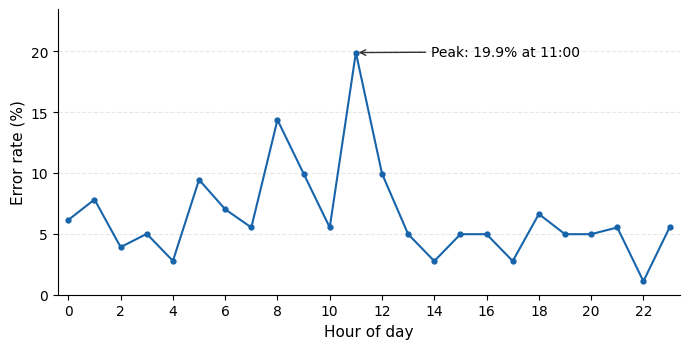

PNG saved: /content/drive/MyDrive/AQI_Project/results/REVIEWER6_FIXED_FIGURES/Next_Hour_Error_by_Hour_Fixed.png
PDF saved: /content/drive/MyDrive/AQI_Project/results/REVIEWER6_FIXED_FIGURES/Next_Hour_Error_by_Hour_Fixed.pdf


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Saved data সাজানো ও যাচাই
plot_data = hourly_data.sort_values("Hour").copy()

assert not plot_data["Hour"].duplicated().any()
assert (plot_data["Total Samples"] > 0).all()

assert np.allclose(
    plot_data["Error Rate (%)"],
    100 * plot_data["Errors"] / plot_data["Total Samples"],
    atol=0.001
), "Saved error rates এবং counts মিলছে না।"

worst = plot_data.loc[
    plot_data["Error Rate (%)"].idxmax()
]

# Compact, readable figure
fig, ax = plt.subplots(figsize=(7, 3.6))

ax.plot(
    plot_data["Hour"],
    plot_data["Error Rate (%)"],
    color="#1764AB",
    marker="o",
    markersize=3.5,
    linewidth=1.5
)

ax.set_xlabel("Hour of day", fontsize=11)
ax.set_ylabel("Error rate (%)", fontsize=11)

ax.set_xticks(range(0, 24, 2))
ax.set_xlim(-0.4, 23.4)
ax.set_ylim(0, plot_data["Error Rate (%)"].max() * 1.18)

ax.tick_params(labelsize=10)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Annotation plot-এর ভেতরে থাকবে
ax.annotate(
    f"Peak: {worst['Error Rate (%)']:.1f}% "
    f"at {int(worst['Hour']):02d}:00",
    xy=(worst["Hour"], worst["Error Rate (%)"]),
    xytext=(0.60, 0.85),
    textcoords="axes fraction",
    fontsize=10,
    ha="left",
    va="center",
    arrowprops=dict(
        arrowstyle="->",
        color="#333333",
        linewidth=1
    )
)

fig.tight_layout()

# নতুন নামে save—পুরোনো figure থাকবে
output_dir = ROOT / "results/REVIEWER6_FIXED_FIGURES"
output_dir.mkdir(parents=True, exist_ok=True)

png_path = output_dir / "Next_Hour_Error_by_Hour_Fixed.png"
pdf_path = output_dir / "Next_Hour_Error_by_Hour_Fixed.pdf"

fig.savefig(png_path, dpi=600, bbox_inches="tight")
fig.savefig(pdf_path, bbox_inches="tight")

plt.show()
plt.close(fig)

print("PNG saved:", png_path)
print("PDF saved:", pdf_path)

In [ ]:
from google.colab import files
files.download(str(pdf_path))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import json
from pathlib import Path
import pandas as pd

ROOT = Path("/content/drive/MyDrive/AQI_Project")
SAVE_DIR = ROOT / "results/REVIEWER6_FIXED_FIGURES"
SAVE_DIR.mkdir(parents=True, exist_ok=True)

# Save the data used for the figure
data_path = SAVE_DIR / "hourly_error_data.csv"
plot_data.to_csv(data_path, index=False)

png_path = SAVE_DIR / "Next_Hour_Error_by_Hour_Fixed.png"
pdf_path = SAVE_DIR / "Next_Hour_Error_by_Hour_Fixed.pdf"

# Confirm all required files exist
for path in [data_path, png_path, pdf_path]:
    assert path.exists() and path.stat().st_size > 0, \
        f"Missing or empty file: {path.name}"

# Verify saved data
restored = pd.read_csv(data_path)
pd.testing.assert_frame_equal(
    plot_data.reset_index(drop=True),
    restored,
    check_dtype=False,
    check_exact=False
)

checkpoint = {
    "task": "Reviewer Error 6: hourly-error figure correction",
    "status": "Figure and data saved; Overleaf replacement pending verification",
    "data_csv": str(data_path),
    "figure_png": str(png_path),
    "figure_pdf": str(pdf_path),
    "gpu_required": False,
    "model_training_required": False,
    "next_task": "Error 7: remove unsupported SMOTE results and claims"
}

checkpoint_path = SAVE_DIR / "reviewer6_checkpoint.json"
checkpoint_path.write_text(
    json.dumps(checkpoint, indent=2),
    encoding="utf-8"
)

print("Checkpoint saved successfully.")
for path in [data_path, png_path, pdf_path, checkpoint_path]:
    print("OK:", path.name)

Checkpoint saved successfully.
OK: hourly_error_data.csv
OK: Next_Hour_Error_by_Hour_Fixed.png
OK: Next_Hour_Error_by_Hour_Fixed.pdf
OK: reviewer6_checkpoint.json


In [ ]:
from google.colab import drive
drive.mount("/content/drive")

import json
import pandas as pd
from pathlib import Path

SAVE_DIR = Path(
    "/content/drive/MyDrive/AQI_Project/results/"
    "REVIEWER6_FIXED_FIGURES"
)

checkpoint = json.loads(
    (SAVE_DIR / "reviewer6_checkpoint.json").read_text()
)
hourly_data = pd.read_csv(checkpoint["data_csv"])

print("Checkpoint restored.")
display(hourly_data.head())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Checkpoint restored.


,Hour,Error Rate (%),Errors,Total Samples
0,0,6.145251,88,1432
1,1,7.821229,112,1432
2,2,3.910615,56,1432
3,3,5.000000,72,1440
4,4,2.777778,40,1440


In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
from pathlib import Path
import platform
import subprocess
import os

ROOT = Path("/content/drive/MyDrive/AQI_Project")

assert ROOT.exists(), "AQI_Project folder পাওয়া যায়নি।"

print("===== CURRENT HARDWARE =====")
print("OS:", platform.platform())
print("Python:", platform.python_version())
print("Logical CPU cores:", os.cpu_count())

cpu_info = Path("/proc/cpuinfo")
if cpu_info.exists():
    for line in cpu_info.read_text().splitlines():
        if line.startswith("model name"):
            print("CPU:", line.split(":", 1)[1].strip())
            break

try:
    import psutil
    print(
        "RAM (GB):",
        round(psutil.virtual_memory().total / 1024**3, 2)
    )
except ImportError:
    pass

try:
    result = subprocess.run(
        [
            "nvidia-smi",
            "--query-gpu=name,memory.total",
            "--format=csv,noheader"
        ],
        capture_output=True,
        text=True,
        timeout=10
    )
    print("GPU:", result.stdout.strip() or "Not available")
except FileNotFoundError:
    print("GPU: Not available")

print("\n===== SAVED MODEL FILES =====")
model_extensions = {".pkl", ".joblib", ".json", ".ubj", ".bin"}

model_dir = ROOT / "models"
if model_dir.exists():
    for path in sorted(model_dir.rglob("*")):
        if path.is_file() and path.suffix.lower() in model_extensions:
            size_mb = path.stat().st_size / 1024**2
            print(
                path.relative_to(ROOT),
                f"({size_mb:.2f} MB)"
            )

print("\n===== POSSIBLE TIMING / TRAINING LOGS =====")
matches = []

for path in ROOT.rglob("*"):
    if not path.is_file():
        continue

    if path.suffix.lower() not in {
        ".csv", ".json", ".txt", ".log", ".ipynb"
    }:
        continue

    if any(word in path.name.lower() for word in [
        "timing", "runtime", "duration", "benchmark",
        "latency", "training", "log"
    ]):
        matches.append(path)

if matches:
    for path in sorted(matches):
        print(path.relative_to(ROOT))
else:
    print("Filename অনুযায়ী কোনো timing log পাওয়া যায়নি।")

print("\n===== FEATURE / SPLIT CHECKPOINTS =====")
checkpoint_dir = ROOT / "checkpoints"

if checkpoint_dir.exists():
    for path in sorted(checkpoint_dir.iterdir()):
        if path.is_file() and any(
            word in path.name.lower()
            for word in ["feature", "split"]
        ):
            print(path.name)

===== CURRENT HARDWARE =====
OS: Linux-6.6.122+-x86_64-with-glibc2.39
Python: 3.13.15
Logical CPU cores: 2
CPU: Intel(R) Xeon(R) CPU @ 2.20GHz
RAM (GB): 12.67
GPU: Not available

===== SAVED MODEL FILES =====
models/next_hour_et_final.pkl (346.74 MB)
models/next_hour_et_top20.pkl (621.94 MB)
models/next_hour_lgbm_final.pkl (7.61 MB)
models/next_hour_lgbm_top20.pkl (14.70 MB)
models/next_hour_meta_logreg.pkl (0.00 MB)
models/next_hour_rf_final.pkl (170.92 MB)
models/next_hour_rf_top20.pkl (406.62 MB)
models/next_hour_xgb_final.json (13.94 MB)
models/next_hour_xgb_top20.json (21.89 MB)
models/reg_et.pkl (139.79 MB)
models/reg_lgbm.pkl (1.66 MB)
models/reg_rf.pkl (142.47 MB)
models/reg_stack_et.pkl (100.28 MB)
models/reg_stack_lgbm.pkl (1.24 MB)
models/reg_stack_rf.pkl (102.49 MB)
models/reg_stack_ridge_meta.pkl (0.00 MB)
models/reg_stack_xgb.json (2.93 MB)
models/reg_xgb.json (4.09 MB)
models/samehour_et_top30.pkl (212.35 MB)
models/samehour_lgbm_top30.pkl (11.62 MB)
models/samehour_meta

In [ ]:
from pathlib import Path
import importlib
import numpy as np
import pandas as pd
import joblib

ROOT = Path("/content/drive/MyDrive/AQI_Project")

print("===== PACKAGE VERSIONS =====")
for name in ["numpy", "pandas", "sklearn", "xgboost", "lightgbm"]:
    try:
        module = importlib.import_module(name)
        print(name, getattr(module, "__version__", "unknown"))
    except ImportError:
        print(name, "NOT INSTALLED")

print("\n===== DATA AND AR CHECKPOINTS =====")
required = [
    "dhaka_aqi_final_featured.csv",
    "checkpoints/next_ar_features.pkl",
    "checkpoints/next_ar_oof_X.npy",
    "checkpoints/next_ar_oof_y.npy",
    "checkpoints/next_ar_oof_classes.npy",
]

for relative in required:
    path = ROOT / relative
    print(relative, "→", path.exists())

feature_path = ROOT / "checkpoints/next_ar_features.pkl"
if feature_path.exists():
    features = list(joblib.load(feature_path))
    print("\nAR feature count:", len(features))
    print("AR features:", features)

for name in ["next_ar_oof_X.npy", "next_ar_oof_y.npy"]:
    path = ROOT / "checkpoints" / name
    if path.exists():
        array = np.load(path, mmap_mode="r")
        print(name, "shape:", array.shape)

===== PACKAGE VERSIONS =====
numpy 2.1.3
pandas 2.2.3
sklearn 1.6.1
xgboost 3.4.1
lightgbm 4.6.0

===== DATA AND AR CHECKPOINTS =====
dhaka_aqi_final_featured.csv → True
checkpoints/next_ar_features.pkl → True
checkpoints/next_ar_oof_X.npy → True
checkpoints/next_ar_oof_y.npy → True
checkpoints/next_ar_oof_classes.npy → True

AR feature count: 21
AR features: ['pm25', 'pm10', 'pm25_lag1', 'hour', 'co_lag3', 'pm10_lag1', 'co_lag2', 'is_peak_hour', 'so2_lag1', 'o3_lag3', 'no2', 'co_lag1', 'o3', 'co', 'hour_season', 'no', 'pm25_lag6', 'pm10_lag6', 'pm25_roll_mean_3h', 'season', 'target']
next_ar_oof_X.npy shape: (134540, 20)
next_ar_oof_y.npy shape: (134540,)


In [ ]:
from pathlib import Path
from time import perf_counter
import gc
import json
import platform

import joblib
import numpy as np
import pandas as pd
import sklearn
import xgboost
import lightgbm

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier
)
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

ROOT = Path("/content/drive/MyDrive/AQI_Project")
OUT = ROOT / "results/REVIEWER12_CPU_AR_BENCHMARK"
OUT.mkdir(parents=True, exist_ok=True)

# --------------------------------------------------
# 1. Restore original AR data and timestamp split
# --------------------------------------------------
data = pd.read_csv(ROOT / "dhaka_aqi_final_featured.csv")
data["timestamp"] = pd.to_datetime(data["timestamp"])

assert not data.duplicated(["timestamp", "zone"]).any()

future = data[["timestamp", "zone", "target"]].copy()
future["timestamp"] -= pd.Timedelta(hours=1)
future = future.rename(columns={"target": "target_next_hour"})

next_data = data.merge(
    future,
    on=["timestamp", "zone"],
    how="inner",
    validate="one_to_one"
).sort_values(["timestamp", "zone"]).reset_index(drop=True)

times = np.sort(next_data["timestamp"].unique())
train_end = times[int(len(times) * 0.70)]
test_start = times[int(len(times) * 0.85)]

train = next_data[next_data["timestamp"] < train_end]
test = next_data[next_data["timestamp"] >= test_start]

features = list(joblib.load(
    ROOT / "checkpoints/next_ar_features.pkl"
))

assert len(features) == 21
assert len(train) == 161448
assert len(test) == 34600

X_train = train[features].copy()
y_train = train["target_next_hour"].astype(int).copy()
X_test = test[features].copy()

oof_X = np.load(ROOT / "checkpoints/next_ar_oof_X.npy")
oof_y = np.load(ROOT / "checkpoints/next_ar_oof_y.npy")
classes = np.load(ROOT / "checkpoints/next_ar_oof_classes.npy")

assert oof_X.shape == (134540, 20)
assert oof_y.shape == (134540,)
assert np.isfinite(oof_X).all()

print("Training rows:", len(X_train), flush=True)
print("Test rows:", len(X_test), flush=True)

# --------------------------------------------------
# 2. Original AR settings; CPU execution
# --------------------------------------------------
models = {
    "RF": RandomForestClassifier(
        n_estimators=800,
        max_depth=12,
        min_samples_split=20,
        min_samples_leaf=8,
        max_features="sqrt",
        class_weight="balanced_subsample",
        n_jobs=2,
        random_state=42
    ),
    "ET": ExtraTreesClassifier(
        n_estimators=700,
        max_depth=16,
        min_samples_split=14,
        min_samples_leaf=5,
        max_features="sqrt",
        class_weight="balanced",
        n_jobs=2,
        random_state=42
    ),
    "XGB": XGBClassifier(
        n_estimators=1000,
        learning_rate=0.025,
        max_depth=5,
        min_child_weight=15,
        subsample=0.75,
        colsample_bytree=0.75,
        reg_alpha=1.5,
        reg_lambda=10.0,
        objective="multi:softprob",
        eval_metric="mlogloss",
        tree_method="hist",
        device="cpu",
        n_jobs=2,
        random_state=42
    ),
    "LGBM": LGBMClassifier(
        n_estimators=700,
        learning_rate=0.025,
        num_leaves=20,
        max_depth=6,
        min_child_samples=100,
        subsample=0.75,
        colsample_bytree=0.75,
        reg_alpha=2.0,
        reg_lambda=8.0,
        class_weight="balanced",
        n_jobs=2,
        random_state=42,
        verbosity=-1
    )
}

environment = {
    "python": platform.python_version(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "sklearn": sklearn.__version__,
    "xgboost": xgboost.__version__,
    "lightgbm": lightgbm.__version__,
    "device": "CPU",
    "base_model_threads": 2,
    "features": features,
    "train_rows": len(X_train),
    "train_end_exclusive": str(train_end),
    "test_start": str(test_start),
    "scope": (
        "Full-training base fits plus meta fit using cached OOF; "
        "excludes OOF generation, search, preprocessing and file I/O."
    )
}

env_path = OUT / "environment.json"
if env_path.exists():
    previous = json.loads(env_path.read_text())
    assert previous == environment, (
        "Runtime/version/configuration changed. "
        "Use a new benchmark folder instead of mixing runs."
    )
else:
    env_path.write_text(json.dumps(environment, indent=2))

# --------------------------------------------------
# 3. Time fitting; save each completed model
# --------------------------------------------------
timings = {}
fitted = {}

for name, model in models.items():
    model_path = OUT / f"{name}.joblib"
    timing_path = OUT / f"{name}_timing.json"

    if model_path.exists() and timing_path.exists():
        fitted[name] = joblib.load(model_path)
        timings[name] = json.loads(
            timing_path.read_text()
        )["fit_seconds"]
        print(f"{name}: restored completed benchmark", flush=True)
    else:
        print(f"{name}: training started...", flush=True)

        start = perf_counter()
        model.fit(X_train, y_train)
        seconds = perf_counter() - start

        joblib.dump(model, model_path)
        timing_path.write_text(json.dumps({
            "fit_seconds": seconds
        }))

        fitted[name] = model
        timings[name] = seconds

        print(
            f"{name}: {seconds / 60:.2f} minutes; saved",
            flush=True
        )
        gc.collect()

# --------------------------------------------------
# 4. Meta-learner fit using saved OOF
# --------------------------------------------------
meta_path = OUT / "LogReg.joblib"
meta_time_path = OUT / "LogReg_timing.json"

if meta_path.exists() and meta_time_path.exists():
    meta = joblib.load(meta_path)
    timings["LogReg"] = json.loads(
        meta_time_path.read_text()
    )["fit_seconds"]
else:
    meta = LogisticRegression(
        C=0.025,
        solver="lbfgs",
        max_iter=3000,
        random_state=42
    )

    start = perf_counter()
    meta.fit(oof_X, oof_y)
    timings["LogReg"] = perf_counter() - start

    joblib.dump(meta, meta_path)
    meta_time_path.write_text(json.dumps({
        "fit_seconds": timings["LogReg"]
    }))

# --------------------------------------------------
# 5. Full-stack prediction function
# --------------------------------------------------
def stack_predict(X):
    blocks = []

    for name in ["RF", "ET", "XGB", "LGBM"]:
        model = fitted[name]
        probability = model.predict_proba(X)

        order = [
            np.flatnonzero(model.classes_ == c)[0]
            for c in classes
        ]
        blocks.append(probability[:, order])

    return meta.predict(np.hstack(blocks))

# Fixed test sample; no model selection
batch = X_test.sample(n=1024, random_state=42)
single = batch.iloc[:1]

# Warm-up, excluded from timing
for _ in range(3):
    stack_predict(single)
    stack_predict(batch)

def measure(X, repeats):
    elapsed = []

    for _ in range(repeats):
        start = perf_counter()
        stack_predict(X)
        elapsed.append(perf_counter() - start)

    return np.asarray(elapsed)

single_times = measure(single, repeats=30)
batch_times = measure(batch, repeats=10)

# --------------------------------------------------
# 6. Save and display measurements
# --------------------------------------------------
training_table = pd.DataFrame([
    {
        "Model": name,
        "Fit seconds": seconds,
        "Fit minutes": seconds / 60
    }
    for name, seconds in timings.items()
])

total_fit = sum(timings.values())

inference_table = pd.DataFrame([
    {
        "Batch size": 1,
        "Repeats": len(single_times),
        "Median batch latency (ms)": np.median(single_times) * 1000,
        "P95 batch latency (ms)": np.percentile(single_times, 95) * 1000,
        "Throughput (rows/s)": 1 / np.median(single_times)
    },
    {
        "Batch size": len(batch),
        "Repeats": len(batch_times),
        "Median batch latency (ms)": np.median(batch_times) * 1000,
        "P95 batch latency (ms)": np.percentile(batch_times, 95) * 1000,
        "Throughput (rows/s)": len(batch) / np.median(batch_times)
    }
])

training_table.to_csv(OUT / "training_times.csv", index=False)
inference_table.to_csv(OUT / "inference_times.csv", index=False)

pd.DataFrame({"seconds": single_times}).to_csv(
    OUT / "single_latency_runs.csv", index=False
)
pd.DataFrame({"seconds": batch_times}).to_csv(
    OUT / "batch_latency_runs.csv", index=False
)

print("\n===== TRAINING BENCHMARK =====")
display(training_table.round(3))

print(
    "Total final-model fitting time:",
    round(total_fit / 60, 3),
    "minutes"
)
print("Excludes OOF generation and hyperparameter search.")

print("\n===== FULL-STACK INFERENCE =====")
display(inference_table.round(3))

print("\nSaved to:", OUT)

Training rows: 161448
Test rows: 34600
RF: training started...
RF: 4.09 minutes; saved
ET: training started...
ET: 0.98 minutes; saved
XGB: training started...
XGB: 1.75 minutes; saved
LGBM: training started...
LGBM: 1.19 minutes; saved

===== TRAINING BENCHMARK =====


,Model,Fit seconds,Fit minutes
0,RF,245.329,4.089
1,ET,58.949,0.982
2,XGB,105.137,1.752
3,LGBM,71.452,1.191
4,LogReg,3.513,0.059


Total final-model fitting time: 8.073 minutes
Excludes OOF generation and hyperparameter search.

===== FULL-STACK INFERENCE =====


,Batch size,Repeats,Median batch latency (ms),P95 batch latency (ms),Throughput (rows/s)
0,1,30,371.211,401.462,2.694
1,1024,10,865.712,1299.048,1182.841



Saved to: /content/drive/MyDrive/AQI_Project/results/REVIEWER12_CPU_AR_BENCHMARK


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
import shap

BASE_DIR = "/content/drive/MyDrive/AQI_Project"

DATA_PATH = os.path.join(
    BASE_DIR,
    "dhaka_aqi_final_featured.csv"
)

MODEL_PATH = os.path.join(
    BASE_DIR,
    "models",
    "next_hour_xgb_top20.json"
)

FEATURE_PATH_1 = os.path.join(
    BASE_DIR,
    "checkpoints",
    "next_selected_features20.pkl"
)

FEATURE_PATH_2 = os.path.join(
    BASE_DIR,
    "checkpoints",
    "next_hour_top20_features.pkl"
)

PRED_PATH = os.path.join(
    BASE_DIR,
    "results",
    "next_hour_AR_final_predictions.csv"
)

OUT_DIR = os.path.join(
    BASE_DIR,
    "results",
    "FINAL_FIXED_PAPER_FIGURES"
)

os.makedirs(OUT_DIR, exist_ok=True)

print("Dataset :", os.path.exists(DATA_PATH))
print("Model   :", os.path.exists(MODEL_PATH))
print("Feature1:", os.path.exists(FEATURE_PATH_1))
print("Feature2:", os.path.exists(FEATURE_PATH_2))
print("Pred    :", os.path.exists(PRED_PATH))
print("Output  :", os.path.exists(OUT_DIR))

Dataset : True
Model   : True
Feature1: True
Feature2: True
Pred    : True
Output  : True


In [ ]:
df = pd.read_csv(DATA_PATH)

model = xgb.XGBClassifier()
model.load_model(MODEL_PATH)

saved_pred = pd.read_csv(PRED_PATH)

print("Dataset shape:", df.shape)
print("Saved prediction shape:", saved_pred.shape)

booster = model.get_booster()

print("\nModel feature count:",
      booster.num_features())

print("Model feature names:")
print(booster.feature_names)

Dataset shape: (236216, 81)
Saved prediction shape: (34600, 2)

Model feature count: 20
Model feature names:
['pm25', 'pm10', 'pm25_lag1', 'hour', 'co_lag3', 'pm10_lag1', 'co_lag2', 'is_peak_hour', 'so2_lag1', 'o3_lag3', 'no2', 'co_lag1', 'o3', 'co', 'hour_season', 'no', 'pm25_lag6', 'pm10_lag6', 'pm25_roll_mean_3h', 'season']


In [ ]:
features_1 = (
    joblib.load(FEATURE_PATH_1)
    if os.path.exists(FEATURE_PATH_1)
    else None
)

features_2 = (
    joblib.load(FEATURE_PATH_2)
    if os.path.exists(FEATURE_PATH_2)
    else None
)

model_features = booster.feature_names

FEATURES = None

if model_features is not None:
    model_features = [str(x) for x in model_features]

    if features_1 is not None and \
       [str(x) for x in features_1] == model_features:

        FEATURES = [str(x) for x in features_1]
        print("Using next_selected_features20.pkl ✅")

    elif features_2 is not None and \
         [str(x) for x in features_2] == model_features:

        FEATURES = [str(x) for x in features_2]
        print("Using next_hour_top20_features.pkl ✅")

    else:
        FEATURES = model_features
        print("Using feature names stored inside XGBoost model ✅")

else:
    FEATURES = [str(x) for x in features_1]
    print("Using next_selected_features20.pkl")

print("\nFeature count:", len(FEATURES))

for i, f in enumerate(FEATURES, 1):
    print(f"{i:02d}. {f}")

assert len(FEATURES) == 20

Using next_selected_features20.pkl ✅

Feature count: 20
01. pm25
02. pm10
03. pm25_lag1
04. hour
05. co_lag3
06. pm10_lag1
07. co_lag2
08. is_peak_hour
09. so2_lag1
10. o3_lag3
11. no2
12. co_lag1
13. o3
14. co
15. hour_season
16. no
17. pm25_lag6
18. pm10_lag6
19. pm25_roll_mean_3h
20. season


In [ ]:
data = df.copy()

data["timestamp"] = pd.to_datetime(
    data["timestamp"],
    errors="raise"
)

assert not data.duplicated(
    ["timestamp", "zone"]
).any()

data = (
    data
    .sort_values(["timestamp", "zone"])
    .reset_index(drop=True)
)

# Create true next-hour target
future = data[
    ["timestamp", "zone", "target"]
].copy()

future["timestamp"] = (
    future["timestamp"]
    - pd.Timedelta(hours=1)
)

future = future.rename(
    columns={
        "target": "target_next_hour"
    }
)

next_data = data.merge(
    future,
    on=["timestamp", "zone"],
    how="inner",
    validate="one_to_one"
)

next_data = (
    next_data
    .sort_values(["timestamp", "zone"])
    .reset_index(drop=True)
)

# 70 / 15 / 15 using unique timestamps
unique_times = np.sort(
    next_data["timestamp"].unique()
)

test_start = unique_times[
    int(len(unique_times) * 0.85)
]

test_df = next_data.loc[
    next_data["timestamp"] >= test_start
].copy().reset_index(drop=True)

print("Test rows:", len(test_df))
print("Test start:", test_df["timestamp"].min())
print("Test end:", test_df["timestamp"].max())

Test rows: 34600
Test start: 2025-12-13 03:00:00
Test end: 2026-06-28 23:00:00


In [ ]:
assert len(test_df) == 34600
assert len(saved_pred) == 34600

actual_restored = (
    test_df["target_next_hour"]
    .astype(int)
    .to_numpy()
)

actual_saved = (
    saved_pred["Actual"]
    .astype(int)
    .to_numpy()
)

match = np.array_equal(
    actual_restored,
    actual_saved
)

print("Saved test alignment:", match)

assert match, \
    "STOP — restored test order does not match saved test data."

print("EXACT TEST SET VERIFIED ✅")

Saved test alignment: True
EXACT TEST SET VERIFIED ✅


In [ ]:
X_test = test_df[FEATURES].copy()

print("X_test shape:", X_test.shape)
print("Missing values:", X_test.isna().sum().sum())

print("\nColumns:")
print(X_test.columns.tolist())

X_test shape: (34600, 20)
Missing values: 0

Columns:
['pm25', 'pm10', 'pm25_lag1', 'hour', 'co_lag3', 'pm10_lag1', 'co_lag2', 'is_peak_hour', 'so2_lag1', 'o3_lag3', 'no2', 'co_lag1', 'o3', 'co', 'hour_season', 'no', 'pm25_lag6', 'pm10_lag6', 'pm25_roll_mean_3h', 'season']


In [ ]:
ZONE_SAMPLE = 300
RANDOM_STATE = 42

zone_parts = []

for zone, part in test_df.groupby("zone"):

    n = min(
        ZONE_SAMPLE,
        len(part)
    )

    sampled = part.sample(
        n=n,
        random_state=RANDOM_STATE
    )

    zone_parts.append(sampled)

shap_df = pd.concat(
    zone_parts,
    ignore_index=True
)

print("Total SHAP samples:", len(shap_df))

print("\nSamples per zone:")
print(
    shap_df["zone"]
    .value_counts()
    .sort_index()
)

Total SHAP samples: 2400

Samples per zone:
zone
Azimpur        300
Baridhara      300
Dhanmondi      300
Gulshan        300
Mirpur         300
Mohammadpur    300
Motijheel      300
Uttara         300
Name: count, dtype: int64


In [ ]:
X_shap = shap_df[FEATURES].copy()

explainer = shap.TreeExplainer(
    booster
)

raw_shap = explainer.shap_values(
    X_shap
)

print("Raw SHAP type:", type(raw_shap))

if isinstance(raw_shap, list):
    print(
        "Number of classes:",
        len(raw_shap)
    )

    print(
        "Each class shape:",
        raw_shap[0].shape
    )

else:
    print(
        "Raw SHAP shape:",
        np.asarray(raw_shap).shape
    )

Raw SHAP type: <class 'numpy.ndarray'>
Raw SHAP shape: (2400, 20, 5)


In [ ]:
if isinstance(raw_shap, list):

    # list:
    # [class][sample, feature]

    shap_array = np.stack(
        raw_shap,
        axis=2
    )

else:

    shap_array = np.asarray(
        raw_shap
    )

    # Possible shape:
    # samples × classes × features
    if (
        shap_array.ndim == 3
        and
        shap_array.shape[1] == 5
        and
        shap_array.shape[2] == len(FEATURES)
    ):
        shap_array = np.transpose(
            shap_array,
            (0, 2, 1)
        )

print(
    "Normalized SHAP shape:",
    shap_array.shape
)

assert shap_array.shape[0] == len(shap_df)
assert shap_array.shape[1] == len(FEATURES)

print("SHAP FORMAT VERIFIED ✅")

Normalized SHAP shape: (2400, 20, 5)
SHAP FORMAT VERIFIED ✅


In [ ]:
# Average absolute SHAP over classes
sample_feature_abs = np.mean(
    np.abs(shap_array),
    axis=2
)

zone_names = sorted(
    shap_df["zone"].unique()
)

zone_feature_rows = []

zone_array = (
    shap_df["zone"]
    .to_numpy()
)

for zone in zone_names:

    mask = (
        zone_array == zone
    )

    zone_mean = (
        sample_feature_abs[mask]
        .mean(axis=0)
    )

    zone_feature_rows.append(
        zone_mean
    )

zone_feature_matrix = np.vstack(
    zone_feature_rows
)

zone_feature_df = pd.DataFrame(
    zone_feature_matrix,
    index=zone_names,
    columns=FEATURES
)

print("Zone-feature matrix shape:",
      zone_feature_df.shape)

display(
    zone_feature_df.round(4)
)

Zone-feature matrix shape: (8, 20)


,pm25,pm10,pm25_lag1,hour,co_lag3,pm10_lag1,co_lag2,is_peak_hour,so2_lag1,o3_lag3,no2,co_lag1,o3,co,hour_season,no,pm25_lag6,pm10_lag6,pm25_roll_mean_3h,season
Azimpur,2.6054,0.9283,0.1604,0.1568,0.0999,0.236,0.1254,0.0317,0.1774,0.1204,0.2478,0.2044,0.1401,0.2203,0.0759,0.1072,0.1822,0.1522,0.0899,0.0738
Baridhara,2.6054,0.9283,0.1604,0.1568,0.0999,0.236,0.1254,0.0317,0.1774,0.1204,0.2478,0.2044,0.1401,0.2203,0.0759,0.1072,0.1822,0.1522,0.0899,0.0738
Dhanmondi,2.6054,0.9283,0.1604,0.1568,0.0999,0.236,0.1254,0.0317,0.1774,0.1204,0.2478,0.2044,0.1401,0.2203,0.0759,0.1072,0.1822,0.1522,0.0899,0.0738
Gulshan,2.6054,0.9283,0.1604,0.1568,0.0999,0.236,0.1254,0.0317,0.1774,0.1204,0.2478,0.2044,0.1401,0.2203,0.0759,0.1072,0.1822,0.1522,0.0899,0.0738
Mirpur,2.6054,0.9283,0.1604,0.1568,0.0999,0.236,0.1254,0.0317,0.1774,0.1204,0.2478,0.2044,0.1401,0.2203,0.0759,0.1072,0.1822,0.1522,0.0899,0.0738
Mohammadpur,2.6054,0.9283,0.1604,0.1568,0.0999,0.236,0.1254,0.0317,0.1774,0.1204,0.2478,0.2044,0.1401,0.2203,0.0759,0.1072,0.1822,0.1522,0.0899,0.0738
Motijheel,2.6054,0.9283,0.1604,0.1568,0.0999,0.236,0.1254,0.0317,0.1774,0.1204,0.2478,0.2044,0.1401,0.2203,0.0759,0.1072,0.1822,0.1522,0.0899,0.0738
Uttara,2.6054,0.9283,0.1604,0.1568,0.0999,0.236,0.1254,0.0317,0.1774,0.1204,0.2478,0.2044,0.1401,0.2203,0.0759,0.1072,0.1822,0.1522,0.0899,0.0738


In [ ]:
overall_importance = (
    zone_feature_df
    .mean(axis=0)
    .sort_values(
        ascending=False
    )
)

TOP_N = 10

top_features = (
    overall_importance
    .head(TOP_N)
    .index
    .tolist()
)

heatmap_df = (
    zone_feature_df[
        top_features
    ]
)

print("===== TOP FEATURES =====")

for i, f in enumerate(
    top_features,
    1
):
    print(
        f"{i}. {f} = "
        f"{overall_importance[f]:.4f}"
    )

print("\nHeatmap matrix:")
display(
    heatmap_df.round(3)
)

===== TOP FEATURES =====
1. pm25 = 2.6054
2. pm10 = 0.9283
3. no2 = 0.2478
4. pm10_lag1 = 0.2360
5. co = 0.2203
6. co_lag1 = 0.2044
7. pm25_lag6 = 0.1822
8. so2_lag1 = 0.1774
9. pm25_lag1 = 0.1604
10. hour = 0.1568

Heatmap matrix:


,pm25,pm10,no2,pm10_lag1,co,co_lag1,pm25_lag6,so2_lag1,pm25_lag1,hour
Azimpur,2.605,0.928,0.248,0.236,0.22,0.204,0.182,0.177,0.16,0.157
Baridhara,2.605,0.928,0.248,0.236,0.22,0.204,0.182,0.177,0.16,0.157
Dhanmondi,2.605,0.928,0.248,0.236,0.22,0.204,0.182,0.177,0.16,0.157
Gulshan,2.605,0.928,0.248,0.236,0.22,0.204,0.182,0.177,0.16,0.157
Mirpur,2.605,0.928,0.248,0.236,0.22,0.204,0.182,0.177,0.16,0.157
Mohammadpur,2.605,0.928,0.248,0.236,0.22,0.204,0.182,0.177,0.16,0.157
Motijheel,2.605,0.928,0.248,0.236,0.22,0.204,0.182,0.177,0.16,0.157
Uttara,2.605,0.928,0.248,0.236,0.22,0.204,0.182,0.177,0.16,0.157


In [ ]:
CSV_PATH = os.path.join(
    OUT_DIR,
    "Figure_8_Zone_Specific_SHAP_DATA.csv"
)

heatmap_df.to_csv(
    CSV_PATH
)

FULL_CSV_PATH = os.path.join(
    OUT_DIR,
    "Zone_Specific_SHAP_All_20_Features.csv"
)

zone_feature_df.to_csv(
    FULL_CSV_PATH
)

print("Heatmap data saved ✅")
print(CSV_PATH)

print("\nFull 20-feature zone SHAP saved ✅")
print(FULL_CSV_PATH)

Heatmap data saved ✅
/content/drive/MyDrive/AQI_Project/results/FINAL_FIXED_PAPER_FIGURES/Figure_8_Zone_Specific_SHAP_DATA.csv

Full 20-feature zone SHAP saved ✅
/content/drive/MyDrive/AQI_Project/results/FINAL_FIXED_PAPER_FIGURES/Zone_Specific_SHAP_All_20_Features.csv


In [ ]:
import os

OUT_DIR = "/content/drive/MyDrive/AQI_Project/results/FINAL_FIXED_PAPER_FIGURES"

PNG_PATH = os.path.join(
    OUT_DIR,
    "Figure_8_Zone_Specific_SHAP_Heatmap_600dpi.png"
)

PDF_PATH = os.path.join(
    OUT_DIR,
    "Figure_8_Zone_Specific_SHAP_Heatmap.pdf"
)

CSV_PATH = os.path.join(
    OUT_DIR,
    "Figure_8_Zone_Specific_SHAP_DATA.csv"
)

FULL_CSV_PATH = os.path.join(
    OUT_DIR,
    "Zone_Specific_SHAP_All_20_Features.csv"
)

files_check = [
    PNG_PATH,
    PDF_PATH,
    CSV_PATH,
    FULL_CSV_PATH
]

print("=" * 55)
print("NEW FIGURE 8 OUTPUT CHECK")
print("=" * 55)

for f in files_check:
    print(
        os.path.basename(f),
        "→",
        os.path.exists(f)
    )

NEW FIGURE 8 OUTPUT CHECK
Figure_8_Zone_Specific_SHAP_Heatmap_600dpi.png → False
Figure_8_Zone_Specific_SHAP_Heatmap.pdf → False
Figure_8_Zone_Specific_SHAP_DATA.csv → True
Zone_Specific_SHAP_All_20_Features.csv → True


Heatmap shape: (8, 10)
              pm25   pm10    no2  pm10_lag1    co  co_lag1  pm25_lag6  \
Azimpur      2.605  0.928  0.248      0.236  0.22    0.204      0.182   
Baridhara    2.605  0.928  0.248      0.236  0.22    0.204      0.182   
Dhanmondi    2.605  0.928  0.248      0.236  0.22    0.204      0.182   
Gulshan      2.605  0.928  0.248      0.236  0.22    0.204      0.182   
Mirpur       2.605  0.928  0.248      0.236  0.22    0.204      0.182   
Mohammadpur  2.605  0.928  0.248      0.236  0.22    0.204      0.182   
Motijheel    2.605  0.928  0.248      0.236  0.22    0.204      0.182   
Uttara       2.605  0.928  0.248      0.236  0.22    0.204      0.182   

             so2_lag1  pm25_lag1   hour  
Azimpur         0.177       0.16  0.157  
Baridhara       0.177       0.16  0.157  
Dhanmondi       0.177       0.16  0.157  
Gulshan         0.177       0.16  0.157  
Mirpur          0.177       0.16  0.157  
Mohammadpur     0.177       0.16  0.157  
Motijheel       0.177    

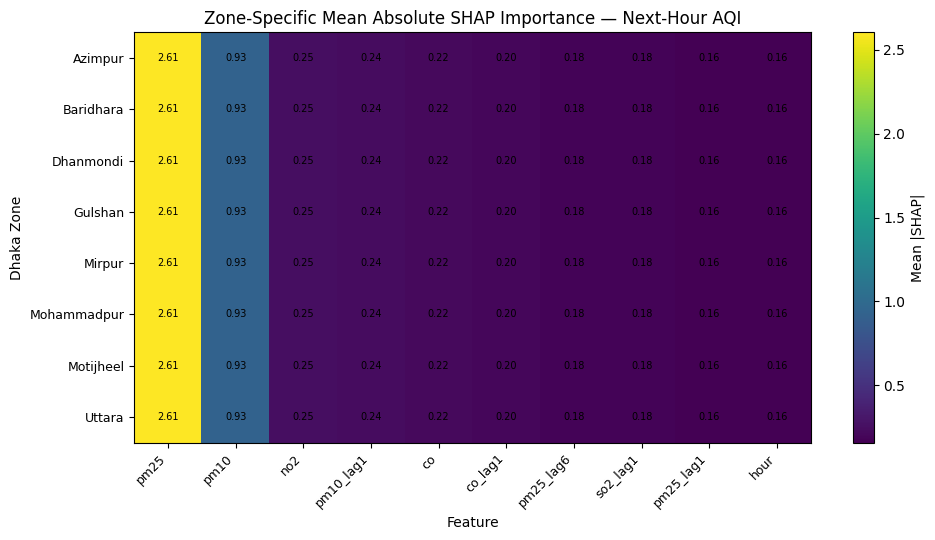


PNG saved: True
PDF saved: True

FIGURE 8 REGENERATED ✅


In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

OUT_DIR = "/content/drive/MyDrive/AQI_Project/results/FINAL_FIXED_PAPER_FIGURES"

CSV_PATH = os.path.join(
    OUT_DIR,
    "Figure_8_Zone_Specific_SHAP_DATA.csv"
)

PNG_PATH = os.path.join(
    OUT_DIR,
    "Figure_8_Zone_Specific_SHAP_Heatmap_600dpi.png"
)

PDF_PATH = os.path.join(
    OUT_DIR,
    "Figure_8_Zone_Specific_SHAP_Heatmap.pdf"
)

# Load already-saved heatmap data
heatmap_df = pd.read_csv(
    CSV_PATH,
    index_col=0
)

print("Heatmap shape:", heatmap_df.shape)
print(heatmap_df.round(3))

# -----------------------------
# Generate Fig. 8
# -----------------------------

fig, ax = plt.subplots(
    figsize=(10, 5.5)
)

im = ax.imshow(
    heatmap_df.values,
    aspect="auto"
)

ax.set_xticks(
    np.arange(len(heatmap_df.columns))
)

ax.set_xticklabels(
    heatmap_df.columns,
    rotation=45,
    ha="right",
    fontsize=9
)

ax.set_yticks(
    np.arange(len(heatmap_df.index))
)

ax.set_yticklabels(
    heatmap_df.index,
    fontsize=9
)

ax.set_xlabel("Feature")
ax.set_ylabel("Dhaka Zone")

ax.set_title(
    "Zone-Specific Mean Absolute SHAP Importance — Next-Hour AQI"
)

# Write values inside cells
for i in range(heatmap_df.shape[0]):
    for j in range(heatmap_df.shape[1]):

        ax.text(
            j,
            i,
            f"{heatmap_df.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=7
        )

cbar = fig.colorbar(
    im,
    ax=ax
)

cbar.set_label("Mean |SHAP|")

plt.tight_layout()

# Save
plt.savefig(
    PNG_PATH,
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    PDF_PATH,
    bbox_inches="tight"
)

plt.show()

print("\nPNG saved:", os.path.exists(PNG_PATH))
print("PDF saved:", os.path.exists(PDF_PATH))
print("\nFIGURE 8 REGENERATED ✅")

CSV exists: True

Zone SHAP shape: (8, 20)

Zones:
['Azimpur', 'Baridhara', 'Dhanmondi', 'Gulshan', 'Mirpur', 'Mohammadpur', 'Motijheel', 'Uttara']

Total features:
20


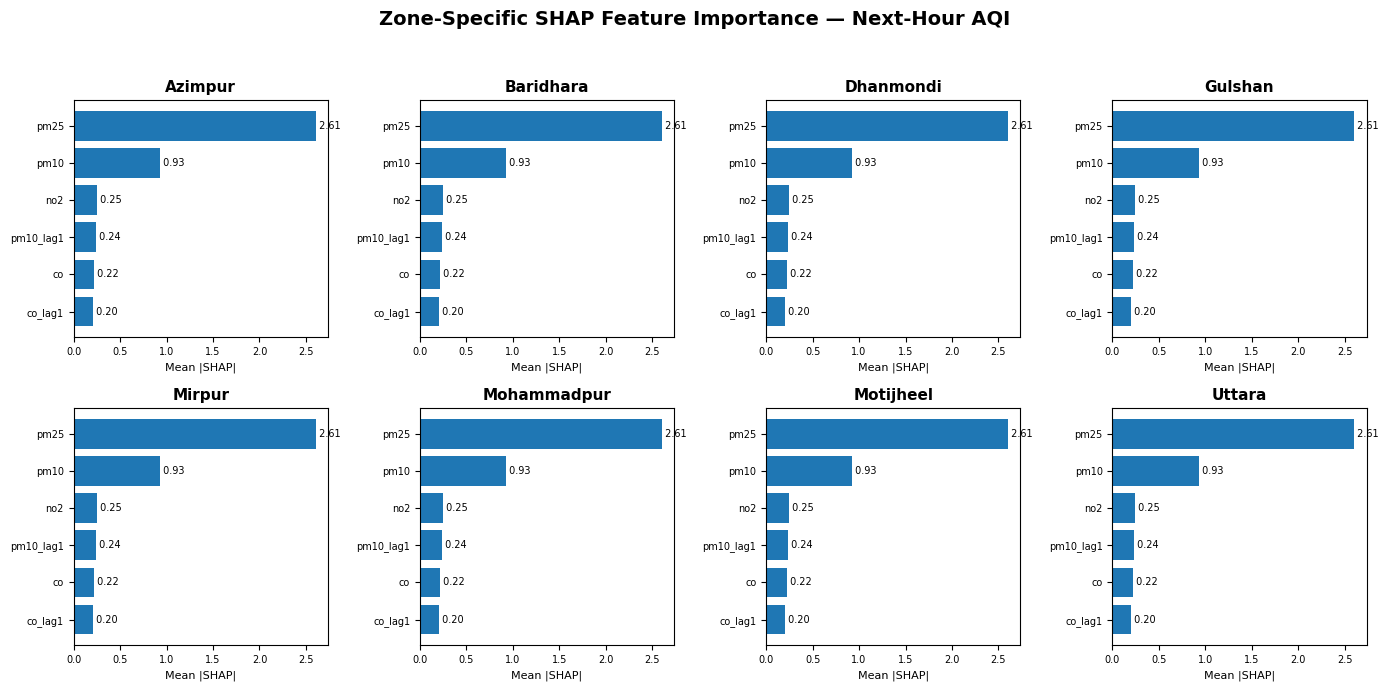


ZONE-SPECIFIC FIGURE 8 SAVED
PNG: True /content/drive/MyDrive/AQI_Project/results/FINAL_FIXED_PAPER_FIGURES/Figure_8_Zone_Specific_SHAP_MultiPanel_600dpi.png
PDF: True /content/drive/MyDrive/AQI_Project/results/FINAL_FIXED_PAPER_FIGURES/Figure_8_Zone_Specific_SHAP_MultiPanel.pdf


In [ ]:
# ============================================================
# FIGURE 8 — ZONE-SPECIFIC SHAP MULTI-PANEL BAR PLOT
# Uses already saved zone-wise SHAP CSV
# NO SHAP RECALCULATION
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------

OUT_DIR = (
    "/content/drive/MyDrive/AQI_Project/"
    "results/FINAL_FIXED_PAPER_FIGURES"
)

CSV_PATH = os.path.join(
    OUT_DIR,
    "Zone_Specific_SHAP_All_20_Features.csv"
)

PNG_PATH = os.path.join(
    OUT_DIR,
    "Figure_8_Zone_Specific_SHAP_MultiPanel_600dpi.png"
)

PDF_PATH = os.path.join(
    OUT_DIR,
    "Figure_8_Zone_Specific_SHAP_MultiPanel.pdf"
)

print("CSV exists:", os.path.exists(CSV_PATH))

assert os.path.exists(CSV_PATH), \
    "Zone SHAP CSV not found."


# ------------------------------------------------------------
# 2. Load full zone × feature SHAP data
# ------------------------------------------------------------

zone_shap = pd.read_csv(
    CSV_PATH,
    index_col=0
)

print("\nZone SHAP shape:", zone_shap.shape)

print("\nZones:")
print(zone_shap.index.tolist())

print("\nTotal features:")
print(len(zone_shap.columns))


# ------------------------------------------------------------
# 3. Settings
# ------------------------------------------------------------

TOP_N = 6

zones = zone_shap.index.tolist()

assert len(zones) == 8, \
    f"Expected 8 zones, found {len(zones)}"


# ------------------------------------------------------------
# 4. Create 8-zone multi-panel figure
# 2 rows × 4 columns
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    4,
    figsize=(14, 7)
)

axes = axes.flatten()

for ax, zone in zip(axes, zones):

    # Select top features separately for THIS zone
    zone_values = (
        zone_shap.loc[zone]
        .sort_values(
            ascending=False
        )
        .head(TOP_N)
        .sort_values(
            ascending=True
        )
    )

    ax.barh(
        zone_values.index,
        zone_values.values
    )

    ax.set_title(
        zone,
        fontsize=11,
        fontweight="bold"
    )

    ax.set_xlabel(
        "Mean |SHAP|",
        fontsize=8
    )

    ax.tick_params(
        axis="both",
        labelsize=7
    )

    # Add numerical SHAP value
    for i, value in enumerate(
        zone_values.values
    ):
        ax.text(
            value,
            i,
            f" {value:.2f}",
            va="center",
            fontsize=7
        )


# ------------------------------------------------------------
# 5. Overall title
# ------------------------------------------------------------

fig.suptitle(
    "Zone-Specific SHAP Feature Importance — Next-Hour AQI",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout(
    rect=[0, 0, 1, 0.95]
)


# ------------------------------------------------------------
# 6. Save PNG + PDF
# ------------------------------------------------------------

plt.savefig(
    PNG_PATH,
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    PDF_PATH,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 7. Verify
# ------------------------------------------------------------

print("\n==============================================")
print("ZONE-SPECIFIC FIGURE 8 SAVED")
print("==============================================")

print(
    "PNG:",
    os.path.exists(PNG_PATH),
    PNG_PATH
)

print(
    "PDF:",
    os.path.exists(PDF_PATH),
    PDF_PATH
)

In [ ]:
# ============================================================
# CHECK WHETHER ZONE-SPECIFIC SHAP REALLY DIFFERS
# ============================================================

import numpy as np
import pandas as pd

FULL_CSV_PATH = (
    "/content/drive/MyDrive/AQI_Project/"
    "results/FINAL_FIXED_PAPER_FIGURES/"
    "Zone_Specific_SHAP_All_20_Features.csv"
)

zone_shap_check = pd.read_csv(
    FULL_CSV_PATH,
    index_col=0
)

print("Shape:", zone_shap_check.shape)
print("\nZones:")
print(zone_shap_check.index.tolist())

# Maximum difference across zones for every feature
feature_range = (
    zone_shap_check.max(axis=0)
    - zone_shap_check.min(axis=0)
).sort_values(ascending=False)

print("\n===== ZONE DIFFERENCE CHECK =====")
print(feature_range)

print(
    "\nLargest difference across zones:",
    feature_range.max()
)

# Check whether complete rows are duplicates
print("\nDuplicate zone-SHAP rows:")
print(
    zone_shap_check.duplicated(
        keep=False
    )
)

print(
    "\nNumber of unique SHAP profiles:",
    len(zone_shap_check.drop_duplicates())
)

Shape: (8, 20)

Zones:
['Azimpur', 'Baridhara', 'Dhanmondi', 'Gulshan', 'Mirpur', 'Mohammadpur', 'Motijheel', 'Uttara']

===== ZONE DIFFERENCE CHECK =====
pm25                 0.0
pm10                 0.0
pm25_lag1            0.0
hour                 0.0
co_lag3              0.0
pm10_lag1            0.0
co_lag2              0.0
is_peak_hour         0.0
so2_lag1             0.0
o3_lag3              0.0
no2                  0.0
co_lag1              0.0
o3                   0.0
co                   0.0
hour_season          0.0
no                   0.0
pm25_lag6            0.0
pm10_lag6            0.0
pm25_roll_mean_3h    0.0
season               0.0
dtype: float64

Largest difference across zones: 0.0

Duplicate zone-SHAP rows:
Azimpur        True
Baridhara      True
Dhanmondi      True
Gulshan        True
Mirpur         True
Mohammadpur    True
Motijheel      True
Uttara         True
dtype: bool

Number of unique SHAP profiles: 1


In [ ]:
# ============================================================
# DIAGNOSE WHY ALL ZONES HAVE IDENTICAL SHAP
# No model training / no SHAP recalculation
# ============================================================

import numpy as np
import pandas as pd

print("=" * 65)
print("ZONE-SPECIFIC INPUT DIAGNOSTIC")
print("=" * 65)

# ------------------------------------------------------------
# 1. Is zone information actually used by the XGBoost model?
# ------------------------------------------------------------

print("\n1) ZONE VARIABLES IN MODEL FEATURES")

print(
    "zone in FEATURES        :",
    "zone" in FEATURES
)

print(
    "zone_encoded in FEATURES:",
    "zone_encoded" in FEATURES
)

print("\nModel features:")
print(FEATURES)


# ------------------------------------------------------------
# 2. Check exact uniqueness of model inputs at each timestamp
# ------------------------------------------------------------

check_df = test_df[
    ["timestamp", "zone"] + FEATURES
].copy()

# Create row signature using ONLY the 20 model features
check_df["feature_signature"] = pd.util.hash_pandas_object(
    check_df[FEATURES],
    index=False
).astype(str)

unique_profiles_per_time = (
    check_df
    .groupby("timestamp")["feature_signature"]
    .nunique()
)

print("\n2) UNIQUE MODEL-INPUT PROFILES PER TIMESTAMP")

print(
    unique_profiles_per_time
    .value_counts()
    .sort_index()
)

print(
    "\nMean unique profiles per timestamp:",
    unique_profiles_per_time.mean()
)

print(
    "Maximum unique profiles at a timestamp:",
    unique_profiles_per_time.max()
)


# ------------------------------------------------------------
# 3. Direct feature variation across zones
# ------------------------------------------------------------

numeric_features = [
    c for c in FEATURES
    if pd.api.types.is_numeric_dtype(test_df[c])
]

zone_spread_rows = []

for feature in numeric_features:

    # At each timestamp:
    # max across zones - min across zones
    spread = (
        test_df
        .groupby("timestamp")[feature]
        .agg(lambda x: x.max() - x.min())
    )

    zone_spread_rows.append({
        "Feature": feature,
        "Mean_Zone_Spread": spread.mean(),
        "Max_Zone_Spread": spread.max(),
        "Nonzero_Timestamps_%":
            (spread > 0).mean() * 100
    })

spread_df = pd.DataFrame(
    zone_spread_rows
).sort_values(
    "Max_Zone_Spread",
    ascending=False
)

print("\n3) FEATURE DIFFERENCES ACROSS ZONES")
print(
    spread_df
    .round(6)
    .to_string(index=False)
)


# ------------------------------------------------------------
# 4. Check a few timestamps manually
# ------------------------------------------------------------

counts = (
    test_df
    .groupby("timestamp")["zone"]
    .nunique()
)

full_zone_times = counts[
    counts == 8
].index[:3]

print("\n4) EXAMPLE TIMESTAMPS — FIRST 5 MODEL FEATURES")

cols_show = [
    "timestamp",
    "zone"
] + FEATURES[:5]

print(
    test_df[
        test_df["timestamp"].isin(full_zone_times)
    ][cols_show]
    .sort_values(["timestamp", "zone"])
    .to_string(index=False)
)


# ------------------------------------------------------------
# 5. Final automatic diagnosis
# ------------------------------------------------------------

if unique_profiles_per_time.max() == 1:

    print("\n" + "=" * 65)
    print("DIAGNOSIS")
    print("=" * 65)

    print(
        "All zones have identical 20-feature model inputs "
        "at each timestamp."
    )

    print(
        "Therefore identical zone-wise SHAP profiles are expected."
    )

else:

    print("\n" + "=" * 65)
    print("DIAGNOSIS")
    print("=" * 65)

    print(
        "Model inputs differ between zones."
    )

    print(
        "Therefore the previous identical SHAP aggregation "
        "needs to be recalculated differently."
    )

ZONE-SPECIFIC INPUT DIAGNOSTIC

1) ZONE VARIABLES IN MODEL FEATURES
zone in FEATURES        : False
zone_encoded in FEATURES: False

Model features:
['pm25', 'pm10', 'pm25_lag1', 'hour', 'co_lag3', 'pm10_lag1', 'co_lag2', 'is_peak_hour', 'so2_lag1', 'o3_lag3', 'no2', 'co_lag1', 'o3', 'co', 'hour_season', 'no', 'pm25_lag6', 'pm10_lag6', 'pm25_roll_mean_3h', 'season']

2) UNIQUE MODEL-INPUT PROFILES PER TIMESTAMP
feature_signature
1    4325
Name: count, dtype: int64

Mean unique profiles per timestamp: 1.0
Maximum unique profiles at a timestamp: 1

3) FEATURE DIFFERENCES ACROSS ZONES
          Feature  Mean_Zone_Spread  Max_Zone_Spread  Nonzero_Timestamps_%
             pm25               0.0              0.0                   0.0
             pm10               0.0              0.0                   0.0
        pm25_lag1               0.0              0.0                   0.0
             hour               0.0              0.0                   0.0
          co_lag3               0.0 

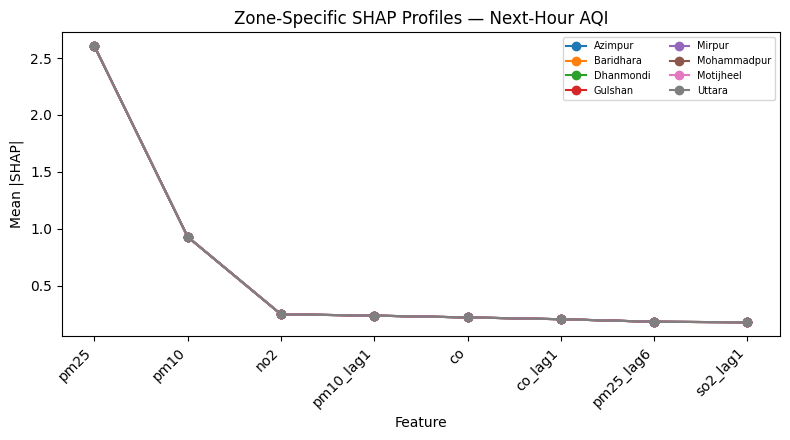

PNG: True
PDF: True


In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt

OUT_DIR = (
    "/content/drive/MyDrive/AQI_Project/"
    "results/FINAL_FIXED_PAPER_FIGURES"
)

CSV_PATH = os.path.join(
    OUT_DIR,
    "Zone_Specific_SHAP_All_20_Features.csv"
)

zone_shap = pd.read_csv(
    CSV_PATH,
    index_col=0
)

# Top 8 globally important features
top_features = (
    zone_shap.mean(axis=0)
    .sort_values(ascending=False)
    .head(8)
    .index
    .tolist()
)

plot_df = zone_shap[top_features]

plt.figure(figsize=(8, 4.5))

for zone in plot_df.index:
    plt.plot(
        top_features,
        plot_df.loc[zone].values,
        marker="o",
        label=zone
    )

plt.xlabel("Feature")
plt.ylabel("Mean |SHAP|")
plt.title("Zone-Specific SHAP Profiles — Next-Hour AQI")

plt.xticks(
    rotation=45,
    ha="right"
)

plt.legend(
    fontsize=7,
    ncol=2
)

plt.tight_layout()

PNG_PATH = os.path.join(
    OUT_DIR,
    "Figure_8_Zone_Specific_SHAP_Profiles_600dpi.png"
)

PDF_PATH = os.path.join(
    OUT_DIR,
    "Figure_8_Zone_Specific_SHAP_Profiles.pdf"
)

plt.savefig(
    PNG_PATH,
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    PDF_PATH,
    bbox_inches="tight"
)

plt.show()

print("PNG:", os.path.exists(PNG_PATH))
print("PDF:", os.path.exists(PDF_PATH))

Shape: (8, 20)
Zones: ['Azimpur', 'Baridhara', 'Dhanmondi', 'Gulshan', 'Mirpur', 'Mohammadpur', 'Motijheel', 'Uttara']

Top features:
['pm25', 'pm10', 'no2', 'pm10_lag1', 'co', 'co_lag1']


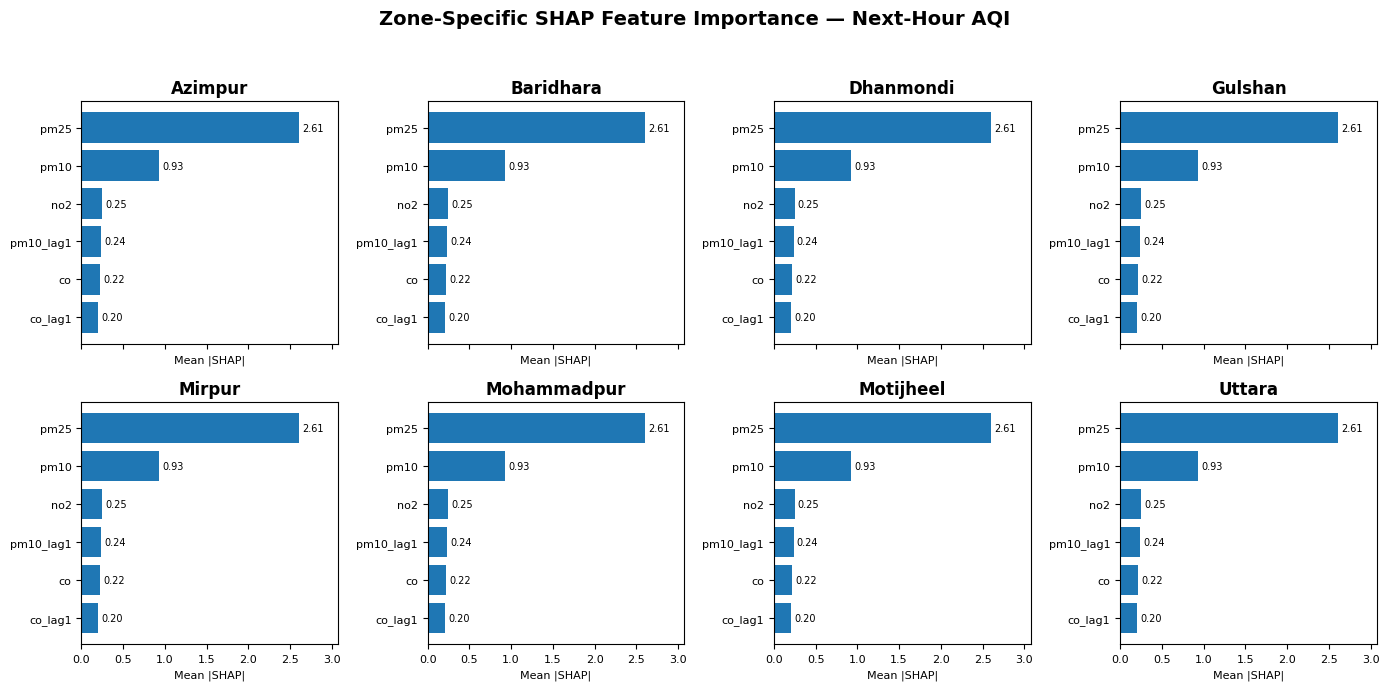


FINAL FIGURE 8 SAVED
PNG: True
PDF: True


In [ ]:
# ============================================================
# FINAL FIGURE 8
# 8 SEPARATE ZONE-SPECIFIC SHAP PANELS
# Uses already saved SHAP CSV
# ============================================================

import os
import pandas as pd
import matplotlib.pyplot as plt

OUT_DIR = (
    "/content/drive/MyDrive/AQI_Project/"
    "results/FINAL_FIXED_PAPER_FIGURES"
)

CSV_PATH = os.path.join(
    OUT_DIR,
    "Zone_Specific_SHAP_All_20_Features.csv"
)

PNG_PATH = os.path.join(
    OUT_DIR,
    "Figure_8_Final_Zone_Specific_SHAP_600dpi.png"
)

PDF_PATH = os.path.join(
    OUT_DIR,
    "Figure_8_Final_Zone_Specific_SHAP.pdf"
)

# ------------------------------------------------------------
# Load saved zone-wise SHAP
# ------------------------------------------------------------

zone_shap = pd.read_csv(
    CSV_PATH,
    index_col=0
)

print("Shape:", zone_shap.shape)
print("Zones:", zone_shap.index.tolist())

# ------------------------------------------------------------
# Select common top 6 features
# ------------------------------------------------------------

TOP_N = 6

top_features = (
    zone_shap
    .mean(axis=0)
    .sort_values(ascending=False)
    .head(TOP_N)
    .index
    .tolist()
)

print("\nTop features:")
print(top_features)

# Same x-axis scale for fair comparison
max_value = (
    zone_shap[top_features]
    .values
    .max()
)

# ------------------------------------------------------------
# Create 2 x 4 panels
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    4,
    figsize=(14, 7),
    sharex=True
)

axes = axes.flatten()

for ax, zone in zip(
    axes,
    zone_shap.index
):

    values = (
        zone_shap
        .loc[zone, top_features]
        .sort_values(ascending=True)
    )

    ax.barh(
        values.index,
        values.values
    )

    # Zone name clearly visible
    ax.set_title(
        zone,
        fontsize=12,
        fontweight="bold"
    )

    ax.set_xlim(
        0,
        max_value * 1.18
    )

    ax.set_xlabel(
        "Mean |SHAP|",
        fontsize=8
    )

    ax.tick_params(
        axis="both",
        labelsize=8
    )

    # Add exact values
    for i, value in enumerate(
        values.values
    ):
        ax.text(
            value + max_value * 0.015,
            i,
            f"{value:.2f}",
            va="center",
            fontsize=7
        )

fig.suptitle(
    "Zone-Specific SHAP Feature Importance — Next-Hour AQI",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout(
    rect=[0, 0, 1, 0.95]
)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

plt.savefig(
    PNG_PATH,
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    PDF_PATH,
    bbox_inches="tight"
)

plt.show()

print("\n==============================")
print("FINAL FIGURE 8 SAVED")
print("==============================")

print(
    "PNG:",
    os.path.exists(PNG_PATH)
)

print(
    "PDF:",
    os.path.exists(PDF_PATH)
)

In [ ]:
# ============================================================
# FINAL REVIEWER-FIX CHECKPOINT SAVE
# Saves current progress, Error-5 diagnostics and resume notes
# ============================================================

import os
import json
import joblib
import pandas as pd
import numpy as np

BASE_DIR = "/content/drive/MyDrive/AQI_Project"
CHECKPOINT_DIR = os.path.join(BASE_DIR, "checkpoints")
RESULT_DIR = os.path.join(BASE_DIR, "results")

os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)

# ------------------------------------------------------------
# 1. Save exact 20 next-hour model features
# ------------------------------------------------------------

FINAL_20_FEATURES = [
    'pm25',
    'pm10',
    'pm25_lag1',
    'hour',
    'co_lag3',
    'pm10_lag1',
    'co_lag2',
    'is_peak_hour',
    'so2_lag1',
    'o3_lag3',
    'no2',
    'co_lag1',
    'o3',
    'co',
    'hour_season',
    'no',
    'pm25_lag6',
    'pm10_lag6',
    'pm25_roll_mean_3h',
    'season'
]

joblib.dump(
    FINAL_20_FEATURES,
    os.path.join(
        CHECKPOINT_DIR,
        "FINAL_next_hour_20_features_verified.pkl"
    )
)

# ------------------------------------------------------------
# 2. Save Error-5 diagnostic summary
# ------------------------------------------------------------

error5_diagnostic = {
    "zone_in_features": False,
    "zone_encoded_in_features": False,
    "number_of_model_features": 20,
    "unique_model_profiles_per_timestamp": 1,
    "maximum_unique_profiles_per_timestamp": 1,
    "largest_feature_difference_across_zones": 0.0,
    "unique_zone_SHAP_profiles": 1,
    "interpretation":
        "All eight zones have identical selected model inputs "
        "at each timestamp. Therefore differentiated zone-specific "
        "SHAP attribution cannot be obtained from the current model."
}

with open(
    os.path.join(
        CHECKPOINT_DIR,
        "REVIEWER5_zone_SHAP_diagnostic.json"
    ),
    "w"
) as f:
    json.dump(
        error5_diagnostic,
        f,
        indent=4
    )

# ------------------------------------------------------------
# 3. Save current zone-SHAP matrix if available
# ------------------------------------------------------------

if "zone_shap_check" in globals():

    zone_shap_check.to_csv(
        os.path.join(
            RESULT_DIR,
            "REVIEWER5_verified_zone_SHAP_profiles.csv"
        )
    )

elif "zone_shap" in globals():

    zone_shap.to_csv(
        os.path.join(
            RESULT_DIR,
            "REVIEWER5_verified_zone_SHAP_profiles.csv"
        )
    )

# ------------------------------------------------------------
# 4. Save exact 81 columns again if df is loaded
# ------------------------------------------------------------

if "df" in globals():

    exact_columns = df.columns.tolist()

    pd.DataFrame({
        "No": range(1, len(exact_columns) + 1),
        "Attribute": exact_columns
    }).to_csv(
        os.path.join(
            RESULT_DIR,
            "FINAL_verified_81_attributes.csv"
        ),
        index=False
    )

    joblib.dump(
        exact_columns,
        os.path.join(
            CHECKPOINT_DIR,
            "FINAL_verified_81_attributes.pkl"
        )
    )

# ------------------------------------------------------------
# 5. Save reviewer-fix resume note
# ------------------------------------------------------------

resume_note = """
AQI PROJECT — REVIEWER FIX CHECKPOINT
====================================

PRIMARY NEXT-HOUR RESULT
AR Stacking Accuracy = 0.934798 (93.48%)
Macro-F1 = 0.927854

Persistence Accuracy = 0.944971 (94.50%)
Persistence Macro-F1 = 0.939526

ERROR 3 — TRANSITION EVALUATION
Transition observations = 1904
AR transition accuracy = 2.52%
Persistence transition accuracy = 0%
AR transition detection rate = 3.36%

ERROR 4 — UNCERTAINTY
AR Accuracy 95% CI = 92.51–94.38%
AR Daily Accuracy SD = 0.0701
Persistence Accuracy 95% CI = 93.73–95.22%
Persistence Daily Accuracy SD = 0.0601
Wilcoxon W = 40.5
p = 0.00093

ERROR 5 — IMPORTANT DIAGNOSTIC
Selected next-hour XGBoost inputs do NOT contain zone or zone_encoded.
At each timestamp all eight zones have identical 20-feature input vectors.
Largest feature spread across zones = 0.
Unique zone SHAP profiles = 1.

Therefore:
- Identical zone-wise SHAP profiles are expected.
- Do not claim differentiated zone-specific feature rankings.
- Current zone SHAP analysis can only show that profiles are identical.
- True differentiated zone-specific SHAP would require zone-varying inputs
  and/or a model incorporating spatial information.

ERROR 8
Same-hour classification is framed only as a non-forecasting baseline.
Next-hour classification is the primary forecasting task.
Next-hour PM2.5 regression is auxiliary.

ERROR 10
Dataset verified as:
236216 rows × 81 columns.

ERROR 12
CPU final fitting time = 8.073 minutes using cached OOF predictions.
Inference:
Batch 1 median = 371.21 ms
Batch 1 P95 = 401.46 ms
Batch 1024 median = 865.71 ms
Batch 1024 P95 = 1299.05 ms
Throughput = 1182.84 rows/s

IMPORTANT:
No model retraining is required to restore these verified results.
"""

RESUME_PATH = os.path.join(
    RESULT_DIR,
    "FINAL_REVIEWER_FIX_CHECKPOINT.txt"
)

with open(
    RESUME_PATH,
    "w"
) as f:
    f.write(resume_note)

# ------------------------------------------------------------
# 6. Final verification
# ------------------------------------------------------------

check_files = [
    os.path.join(
        CHECKPOINT_DIR,
        "FINAL_next_hour_20_features_verified.pkl"
    ),
    os.path.join(
        CHECKPOINT_DIR,
        "REVIEWER5_zone_SHAP_diagnostic.json"
    ),
    RESUME_PATH
]

if "df" in globals():
    check_files += [
        os.path.join(
            RESULT_DIR,
            "FINAL_verified_81_attributes.csv"
        ),
        os.path.join(
            CHECKPOINT_DIR,
            "FINAL_verified_81_attributes.pkl"
        )
    ]

print("=" * 60)
print("FINAL REVIEWER CHECKPOINT SAVED ✅")
print("=" * 60)

for path in check_files:
    print(
        os.path.basename(path),
        "→",
        os.path.exists(path)
    )

print("\n20 model features saved:", len(FINAL_20_FEATURES))

if "df" in globals():
    print("Dataset shape:", df.shape)

print("\nYou can safely disconnect Colab after all files show True ✅")

FINAL REVIEWER CHECKPOINT SAVED ✅
FINAL_next_hour_20_features_verified.pkl → True
REVIEWER5_zone_SHAP_diagnostic.json → True
FINAL_REVIEWER_FIX_CHECKPOINT.txt → True
FINAL_verified_81_attributes.csv → True
FINAL_verified_81_attributes.pkl → True

20 model features saved: 20
Dataset shape: (236216, 81)

You can safely disconnect Colab after all files show True ✅


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os
import json
import joblib
import numpy as np
import pandas as pd

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import BaggingRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

PROJECT_DIR = "/content/drive/MyDrive/AQI_Project"

DATA_PATH = os.path.join(
    PROJECT_DIR,
    "dhaka_aqi_final_featured.csv"
)

RESULT_DIR = os.path.join(PROJECT_DIR, "results")
MODEL_DIR = os.path.join(PROJECT_DIR, "models")
CHECKPOINT_DIR = os.path.join(PROJECT_DIR, "checkpoints")

os.makedirs(RESULT_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

print("Dataset exists:", os.path.exists(DATA_PATH))
print("Project:", PROJECT_DIR)

Dataset exists: True
Project: /content/drive/MyDrive/AQI_Project


In [3]:
df = pd.read_csv(DATA_PATH)

print("Original shape:", df.shape)

df["timestamp"] = pd.to_datetime(
    df["timestamp"],
    errors="coerce"
)

print("Invalid timestamps:", df["timestamp"].isna().sum())

duplicate_count = df.duplicated(
    ["timestamp", "zone"]
).sum()

print("Duplicate timestamp-zone rows:", duplicate_count)

assert duplicate_count == 0, (
    "Duplicate timestamp-zone rows found. Stop here."
)

# -------------------------------------------------
# Exact +1 hour PM2.5 target
# -------------------------------------------------

reg_df = df.copy()

future_pm25 = reg_df[
    ["zone", "timestamp", "pm25"]
].copy()

future_pm25["timestamp"] = (
    future_pm25["timestamp"]
    - pd.Timedelta(hours=1)
)

future_pm25 = future_pm25.rename(
    columns={"pm25": "pm25_next_hour"}
)

reg_df = reg_df.merge(
    future_pm25,
    on=["zone", "timestamp"],
    how="left",
    validate="one_to_one"
)

reg_df = (
    reg_df[
        reg_df["pm25_next_hour"].notna()
    ]
    .copy()
    .sort_values(["timestamp", "zone"])
    .reset_index(drop=True)
)

print("Regression rows:", len(reg_df))
print(
    "Regression date range:",
    reg_df["timestamp"].min(),
    "->",
    reg_df["timestamp"].max()
)

Original shape: (236216, 81)
Invalid timestamps: 0
Duplicate timestamp-zone rows: 0
Regression rows: 230640
Regression date range: 2023-01-01 12:00:00 -> 2026-06-28 23:00:00


In [4]:
# -------------------------------------------------
# Same PM10 cleaning used in original regression
# -------------------------------------------------

reg_clean = reg_df.copy()

pm10_related_cols = [
    c for c in reg_clean.columns
    if c == "pm10" or c.startswith("pm10_")
]

for c in pm10_related_cols:
    reg_clean.loc[
        reg_clean[c] < 0,
        c
    ] = np.nan


# -------------------------------------------------
# Same regression feature set
# -------------------------------------------------

REG_DROP_COLS = [
    "timestamp",
    "zone",
    "data_source",
    "target",
    "aqi_owm",
    "pm25_next_hour"
]

reg_feature_cols = [
    c for c in reg_clean.columns
    if c not in REG_DROP_COLS
]

non_numeric = (
    reg_clean[reg_feature_cols]
    .select_dtypes(exclude=["number", "bool"])
    .columns
    .tolist()
)

print("Feature count:", len(reg_feature_cols))
print("Non-numeric:", non_numeric)

assert len(non_numeric) == 0


# -------------------------------------------------
# Exact chronological 70 / 15 / 15 split
# -------------------------------------------------

unique_times = np.array(
    sorted(reg_clean["timestamp"].unique())
)

n_times = len(unique_times)

train_end = int(n_times * 0.70)
val_end = int(n_times * 0.85)

train_cutoff = unique_times[train_end]
val_cutoff = unique_times[val_end]

train_df = reg_clean[
    reg_clean["timestamp"] < train_cutoff
].copy()

val_df = reg_clean[
    (reg_clean["timestamp"] >= train_cutoff) &
    (reg_clean["timestamp"] < val_cutoff)
].copy()

test_df = reg_clean[
    reg_clean["timestamp"] >= val_cutoff
].copy()

X_train = train_df[reg_feature_cols].copy()
y_train = train_df["pm25_next_hour"].copy()

X_val = val_df[reg_feature_cols].copy()
y_val = val_df["pm25_next_hour"].copy()

X_test = test_df[reg_feature_cols].copy()
y_test = test_df["pm25_next_hour"].copy()


# -------------------------------------------------
# Train-only median imputation
# -------------------------------------------------

train_medians = X_train.median(
    numeric_only=True
)

X_train = X_train.fillna(train_medians)
X_val = X_val.fillna(train_medians)
X_test = X_test.fillna(train_medians)

print("\nTRAIN")
print(
    train_df["timestamp"].min(),
    "->",
    train_df["timestamp"].max()
)
print("Rows:", len(train_df))

print("\nVALIDATION")
print(
    val_df["timestamp"].min(),
    "->",
    val_df["timestamp"].max()
)
print("Rows:", len(val_df))

print("\nTEST")
print(
    test_df["timestamp"].min(),
    "->",
    test_df["timestamp"].max()
)
print("Rows:", len(test_df))

print("\nNaN check")
print("Train:", X_train.isna().sum().sum())
print("Validation:", X_val.isna().sum().sum())
print("Test:", X_test.isna().sum().sum())

Feature count: 76
Non-numeric: []

TRAIN
2023-01-01 12:00:00 -> 2025-06-09 22:00:00
Rows: 161448

VALIDATION
2025-06-09 23:00:00 -> 2025-12-13 02:00:00
Rows: 34592

TEST
2025-12-13 03:00:00 -> 2026-06-28 23:00:00
Rows: 34600

NaN check
Train: 0
Validation: 0
Test: 0


In [5]:
# ============================================================
# CELL 5
# REVIEWER #4 — PRIOR DHAKA RANDOM SUBSPACE REIMPLEMENTATION
# Islam et al. [8] protocol-matched baseline
# ============================================================

import time
import numpy as np
import pandas as pd

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import BaggingRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ------------------------------------------------------------
# REPTree-style shallow base learner
#
# Prior study:
# max depth = 1
# minimum number per leaf = 2
#
# NOTE:
# sklearn has no exact WEKA REPTree implementation,
# so this is a shallow-tree approximation.
# ------------------------------------------------------------

reptree_style = DecisionTreeRegressor(
    max_depth=1,
    min_samples_leaf=2,
    random_state=1
)

# ------------------------------------------------------------
# Random Subspace settings from Islam et al. [8]
#
# iterations      = 10
# feature subspace = 0.5
# random seed      = 1
#
# bootstrap=False:
# all training rows are retained; diversity comes from
# random feature subsets, matching Random Subspace concept.
# ------------------------------------------------------------

rss_prior = BaggingRegressor(
    estimator=reptree_style,
    n_estimators=10,
    max_samples=1.0,
    max_features=0.5,
    bootstrap=False,
    bootstrap_features=False,
    random_state=1,
    n_jobs=-1
)

print("=" * 70)
print("PRIOR DHAKA RANDOM SUBSPACE REIMPLEMENTATION")
print("=" * 70)

print("Training rows:", len(X_train))
print("Validation rows:", len(X_val))
print("Test rows:", len(X_test))
print("Input features:", X_train.shape[1])

# ------------------------------------------------------------
# Train ONLY on training partition
# Validation and test remain unseen
# ------------------------------------------------------------

start = time.time()

rss_prior.fit(
    X_train,
    y_train
)

fit_seconds = time.time() - start

print(f"\nTraining completed in {fit_seconds:.2f} seconds")

# ------------------------------------------------------------
# Predictions
# ------------------------------------------------------------

rss_val_pred = rss_prior.predict(X_val)
rss_test_pred = rss_prior.predict(X_test)

# ------------------------------------------------------------
# Metric helper
# ------------------------------------------------------------

def regression_result(y_true, y_pred, split_name):

    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred
        )
    )

    r2 = r2_score(
        y_true,
        y_pred
    )

    return {
        "Split": split_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }


rss_val_result = regression_result(
    y_val,
    rss_val_pred,
    "Validation"
)

rss_test_result = regression_result(
    y_test,
    rss_test_pred,
    "Test"
)

rss_results = pd.DataFrame([
    rss_val_result,
    rss_test_result
])

print("\n" + "=" * 70)
print("RANDOM SUBSPACE RESULTS")
print("=" * 70)

print(
    rss_results
    .round(4)
    .to_string(index=False)
)

# ------------------------------------------------------------
# Compare with existing final regression results
# ------------------------------------------------------------

existing_result_path = os.path.join(
    RESULT_DIR,
    "FINAL_regression_test.csv"
)

print("\n" + "=" * 70)
print("EXISTING FINAL REGRESSION RESULTS")
print("=" * 70)

if os.path.exists(existing_result_path):

    existing_regression_results = pd.read_csv(
        existing_result_path
    )

    print(
        existing_regression_results
        .round(4)
        .to_string(index=False)
    )

else:

    print("FINAL_regression_test.csv not found.")
    print("Known paper values:")
    print("Proposed stack: MAE=2.7896, RMSE=6.1076, R2=0.9900")
    print("Persistence:    MAE=3.3075, RMSE=8.2671, R2=0.9817")

print("\nPrior RSS test metrics:")
print(
    f"MAE  = {rss_test_result['MAE']:.4f}"
)
print(
    f"RMSE = {rss_test_result['RMSE']:.4f}"
)
print(
    f"R2   = {rss_test_result['R2']:.4f}"
)

PRIOR DHAKA RANDOM SUBSPACE REIMPLEMENTATION
Training rows: 161448
Validation rows: 34592
Test rows: 34600
Input features: 76

Training completed in 7.14 seconds

RANDOM SUBSPACE RESULTS
     Split     MAE    RMSE     R2
Validation 35.7995 38.2686 0.4448
      Test 30.2358 35.6102 0.6610

EXISTING FINAL REGRESSION RESULTS
                           Model    MAE   RMSE     R2
FINAL TEST - Regression Stacking 2.7896 6.1076 0.9900
           FINAL TEST - LightGBM 2.8638 6.4881 0.9887
  FINAL TEST - PM2.5 Persistence 3.3075 8.2671 0.9817

Prior RSS test metrics:
MAE  = 30.2358
RMSE = 35.6102
R2   = 0.6610


In [6]:
# ============================================================
# REVIEWER #4 + #6 CHECKPOINT SAVE
# ============================================================

import os
import json
import joblib
import pandas as pd

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

RSS_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "reviewer4_prior_random_subspace.pkl"
)

RSS_RESULT_PATH = os.path.join(
    RESULT_DIR,
    "reviewer4_prior_random_subspace_results.csv"
)

RSS_PRED_PATH = os.path.join(
    RESULT_DIR,
    "reviewer4_prior_random_subspace_test_predictions.csv"
)

SPLIT_PATH = os.path.join(
    CHECKPOINT_DIR,
    "reviewer4_6_regression_split_info.json"
)

FEATURE_PATH = os.path.join(
    CHECKPOINT_DIR,
    "reviewer4_regression_features.pkl"
)

RESUME_PATH = os.path.join(
    RESULT_DIR,
    "REVIEWER4_PRIOR_DHAKA_CHECKPOINT.txt"
)

# ------------------------------------------------------------
# 1. Save model
# ------------------------------------------------------------

joblib.dump(
    rss_prior,
    RSS_MODEL_PATH
)

# ------------------------------------------------------------
# 2. Save metrics
# ------------------------------------------------------------

rss_results.to_csv(
    RSS_RESULT_PATH,
    index=False
)

# ------------------------------------------------------------
# 3. Save test predictions
# ------------------------------------------------------------

rss_test_predictions = pd.DataFrame({
    "timestamp": test_df["timestamp"].values,
    "zone": test_df["zone"].values,
    "Actual_PM25_next_hour": y_test.values,
    "RSS_Predicted_PM25": rss_test_pred
})

rss_test_predictions.to_csv(
    RSS_PRED_PATH,
    index=False
)

# ------------------------------------------------------------
# 4. Save exact feature list
# ------------------------------------------------------------

joblib.dump(
    reg_feature_cols,
    FEATURE_PATH
)

# ------------------------------------------------------------
# 5. Save split/date information
# ------------------------------------------------------------

split_info = {
    "feature_count": len(reg_feature_cols),

    "train_start": str(train_df["timestamp"].min()),
    "train_end": str(train_df["timestamp"].max()),
    "train_rows": int(len(train_df)),

    "validation_start": str(val_df["timestamp"].min()),
    "validation_end": str(val_df["timestamp"].max()),
    "validation_rows": int(len(val_df)),

    "test_start": str(test_df["timestamp"].min()),
    "test_end": str(test_df["timestamp"].max()),
    "test_rows": int(len(test_df)),

    "prior_method": "Random Subspace-style reimplementation of Islam et al. [8]",
    "subspace_fraction": 0.5,
    "iterations": 10,
    "random_seed": 1,
    "base_learner": "DecisionTreeRegressor approximation of shallow REPTree",
    "max_depth": 1,
    "min_samples_leaf": 2,

    "test_MAE": float(rss_test_result["MAE"]),
    "test_RMSE": float(rss_test_result["RMSE"]),
    "test_R2": float(rss_test_result["R2"])
}

with open(
    SPLIT_PATH,
    "w"
) as f:
    json.dump(
        split_info,
        f,
        indent=4
    )

# ------------------------------------------------------------
# 6. Save resume/checkpoint note
# ------------------------------------------------------------

resume_note = f"""
REVIEWER #4 PRIOR DHAKA METHOD REIMPLEMENTATION
===============================================

Prior study:
Islam et al. [8]

Adapted method:
Random Subspace-style regression baseline

IMPORTANT:
This is NOT an exact reproduction of the original study.
The original study estimated current PM2.5.
Here its method was adapted to the same next-hour PM2.5
forecasting protocol used by the proposed model.

Protocol:
Feature count = {len(reg_feature_cols)}
Random subspace fraction = 0.5
Iterations = 10
Seed = 1
Shallow REPTree-style approximation:
max_depth = 1
min_samples_leaf = 2

TRAIN
{train_df["timestamp"].min()} -> {train_df["timestamp"].max()}
Rows = {len(train_df)}

VALIDATION
{val_df["timestamp"].min()} -> {val_df["timestamp"].max()}
Rows = {len(val_df)}

TEST
{test_df["timestamp"].min()} -> {test_df["timestamp"].max()}
Rows = {len(test_df)}

PRIOR RANDOM SUBSPACE TEST
MAE = {rss_test_result["MAE"]:.4f}
RMSE = {rss_test_result["RMSE"]:.4f}
R2 = {rss_test_result["R2"]:.4f}

PROPOSED STACK
MAE = 2.7896
RMSE = 6.1076
R2 = 0.9900

PERSISTENCE
MAE = 3.3075
RMSE = 8.2671
R2 = 0.9817
"""

with open(
    RESUME_PATH,
    "w"
) as f:
    f.write(resume_note)

# ------------------------------------------------------------
# 7. Verification
# ------------------------------------------------------------

check_files = [
    RSS_MODEL_PATH,
    RSS_RESULT_PATH,
    RSS_PRED_PATH,
    SPLIT_PATH,
    FEATURE_PATH,
    RESUME_PATH
]

print("=" * 65)
print("REVIEWER #4 / #6 CHECKPOINT SAVED")
print("=" * 65)

for p in check_files:
    print(
        os.path.basename(p),
        "->",
        os.path.exists(p)
    )

REVIEWER #4 / #6 CHECKPOINT SAVED
reviewer4_prior_random_subspace.pkl -> True
reviewer4_prior_random_subspace_results.csv -> True
reviewer4_prior_random_subspace_test_predictions.csv -> True
reviewer4_6_regression_split_info.json -> True
reviewer4_regression_features.pkl -> True
REVIEWER4_PRIOR_DHAKA_CHECKPOINT.txt -> True


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os
import numpy as np
import pandas as pd

from scipy.spatial.distance import jensenshannon

PROJECT_DIR = "/content/drive/MyDrive/AQI_Project"

DATA_PATH = os.path.join(
    PROJECT_DIR,
    "dhaka_aqi_final_featured.csv"
)

CHECKPOINT_DIR = os.path.join(
    PROJECT_DIR,
    "checkpoints"
)

RESULT_DIR = os.path.join(
    PROJECT_DIR,
    "results"
)

os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)

print("Dataset exists:", os.path.exists(DATA_PATH))
print("Project:", PROJECT_DIR)

Dataset exists: True
Project: /content/drive/MyDrive/AQI_Project


In [3]:
df = pd.read_csv(DATA_PATH)

df["timestamp"] = pd.to_datetime(
    df["timestamp"],
    errors="coerce"
)

print("Dataset shape:", df.shape)
print("Invalid timestamps:", df["timestamp"].isna().sum())
print("Target exists:", "target" in df.columns)

Dataset shape: (236216, 81)
Invalid timestamps: 0
Target exists: True


In [4]:
same_df = (
    df
    .dropna(subset=["timestamp", "target"])
    .copy()
    .sort_values(["timestamp", "zone"])
    .reset_index(drop=True)
)

unique_times = np.array(
    sorted(same_df["timestamp"].unique())
)

n_times = len(unique_times)

train_end = int(n_times * 0.70)
val_end = int(n_times * 0.85)

train_cutoff = unique_times[train_end]
val_cutoff = unique_times[val_end]

same_train = same_df[
    same_df["timestamp"] < train_cutoff
].copy()

same_val = same_df[
    (same_df["timestamp"] >= train_cutoff) &
    (same_df["timestamp"] < val_cutoff)
].copy()

same_test = same_df[
    same_df["timestamp"] >= val_cutoff
].copy()

print("TRAIN")
print(
    same_train["timestamp"].min(),
    "->",
    same_train["timestamp"].max()
)
print("Rows:", len(same_train))

print("\nVALIDATION")
print(
    same_val["timestamp"].min(),
    "->",
    same_val["timestamp"].max()
)
print("Rows:", len(same_val))

print("\nTEST")
print(
    same_test["timestamp"].min(),
    "->",
    same_test["timestamp"].max()
)
print("Rows:", len(same_test))

TRAIN
2023-01-01 12:00:00 -> 2025-06-29 10:00:00
Rows: 165344

VALIDATION
2025-06-29 11:00:00 -> 2026-01-06 17:00:00
Rows: 35432

TEST
2026-01-06 18:00:00 -> 2026-08-18 01:16:59
Rows: 35440


In [5]:
classes = [0, 1, 2, 3, 4]

def class_pct(data):
    return (
        data["target"]
        .value_counts(normalize=True)
        .reindex(classes, fill_value=0)
        * 100
    )

train_pct = class_pct(same_train)
val_pct = class_pct(same_val)
test_pct = class_pct(same_test)

dist_table = pd.DataFrame({
    "Class": classes,
    "Train_%": train_pct.values,
    "Validation_%": val_pct.values,
    "Test_%": test_pct.values
})

dist_table["Val_to_Test_Change_pp"] = (
    dist_table["Test_%"] -
    dist_table["Validation_%"]
)

print("=" * 72)
print("SAME-HOUR CLASS DISTRIBUTION (%)")
print("=" * 72)

print(
    dist_table
    .round(2)
    .to_string(index=False)
)

SAME-HOUR CLASS DISTRIBUTION (%)
 Class  Train_%  Validation_%  Test_%  Val_to_Test_Change_pp
     0    15.30         39.87   24.24                 -15.63
     1    20.54         18.33   30.77                  12.43
     2     8.85          4.92   13.59                   8.67
     3    32.54         27.52   23.77                  -3.75
     4    22.75          9.35    7.63                  -1.72


In [6]:
p_train = train_pct.values / 100
p_val = val_pct.values / 100
p_test = test_pct.values / 100

js_train_val = jensenshannon(
    p_train,
    p_val
) ** 2

js_val_test = jensenshannon(
    p_val,
    p_test
) ** 2

js_train_test = jensenshannon(
    p_train,
    p_test
) ** 2

print("=" * 72)
print("JENSEN-SHANNON DIVERGENCE")
print("=" * 72)

print(f"Train vs Validation : {js_train_val:.4f}")
print(f"Validation vs Test  : {js_val_test:.4f}")
print(f"Train vs Test       : {js_train_test:.4f}")

largest_idx = (
    dist_table["Val_to_Test_Change_pp"]
    .abs()
    .idxmax()
)

largest_row = dist_table.loc[largest_idx]

print("\nLargest Validation -> Test shift:")

print(
    f"Class {int(largest_row['Class'])}: "
    f"{largest_row['Validation_%']:.2f}% -> "
    f"{largest_row['Test_%']:.2f}% "
    f"({largest_row['Val_to_Test_Change_pp']:+.2f} pp)"
)

JENSEN-SHANNON DIVERGENCE
Train vs Validation : 0.0470
Validation vs Test  : 0.0293
Train vs Test       : 0.0359

Largest Validation -> Test shift:
Class 0: 39.87% -> 24.24% (-15.63 pp)


In [7]:
stack_val_acc = 0.9596
stack_test_acc = 0.8134

soft_vote_test = 0.9503
lgbm_test = 0.9476
xgb_test = 0.9094

drop_pp = (
    stack_val_acc -
    stack_test_acc
) * 100

print("=" * 72)
print("SAME-HOUR GENERALIZATION SUMMARY")
print("=" * 72)

print(
    f"Four-model stacking validation accuracy = "
    f"{stack_val_acc:.4f}"
)

print(
    f"Four-model stacking test accuracy       = "
    f"{stack_test_acc:.4f}"
)

print(
    f"Validation -> Test drop                 = "
    f"{drop_pp:.2f} percentage points"
)

print("\nTest accuracies:")
print(f"Soft-voting XGB+LGBM = {soft_vote_test:.4f}")
print(f"LightGBM             = {lgbm_test:.4f}")
print(f"XGBoost              = {xgb_test:.4f}")

SAME-HOUR GENERALIZATION SUMMARY
Four-model stacking validation accuracy = 0.9596
Four-model stacking test accuracy       = 0.8134
Validation -> Test drop                 = 14.62 percentage points

Test accuracies:
Soft-voting XGB+LGBM = 0.9503
LightGBM             = 0.9476
XGBoost              = 0.9094


In [8]:
import json

DIST_PATH = os.path.join(
    RESULT_DIR,
    "reviewer8_same_hour_distribution.csv"
)

SUMMARY_PATH = os.path.join(
    CHECKPOINT_DIR,
    "reviewer8_same_hour_failure_analysis.json"
)

RESUME_PATH = os.path.join(
    RESULT_DIR,
    "REVIEWER8_SAME_HOUR_FAILURE_CHECKPOINT.txt"
)

dist_table.to_csv(
    DIST_PATH,
    index=False
)

summary = {
    "train_rows": int(len(same_train)),
    "validation_rows": int(len(same_val)),
    "test_rows": int(len(same_test)),

    "train_start": str(same_train["timestamp"].min()),
    "train_end": str(same_train["timestamp"].max()),

    "validation_start": str(same_val["timestamp"].min()),
    "validation_end": str(same_val["timestamp"].max()),

    "test_start": str(same_test["timestamp"].min()),
    "test_end": str(same_test["timestamp"].max()),

    "js_train_validation": float(js_train_val),
    "js_validation_test": float(js_val_test),
    "js_train_test": float(js_train_test),

    "largest_shift_class": int(largest_row["Class"]),
    "largest_shift_pp": float(
        largest_row["Val_to_Test_Change_pp"]
    ),

    "stacking_validation_accuracy": 0.9596,
    "stacking_test_accuracy": 0.8134,
    "stacking_drop_pp": float(drop_pp),

    "soft_vote_test_accuracy": 0.9503,
    "lgbm_test_accuracy": 0.9476,
    "xgb_test_accuracy": 0.9094
}

with open(
    SUMMARY_PATH,
    "w"
) as f:
    json.dump(
        summary,
        f,
        indent=4
    )

resume_text = f"""
REVIEWER #8 SAME-HOUR STACKING FAILURE ANALYSIS
===============================================

Four-model stacking:
Validation accuracy = 0.9596
Test accuracy = 0.8134
Drop = {drop_pp:.2f} percentage points

Jensen-Shannon divergence:
Train vs Validation = {js_train_val:.4f}
Validation vs Test = {js_val_test:.4f}
Train vs Test = {js_train_test:.4f}

Largest validation-to-test class shift:
Class {int(largest_row['Class'])}
{largest_row['Validation_%']:.2f}% ->
{largest_row['Test_%']:.2f}%
Change = {largest_row['Val_to_Test_Change_pp']:+.2f} percentage points

Test comparison:
Soft-voting XGB+LGBM = 0.9503
LightGBM = 0.9476
XGBoost = 0.9094
"""

with open(
    RESUME_PATH,
    "w"
) as f:
    f.write(resume_text)

print("Saved:", os.path.exists(DIST_PATH))
print("Saved:", os.path.exists(SUMMARY_PATH))
print("Saved:", os.path.exists(RESUME_PATH))

Saved: True
Saved: True
Saved: True
